In [1]:
from pathlib import Path
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
import numpy as np

folder = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

spherex_path = folder / "image_SPHEREx-Mosaic.fits"
wise_path = folder / "wise_w1_new_matching_field.fits"

print("SPHEREx exists:", spherex_path.exists())
print("WISE exists:", wise_path.exists())


def inspect_fits(path, label):
    print("\n" + "=" * 90)
    print(label)
    print("Path:", path)
    print("=" * 90)

    with fits.open(path) as hdul:
        hdul.info()

        for i, hdu in enumerate(hdul):
            print("\n" + "-" * 70)
            print(f"HDU {i}: {hdu.name}")
            print("HDU type:", type(hdu).__name__)

            if hdu.data is None:
                print("No data in this HDU.")
                continue

            data = hdu.data
            print("Original data type:", type(data))
            print("Dtype:", getattr(data, "dtype", None))
            print("Shape:", getattr(data, "shape", None))

            # Skip FITS tables/structured arrays for numerical image statistics.
            if isinstance(hdu, (fits.BinTableHDU, fits.TableHDU)):
                print("This is a FITS table, not an image.")
                print("Columns:", hdu.columns.names)
                continue

            array = np.asarray(data)

            # Skip structured or non-numeric arrays.
            if array.dtype.names is not None:
                print("Structured array detected; skipping image statistics.")
                print("Fields:", array.dtype.names)
                continue

            if not np.issubdtype(array.dtype, np.number):
                print("Non-numeric array detected; skipping image statistics.")
                continue

            # Convert to floating point safely for NaN/finite checks.
            array = array.astype(np.float64, copy=False)

            finite = np.isfinite(array)
            print("Finite pixels:", finite.sum(), "/", array.size)
            print("Finite fraction:", finite.mean())

            if finite.any():
                values = array[finite]

                print("Minimum:", np.min(values))
                print("Maximum:", np.max(values))
                print("Median:", np.median(values))
                print("Mean:", np.mean(values))
                print("Standard deviation:", np.std(values))

            header = hdu.header

            # WCS check only for image data with at least two dimensions.
            if array.ndim >= 2:
                try:
                    celestial_wcs = WCS(header).celestial

                    scales = proj_plane_pixel_scales(celestial_wcs) * 3600
                    print("Pixel scale [arcsec/pixel]:", scales)

                    ny, nx = array.shape[-2], array.shape[-1]

                    # FITS/WCS pixel coordinates are evaluated at the image center.
                    center = celestial_wcs.pixel_to_world(
                        (nx - 1) / 2,
                        (ny - 1) / 2
                    )

                    print("Calculated center RA [deg]:", center.ra.deg)
                    print("Calculated center Dec [deg]:", center.dec.deg)

                except Exception as exc:
                    print("WCS check failed:", repr(exc))

            print("\nSelected header values:")

            keys = [
                "EXTNAME", "BUNIT",
                "NAXIS", "NAXIS1", "NAXIS2", "NAXIS3",
                "CTYPE1", "CTYPE2", "CTYPE3",
                "CRVAL1", "CRVAL2", "CRVAL3",
                "CRPIX1", "CRPIX2", "CRPIX3",
                "CDELT1", "CDELT2", "CDELT3",
                "CD1_1", "CD1_2", "CD2_1", "CD2_2",
                "CUNIT1", "CUNIT2", "CUNIT3"
            ]

            for key in keys:
                if key in header:
                    print(f"{key}: {header[key]}")


inspect_fits(spherex_path, "SPHEREx MOSAIC")
inspect_fits(wise_path, "NEW WISE W1 MOSAIC")

SPHEREx exists: True
WISE exists: True

SPHEREx MOSAIC
Path: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\image_SPHEREx-Mosaic.fits
Filename: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\image_SPHEREx-Mosaic.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU        51   (2049, 2049, 1)   float32   
  2  NHITS         1 ImageHDU        51   (2049, 2049, 1)   int32   
  3  FLAGS         1 ImageHDU        55   (2049, 2049, 1)   int32   
  4  SPECTRAL_CHANNELS    1 BinTableHDU     29   1R x 8C   [I, I, E, E, E, E, E, E]   
  5  WCS-WAVE      1 BinTableHDU     18   1R x 3C   [J, E, E]   

----------------------------------------------------------------------
HDU 0: PRIMARY
HDU type: PrimaryHDU
No data in this HDU.

----------------------------------------------------------------------
HDU 1: IMAGE
HDU type: ImageHDU
Original data type: <class 'numpy.ndarray'>
Dtype: >f4
Shape: (1, 2049, 2049)
Fi

In [2]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from astropy.visualization import ImageNormalize, AsinhStretch

try:
    from reproject import reproject_interp
except ImportError as exc:
    raise ImportError(
        "The reproject package is missing. Run this in a new cell:\n"
        "%pip install reproject"
    ) from exc


folder = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

spherex_path = folder / "image_SPHEREx-Mosaic.fits"
wise_path = folder / "wise_w1_new_matching_field.fits"

print("SPHEREx:", spherex_path, spherex_path.exists())
print("WISE:", wise_path, wise_path.exists())

SPHEREx: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\image_SPHEREx-Mosaic.fits True
WISE: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\wise_w1_new_matching_field.fits True


In [3]:
%pip install reproject

Note: you may need to restart the kernel to use updated packages.


In [4]:
with fits.open(spherex_path) as sp_hdul:
    # The mosaic contains one wavelength plane, so remove the leading length-1 axis.
    sp_data = np.asarray(sp_hdul["IMAGE"].data[0], dtype=np.float64)
    sp_nhits = np.asarray(sp_hdul["NHITS"].data[0])
    sp_flags = np.asarray(sp_hdul["FLAGS"].data[0])

    sp_header_3d = sp_hdul["IMAGE"].header.copy()

    # Passing the HDUList allows Astropy to resolve the WAVE-TAB extension.
    sp_wcs_full = WCS(sp_header_3d, sp_hdul)
    sp_wcs_2d = sp_wcs_full.celestial

    spectral_table = sp_hdul["SPECTRAL_CHANNELS"].data
    wave_table = sp_hdul["WCS-WAVE"].data

    print("SPECTRAL_CHANNELS contents:")
    print(spectral_table)

    print("\nWCS-WAVE contents:")
    print(wave_table)

    wavelength_um = float(spectral_table["WAVELENGTH"][0])
    wl_min_um = float(spectral_table["WL_MIN"][0])
    wl_max_um = float(spectral_table["WL_MAX"][0])
    bandwidth_um = float(spectral_table["BANDWIDTH"][0])

with fits.open(wise_path) as wi_hdul:
    wise_data = np.asarray(wi_hdul[0].data, dtype=np.float64)
    wise_header = wi_hdul[0].header.copy()
    wise_wcs = WCS(wise_header).celestial

print("\nExact selected SPHEREx channel")
print("Central wavelength:", wavelength_um, "µm")
print("Minimum wavelength:", wl_min_um, "µm")
print("Maximum wavelength:", wl_max_um, "µm")
print("Bandwidth:", bandwidth_um, "µm")

print("\nShapes")
print("SPHEREx:", sp_data.shape)
print("WISE:", wise_data.shape)

print("\nUnits")
print("SPHEREx BUNIT:", sp_header_3d.get("BUNIT", "missing"))
print("WISE BUNIT:", wise_header.get("BUNIT", "missing"))

SPECTRAL_CHANNELS contents:
[(4, 13, 3.383, 3.33, 3.434, 0.096, 35., 0.6)]

WCS-WAVE contents:
[([1], [[3.383]], [[0.096]])]

Exact selected SPHEREx channel
Central wavelength: 3.382999897003174 µm
Minimum wavelength: 3.3299999237060547 µm
Maximum wavelength: 3.434000015258789 µm
Bandwidth: 0.09600000083446503 µm

Shapes
SPHEREx: (2049, 2049)
WISE: (2049, 2049)

Units
SPHEREx BUNIT: MJy/sr
WISE BUNIT: missing


In [5]:
wise_on_spherex, wise_footprint = reproject_interp(
    input_data=(wise_data, wise_wcs),
    output_projection=sp_wcs_2d,
    shape_out=sp_data.shape,
    order="bilinear",
    return_footprint=True
)

print("Reprojected WISE shape:", wise_on_spherex.shape)
print("WISE footprint range:",
      np.nanmin(wise_footprint),
      np.nanmax(wise_footprint))

print("Finite SPHEREx fraction:", np.isfinite(sp_data).mean())
print("Finite reprojected WISE fraction:", np.isfinite(wise_on_spherex).mean())

Reprojected WISE shape: (2049, 2049)
WISE footprint range: 0.0 1.0
Finite SPHEREx fraction: 0.9997532393880432
Finite reprojected WISE fraction: 0.999998094512649


In [6]:
valid_mask = (
    np.isfinite(sp_data)
    & np.isfinite(wise_on_spherex)
    & (sp_nhits > 0)
    & (wise_footprint > 0.99)
)

print("Valid pixels:", valid_mask.sum())
print("Total pixels:", valid_mask.size)
print("Valid fraction:", valid_mask.mean())

print("\nSPHEREx NHITS in valid region:")
print("Minimum:", np.min(sp_nhits[valid_mask]))
print("Median:", np.median(sp_nhits[valid_mask]))
print("Maximum:", np.max(sp_nhits[valid_mask]))

print("\nUnique SPHEREx flag values, first 20:")
flag_values, flag_counts = np.unique(sp_flags[valid_mask], return_counts=True)

for value, count in zip(flag_values[:20], flag_counts[:20]):
    print(f"Flag {value}: {count} pixels")

Valid pixels: 4197365
Total pixels: 4198401
Valid fraction: 0.9997532393880432

SPHEREx NHITS in valid region:
Minimum: 1
Median: 6.0
Maximum: 19

Unique SPHEREx flag values, first 20:
Flag 0: 1453818 pixels
Flag 2: 1 pixels
Flag 524288: 359708 pixels
Flag 524290: 1 pixels
Flag 2097152: 2308957 pixels
Flag 2097154: 785 pixels
Flag 2621440: 74095 pixels


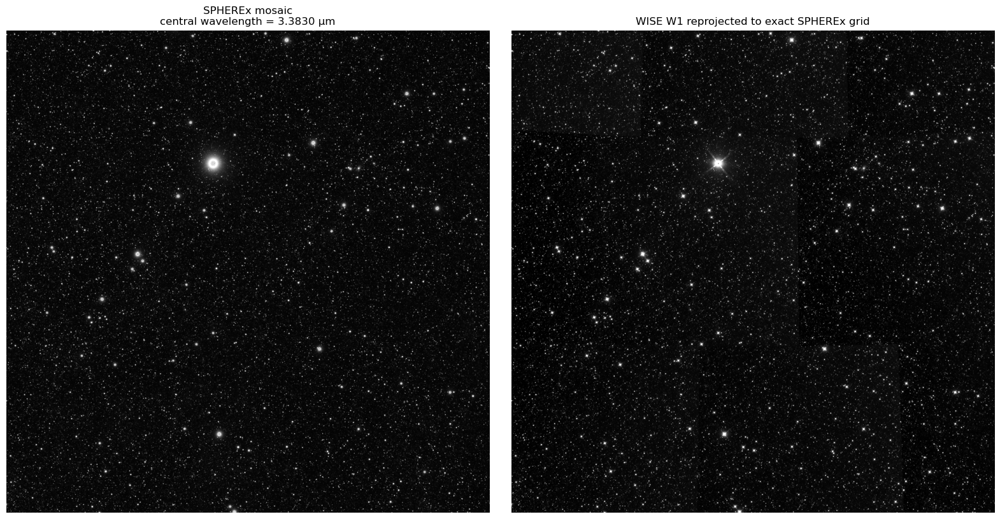

In [7]:
def display_limits(data, mask, low=1, high=99.7):
    values = data[mask & np.isfinite(data)]
    return np.percentile(values, [low, high])


sp_vmin, sp_vmax = display_limits(sp_data, valid_mask)
wi_vmin, wi_vmax = display_limits(wise_on_spherex, valid_mask)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(
    sp_data,
    origin="lower",
    cmap="gray",
    norm=ImageNormalize(
        vmin=sp_vmin,
        vmax=sp_vmax,
        stretch=AsinhStretch()
    )
)
axes[0].set_title(
    f"SPHEREx mosaic\ncentral wavelength = {wavelength_um:.4f} µm"
)
axes[0].axis("off")

axes[1].imshow(
    wise_on_spherex,
    origin="lower",
    cmap="gray",
    norm=ImageNormalize(
        vmin=wi_vmin,
        vmax=wi_vmax,
        stretch=AsinhStretch()
    )
)
axes[1].set_title("WISE W1 reprojected to exact SPHEREx grid")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [8]:
output_folder = folder / "new_mosaic_matching"
output_folder.mkdir(exist_ok=True)

sp_header_2d = sp_wcs_2d.to_header()
sp_header_2d["BUNIT"] = sp_header_3d.get("BUNIT", "MJy/sr")
sp_header_2d["WAVELEN"] = (
    wavelength_um,
    "SPHEREx central wavelength in microns"
)
sp_header_2d["WLMIN"] = (
    wl_min_um,
    "SPHEREx channel minimum wavelength in microns"
)
sp_header_2d["WLMAX"] = (
    wl_max_um,
    "SPHEREx channel maximum wavelength in microns"
)

wise_matched_header = sp_wcs_2d.to_header()
wise_matched_header["BUNIT"] = wise_header.get("BUNIT", "UNKNOWN")
wise_matched_header["HISTORY"] = (
    "WISE W1 reprojected onto exact SPHEREx mosaic celestial WCS."
)

fits.writeto(
    output_folder / "spherex_3p4um_mosaic_2d.fits",
    sp_data.astype(np.float32),
    sp_header_2d,
    overwrite=True
)

fits.writeto(
    output_folder / "wise_w1_on_exact_spherex_grid.fits",
    wise_on_spherex.astype(np.float32),
    wise_matched_header,
    overwrite=True
)

fits.writeto(
    output_folder / "wise_reprojection_footprint.fits",
    wise_footprint.astype(np.float32),
    sp_wcs_2d.to_header(),
    overwrite=True
)

fits.writeto(
    output_folder / "valid_overlap_mask.fits",
    valid_mask.astype(np.uint8),
    sp_wcs_2d.to_header(),
    overwrite=True
)

print("Saved files in:")
print(output_folder)

for path in sorted(output_folder.glob("*.fits")):
    print(" -", path.name)

Saved files in:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching
 - spherex_3p4um_mosaic_2d.fits
 - valid_overlap_mask.fits
 - wise_reprojection_footprint.fits
 - wise_w1_on_exact_spherex_grid.fits


In [10]:
%pip install photutils

Note: you may need to restart the kernel to use updated packages.


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder
from photutils.aperture import (
    CircularAperture,
    CircularAnnulus,
    aperture_photometry
)
from scipy.spatial import cKDTree

# Replace invalid values with NaN for safe processing.
sp_work = np.where(valid_mask, sp_data, np.nan)
wi_work = np.where(valid_mask, wise_on_spherex, np.nan)

# Robust global background estimates.
sp_mean, sp_median, sp_std = sigma_clipped_stats(
    sp_work,
    sigma=3.0,
    maxiters=5
)

wi_mean, wi_median, wi_std = sigma_clipped_stats(
    wi_work,
    sigma=3.0,
    maxiters=5
)

print("SPHEREx background")
print(" mean:", sp_mean)
print(" median:", sp_median)
print(" std:", sp_std)

print("\nWISE background")
print(" mean:", wi_mean)
print(" median:", wi_median)
print(" std:", wi_std)

SPHEREx background
 mean: 0.0328188659664242
 median: 0.030820084735751152
 std: 0.009424938680267928

WISE background
 mean: 1.9608812821126314
 median: 1.9294961825210157
 std: 0.19640952126453104


In [12]:
# Background-subtracted versions used only for source detection.
sp_detect_image = np.nan_to_num(
    sp_work - sp_median,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

wi_detect_image = np.nan_to_num(
    wi_work - wi_median,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

# Initial estimated FWHM values in pixels.
# These do not have to be exact yet.
sp_finder = DAOStarFinder(
    fwhm=2.0,
    threshold=7.0 * sp_std,
    exclude_border=True
)

wi_finder = DAOStarFinder(
    fwhm=2.0,
    threshold=7.0 * wi_std,
    exclude_border=True
)

sp_sources = sp_finder(sp_detect_image)
wi_sources = wi_finder(wi_detect_image)

if sp_sources is None:
    raise RuntimeError("No SPHEREx sources were detected.")

if wi_sources is None:
    raise RuntimeError("No WISE sources were detected.")

sp_sources_df = sp_sources.to_pandas()
wi_sources_df = wi_sources.to_pandas()

print("SPHEREx detections:", len(sp_sources_df))
print("WISE detections:", len(wi_sources_df))
print("\nSPHEREx columns:")
print(sp_sources_df.columns.tolist())

SPHEREx detections: 20679
WISE detections: 23088

SPHEREx columns:
['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']


In [15]:
ny, nx = sp_data.shape
edge = 25

def filter_sources(df, nx, ny, edge=25):
    df = df.copy()

    # Support both newer and older Photutils column names.
    x_col = "x_centroid" if "x_centroid" in df.columns else "xcentroid"
    y_col = "y_centroid" if "y_centroid" in df.columns else "ycentroid"

    required = [x_col, y_col, "flux", "peak"]
    missing = [name for name in required if name not in df.columns]

    if missing:
        raise KeyError(
            f"Missing expected DAOStarFinder columns: {missing}\n"
            f"Available columns: {df.columns.tolist()}"
        )

    finite = (
        np.isfinite(df[x_col])
        & np.isfinite(df[y_col])
        & np.isfinite(df["flux"])
        & np.isfinite(df["peak"])
    )

    inside = (
        (df[x_col] > edge)
        & (df[x_col] < nx - edge)
        & (df[y_col] > edge)
        & (df[y_col] < ny - edge)
    )

    positive = (
        (df["flux"] > 0)
        & (df["peak"] > 0)
    )

    df = df[finite & inside & positive].copy()

    if len(df) == 0:
        raise RuntimeError("No sources remained after the basic filtering.")

    flux_low, flux_high = np.percentile(df["flux"], [20, 95])
    peak_high = np.percentile(df["peak"], 97)

    df = df[
        (df["flux"] >= flux_low)
        & (df["flux"] <= flux_high)
        & (df["peak"] <= peak_high)
    ].copy()

    # Standardize names so all later cells can use xcentroid/ycentroid.
    df = df.rename(columns={
        x_col: "xcentroid",
        y_col: "ycentroid"
    })

    return df.reset_index(drop=True)


sp_moderate = filter_sources(sp_sources_df, nx, ny, edge)
wi_moderate = filter_sources(wi_sources_df, nx, ny, edge)

print("Moderate SPHEREx sources:", len(sp_moderate))
print("Moderate WISE sources:", len(wi_moderate))
print("SPHEREx columns after normalization:")
print(sp_moderate.columns.tolist())

Moderate SPHEREx sources: 14817
Moderate WISE sources: 16503
SPHEREx columns after normalization:
['id', 'xcentroid', 'ycentroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']


In [16]:
sp_xy = sp_moderate[["xcentroid", "ycentroid"]].to_numpy(float)
wi_xy = wi_moderate[["xcentroid", "ycentroid"]].to_numpy(float)

wise_tree = cKDTree(wi_xy)

# Initial matching tolerance: 3 pixels.
distances, indices = wise_tree.query(
    sp_xy,
    distance_upper_bound=3.0
)

matched = np.isfinite(distances) & (indices < len(wi_xy))

sp_match = sp_moderate.loc[matched].reset_index(drop=True)
wi_match = wi_moderate.iloc[indices[matched]].reset_index(drop=True)
match_distance = distances[matched]

dx = sp_match["xcentroid"].to_numpy() - wi_match["xcentroid"].to_numpy()
dy = sp_match["ycentroid"].to_numpy() - wi_match["ycentroid"].to_numpy()

print("Matched sources:", len(sp_match))
print("Median dx [SPHEREx - WISE]:", np.median(dx), "pixels")
print("Median dy [SPHEREx - WISE]:", np.median(dy), "pixels")
print("Median separation:", np.median(match_distance), "pixels")
print("90th percentile separation:", np.percentile(match_distance, 90), "pixels")

Matched sources: 13264
Median dx [SPHEREx - WISE]: 0.015161612242309275 pixels
Median dy [SPHEREx - WISE]: -0.004434271161613879 pixels
Median separation: 0.11444918418985281 pixels
90th percentile separation: 0.23765473127235573 pixels


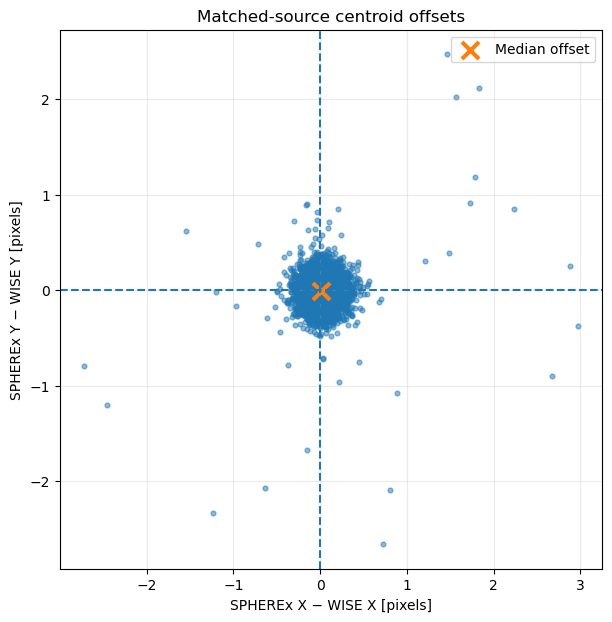

In [17]:
plt.figure(figsize=(7, 7))
plt.scatter(dx, dy, s=12, alpha=0.5)

plt.axvline(0, linestyle="--")
plt.axhline(0, linestyle="--")

plt.scatter(
    np.median(dx),
    np.median(dy),
    marker="x",
    s=150,
    linewidths=3,
    label="Median offset"
)

plt.xlabel("SPHEREx X − WISE X [pixels]")
plt.ylabel("SPHEREx Y − WISE Y [pixels]")
plt.title("Matched-source centroid offsets")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [18]:
positions = np.column_stack([
    sp_match["xcentroid"].to_numpy(float),
    sp_match["ycentroid"].to_numpy(float)
])

aperture_radius = 4.0
annulus_inner = 7.0
annulus_outer = 11.0

apertures = CircularAperture(
    positions,
    r=aperture_radius
)

annuli = CircularAnnulus(
    positions,
    r_in=annulus_inner,
    r_out=annulus_outer
)

sp_phot = aperture_photometry(
    sp_data,
    [apertures, annuli],
    mask=~valid_mask,
    method="exact"
)

wi_phot = aperture_photometry(
    wise_on_spherex,
    [apertures, annuli],
    mask=~valid_mask,
    method="exact"
)

# Exact geometric areas of the apertures.
aperture_area = apertures.area
annulus_area = annuli.area

sp_annulus_mean = (
    np.asarray(sp_phot["aperture_sum_1"], dtype=float)
    / annulus_area
)

wi_annulus_mean = (
    np.asarray(wi_phot["aperture_sum_1"], dtype=float)
    / annulus_area
)

sp_flux = (
    np.asarray(sp_phot["aperture_sum_0"], dtype=float)
    - sp_annulus_mean * aperture_area
)

wi_flux = (
    np.asarray(wi_phot["aperture_sum_0"], dtype=float)
    - wi_annulus_mean * aperture_area
)

phot_good = (
    np.isfinite(sp_flux)
    & np.isfinite(wi_flux)
    & (sp_flux > 0)
    & (wi_flux > 0)
)

sp_flux_good = sp_flux[phot_good]
wi_flux_good = wi_flux[phot_good]

print("Positive matched photometry pairs:", len(sp_flux_good))
print("Median SPHEREx flux:", np.median(sp_flux_good))
print("Median WISE flux:", np.median(wi_flux_good))
print(
    "Median SPHEREx / WISE ratio:",
    np.median(sp_flux_good / wi_flux_good)
)

Positive matched photometry pairs: 10299
Median SPHEREx flux: 1.122700356038688
Median WISE flux: 24.822409414146023
Median SPHEREx / WISE ratio: 0.04468066708971592


In [19]:
from scipy.stats import theilslopes, spearmanr

slope, intercept, slope_low, slope_high = theilslopes(
    sp_flux_good,
    wi_flux_good,
    alpha=0.95
)

rho, pvalue = spearmanr(
    wi_flux_good,
    sp_flux_good
)

predicted_sp = slope * wi_flux_good + intercept
residuals = sp_flux_good - predicted_sp

residual_median = np.median(residuals)
residual_mad_sigma = 1.4826 * np.median(
    np.abs(residuals - residual_median)
)

print("Robust relation:")
print("SPHEREx = slope × WISE + intercept")
print("Slope:", slope)
print("Intercept:", intercept)
print("95% slope interval:", slope_low, "to", slope_high)
print("Spearman correlation:", rho)
print("Spearman p-value:", pvalue)
print("Residual robust sigma:", residual_mad_sigma)

Robust relation:
SPHEREx = slope × WISE + intercept
Slope: 0.044057750705995984
Intercept: 0.02908083014807472
95% slope interval: 0.04395041553632074 to 0.04416521640720536
Spearman correlation: 0.9840256784079996
Spearman p-value: 0.0
Residual robust sigma: 0.1394201810833832


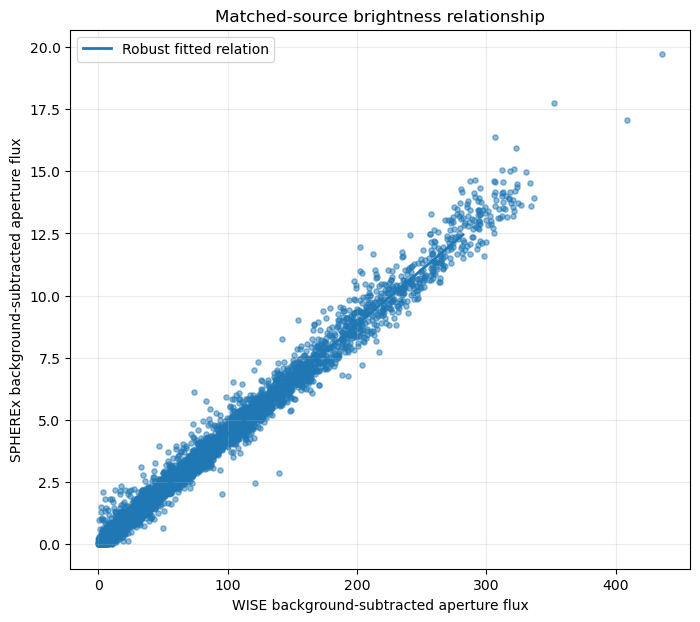

In [20]:
plt.figure(figsize=(8, 7))
plt.scatter(
    wi_flux_good,
    sp_flux_good,
    s=14,
    alpha=0.5
)

x_line = np.linspace(
    np.percentile(wi_flux_good, 1),
    np.percentile(wi_flux_good, 99),
    200
)

plt.plot(
    x_line,
    slope * x_line + intercept,
    linewidth=2,
    label="Robust fitted relation"
)

plt.xlabel("WISE background-subtracted aperture flux")
plt.ylabel("SPHEREx background-subtracted aperture flux")
plt.title("Matched-source brightness relationship")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [21]:
def estimate_source_fwhm(image, x, y, half_size=7):
    x0 = int(round(x))
    y0 = int(round(y))

    y1 = y0 - half_size
    y2 = y0 + half_size + 1
    x1 = x0 - half_size
    x2 = x0 + half_size + 1

    if (
        y1 < 0 or x1 < 0
        or y2 > image.shape[0]
        or x2 > image.shape[1]
    ):
        return np.nan

    cutout = np.asarray(
        image[y1:y2, x1:x2],
        dtype=float
    )

    if not np.all(np.isfinite(cutout)):
        return np.nan

    # Estimate local background from cutout border.
    border = np.concatenate([
        cutout[0, :],
        cutout[-1, :],
        cutout[:, 0],
        cutout[:, -1]
    ])

    background = np.median(border)
    signal = cutout - background
    signal[signal < 0] = 0

    total = signal.sum()

    if total <= 0:
        return np.nan

    yy, xx = np.indices(signal.shape)

    xcen = (xx * signal).sum() / total
    ycen = (yy * signal).sum() / total

    var_x = (((xx - xcen) ** 2) * signal).sum() / total
    var_y = (((yy - ycen) ** 2) * signal).sum() / total

    sigma = np.sqrt(0.5 * (var_x + var_y))

    return 2.354820045 * sigma


sp_fwhm_values = []
wi_fwhm_values = []

for x, y in positions:
    sp_fwhm_values.append(
        estimate_source_fwhm(sp_data, x, y)
    )
    wi_fwhm_values.append(
        estimate_source_fwhm(wise_on_spherex, x, y)
    )

sp_fwhm_values = np.asarray(sp_fwhm_values)
wi_fwhm_values = np.asarray(wi_fwhm_values)

fwhm_good = (
    np.isfinite(sp_fwhm_values)
    & np.isfinite(wi_fwhm_values)
    & (sp_fwhm_values > 0.8)
    & (wi_fwhm_values > 0.8)
    & (sp_fwhm_values < 10)
    & (wi_fwhm_values < 10)
)

sp_fwhm_med = np.median(sp_fwhm_values[fwhm_good])
wi_fwhm_med = np.median(wi_fwhm_values[fwhm_good])

print("Usable PSF stars:", fwhm_good.sum())
print("Median SPHEREx FWHM:", sp_fwhm_med, "pixels")
print("Median WISE FWHM:", wi_fwhm_med, "pixels")

if sp_fwhm_med > wi_fwhm_med:
    print("SPHEREx is broader. WISE must be convolved.")
elif wi_fwhm_med > sp_fwhm_med:
    print("WISE is broader. SPHEREx must be convolved.")
else:
    print("The measured PSF widths are nearly equal.")

Usable PSF stars: 12602
Median SPHEREx FWHM: 7.4564235001082775 pixels
Median WISE FWHM: 7.133586756894964 pixels
SPHEREx is broader. WISE must be convolved.


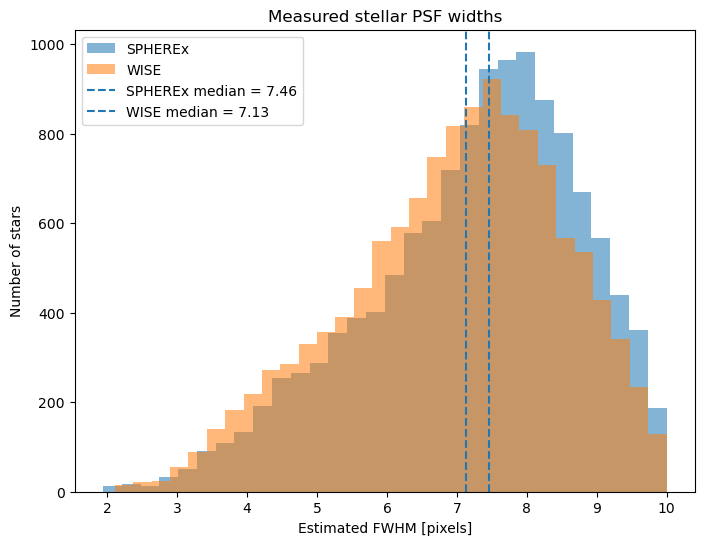

In [22]:
plt.figure(figsize=(8, 6))

plt.hist(
    sp_fwhm_values[fwhm_good],
    bins=30,
    alpha=0.55,
    label="SPHEREx"
)

plt.hist(
    wi_fwhm_values[fwhm_good],
    bins=30,
    alpha=0.55,
    label="WISE"
)

plt.axvline(
    sp_fwhm_med,
    linestyle="--",
    label=f"SPHEREx median = {sp_fwhm_med:.2f}"
)

plt.axvline(
    wi_fwhm_med,
    linestyle="--",
    label=f"WISE median = {wi_fwhm_med:.2f}"
)

plt.xlabel("Estimated FWHM [pixels]")
plt.ylabel("Number of stars")
plt.title("Measured stellar PSF widths")
plt.legend()
plt.show()

Moderately bright candidates: 3979
Isolated PSF candidates: 397



Successful clean FWHM fits: 210
Median fitted SPHEREx FWHM: 1.4043745493499755 pixels
Median fitted WISE FWHM: 1.8661387104747478 pixels
Difference: -0.46176416112477225 pixels


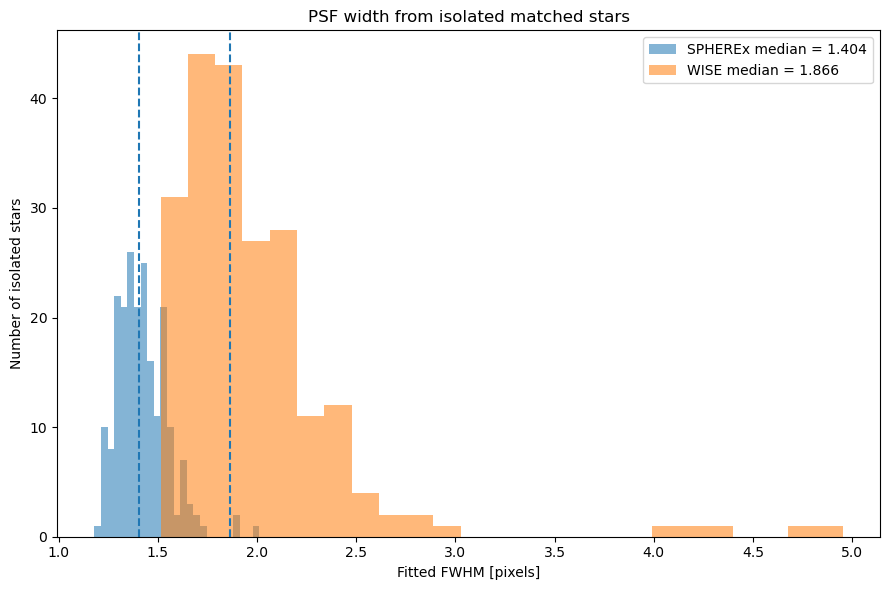

In [23]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree
from photutils.psf import fit_fwhm

# ------------------------------------------------------------
# 1. Start from the matched-source positions already produced.
# ------------------------------------------------------------
matched_positions = np.column_stack([
    sp_match["xcentroid"].to_numpy(float),
    sp_match["ycentroid"].to_numpy(float)
])

# Use SPHEREx detection flux to select moderately bright sources.
matched_flux = sp_match["flux"].to_numpy(float)

finite = (
    np.isfinite(matched_positions).all(axis=1)
    & np.isfinite(matched_flux)
    & (matched_flux > 0)
)

positions_all = matched_positions[finite]
flux_all = matched_flux[finite]

# Keep moderately bright stars only:
# remove faint detections and very bright/saturated-looking objects.
flux_low, flux_high = np.percentile(flux_all, [60, 90])

brightness_keep = (
    (flux_all >= flux_low)
    & (flux_all <= flux_high)
)

positions_bright = positions_all[brightness_keep]
flux_bright = flux_all[brightness_keep]

# ------------------------------------------------------------
# 2. Require isolation.
#    Nearest other detected star must be at least 15 pixels away.
# ------------------------------------------------------------
all_tree = cKDTree(positions_all)

nearest_distances, nearest_indices = all_tree.query(
    positions_bright,
    k=2
)

nearest_neighbor_distance = nearest_distances[:, 1]

isolated = nearest_neighbor_distance >= 15.0

positions_isolated = positions_bright[isolated]
flux_isolated = flux_bright[isolated]

# Keep the cleanest subset, capped to avoid excessive computation.
if len(positions_isolated) > 500:
    order = np.argsort(flux_isolated)[::-1]
    positions_isolated = positions_isolated[order[:500]]

print("Moderately bright candidates:", len(positions_bright))
print("Isolated PSF candidates:", len(positions_isolated))

if len(positions_isolated) < 20:
    raise RuntimeError(
        "Too few isolated stars remained. Reduce isolation distance "
        "from 15 pixels to 12 pixels and rerun."
    )

# ------------------------------------------------------------
# 3. Fit FWHM directly in both images.
# ------------------------------------------------------------
sp_fwhm_fit = fit_fwhm(
    sp_data,
    xypos=positions_isolated,
    fwhm=1.5,
    fit_shape=(9, 9),
    mask=~valid_mask
)

wi_fwhm_fit = fit_fwhm(
    wise_on_spherex,
    xypos=positions_isolated,
    fwhm=1.5,
    fit_shape=(9, 9),
    mask=~valid_mask
)

sp_fwhm_fit = np.asarray(sp_fwhm_fit, dtype=float)
wi_fwhm_fit = np.asarray(wi_fwhm_fit, dtype=float)

good = (
    np.isfinite(sp_fwhm_fit)
    & np.isfinite(wi_fwhm_fit)
    & (sp_fwhm_fit > 0.5)
    & (wi_fwhm_fit > 0.5)
    & (sp_fwhm_fit < 5.0)
    & (wi_fwhm_fit < 5.0)
)

sp_clean_fwhm = sp_fwhm_fit[good]
wi_clean_fwhm = wi_fwhm_fit[good]

print("\nSuccessful clean FWHM fits:", good.sum())

if good.sum() == 0:
    raise RuntimeError(
        "No valid FWHM fits remained. Try fit_shape=(11, 11) "
        "and initial fwhm=2.0."
    )

sp_fwhm_median = np.median(sp_clean_fwhm)
wi_fwhm_median = np.median(wi_clean_fwhm)

print("Median fitted SPHEREx FWHM:", sp_fwhm_median, "pixels")
print("Median fitted WISE FWHM:", wi_fwhm_median, "pixels")
print(
    "Difference:",
    sp_fwhm_median - wi_fwhm_median,
    "pixels"
)

# ------------------------------------------------------------
# 4. Plot only the clean fitted results.
# ------------------------------------------------------------
plt.figure(figsize=(9, 6))

plt.hist(
    sp_clean_fwhm,
    bins=25,
    alpha=0.55,
    label=f"SPHEREx median = {sp_fwhm_median:.3f}"
)

plt.hist(
    wi_clean_fwhm,
    bins=25,
    alpha=0.55,
    label=f"WISE median = {wi_fwhm_median:.3f}"
)

plt.axvline(sp_fwhm_median, linestyle="--")
plt.axvline(wi_fwhm_median, linestyle="--")

plt.xlabel("Fitted FWHM [pixels]")
plt.ylabel("Number of isolated stars")
plt.title("PSF width from isolated matched stars")
plt.legend()
plt.tight_layout()
plt.show()

SPHEREx fitted FWHM: 1.4043745493499755
WISE fitted FWHM: 1.8661387104747478
Photometric slope: 0.044057750705995984
Photometric intercept: 0.02908083014807472

Required Gaussian matching-kernel sigma:
0.5218676119913458 pixels

Difference-image statistics
Valid pixels: 4186430
Valid fraction: 0.997148676365121
Median: 0.0010486269560886087
Robust sigma: 0.0069587769395837214
Ordinary standard deviation: 0.33170045219879923
Minimum: -23.385926254987822
Maximum: 160.15851239554277


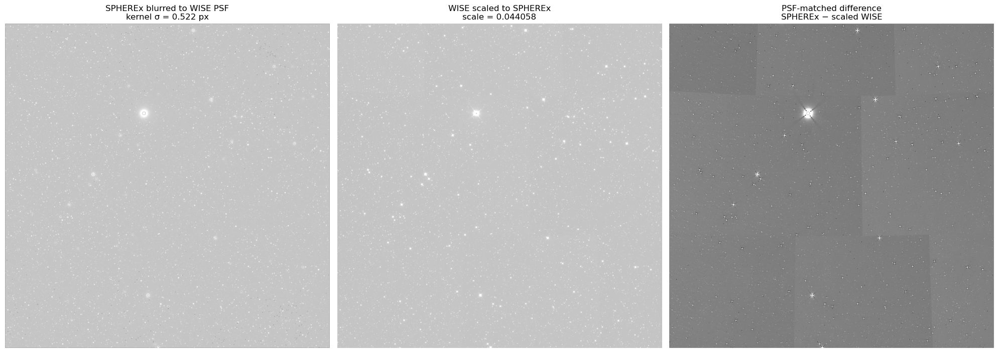


Saved products:
difference_spherex_minus_wise_psf_matched.fits
difference_valid_mask.fits
spherex_3p4um_mosaic_2d.fits
spherex_psf_matched_to_wise.fits
valid_overlap_mask.fits
wise_background_subtracted_scaled.fits
wise_reprojection_footprint.fits
wise_w1_on_exact_spherex_grid.fits


In [24]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter
from astropy.io import fits
from astropy.visualization import ImageNormalize, AsinhStretch
from pathlib import Path

# ============================================================
# 1. Values measured from the previous cells
# ============================================================

sp_fwhm = sp_fwhm_median
wi_fwhm = wi_fwhm_median

photometric_slope = slope
photometric_intercept = intercept

print("SPHEREx fitted FWHM:", sp_fwhm)
print("WISE fitted FWHM:", wi_fwhm)
print("Photometric slope:", photometric_slope)
print("Photometric intercept:", photometric_intercept)

if wi_fwhm <= sp_fwhm:
    raise ValueError(
        "This calculation expects WISE to be broader than SPHEREx."
    )

# For Gaussian profiles:
# sigma_kernel² = sigma_WISE² - sigma_SPHEREx²
fwhm_to_sigma = 2.354820045

sp_sigma = sp_fwhm / fwhm_to_sigma
wi_sigma = wi_fwhm / fwhm_to_sigma

kernel_sigma = np.sqrt(
    wi_sigma**2 - sp_sigma**2
)

print("\nRequired Gaussian matching-kernel sigma:")
print(kernel_sigma, "pixels")

# ============================================================
# 2. Background-subtract both images
# ============================================================

sp_background_subtracted = sp_data - sp_median
wi_background_subtracted = wise_on_spherex - wi_median

# Convert WISE source brightnesses onto the SPHEREx scale.
#
# We use the slope for the background-subtracted images.
# The fitted aperture intercept is NOT added pixel-by-pixel because
# the global image backgrounds have already been removed.
wise_scaled_to_spherex = (
    photometric_slope * wi_background_subtracted
)

# ============================================================
# 3. NaN-safe Gaussian convolution of SPHEREx
# ============================================================

def normalized_gaussian_filter(data, sigma, valid):
    """
    Gaussian-convolve valid pixels without allowing NaNs or masked
    image edges to contaminate surrounding pixels.
    """
    data_filled = np.where(valid, data, 0.0)
    weights = valid.astype(float)

    smoothed_data = gaussian_filter(
        data_filled,
        sigma=sigma,
        mode="constant",
        cval=0.0
    )

    smoothed_weights = gaussian_filter(
        weights,
        sigma=sigma,
        mode="constant",
        cval=0.0
    )

    result = np.full(data.shape, np.nan, dtype=float)

    good_weights = smoothed_weights > 0.99

    result[good_weights] = (
        smoothed_data[good_weights]
        / smoothed_weights[good_weights]
    )

    return result, good_weights


sp_psf_matched, convolution_valid = normalized_gaussian_filter(
    sp_background_subtracted,
    sigma=kernel_sigma,
    valid=valid_mask
)

# ============================================================
# 4. Construct the final valid region and difference
# ============================================================

difference_valid = (
    valid_mask
    & convolution_valid
    & np.isfinite(sp_psf_matched)
    & np.isfinite(wise_scaled_to_spherex)
)

difference_image = np.full(sp_data.shape, np.nan, dtype=float)

# SPHEREx is the science/reference geometry.
difference_image[difference_valid] = (
    sp_psf_matched[difference_valid]
    - wise_scaled_to_spherex[difference_valid]
)

# ============================================================
# 5. Robust difference statistics
# ============================================================

difference_values = difference_image[difference_valid]

diff_median = np.median(difference_values)

diff_mad_sigma = 1.4826 * np.median(
    np.abs(difference_values - diff_median)
)

diff_std = np.std(difference_values)

print("\nDifference-image statistics")
print("Valid pixels:", difference_valid.sum())
print("Valid fraction:", difference_valid.mean())
print("Median:", diff_median)
print("Robust sigma:", diff_mad_sigma)
print("Ordinary standard deviation:", diff_std)
print("Minimum:", np.min(difference_values))
print("Maximum:", np.max(difference_values))

# ============================================================
# 6. Display all three processing stages
# ============================================================

def symmetric_limits(data, mask, percentile=99.5):
    values = data[mask & np.isfinite(data)]
    limit = np.percentile(np.abs(values), percentile)
    return -limit, limit


sp_vmin, sp_vmax = symmetric_limits(
    sp_psf_matched,
    difference_valid,
    percentile=99.5
)

wi_vmin, wi_vmax = symmetric_limits(
    wise_scaled_to_spherex,
    difference_valid,
    percentile=99.5
)

diff_limit = np.percentile(
    np.abs(difference_values - diff_median),
    99.5
)

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

axes[0].imshow(
    sp_psf_matched,
    origin="lower",
    cmap="gray",
    norm=ImageNormalize(
        vmin=sp_vmin,
        vmax=sp_vmax,
        stretch=AsinhStretch()
    )
)
axes[0].set_title(
    f"SPHEREx blurred to WISE PSF\n"
    f"kernel σ = {kernel_sigma:.3f} px"
)
axes[0].axis("off")

axes[1].imshow(
    wise_scaled_to_spherex,
    origin="lower",
    cmap="gray",
    norm=ImageNormalize(
        vmin=wi_vmin,
        vmax=wi_vmax,
        stretch=AsinhStretch()
    )
)
axes[1].set_title(
    f"WISE scaled to SPHEREx\n"
    f"scale = {photometric_slope:.6f}"
)
axes[1].axis("off")

axes[2].imshow(
    difference_image,
    origin="lower",
    cmap="gray",
    vmin=diff_median - diff_limit,
    vmax=diff_median + diff_limit
)
axes[2].set_title(
    "PSF-matched difference\n"
    "SPHEREx − scaled WISE"
)
axes[2].axis("off")

plt.tight_layout()
plt.show()

# ============================================================
# 7. Save FITS products
# ============================================================

output_folder = (
    Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
    / "new_mosaic_matching"
)

output_folder.mkdir(exist_ok=True)

output_header = sp_wcs_2d.to_header()
output_header["BUNIT"] = "MJy/sr"
output_header["SPFWHM"] = (
    float(sp_fwhm),
    "Measured native SPHEREx FWHM pixels"
)
output_header["WIFWHM"] = (
    float(wi_fwhm),
    "Measured WISE FWHM pixels"
)
output_header["KERNSIG"] = (
    float(kernel_sigma),
    "Gaussian matching kernel sigma pixels"
)
output_header["WISCALE"] = (
    float(photometric_slope),
    "Empirical WISE-to-SPHEREx scale"
)

fits.writeto(
    output_folder / "spherex_psf_matched_to_wise.fits",
    sp_psf_matched.astype(np.float32),
    output_header,
    overwrite=True
)

fits.writeto(
    output_folder / "wise_background_subtracted_scaled.fits",
    wise_scaled_to_spherex.astype(np.float32),
    output_header,
    overwrite=True
)

fits.writeto(
    output_folder / "difference_spherex_minus_wise_psf_matched.fits",
    difference_image.astype(np.float32),
    output_header,
    overwrite=True
)

fits.writeto(
    output_folder / "difference_valid_mask.fits",
    difference_valid.astype(np.uint8),
    sp_wcs_2d.to_header(),
    overwrite=True
)

print("\nSaved products:")
for path in sorted(output_folder.glob("*.fits")):
    print(path.name)

In [25]:
from pathlib import Path
import numpy as np
from astropy.io import fits

output_folder = (
    Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
    / "new_mosaic_matching"
)

hotpants_folder = output_folder / "hotpants_run"
hotpants_folder.mkdir(exist_ok=True)

# Use the already PSF-matched SPHEREx image as the science/reference image.
# Use the empirically scaled WISE image as the template.
sp_hp = np.asarray(sp_psf_matched, dtype=np.float32)
wi_hp = np.asarray(wise_scaled_to_spherex, dtype=np.float32)

hp_valid = (
    difference_valid
    & np.isfinite(sp_hp)
    & np.isfinite(wi_hp)
)

# HOTPANTS needs finite numerical images.
# Fill excluded pixels with the median of the valid background.
sp_fill = np.nanmedian(sp_hp[hp_valid])
wi_fill = np.nanmedian(wi_hp[hp_valid])

sp_hp_clean = np.where(hp_valid, sp_hp, sp_fill).astype(np.float32)
wi_hp_clean = np.where(hp_valid, wi_hp, wi_fill).astype(np.float32)

# HOTPANTS convention: 0 = usable, nonzero = masked/bad.
hp_mask = np.where(hp_valid, 0, 1).astype(np.int16)

header = sp_wcs_2d.to_header()
header["BUNIT"] = "MJy/sr"
header["WISCALE"] = float(photometric_slope)
header["KERNSIG"] = float(kernel_sigma)

sp_out = hotpants_folder / "hotpants_input_spherex_psfmatched.fits"
wi_out = hotpants_folder / "hotpants_input_wise_scaled.fits"
mask_out = hotpants_folder / "hotpants_bad_pixel_mask.fits"

fits.writeto(
    sp_out,
    sp_hp_clean,
    header,
    overwrite=True
)

fits.writeto(
    wi_out,
    wi_hp_clean,
    header,
    overwrite=True
)

fits.writeto(
    mask_out,
    hp_mask,
    sp_wcs_2d.to_header(),
    overwrite=True
)

print("Saved HOTPANTS inputs:")
print(sp_out)
print(wi_out)
print(mask_out)

print("\nInput diagnostics:")
print("SPHEREx min/max:", np.min(sp_hp_clean), np.max(sp_hp_clean))
print("WISE min/max:", np.min(wi_hp_clean), np.max(wi_hp_clean))
print("Masked pixels:", np.sum(hp_mask != 0))
print("Usable fraction:", np.mean(hp_mask == 0))

Saved HOTPANTS inputs:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\hotpants_run\hotpants_input_spherex_psfmatched.fits
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\hotpants_run\hotpants_input_wise_scaled.fits
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\hotpants_run\hotpants_bad_pixel_mask.fits

Input diagnostics:
SPHEREx min/max: -6.787 214.9206
WISE min/max: -0.024366183 76.06681
Masked pixels: 11971
Usable fraction: 0.997148676365121



 HOTPANTS difference
Shape: (2049, 2049)
Finite fraction: 1.0
Minimum: -87.92810821533203
Maximum: 100.27934265136719
Median: 1.0000000031710769e-30
Standard deviation: 0.40195779727908904
Unique values: 362941

 HOTPANTS convolved template
Shape: (2049, 2049)
Finite fraction: 1.0
Minimum: -111.61788177490234
Maximum: 151.52304077148438
Median: -0.06840687990188599
Standard deviation: 0.6667683294240504
Unique values: 3758830


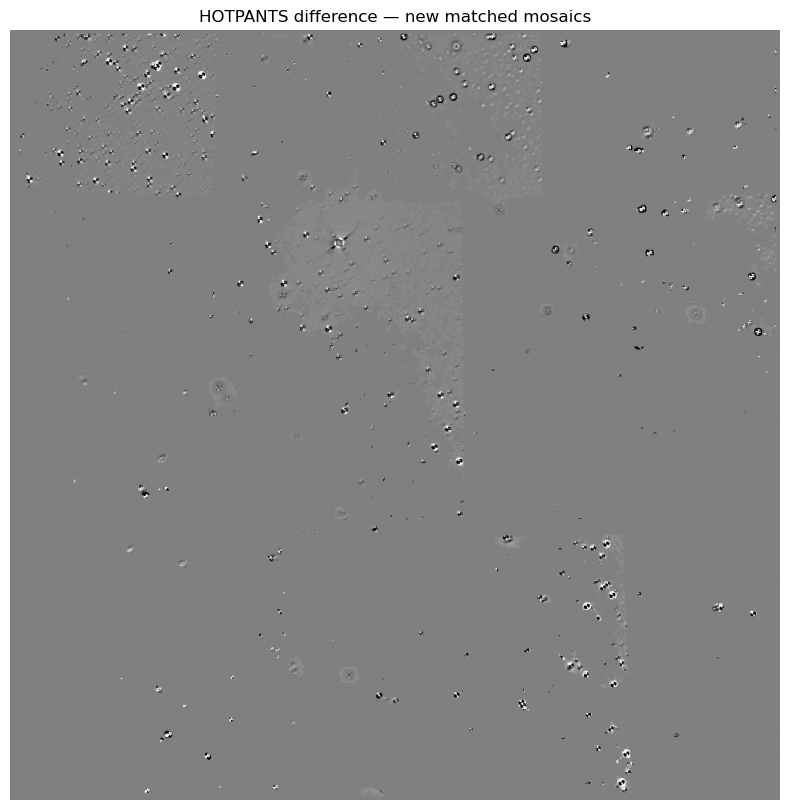

In [27]:
from astropy.io import fits
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

hotpants_folder = (
    Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
    / "new_mosaic_matching"
    / "hotpants_run"
)

diff_path = hotpants_folder / "hotpants_difference_new_mosaic.fits"
conv_path = hotpants_folder / "hotpants_convolved_template_new_mosaic.fits"

with fits.open(diff_path) as hdul:
    hp_diff = np.asarray(hdul[0].data, dtype=float)

with fits.open(conv_path) as hdul:
    hp_conv = np.asarray(hdul[0].data, dtype=float)

for name, data in [
    ("HOTPANTS difference", hp_diff),
    ("HOTPANTS convolved template", hp_conv),
]:
    finite = np.isfinite(data)

    print("\n", name)
    print("Shape:", data.shape)
    print("Finite fraction:", finite.mean())
    print("Minimum:", np.nanmin(data))
    print("Maximum:", np.nanmax(data))
    print("Median:", np.nanmedian(data))
    print("Standard deviation:", np.nanstd(data))
    print("Unique values:", len(np.unique(data[finite])))

finite = np.isfinite(hp_diff)
center = np.nanmedian(hp_diff[finite])
limit = np.nanpercentile(
    np.abs(hp_diff[finite] - center),
    99.5
)

plt.figure(figsize=(10, 10))
plt.imshow(
    hp_diff,
    origin="lower",
    cmap="gray",
    vmin=center - limit,
    vmax=center + limit
)
plt.title("HOTPANTS difference — new matched mosaics")
plt.axis("off")
plt.show()

In [28]:
from pathlib import Path
import numpy as np
from astropy.io import fits

base_folder = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
)

hp_folder = (
    base_folder
    / "new_mosaic_matching"
    / "hotpants_correct_direction"
)

hp_folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Start from ORIGINAL images, not manually PSF-blurred SPHEREx
# ------------------------------------------------------------

sp_raw_bgsub = sp_data - sp_median

wise_scaled_bgsub = (
    photometric_slope
    * (wise_on_spherex - wi_median)
)

hp_valid = (
    valid_mask
    & np.isfinite(sp_raw_bgsub)
    & np.isfinite(wise_scaled_bgsub)
)

# HOTPANTS input masks:
# 0 = usable
# nonzero = unusable
hp_mask = np.where(hp_valid, 0, 1).astype(np.int16)

# Fill masked pixels only so every saved pixel is finite.
sp_fill = np.nanmedian(sp_raw_bgsub[hp_valid])
wi_fill = np.nanmedian(wise_scaled_bgsub[hp_valid])

sp_clean = np.where(
    hp_valid,
    sp_raw_bgsub,
    sp_fill
).astype(np.float32)

wi_clean = np.where(
    hp_valid,
    wise_scaled_bgsub,
    wi_fill
).astype(np.float32)

# ------------------------------------------------------------
# 2. Calculate data thresholds from the actual valid pixels
# ------------------------------------------------------------

# Full-image valid ranges.
wi_low, wi_high = np.percentile(
    wi_clean[hp_valid],
    [0.01, 99.99]
)

sp_low, sp_high = np.percentile(
    sp_clean[hp_valid],
    [0.01, 99.99]
)

# More conservative limits used when choosing kernel stars.
wi_kernel_high = np.percentile(
    wi_clean[hp_valid],
    99.5
)

sp_kernel_high = np.percentile(
    sp_clean[hp_valid],
    99.5
)

# Add small margins so valid background is not clipped.
wi_range = wi_high - wi_low
sp_range = sp_high - sp_low

wi_lower_threshold = wi_low - 0.10 * wi_range
wi_upper_threshold = wi_high + 0.10 * wi_range

sp_lower_threshold = sp_low - 0.10 * sp_range
sp_upper_threshold = sp_high + 0.10 * sp_range

# ------------------------------------------------------------
# 3. Save files
# ------------------------------------------------------------

header = sp_wcs_2d.to_header()
header["BUNIT"] = "MJy/sr"
header["WISCALE"] = float(photometric_slope)
header["SPFWHM"] = float(sp_fwhm_median)
header["WIFWHM"] = float(wi_fwhm_median)
header["KERNSIG"] = float(kernel_sigma)

wise_input_path = (
    hp_folder / "comparison_wise_scaled_broader.fits"
)

spherex_template_path = (
    hp_folder / "template_spherex_sharper.fits"
)

mask_path = hp_folder / "hotpants_input_mask.fits"

fits.writeto(
    wise_input_path,
    wi_clean,
    header,
    overwrite=True
)

fits.writeto(
    spherex_template_path,
    sp_clean,
    header,
    overwrite=True
)

fits.writeto(
    mask_path,
    hp_mask,
    sp_wcs_2d.to_header(),
    overwrite=True
)

# ------------------------------------------------------------
# 4. Print diagnostics and exact Ubuntu command
# ------------------------------------------------------------

print("Saved:")
print(wise_input_path)
print(spherex_template_path)
print(mask_path)

print("\nWISE comparison thresholds")
print("Lower:", wi_lower_threshold)
print("Upper:", wi_upper_threshold)
print("Kernel upper:", wi_kernel_high)

print("\nSPHEREx template thresholds")
print("Lower:", sp_lower_threshold)
print("Upper:", sp_upper_threshold)
print("Kernel upper:", sp_kernel_high)

sigma_small = 0.5 * kernel_sigma
sigma_middle = kernel_sigma
sigma_large = 2.0 * kernel_sigma

print("\nCOPY THIS EXACT COMMAND INTO UBUNTU:\n")

print(
f"""cd /mnt/c/Users/Owner/OneDrive/Desktop/SPHEREx_Test/new_mosaic_matching/hotpants_correct_direction

~/hotpants/hotpants \\
  -inim comparison_wise_scaled_broader.fits \\
  -tmplim template_spherex_sharper.fits \\
  -outim difference_wise_minus_spherex_correct.fits \\
  -oci convolved_spherex_correct.fits \\
  -ond noise_scaled_difference_correct.fits \\
  -imi hotpants_input_mask.fits \\
  -tmi hotpants_input_mask.fits \\
  -c t \\
  -il {wi_lower_threshold:.8f} \\
  -iu {wi_upper_threshold:.8f} \\
  -iuk {wi_kernel_high:.8f} \\
  -tl {sp_lower_threshold:.8f} \\
  -tu {sp_upper_threshold:.8f} \\
  -tuk {sp_kernel_high:.8f} \\
  -ng 3 6 {sigma_small:.6f} 4 {sigma_middle:.6f} 2 {sigma_large:.6f} \\
  -ko 2 \\
  -bgo 1 \\
  -v 2"""
)

Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\hotpants_correct_direction\comparison_wise_scaled_broader.fits
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\hotpants_correct_direction\template_spherex_sharper.fits
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\hotpants_correct_direction\hotpants_input_mask.fits

WISE comparison thresholds
Lower: -3.0973946509356542
Upper: 33.842794350964596
Kernel upper: 0.80494386

SPHEREx template thresholds
Lower: -5.322942104973703
Upper: 55.318821637071565
Kernel upper: 0.84868234

COPY THIS EXACT COMMAND INTO UBUNTU:

cd /mnt/c/Users/Owner/OneDrive/Desktop/SPHEREx_Test/new_mosaic_matching/hotpants_correct_direction

~/hotpants/hotpants \
  -inim comparison_wise_scaled_broader.fits \
  -tmplim template_spherex_sharper.fits \
  -outim difference_wise_minus_spherex_correct.fits \
  -oci convolved_spherex_correct.fits \
  -ond noise_scaled_difference_correct.fits \
  -imi hotpants_input_mas

LOCAL-CROP RESULTS — BEST CROPS FIRST
 rank              crop  valid_fraction  local_offset_removed  robust_sigma_after  seam_score  quality_score
    1 crop_12_row3_col4        0.999607             -0.001511            0.004135    0.000588       0.007073
    2 crop_08_row2_col4        0.999863              0.002693            0.004429    0.000611       0.007484
    3 crop_03_row1_col3        0.997364             -0.000276            0.004029    0.000692       0.007489
    4 crop_01_row1_col1        0.995377              0.004246            0.004516    0.000612       0.007574
    5 crop_06_row2_col2        0.999569              0.001019            0.004435    0.000632       0.007594
    6 crop_10_row3_col2        0.997917             -0.001470            0.004442    0.000639       0.007639
    7 crop_16_row4_col4        0.997982             -0.001196            0.004466    0.000636       0.007645
    8 crop_05_row2_col1        0.997391              0.007135            0.005163    0.000

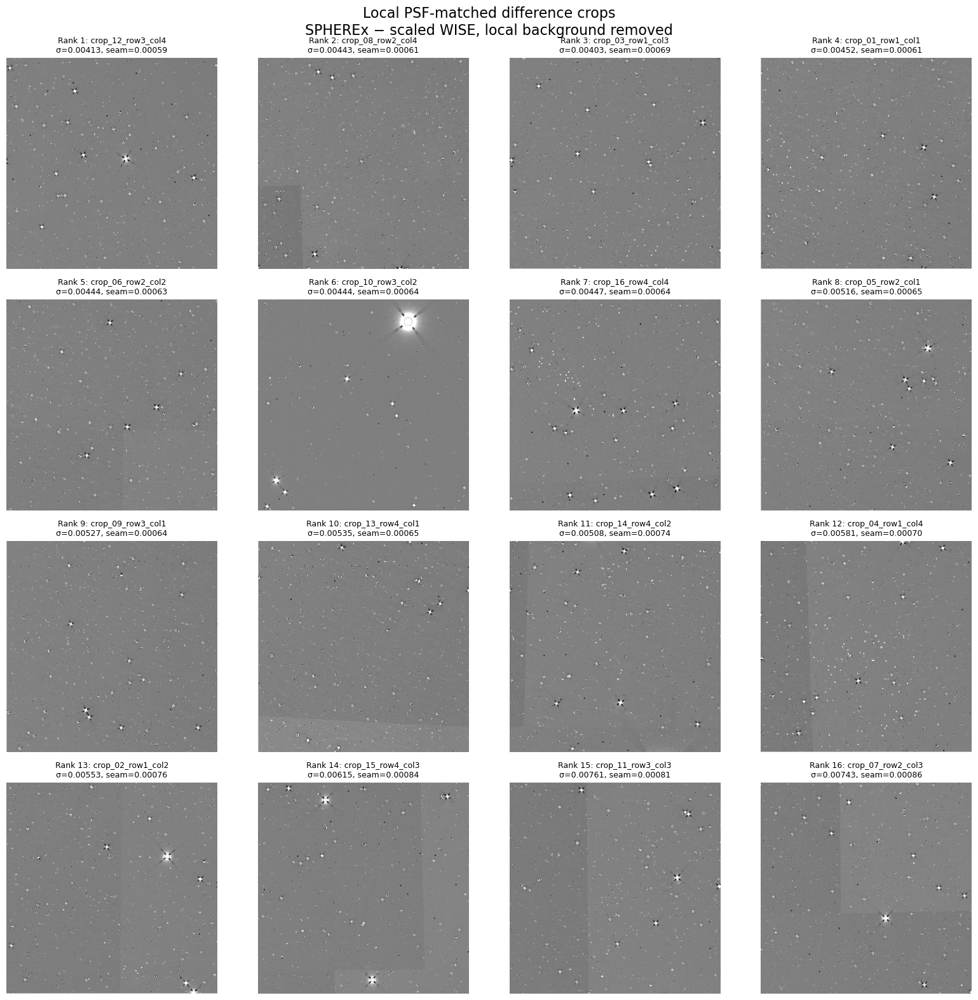


BEST CROP FOR THE NEXT HOTPANTS TEST
Crop: crop_12_row3_col4
Difference: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop_12_row3_col4_difference.fits
SPHEREx: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop_12_row3_col4_spherex_psfmatched.fits
WISE: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop_12_row3_col4_wise_scaled.fits

Summary:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\local_crop_summary.csv
Preview:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\local_crop_comparison.png


In [29]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clip


# ============================================================
# LOCAL-CROP DIAGNOSTIC
#
# Uses the successful manual PSF-matched products:
#   sp_psf_matched
#   wise_scaled_to_spherex
#   difference_valid
#   sp_wcs_2d
# ============================================================

required_names = [
    "sp_psf_matched",
    "wise_scaled_to_spherex",
    "difference_valid",
    "sp_wcs_2d",
]

missing = [name for name in required_names if name not in globals()]

if missing:
    raise NameError(
        "These required variables are missing:\n"
        + "\n".join(missing)
        + "\nRerun the earlier loading and manual PSF-matching cells first."
    )


# ------------------------------------------------------------
# 1. Settings
# ------------------------------------------------------------

crop_size = 512

output_folder = (
    Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
    / "new_mosaic_matching"
    / "local_crop_test"
)

output_folder.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Base manual difference
# ------------------------------------------------------------

manual_difference = np.full(
    sp_psf_matched.shape,
    np.nan,
    dtype=float
)

base_valid = (
    difference_valid
    & np.isfinite(sp_psf_matched)
    & np.isfinite(wise_scaled_to_spherex)
)

manual_difference[base_valid] = (
    sp_psf_matched[base_valid]
    - wise_scaled_to_spherex[base_valid]
)


# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------

def robust_stats(values):
    """
    Return sigma-clipped median and robust sigma.
    """
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if values.size == 0:
        return np.nan, np.nan, 0

    clipped = sigma_clip(
        values,
        sigma=3.0,
        maxiters=5,
        masked=True
    )

    clean = clipped.compressed()

    if clean.size == 0:
        return np.nan, np.nan, 0

    median = np.median(clean)

    robust_sigma = 1.4826 * np.median(
        np.abs(clean - median)
    )

    return median, robust_sigma, clean.size


def seam_score(image, valid):
    """
    Measures large row-to-row and column-to-column background jumps.

    Higher score means stronger rectangular/tile-boundary structure.
    """
    row_medians = np.full(image.shape[0], np.nan)
    col_medians = np.full(image.shape[1], np.nan)

    for row in range(image.shape[0]):
        vals = image[row, valid[row]]
        if vals.size >= 20:
            row_medians[row] = np.nanmedian(vals)

    for col in range(image.shape[1]):
        vals = image[valid[:, col], col]
        if vals.size >= 20:
            col_medians[col] = np.nanmedian(vals)

    row_jumps = np.abs(np.diff(row_medians))
    col_jumps = np.abs(np.diff(col_medians))

    combined = np.concatenate([
        row_jumps[np.isfinite(row_jumps)],
        col_jumps[np.isfinite(col_jumps)]
    ])

    if combined.size == 0:
        return np.nan

    return np.percentile(combined, 95)


# ------------------------------------------------------------
# 4. Divide image into 4 × 4 crops
# ------------------------------------------------------------

ny, nx = manual_difference.shape

x_starts = list(range(0, nx, crop_size))
y_starts = list(range(0, ny, crop_size))

records = []
crop_products = []

crop_number = 0

for row_index, y0 in enumerate(y_starts):
    for col_index, x0 in enumerate(x_starts):

        y1 = min(y0 + crop_size, ny)
        x1 = min(x0 + crop_size, nx)

        # Skip very small remainder strips.
        if (y1 - y0) < 300 or (x1 - x0) < 300:
            continue

        crop_number += 1

        diff_crop = manual_difference[y0:y1, x0:x1].copy()
        valid_crop = base_valid[y0:y1, x0:x1].copy()

        sp_crop = sp_psf_matched[y0:y1, x0:x1].copy()
        wi_crop = wise_scaled_to_spherex[y0:y1, x0:x1].copy()

        valid_fraction = np.mean(valid_crop)

        if valid_crop.sum() < 1000:
            continue

        # ----------------------------------------------------
        # Measure local offset using background-dominated pixels.
        #
        # Exclude the brightest 2% of either input so large stars
        # do not determine the local background correction.
        # ----------------------------------------------------

        sp_values = np.abs(sp_crop[valid_crop])
        wi_values = np.abs(wi_crop[valid_crop])

        sp_bright_limit = np.percentile(sp_values, 98)
        wi_bright_limit = np.percentile(wi_values, 98)

        background_mask = (
            valid_crop
            & (np.abs(sp_crop) < sp_bright_limit)
            & (np.abs(wi_crop) < wi_bright_limit)
        )

        local_offset, pre_sigma, used_pixels = robust_stats(
            diff_crop[background_mask]
        )

        local_corrected = diff_crop - local_offset

        corrected_median, corrected_sigma, corrected_pixels = robust_stats(
            local_corrected[background_mask]
        )

        current_seam_score = seam_score(
            local_corrected,
            background_mask
        )

        # Fraction occupied by unusually bright input pixels.
        bright_fraction = np.mean(
            valid_crop
            & (
                (np.abs(sp_crop) >= sp_bright_limit)
                | (np.abs(wi_crop) >= wi_bright_limit)
            )
        )

        # Combined quality metric:
        # low residual noise + low seam score is best.
        quality_score = (
            corrected_sigma
            + 5.0 * current_seam_score
        )

        crop_name = (
            f"crop_{crop_number:02d}"
            f"_row{row_index + 1}"
            f"_col{col_index + 1}"
        )

        # ----------------------------------------------------
        # Create crop-specific celestial WCS
        # ----------------------------------------------------

        crop_wcs = sp_wcs_2d.slice(
            (
                slice(y0, y1),
                slice(x0, x1)
            )
        )

        header = crop_wcs.to_header()
        header["BUNIT"] = "MJy/sr"
        header["XSTART"] = x0
        header["XEND"] = x1
        header["YSTART"] = y0
        header["YEND"] = y1
        header["LOCOFF"] = (
            float(local_offset),
            "Local residual background removed"
        )
        header["ROBSIG"] = (
            float(corrected_sigma),
            "Robust sigma after local correction"
        )
        header["SEAMSCR"] = (
            float(current_seam_score),
            "95th percentile row/column jump score"
        )

        fits.writeto(
            output_folder / f"{crop_name}_difference.fits",
            local_corrected.astype(np.float32),
            header,
            overwrite=True
        )

        fits.writeto(
            output_folder / f"{crop_name}_spherex_psfmatched.fits",
            sp_crop.astype(np.float32),
            header,
            overwrite=True
        )

        fits.writeto(
            output_folder / f"{crop_name}_wise_scaled.fits",
            wi_crop.astype(np.float32),
            header,
            overwrite=True
        )

        fits.writeto(
            output_folder / f"{crop_name}_valid_mask.fits",
            valid_crop.astype(np.uint8),
            crop_wcs.to_header(),
            overwrite=True
        )

        records.append({
            "crop": crop_name,
            "row": row_index + 1,
            "column": col_index + 1,
            "x_start": x0,
            "x_end": x1,
            "y_start": y0,
            "y_end": y1,
            "valid_fraction": valid_fraction,
            "local_offset_removed": local_offset,
            "robust_sigma_after": corrected_sigma,
            "seam_score": current_seam_score,
            "bright_fraction": bright_fraction,
            "quality_score": quality_score,
            "pixels_used_for_background": corrected_pixels,
        })

        crop_products.append({
            "name": crop_name,
            "data": local_corrected,
            "valid": valid_crop,
            "sigma": corrected_sigma,
            "seam": current_seam_score,
            "quality": quality_score,
        })


# ------------------------------------------------------------
# 5. Rank crops
# ------------------------------------------------------------

summary = pd.DataFrame(records)

if summary.empty:
    raise RuntimeError("No valid crops were produced.")

summary = summary.sort_values(
    "quality_score",
    ascending=True
).reset_index(drop=True)

summary["rank"] = np.arange(1, len(summary) + 1)

summary.to_csv(
    output_folder / "local_crop_summary.csv",
    index=False
)

print("=" * 90)
print("LOCAL-CROP RESULTS — BEST CROPS FIRST")
print("=" * 90)

print(
    summary[
        [
            "rank",
            "crop",
            "valid_fraction",
            "local_offset_removed",
            "robust_sigma_after",
            "seam_score",
            "quality_score",
        ]
    ].to_string(index=False)
)


# ------------------------------------------------------------
# 6. Plot every crop using the same robust style
# ------------------------------------------------------------

crop_lookup = {
    item["name"]: item
    for item in crop_products
}

fig, axes = plt.subplots(
    4,
    4,
    figsize=(16, 16)
)

axes = np.asarray(axes).ravel()

for ax in axes:
    ax.axis("off")

for panel_index, row in summary.iterrows():

    if panel_index >= len(axes):
        break

    crop_info = crop_lookup[row["crop"]]
    data = crop_info["data"]
    valid = crop_info["valid"]

    values = data[valid & np.isfinite(data)]

    center = np.nanmedian(values)

    limit = np.nanpercentile(
        np.abs(values - center),
        99.5
    )

    if not np.isfinite(limit) or limit <= 0:
        limit = 1.0

    axes[panel_index].imshow(
        data,
        origin="lower",
        cmap="gray",
        vmin=center - limit,
        vmax=center + limit
    )

    axes[panel_index].set_title(
        f'Rank {int(row["rank"])}: {row["crop"]}\n'
        f'σ={row["robust_sigma_after"]:.5f}, '
        f'seam={row["seam_score"]:.5f}',
        fontsize=9
    )

    axes[panel_index].axis("off")

plt.suptitle(
    "Local PSF-matched difference crops\n"
    "SPHEREx − scaled WISE, local background removed",
    fontsize=16
)

plt.tight_layout()

preview_path = output_folder / "local_crop_comparison.png"

plt.savefig(
    preview_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. Print the best crop paths
# ------------------------------------------------------------

best_crop = summary.iloc[0]["crop"]

print("\n" + "=" * 90)
print("BEST CROP FOR THE NEXT HOTPANTS TEST")
print("=" * 90)
print("Crop:", best_crop)
print(
    "Difference:",
    output_folder / f"{best_crop}_difference.fits"
)
print(
    "SPHEREx:",
    output_folder / f"{best_crop}_spherex_psfmatched.fits"
)
print(
    "WISE:",
    output_folder / f"{best_crop}_wise_scaled.fits"
)
print("\nSummary:")
print(output_folder / "local_crop_summary.csv")
print("Preview:")
print(preview_path)

In [30]:
from pathlib import Path

import numpy as np
from astropy.io import fits


# ============================================================
# PREPARE CROP 12 FOR A LOCAL HOTPANTS TEST
# ============================================================

base_folder = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
)

local_folder = (
    base_folder
    / "new_mosaic_matching"
    / "local_crop_test"
)

hp_crop_folder = local_folder / "crop12_hotpants"
hp_crop_folder.mkdir(parents=True, exist_ok=True)


# Crop 12 = row 3, column 4
# For 512-pixel crops:
x0, x1 = 1536, 2048
y0, y1 = 1024, 1536


# ------------------------------------------------------------
# 1. Extract ORIGINAL unblurred SPHEREx and scaled WISE
# ------------------------------------------------------------

sp_crop_raw = np.asarray(
    sp_data[y0:y1, x0:x1],
    dtype=float
)

wise_crop_scaled = np.asarray(
    wise_scaled_to_spherex[y0:y1, x0:x1],
    dtype=float
)

valid_crop = (
    valid_mask[y0:y1, x0:x1]
    & np.isfinite(sp_crop_raw)
    & np.isfinite(wise_crop_scaled)
)


# ------------------------------------------------------------
# 2. Remove a local background from each crop independently
# ------------------------------------------------------------

def robust_background(data, mask):
    values = data[mask & np.isfinite(data)]

    if values.size == 0:
        raise RuntimeError("No usable pixels for background measurement.")

    median = np.median(values)
    mad_sigma = 1.4826 * np.median(
        np.abs(values - median)
    )

    background_pixels = values[
        np.abs(values - median) < 3.0 * mad_sigma
    ]

    return np.median(background_pixels)


sp_local_background = robust_background(
    sp_crop_raw,
    valid_crop
)

wi_local_background = robust_background(
    wise_crop_scaled,
    valid_crop
)

sp_crop_bgsub = sp_crop_raw - sp_local_background
wi_crop_bgsub = wise_crop_scaled - wi_local_background

print("SPHEREx local background removed:", sp_local_background)
print("WISE local background removed:", wi_local_background)


# ------------------------------------------------------------
# 3. Mask extremely bright stars
#
# Dr. Hora specifically said not to use very bright sources.
# These pixels remain in the saved images but are excluded from
# the HOTPANTS kernel/background fit.
# ------------------------------------------------------------

sp_values = sp_crop_bgsub[valid_crop]
wi_values = wi_crop_bgsub[valid_crop]

sp_bright_limit = np.percentile(sp_values, 99.7)
wi_bright_limit = np.percentile(wi_values, 99.7)

bright_mask = (
    (sp_crop_bgsub > sp_bright_limit)
    | (wi_crop_bgsub > wi_bright_limit)
)

# Expand the bright-source mask so PSF wings/spikes are excluded.
from scipy.ndimage import binary_dilation

bright_mask = binary_dilation(
    bright_mask,
    iterations=5
)

hp_valid = (
    valid_crop
    & ~bright_mask
    & np.isfinite(sp_crop_bgsub)
    & np.isfinite(wi_crop_bgsub)
)

print("Valid crop fraction before bright masking:", valid_crop.mean())
print("Usable fraction after bright masking:", hp_valid.mean())


# ------------------------------------------------------------
# 4. Fill masked pixels so FITS arrays remain finite
# ------------------------------------------------------------

sp_fill = np.median(sp_crop_bgsub[hp_valid])
wi_fill = np.median(wi_crop_bgsub[hp_valid])

sp_clean = np.where(
    hp_valid,
    sp_crop_bgsub,
    sp_fill
).astype(np.float32)

wi_clean = np.where(
    hp_valid,
    wi_crop_bgsub,
    wi_fill
).astype(np.float32)

# HOTPANTS mask convention used here:
# 0 = usable
# 1 = excluded
hp_mask = np.where(
    hp_valid,
    0,
    1
).astype(np.int16)


# ------------------------------------------------------------
# 5. Derive sensible thresholds from this crop only
# ------------------------------------------------------------

sp_fit_values = sp_clean[hp_valid]
wi_fit_values = wi_clean[hp_valid]

sp_low, sp_high = np.percentile(
    sp_fit_values,
    [0.05, 99.95]
)

wi_low, wi_high = np.percentile(
    wi_fit_values,
    [0.05, 99.95]
)

# Upper limits used for selecting kernel sources.
sp_kernel_high = np.percentile(
    sp_fit_values,
    99.0
)

wi_kernel_high = np.percentile(
    wi_fit_values,
    99.0
)

# Add a small margin to full accepted pixel ranges.
sp_margin = 0.1 * (sp_high - sp_low)
wi_margin = 0.1 * (wi_high - wi_low)

sp_lower = sp_low - sp_margin
sp_upper = sp_high + sp_margin

wi_lower = wi_low - wi_margin
wi_upper = wi_high + wi_margin


# ------------------------------------------------------------
# 6. Crop-specific WCS/header
# ------------------------------------------------------------

crop_wcs = sp_wcs_2d.slice(
    (
        slice(y0, y1),
        slice(x0, x1)
    )
)

header = crop_wcs.to_header()
header["BUNIT"] = "MJy/sr"
header["XSTART"] = x0
header["XEND"] = x1
header["YSTART"] = y0
header["YEND"] = y1
header["SPBKG"] = float(sp_local_background)
header["WIBKG"] = float(wi_local_background)
header["WISCALE"] = float(photometric_slope)
header["SPFWHM"] = float(sp_fwhm_median)
header["WIFWHM"] = float(wi_fwhm_median)


# ------------------------------------------------------------
# 7. Save local HOTPANTS inputs
# ------------------------------------------------------------

wise_path = (
    hp_crop_folder
    / "crop12_input_wise_broader.fits"
)

spherex_path = (
    hp_crop_folder
    / "crop12_template_spherex_sharper.fits"
)

mask_path = (
    hp_crop_folder
    / "crop12_mask.fits"
)

fits.writeto(
    wise_path,
    wi_clean,
    header,
    overwrite=True
)

fits.writeto(
    spherex_path,
    sp_clean,
    header,
    overwrite=True
)

fits.writeto(
    mask_path,
    hp_mask,
    crop_wcs.to_header(),
    overwrite=True
)


# ------------------------------------------------------------
# 8. Print exact command
# ------------------------------------------------------------

kernel_sigma = 0.5218676119913458

sigma_small = 0.5 * kernel_sigma
sigma_middle = kernel_sigma
sigma_large = 2.0 * kernel_sigma

print("\nSaved:")
print(wise_path)
print(spherex_path)
print(mask_path)

print("\nCrop thresholds:")
print("WISE lower:", wi_lower)
print("WISE upper:", wi_upper)
print("WISE kernel upper:", wi_kernel_high)

print("SPHEREx lower:", sp_lower)
print("SPHEREx upper:", sp_upper)
print("SPHEREx kernel upper:", sp_kernel_high)

print("\nCOPY THIS EXACT COMMAND INTO UBUNTU:\n")

print(
f"""cd /mnt/c/Users/Owner/OneDrive/Desktop/SPHEREx_Test/new_mosaic_matching/local_crop_test/crop12_hotpants

~/hotpants/hotpants \\
  -inim crop12_input_wise_broader.fits \\
  -tmplim crop12_template_spherex_sharper.fits \\
  -outim crop12_difference_wise_minus_spherex.fits \\
  -oci crop12_convolved_spherex.fits \\
  -ond crop12_noise_scaled_difference.fits \\
  -imi crop12_mask.fits \\
  -tmi crop12_mask.fits \\
  -c t \\
  -il {wi_lower:.8f} \\
  -iu {wi_upper:.8f} \\
  -iuk {wi_kernel_high:.8f} \\
  -tl {sp_lower:.8f} \\
  -tu {sp_upper:.8f} \\
  -tuk {sp_kernel_high:.8f} \\
  -ng 3 6 {sigma_small:.6f} 4 {sigma_middle:.6f} 2 {sigma_large:.6f} \\
  -ko 1 \\
  -bgo 1 \\
  -v 2"""
)

SPHEREx local background removed: 0.02977673150599003
WISE local background removed: 0.0009718950503943115
Valid crop fraction before bright masking: 0.9998664855957031
Usable fraction after bright masking: 0.9417304992675781

Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop12_hotpants\crop12_input_wise_broader.fits
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop12_hotpants\crop12_template_spherex_sharper.fits
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop12_hotpants\crop12_mask.fits

Crop thresholds:
WISE lower: -0.08283630059063657
WISE upper: 0.7681516798824317
WISE kernel upper: 0.13560463
SPHEREx lower: -0.13646169118062185
SPHEREx upper: 0.9194533899300373
SPHEREx kernel upper: 0.15147604

COPY THIS EXACT COMMAND INTO UBUNTU:

cd /mnt/c/Users/Owner/OneDrive/Desktop/SPHEREx_Test/new_mosaic_matching/local_crop_test/crop12_hotpants

~/hotpants/hotpants \
  -inim c


Local HOTPANTS difference
Shape: (512, 512)
Finite fraction: 1.0
Median: 1.0000000031710769e-30
Robust sigma: 0.004402188943536021
Standard deviation: 0.018184378619076038
Minimum: -0.8165338039398193
Maximum: 0.608901858329773
Unique values: 239554

Local convolved SPHEREx
Shape: (512, 512)
Finite fraction: 1.0
Median: 1.0000000031710769e-30
Robust sigma: 0.006531888950429857
Standard deviation: 0.04441410179553798
Minimum: -3.6935672760009766
Maximum: 1.7464054822921753
Unique values: 241715

Local noise-scaled difference
Shape: (512, 512)
Finite fraction: 1.0
Median: 1.0000000031710769e-30
Robust sigma: 0.05571202676855028
Standard deviation: 0.08707165641882518
Minimum: -2.2710468769073486
Maximum: 2.357485771179199
Unique values: 239660


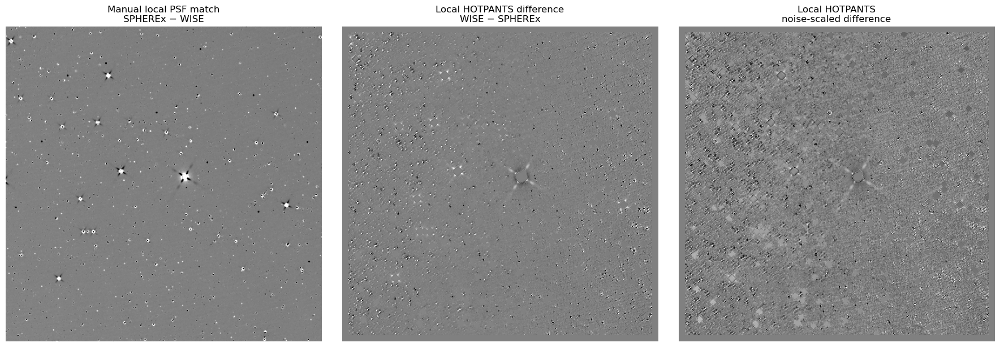

In [31]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits


hp_crop_folder = (
    Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
    / "new_mosaic_matching"
    / "local_crop_test"
    / "crop12_hotpants"
)

diff_path = (
    hp_crop_folder
    / "crop12_difference_wise_minus_spherex.fits"
)

conv_path = (
    hp_crop_folder
    / "crop12_convolved_spherex.fits"
)

noise_path = (
    hp_crop_folder
    / "crop12_noise_scaled_difference.fits"
)


def read_fits(path):
    with fits.open(path) as hdul:
        return np.asarray(
            hdul[0].data,
            dtype=float
        )


hp_diff = read_fits(diff_path)
hp_conv = read_fits(conv_path)
hp_noise = read_fits(noise_path)


for label, data in [
    ("Local HOTPANTS difference", hp_diff),
    ("Local convolved SPHEREx", hp_conv),
    ("Local noise-scaled difference", hp_noise),
]:
    finite = np.isfinite(data)

    values = data[finite]
    median = np.median(values)

    robust_sigma = 1.4826 * np.median(
        np.abs(values - median)
    )

    print("\n" + label)
    print("Shape:", data.shape)
    print("Finite fraction:", finite.mean())
    print("Median:", median)
    print("Robust sigma:", robust_sigma)
    print("Standard deviation:", np.std(values))
    print("Minimum:", np.min(values))
    print("Maximum:", np.max(values))
    print("Unique values:", len(np.unique(values)))


# Compare against the existing manual crop difference.
manual_path = (
    hp_crop_folder.parent
    / "crop_12_row3_col4_difference.fits"
)

manual_diff = read_fits(manual_path)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

panels = [
    (
        manual_diff,
        "Manual local PSF match\nSPHEREx − WISE"
    ),
    (
        hp_diff,
        "Local HOTPANTS difference\nWISE − SPHEREx"
    ),
    (
        hp_noise,
        "Local HOTPANTS\nnoise-scaled difference"
    ),
]

for ax, (data, title) in zip(axes, panels):
    finite = np.isfinite(data)
    values = data[finite]

    center = np.median(values)

    limit = np.percentile(
        np.abs(values - center),
        99.5
    )

    ax.imshow(
        data,
        origin="lower",
        cmap="gray",
        vmin=center - limit,
        vmax=center + limit
    )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

Isolated matched stars in crop: 56

Residual-aperture comparison
------------------------------------------------------------
Stars measured: 56
Median absolute residual flux — manual: 0.07659494258261151
Median absolute residual flux — HOTPANTS: 0.08657051306306185
Fraction where manual is better: 0.6071428571428571
Fraction where HOTPANTS is better: 0.39285714285714285
HOTPANTS/manual median residual ratio: 1.1302379784369077

Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop12_hotpants\manual_vs_hotpants_star_residuals.csv


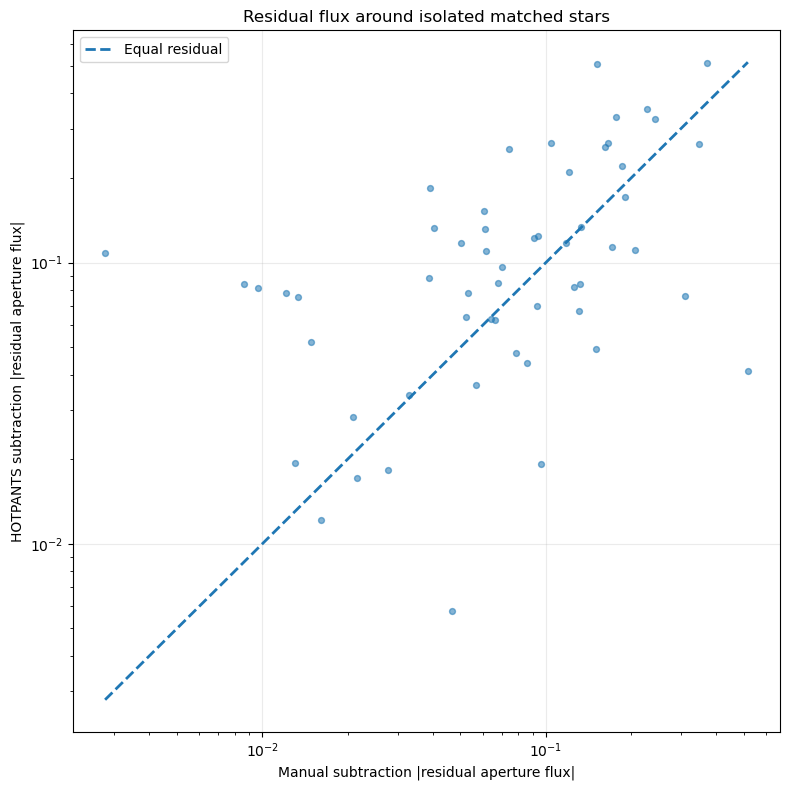

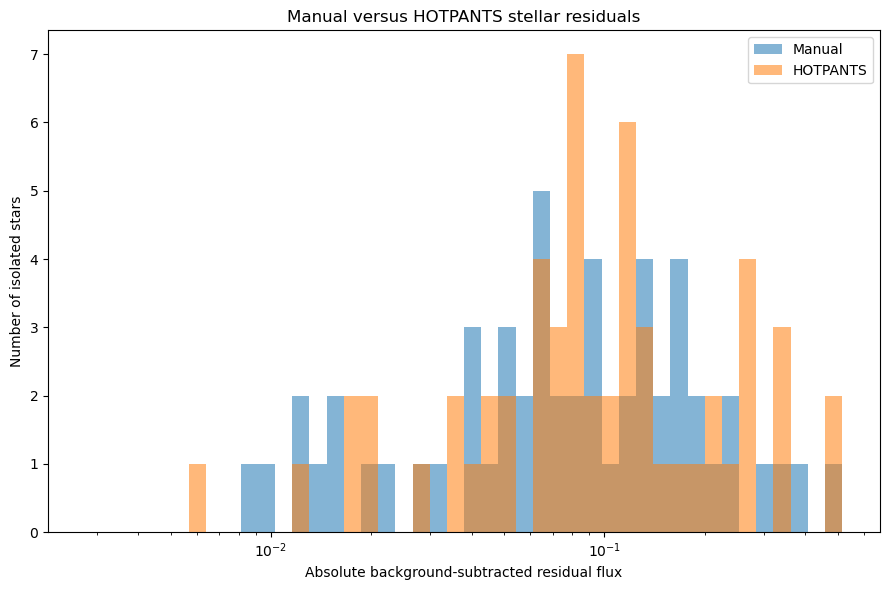

Difference background statistics
------------------------------------------------------------
Sigma-clipped mean: 5.064230995973157e-05
Sigma-clipped median: 7.26645930626546e-06
Sigma-clipped standard deviation: 0.004416714629662624
MAD-based robust sigma: 0.004485756020336702
Noise sigma used for detection: 0.004485756020336702



Raw positive detections: 322
Raw negative detections: 670
Raw total detections: 992
Detections after edge rejection: 864

Candidates after quality filtering: 379
candidate_id     sign  xcentroid  ycentroid  net_residual_flux          snr  sharpness  roundness1  roundness2
    CAND_001 positive 165.325062 431.317252         497.739352 10325.432372   0.770698    0.198640   -0.048406
    CAND_002 positive 454.513016 221.083820         540.771973  9109.290603   0.678717   -0.125155   -0.223068
    CAND_003 positive  86.095244 101.762517         121.408977  2907.410782   0.209622   -0.475008   -0.392761
    CAND_004 positive 120.687066 231.213975          54.200944  1675.682977   0.300074    0.314752   -0.291552
    CAND_005 positive  24.948727 393.390622          23.782823   792.348617   0.216970    0.606109    0.602557
    CAND_006 positive 299.393093 325.808070          10.251413   429.595651   1.266978   -0.537190    0.325689
    CAND_007 negative 162.000441 450.998965          -9.2519

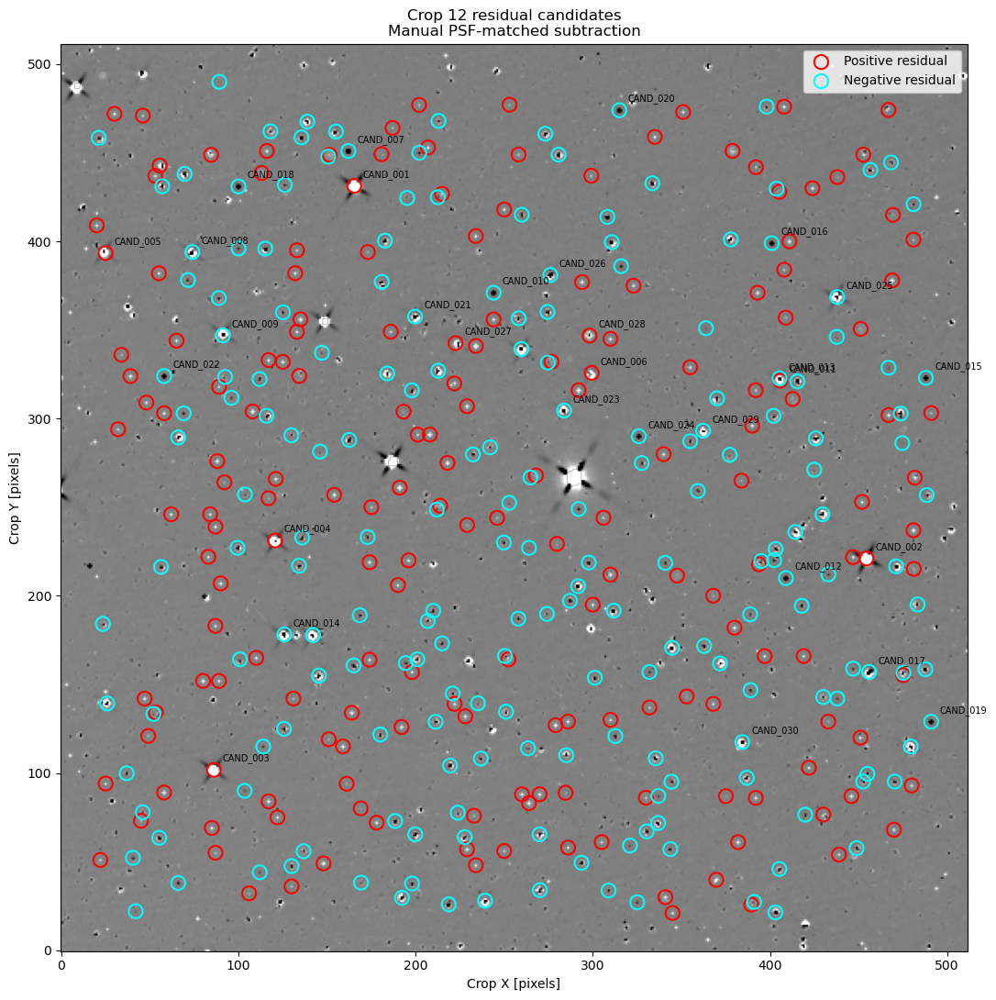

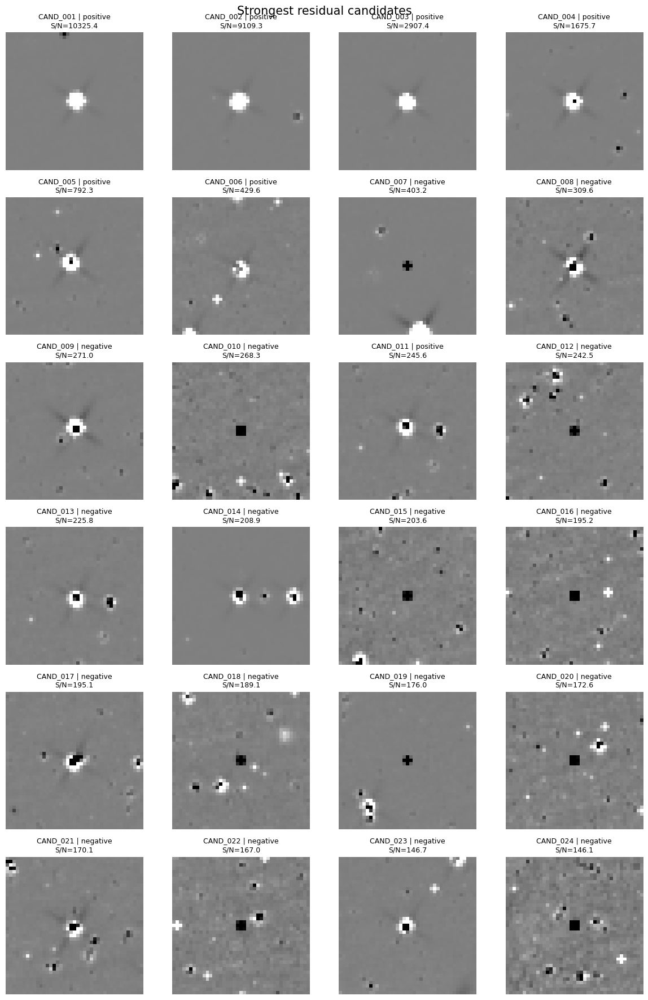

Saved candidate stamps:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop12_candidates\crop12_candidate_stamps.png


In [34]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from photutils.aperture import (
    CircularAperture,
    CircularAnnulus,
    aperture_photometry
)


# ============================================================
# COMPARE MANUAL VS HOTPANTS RESIDUALS AT MATCHED STARS
# ============================================================

base_folder = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
)

local_folder = (
    base_folder
    / "new_mosaic_matching"
    / "local_crop_test"
)

hp_folder = local_folder / "crop12_hotpants"


# ------------------------------------------------------------
# 1. Load both difference images
# ------------------------------------------------------------

manual_path = (
    local_folder
    / "crop_12_row3_col4_difference.fits"
)

hotpants_path = (
    hp_folder
    / "crop12_difference_wise_minus_spherex.fits"
)


with fits.open(manual_path) as hdul:
    manual_diff = np.asarray(
        hdul[0].data,
        dtype=float
    )

with fits.open(hotpants_path) as hdul:
    hotpants_diff = np.asarray(
        hdul[0].data,
        dtype=float
    )


# HOTPANTS has opposite subtraction sign.
# Reverse it so both represent SPHEREx minus WISE.
hotpants_diff_same_sign = -hotpants_diff


# ------------------------------------------------------------
# 2. Select matched stars located inside crop 12
# ------------------------------------------------------------

x0, x1 = 1536, 2048
y0, y1 = 1024, 1536

required_columns = [
    "xcentroid",
    "ycentroid"
]

for dataframe_name, dataframe in [
    ("sp_match", sp_match),
    ("wi_match", wi_match),
]:
    missing = [
        column
        for column in required_columns
        if column not in dataframe.columns
    ]

    if missing:
        raise KeyError(
            f"{dataframe_name} is missing columns: {missing}"
        )


sp_x_global = np.asarray(
    sp_match["xcentroid"],
    dtype=float
)

sp_y_global = np.asarray(
    sp_match["ycentroid"],
    dtype=float
)

wi_x_global = np.asarray(
    wi_match["xcentroid"],
    dtype=float
)

wi_y_global = np.asarray(
    wi_match["ycentroid"],
    dtype=float
)


inside_crop = (
    (sp_x_global >= x0)
    & (sp_x_global < x1)
    & (sp_y_global >= y0)
    & (sp_y_global < y1)
    & (wi_x_global >= x0)
    & (wi_x_global < x1)
    & (wi_y_global >= y0)
    & (wi_y_global < y1)
)


sp_x = sp_x_global[inside_crop] - x0
sp_y = sp_y_global[inside_crop] - y0

wi_x = wi_x_global[inside_crop] - x0
wi_y = wi_y_global[inside_crop] - y0


# Average matched coordinates so the aperture is centered
# between the two independently measured centroids.
star_x = 0.5 * (sp_x + wi_x)
star_y = 0.5 * (sp_y + wi_y)


# ------------------------------------------------------------
# 3. Exclude crop edges and stars too close to each other
# ------------------------------------------------------------

edge_distance = 18

safe = (
    (star_x > edge_distance)
    & (star_x < manual_diff.shape[1] - edge_distance)
    & (star_y > edge_distance)
    & (star_y < manual_diff.shape[0] - edge_distance)
)

star_x = star_x[safe]
star_y = star_y[safe]


from scipy.spatial import cKDTree

positions = np.column_stack([
    star_x,
    star_y
])

tree = cKDTree(positions)

nearest_distances, nearest_indices = tree.query(
    positions,
    k=2
)

# Column 0 is each source itself.
nearest_neighbor_distance = nearest_distances[:, 1]

isolated = nearest_neighbor_distance > 16.0

star_x = star_x[isolated]
star_y = star_y[isolated]

positions = np.column_stack([
    star_x,
    star_y
])

print("Isolated matched stars in crop:", len(positions))


# ------------------------------------------------------------
# 4. Aperture photometry on the residuals
# ------------------------------------------------------------

aperture_radius = 5.0
annulus_inner = 8.0
annulus_outer = 12.0

apertures = CircularAperture(
    positions,
    r=aperture_radius
)

annuli = CircularAnnulus(
    positions,
    r_in=annulus_inner,
    r_out=annulus_outer
)


def measure_residuals(image, label):

    aperture_table = aperture_photometry(
        image,
        apertures
    )

    annulus_masks = annuli.to_mask(
        method="center"
    )

    local_backgrounds = []

    for mask in annulus_masks:

        annulus_values = mask.multiply(image)

        if annulus_values is None:
            local_backgrounds.append(np.nan)
            continue

        valid_annulus = (
            (mask.data > 0)
            & np.isfinite(annulus_values)
        )

        values = annulus_values[valid_annulus]

        if values.size == 0:
            local_backgrounds.append(np.nan)
        else:
            local_backgrounds.append(
                np.nanmedian(values)
            )

    local_backgrounds = np.asarray(
        local_backgrounds,
        dtype=float
    )

    aperture_area = apertures.area

    aperture_sum = np.asarray(
        aperture_table["aperture_sum"],
        dtype=float
    )

    net_flux = (
        aperture_sum
        - local_backgrounds * aperture_area
    )

    result = pd.DataFrame({
        "x": star_x,
        "y": star_y,
        f"{label}_net_flux": net_flux,
        f"{label}_absolute_flux": np.abs(net_flux),
    })

    return result


manual_measurements = measure_residuals(
    manual_diff,
    "manual"
)

hotpants_measurements = measure_residuals(
    hotpants_diff_same_sign,
    "hotpants"
)


comparison = manual_measurements.merge(
    hotpants_measurements,
    on=["x", "y"]
)


# Remove invalid measurements.
comparison = comparison[
    np.isfinite(comparison["manual_absolute_flux"])
    & np.isfinite(comparison["hotpants_absolute_flux"])
].copy()


# ------------------------------------------------------------
# 5. Quantitative comparison
# ------------------------------------------------------------

manual_median_abs = np.median(
    comparison["manual_absolute_flux"]
)

hotpants_median_abs = np.median(
    comparison["hotpants_absolute_flux"]
)

manual_better_fraction = np.mean(
    comparison["manual_absolute_flux"]
    <
    comparison["hotpants_absolute_flux"]
)

hotpants_better_fraction = np.mean(
    comparison["hotpants_absolute_flux"]
    <
    comparison["manual_absolute_flux"]
)


print("\nResidual-aperture comparison")
print("-" * 60)

print("Stars measured:", len(comparison))

print(
    "Median absolute residual flux — manual:",
    manual_median_abs
)

print(
    "Median absolute residual flux — HOTPANTS:",
    hotpants_median_abs
)

print(
    "Fraction where manual is better:",
    manual_better_fraction
)

print(
    "Fraction where HOTPANTS is better:",
    hotpants_better_fraction
)

print(
    "HOTPANTS/manual median residual ratio:",
    hotpants_median_abs / manual_median_abs
)


# ------------------------------------------------------------
# 6. Save measurements
# ------------------------------------------------------------

output_csv = (
    hp_folder
    / "manual_vs_hotpants_star_residuals.csv"
)

comparison.to_csv(
    output_csv,
    index=False
)

print("\nSaved:")
print(output_csv)


# ------------------------------------------------------------
# 7. Plot method-to-method residual comparison
# ------------------------------------------------------------

positive_plot = (
    (comparison["manual_absolute_flux"] > 0)
    & (comparison["hotpants_absolute_flux"] > 0)
)

plot_data = comparison[positive_plot]


plt.figure(figsize=(8, 8))

plt.scatter(
    plot_data["manual_absolute_flux"],
    plot_data["hotpants_absolute_flux"],
    s=18,
    alpha=0.55
)

minimum = min(
    plot_data["manual_absolute_flux"].min(),
    plot_data["hotpants_absolute_flux"].min()
)

maximum = max(
    plot_data["manual_absolute_flux"].max(),
    plot_data["hotpants_absolute_flux"].max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    linewidth=2,
    label="Equal residual"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(
    "Manual subtraction |residual aperture flux|"
)

plt.ylabel(
    "HOTPANTS subtraction |residual aperture flux|"
)

plt.title(
    "Residual flux around isolated matched stars"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Compare the residual distributions
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

bins = np.logspace(
    np.log10(
        max(
            plot_data[
                [
                    "manual_absolute_flux",
                    "hotpants_absolute_flux"
                ]
            ].min().min(),
            1e-8
        )
    ),
    np.log10(
        plot_data[
            [
                "manual_absolute_flux",
                "hotpants_absolute_flux"
            ]
        ].max().max()
    ),
    45
)

plt.hist(
    plot_data["manual_absolute_flux"],
    bins=bins,
    alpha=0.55,
    label="Manual"
)

plt.hist(
    plot_data["hotpants_absolute_flux"],
    bins=bins,
    alpha=0.55,
    label="HOTPANTS"
)

plt.xscale("log")

plt.xlabel(
    "Absolute background-subtracted residual flux"
)

plt.ylabel("Number of isolated stars")

plt.title(
    "Manual versus HOTPANTS stellar residuals"
)

plt.legend()
plt.tight_layout()
plt.show()

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder
from photutils.aperture import (
    CircularAperture,
    CircularAnnulus,
    aperture_photometry,
)


# ============================================================
# CANDIDATE DETECTION ON BEST MANUAL DIFFERENCE CROP
# ============================================================

base_folder = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
)

local_folder = (
    base_folder
    / "new_mosaic_matching"
    / "local_crop_test"
)

candidate_folder = (
    local_folder
    / "crop12_candidates"
)

candidate_folder.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 1. Load the best manual difference crop
# ------------------------------------------------------------

difference_path = (
    local_folder
    / "crop_12_row3_col4_difference.fits"
)

with fits.open(difference_path) as hdul:
    difference = np.asarray(
        hdul[0].data,
        dtype=float
    )

    difference_header = hdul[0].header.copy()


finite = np.isfinite(difference)

if not finite.any():
    raise RuntimeError(
        "The difference crop contains no finite pixels."
    )


# Replace invalid pixels only for source detection.
background_fill = np.nanmedian(
    difference[finite]
)

detect_image = np.where(
    finite,
    difference,
    background_fill
)


# ------------------------------------------------------------
# 2. Measure the residual background
# ------------------------------------------------------------

mean_bg, median_bg, std_bg = sigma_clipped_stats(
    detect_image[finite],
    sigma=3.0,
    maxiters=5
)

mad_sigma = 1.4826 * np.median(
    np.abs(
        detect_image[finite]
        - np.median(detect_image[finite])
    )
)

print("Difference background statistics")
print("-" * 60)
print("Sigma-clipped mean:", mean_bg)
print("Sigma-clipped median:", median_bg)
print("Sigma-clipped standard deviation:", std_bg)
print("MAD-based robust sigma:", mad_sigma)


# Use the more conservative of the two estimates.
noise_sigma = max(
    float(std_bg),
    float(mad_sigma)
)

print("Noise sigma used for detection:", noise_sigma)


# ------------------------------------------------------------
# 3. Detect positive and negative residual sources
#
# Positive source:
#   brighter in SPHEREx than scaled WISE
#
# Negative source:
#   brighter in WISE than SPHEREx
# ------------------------------------------------------------

detection_threshold_sigma = 6.0

# The residual PSF width is not exactly the input stellar PSF.
# A modest FWHM works better for compact difference features.
finder = DAOStarFinder(
    fwhm=2.5,
    threshold=detection_threshold_sigma * noise_sigma,
    sharplo=0.1,
    sharphi=2.0,
    roundlo=-1.0,
    roundhi=1.0,
    exclude_border=True,
)


positive_sources = finder(
    detect_image - median_bg
)

negative_sources = finder(
    -(detect_image - median_bg)
)


def normalize_detection_table(
    table,
    sign_label
):
    if table is None or len(table) == 0:
        return pd.DataFrame()

    df = table.to_pandas()

    rename_map = {
        "x_centroid": "xcentroid",
        "y_centroid": "ycentroid",
    }

    df = df.rename(
        columns=rename_map
    )

    df["sign"] = sign_label

    return df


positive_df = normalize_detection_table(
    positive_sources,
    "positive"
)

negative_df = normalize_detection_table(
    negative_sources,
    "negative"
)

detections = pd.concat(
    [
        positive_df,
        negative_df,
    ],
    ignore_index=True
)

print("\nRaw positive detections:", len(positive_df))
print("Raw negative detections:", len(negative_df))
print("Raw total detections:", len(detections))


if detections.empty:
    raise RuntimeError(
        "No residual candidates were found at the current threshold."
    )


# ------------------------------------------------------------
# 4. Reject crop-edge detections
# ------------------------------------------------------------

ny, nx = difference.shape

edge_margin = 20

inside = (
    (detections["xcentroid"] >= edge_margin)
    & (detections["xcentroid"] < nx - edge_margin)
    & (detections["ycentroid"] >= edge_margin)
    & (detections["ycentroid"] < ny - edge_margin)
)

detections = detections[
    inside
].reset_index(drop=True)

print(
    "Detections after edge rejection:",
    len(detections)
)


# ------------------------------------------------------------
# 5. Perform local aperture photometry
# ------------------------------------------------------------

positions = np.column_stack([
    detections["xcentroid"].to_numpy(float),
    detections["ycentroid"].to_numpy(float),
])

aperture_radius = 4.0
annulus_inner = 7.0
annulus_outer = 11.0

apertures = CircularAperture(
    positions,
    r=aperture_radius
)

annuli = CircularAnnulus(
    positions,
    r_in=annulus_inner,
    r_out=annulus_outer
)


photometry = aperture_photometry(
    difference,
    apertures
)

aperture_sum = np.asarray(
    photometry["aperture_sum"],
    dtype=float
)

annulus_masks = annuli.to_mask(
    method="center"
)

local_background = []
local_sigma = []


for annulus_mask in annulus_masks:

    multiplied = annulus_mask.multiply(
        difference
    )

    if multiplied is None:
        local_background.append(np.nan)
        local_sigma.append(np.nan)
        continue

    mask_pixels = (
        (annulus_mask.data > 0)
        & np.isfinite(multiplied)
    )

    values = multiplied[
        mask_pixels
    ]

    if values.size < 10:
        local_background.append(np.nan)
        local_sigma.append(np.nan)
        continue

    local_median = np.median(values)

    local_mad_sigma = (
        1.4826
        * np.median(
            np.abs(
                values
                - local_median
            )
        )
    )

    local_background.append(
        local_median
    )

    local_sigma.append(
        local_mad_sigma
    )


local_background = np.asarray(
    local_background,
    dtype=float
)

local_sigma = np.asarray(
    local_sigma,
    dtype=float
)

aperture_area = apertures.area

net_flux = (
    aperture_sum
    - local_background
    * aperture_area
)

# Approximate aperture noise from the local pixel scatter.
aperture_noise = (
    local_sigma
    * np.sqrt(aperture_area)
)

snr = (
    np.abs(net_flux)
    / aperture_noise
)


detections["aperture_sum"] = aperture_sum
detections["local_background"] = local_background
detections["local_sigma"] = local_sigma
detections["net_residual_flux"] = net_flux
detections["absolute_residual_flux"] = np.abs(net_flux)
detections["snr"] = snr


# ------------------------------------------------------------
# 6. Keep statistically useful candidates
# ------------------------------------------------------------

good = (
    np.isfinite(detections["snr"])
    & np.isfinite(detections["net_residual_flux"])
    & (detections["snr"] >= 6.0)
    & (detections["sharpness"] > 0.15)
    & (detections["sharpness"] < 1.5)
)

candidates = detections[
    good
].copy()

candidates = candidates.sort_values(
    "snr",
    ascending=False
).reset_index(drop=True)

candidates.insert(
    0,
    "candidate_id",
    [
        f"CAND_{i:03d}"
        for i in range(
            1,
            len(candidates) + 1
        )
    ]
)


print("\nCandidates after quality filtering:", len(candidates))

if len(candidates) > 0:
    print(
        candidates[
            [
                "candidate_id",
                "sign",
                "xcentroid",
                "ycentroid",
                "net_residual_flux",
                "snr",
                "sharpness",
                "roundness1",
                "roundness2",
            ]
        ].head(30).to_string(index=False)
    )


# ------------------------------------------------------------
# 7. Convert crop coordinates to full-mosaic coordinates
# ------------------------------------------------------------

crop_x_start = 1536
crop_y_start = 1024

candidates["full_x"] = (
    candidates["xcentroid"]
    + crop_x_start
)

candidates["full_y"] = (
    candidates["ycentroid"]
    + crop_y_start
)


# ------------------------------------------------------------
# 8. Add sky coordinates from the crop WCS
# ------------------------------------------------------------

from astropy.wcs import WCS

crop_wcs = WCS(
    difference_header
).celestial

sky_coordinates = crop_wcs.pixel_to_world(
    candidates["xcentroid"].to_numpy(float),
    candidates["ycentroid"].to_numpy(float),
)

candidates["ra_deg"] = sky_coordinates.ra.deg
candidates["dec_deg"] = sky_coordinates.dec.deg

candidates["ra_hms"] = (
    sky_coordinates.ra.to_string(
        unit="hour",
        sep=":",
        precision=3,
        pad=True,
    )
)

candidates["dec_dms"] = (
    sky_coordinates.dec.to_string(
        unit="deg",
        sep=":",
        precision=2,
        alwayssign=True,
        pad=True,
    )
)


# ------------------------------------------------------------
# 9. Save candidate catalogue
# ------------------------------------------------------------

candidate_csv = (
    candidate_folder
    / "crop12_candidate_catalog.csv"
)

candidates.to_csv(
    candidate_csv,
    index=False
)

print("\nSaved candidate catalogue:")
print(candidate_csv)


# ------------------------------------------------------------
# 10. Plot all candidates on the difference image
# ------------------------------------------------------------

values = difference[
    np.isfinite(difference)
]

display_center = np.median(values)

display_limit = np.percentile(
    np.abs(
        values - display_center
    ),
    99.5
)


plt.figure(
    figsize=(11, 11)
)

plt.imshow(
    difference,
    origin="lower",
    cmap="gray",
    vmin=display_center - display_limit,
    vmax=display_center + display_limit,
)

if len(candidates) > 0:

    positive_candidates = (
        candidates["sign"] == "positive"
    )

    negative_candidates = (
        candidates["sign"] == "negative"
    )

    plt.scatter(
        candidates.loc[
            positive_candidates,
            "xcentroid"
        ],
        candidates.loc[
            positive_candidates,
            "ycentroid"
        ],
        facecolors="none",
        edgecolors="red",
        s=120,
        linewidths=1.5,
        label="Positive residual",
    )

    plt.scatter(
        candidates.loc[
            negative_candidates,
            "xcentroid"
        ],
        candidates.loc[
            negative_candidates,
            "ycentroid"
        ],
        facecolors="none",
        edgecolors="cyan",
        s=120,
        linewidths=1.5,
        label="Negative residual",
    )

    for _, row in candidates.head(30).iterrows():
        plt.text(
            row["xcentroid"] + 5,
            row["ycentroid"] + 5,
            row["candidate_id"],
            fontsize=7,
        )

plt.title(
    "Crop 12 residual candidates\n"
    "Manual PSF-matched subtraction"
)

plt.xlabel("Crop X [pixels]")
plt.ylabel("Crop Y [pixels]")
plt.legend()

plt.tight_layout()

candidate_map_path = (
    candidate_folder
    / "crop12_candidate_map.png"
)

plt.savefig(
    candidate_map_path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# 11. Produce postage stamps for the strongest candidates
# ------------------------------------------------------------

number_to_show = min(
    24,
    len(candidates)
)

stamp_half_size = 20

if number_to_show > 0:

    ncols = 4
    nrows = int(
        np.ceil(
            number_to_show / ncols
        )
    )

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(
            12,
            3 * nrows
        ),
    )

    axes = np.asarray(
        axes
    ).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for index in range(number_to_show):

        row = candidates.iloc[index]

        x = int(
            round(
                row["xcentroid"]
            )
        )

        y = int(
            round(
                row["ycentroid"]
            )
        )

        x0 = max(
            0,
            x - stamp_half_size
        )

        x1 = min(
            nx,
            x + stamp_half_size + 1
        )

        y0 = max(
            0,
            y - stamp_half_size
        )

        y1 = min(
            ny,
            y + stamp_half_size + 1
        )

        stamp = difference[
            y0:y1,
            x0:x1
        ]

        finite_stamp = stamp[
            np.isfinite(stamp)
        ]

        if finite_stamp.size == 0:
            continue

        stamp_center = np.median(
            finite_stamp
        )

        stamp_limit = np.percentile(
            np.abs(
                finite_stamp
                - stamp_center
            ),
            99.0
        )

        if (
            not np.isfinite(stamp_limit)
            or stamp_limit <= 0
        ):
            stamp_limit = noise_sigma * 6.0

        axes[index].imshow(
            stamp,
            origin="lower",
            cmap="gray",
            vmin=stamp_center - stamp_limit,
            vmax=stamp_center + stamp_limit,
        )

        axes[index].set_title(
            f'{row["candidate_id"]} | {row["sign"]}\n'
            f'S/N={row["snr"]:.1f}',
            fontsize=9,
        )

        axes[index].axis("off")

    plt.suptitle(
        "Strongest residual candidates",
        fontsize=15,
    )

    plt.tight_layout()

    stamp_path = (
        candidate_folder
        / "crop12_candidate_stamps.png"
    )

    plt.savefig(
        stamp_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()

    print("Saved candidate stamps:")
    print(stamp_path)

In [35]:
# ============================================================
# BUILD DR. HORA PROGRESS PACKAGE
# ============================================================

from pathlib import Path
import shutil
import zipfile
import pandas as pd
from datetime import datetime

# ------------------------------------------------------------
# 1. Main project locations
# ------------------------------------------------------------
BASE = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
)

WORK = BASE / "new_mosaic_matching"
CROP = WORK / "local_crop_test"

PACKAGE = BASE / "Dr_Hora_progress_package"
PACKAGE.mkdir(parents=True, exist_ok=True)

print("Project directory:", BASE)
print("Package directory:", PACKAGE)


# ------------------------------------------------------------
# 2. Helper: locate a file anywhere under the project
# ------------------------------------------------------------
def find_file(possible_names, search_root=BASE):
    """
    Return the first exact-name match found recursively.
    possible_names may be one name or a list of names.
    """
    if isinstance(possible_names, str):
        possible_names = [possible_names]

    for name in possible_names:
        direct_matches = list(search_root.rglob(name))
        if direct_matches:
            return direct_matches[0]

    return None


def find_newest_by_keywords(keywords, extensions):
    """
    Find the newest file whose name contains all supplied keywords.
    """
    matches = []

    for path in BASE.rglob("*"):
        if not path.is_file():
            continue

        if path.suffix.lower() not in extensions:
            continue

        lower_name = path.name.lower()

        if all(keyword.lower() in lower_name for keyword in keywords):
            matches.append(path)

    if not matches:
        return None

    return max(matches, key=lambda p: p.stat().st_mtime)


def copy_as(source, output_name, required=True):
    """
    Copy a source file into the package with a clean output name.
    """
    destination = PACKAGE / output_name

    if source is None or not source.exists():
        message = f"NOT FOUND: {output_name}"

        if required:
            raise FileNotFoundError(message)

        print("Optional file", message)
        return None

    shutil.copy2(source, destination)
    print(f"Copied: {source.name} -> {destination.name}")
    return destination


# ------------------------------------------------------------
# 3. Locate the three principal FITS products
# ------------------------------------------------------------

# Original SPHEREx image plane used as the science/reference image
spherex_reference = find_file([
    "spherex_3p4um_mosaic_2d.fits",
    "spherex_3p383um_mosaic_2d.fits",
    "spherex_mosaic_2d.fits",
])

# WISE image reprojected, background-subtracted and photometrically
# scaled to match SPHEREx
wise_scaled = find_file([
    "wise_background_subtracted_scaled.fits",
    "wise_scaled_to_spherex.fits",
])

# Final manual PSF-matched difference image
manual_difference = find_file([
    "difference_spherex_minus_wise_psf_matched.fits",
    "difference_spherex_minus_wise.fits",
])

# Useful supporting image: WISE on the exact SPHEREx pixel grid
wise_reprojected = find_file([
    "wise_w1_on_exact_spherex_grid.fits",
    "wise_on_spherex_grid.fits",
])

# PSF-matched SPHEREx image
spherex_psf_matched = find_file([
    "spherex_psf_matched_to_wise.fits",
])


# ------------------------------------------------------------
# 4. Copy FITS files with descriptive filenames
# ------------------------------------------------------------
copied_files = []

copied_files.append(
    copy_as(
        spherex_reference,
        "01_SPHEREx_reference_3p383um.fits"
    )
)

copied_files.append(
    copy_as(
        wise_scaled,
        "02_WISE_W1_reprojected_scaled_reference.fits"
    )
)

copied_files.append(
    copy_as(
        manual_difference,
        "03_SPHEREx_minus_WISE_PSF_matched_difference.fits"
    )
)

# Supporting products
copied_files.append(
    copy_as(
        wise_reprojected,
        "04_WISE_W1_on_exact_SPHEREx_grid.fits",
        required=False
    )
)

copied_files.append(
    copy_as(
        spherex_psf_matched,
        "05_SPHEREx_PSF_matched_to_WISE.fits",
        required=False
    )
)


# ------------------------------------------------------------
# 5. Locate and copy preliminary candidate catalog
# ------------------------------------------------------------
candidate_catalog = find_file([
    "crop12_candidate_catalog.csv",
    "crop12_candidates.csv",
    "candidate_catalog.csv",
])

if candidate_catalog is None:
    candidate_catalog = find_newest_by_keywords(
        keywords=["candidate", "catalog"],
        extensions={".csv"}
    )

copied_files.append(
    copy_as(
        candidate_catalog,
        "06_preliminary_residual_candidate_catalog.csv",
        required=False
    )
)


# ------------------------------------------------------------
# 6. Locate and copy the most useful diagnostic plots
# ------------------------------------------------------------

candidate_map = find_file([
    "crop12_candidate_map.png",
    "candidate_map.png",
])

if candidate_map is None:
    candidate_map = find_newest_by_keywords(
        ["candidate", "map"],
        {".png", ".jpg", ".jpeg"}
    )

candidate_stamps = find_file([
    "crop12_candidate_stamps.png",
    "candidate_stamps.png",
])

if candidate_stamps is None:
    candidate_stamps = find_newest_by_keywords(
        ["candidate", "stamp"],
        {".png", ".jpg", ".jpeg"}
    )

local_comparison = find_newest_by_keywords(
    ["local", "comparison"],
    {".png", ".jpg", ".jpeg"}
)

if local_comparison is None:
    local_comparison = find_newest_by_keywords(
        ["hotpants"],
        {".png", ".jpg", ".jpeg"}
    )

copied_files.append(
    copy_as(
        candidate_map,
        "07_preliminary_candidate_map.png",
        required=False
    )
)

copied_files.append(
    copy_as(
        candidate_stamps,
        "08_strongest_candidate_stamps.png",
        required=False
    )
)

copied_files.append(
    copy_as(
        local_comparison,
        "09_local_subtraction_comparison.png",
        required=False
    )
)


# ------------------------------------------------------------
# 7. Write a compact quantitative summary table
# ------------------------------------------------------------
summary_rows = [
    ["SPHEREx central wavelength", 3.3830, "micron"],
    ["SPHEREx wavelength minimum", 3.3300, "micron"],
    ["SPHEREx wavelength maximum", 3.4340, "micron"],
    ["SPHEREx channel bandwidth", 0.0960, "micron"],
    ["Image dimensions", "2049 x 2049", "pixels"],
    ["Common pixel scale", 6.15, "arcsec/pixel"],
    ["Matched sources", 13264, "sources"],
    ["Median centroid separation", 0.11445, "pixels"],
    ["90th-percentile centroid separation", 0.23765, "pixels"],
    ["Brightness Spearman correlation", 0.9803, "dimensionless"],
    ["Photometric fitted slope", 0.044058, "SPHEREx/WISE"],
    ["Photometric fitted intercept", 0.029081, "SPHEREx units"],
    ["Median fitted SPHEREx FWHM", 1.4044, "pixels"],
    ["Median fitted WISE FWHM", 1.8661, "pixels"],
    ["Manual local-difference robust sigma", 0.004135, "image units"],
    ["Local HOTPANTS robust sigma", 0.004402, "image units"],
    ["Raw positive detections", 322, "detections"],
    ["Raw negative detections", 670, "detections"],
    ["Detections after edge rejection", 864, "detections"],
    ["Candidates after preliminary filtering", 379, "detections"],
]

summary_df = pd.DataFrame(
    summary_rows,
    columns=["measurement", "value", "unit"]
)

summary_csv = PACKAGE / "10_processing_summary.csv"
summary_df.to_csv(summary_csv, index=False)
copied_files.append(summary_csv)

print("Created:", summary_csv.name)


# ------------------------------------------------------------
# 8. Write README explaining every file and the limitations
# ------------------------------------------------------------
readme_text = f"""
SPHEREx–WISE DIFFERENCE-IMAGING PROGRESS PACKAGE
Prepared for Dr. Joseph L. Hora
Prepared by Vishwas Tattala
Created: {datetime.now().strftime("%Y-%m-%d %H:%M")}

DATA SELECTION
--------------
SPHEREx channel:
    Central wavelength: approximately 3.383 microns
    Wavelength range: approximately 3.330–3.434 microns
    Bandwidth: approximately 0.096 microns

WISE comparison:
    WISE W1
    Reprojected onto the exact SPHEREx celestial and pixel grid
    Background-subtracted and empirically scaled to the SPHEREx image

PRIMARY FITS TRIPLET
--------------------
01_SPHEREx_reference_3p383um.fits
    The selected two-dimensional SPHEREx mosaic used as the
    science/reference image.

02_WISE_W1_reprojected_scaled_reference.fits
    The WISE W1 image after reprojection onto the SPHEREx grid,
    local/background treatment, and empirical photometric scaling.

03_SPHEREx_minus_WISE_PSF_matched_difference.fits
    The manual PSF-matched difference:
        SPHEREx minus scaled WISE.

SUPPORTING FITS PRODUCTS
------------------------
04_WISE_W1_on_exact_SPHEREx_grid.fits
    Reprojected WISE image before the final scaling/subtraction steps.

05_SPHEREx_PSF_matched_to_WISE.fits
    SPHEREx image after convolution to approximately match the
    broader WISE PSF.

TABLES AND FIGURES
------------------
06_preliminary_residual_candidate_catalog.csv
    Preliminary positive and negative residual detections.

07_preliminary_candidate_map.png
    Locations of the residual detections in the selected local crop.

08_strongest_candidate_stamps.png
    Postage stamps of the strongest residual detections.

09_local_subtraction_comparison.png
    Diagnostic comparison of subtraction methods, when available.

10_processing_summary.csv
    Summary of alignment, photometric, PSF, subtraction, and
    candidate-detection statistics.

IMPORTANT LIMITATION
--------------------
The residual catalog is preliminary and is not yet a catalog of
confirmed variables or transient sources. Many high-significance
detections are associated with bright-star residuals, saturation,
diffraction structures, positive/negative subtraction pairs, masks,
or other structured subtraction artifacts.

CURRENT RESULTS
---------------
Astrometric matching:
    13,264 matched sources
    Median source separation approximately 0.114 pixel
    90th percentile approximately 0.238 pixel

Photometric relationship:
    Spearman correlation approximately 0.980
    SPHEREx = 0.044058 * WISE + 0.029081

Measured PSF:
    SPHEREx FWHM approximately 1.404 pixels
    WISE FWHM approximately 1.866 pixels

Local subtraction:
    Manual robust sigma approximately 0.004135
    HOTPANTS robust sigma approximately 0.004402

NEXT STEPS
----------
1. Mask saturated and very bright stars.
2. Reject positive/negative dipoles and structured stellar residuals.
3. Reject flagged or low-coverage SPHEREx pixels.
4. Improve the candidate-noise model.
5. Cross-match surviving candidates against source catalogs.
6. Repeat the subtraction across multiple SPHEREx epochs.
""".strip()

readme_path = PACKAGE / "README.txt"
readme_path.write_text(readme_text, encoding="utf-8")
copied_files.append(readme_path)

print("Created:", readme_path.name)


# ------------------------------------------------------------
# 9. Create the ZIP file for emailing
# ------------------------------------------------------------
zip_path = BASE / "Dr_Hora_SPHEREx_WISE_progress_package.zip"

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as zf:
    for file_path in PACKAGE.iterdir():
        if file_path.is_file():
            zf.write(file_path, arcname=file_path.name)

print("\n" + "=" * 75)
print("PACKAGE COMPLETE")
print("=" * 75)
print("Folder:")
print(PACKAGE)
print("\nZIP FILE TO ATTACH:")
print(zip_path)
print("\nZIP size:")
print(f"{zip_path.stat().st_size / (1024**2):.2f} MB")

print("\nFiles included:")
for path in sorted(PACKAGE.iterdir()):
    if path.is_file():
        print(f"  {path.name:55s} {path.stat().st_size / (1024**2):8.2f} MB")

Project directory: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test
Package directory: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\Dr_Hora_progress_package
Copied: spherex_3p4um_mosaic_2d.fits -> 01_SPHEREx_reference_3p383um.fits
Copied: wise_background_subtracted_scaled.fits -> 02_WISE_W1_reprojected_scaled_reference.fits
Copied: difference_spherex_minus_wise_psf_matched.fits -> 03_SPHEREx_minus_WISE_PSF_matched_difference.fits
Copied: wise_w1_on_exact_spherex_grid.fits -> 04_WISE_W1_on_exact_SPHEREx_grid.fits
Copied: spherex_psf_matched_to_wise.fits -> 05_SPHEREx_PSF_matched_to_WISE.fits
Copied: crop12_candidate_catalog.csv -> 06_preliminary_residual_candidate_catalog.csv
Copied: crop12_candidate_map.png -> 07_preliminary_candidate_map.png
Copied: crop12_candidate_stamps.png -> 08_strongest_candidate_stamps.png
Copied: local_crop_comparison.png -> 09_local_subtraction_comparison.png
Created: 10_processing_summary.csv
Created: README.txt

PACKAGE COMPLETE
Folder:
C:\Users\Owner\OneDrive\

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS


# ============================================================
# PROJECT PATHS
# ============================================================

BASE = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
)

WORK = BASE / "new_mosaic_matching"
LOCAL = WORK / "local_crop_test"
CANDIDATE_FOLDER = LOCAL / "crop12_candidates"


# ============================================================
# FIND REQUIRED FILES
# ============================================================

spherex_path = WORK / "spherex_3p4um_mosaic_2d.fits"

if not spherex_path.exists():
    possible = list(BASE.rglob("spherex_3p4um_mosaic_2d.fits"))

    if not possible:
        possible = list(
            BASE.rglob("image_SPHEREx-Mosaic.fits")
        )

    if not possible:
        raise FileNotFoundError(
            "Could not find the SPHEREx mosaic FITS file."
        )

    spherex_path = possible[0]


candidate_path = (
    CANDIDATE_FOLDER
    / "crop12_candidate_catalog.csv"
)

if not candidate_path.exists():
    possible = list(
        BASE.rglob("crop12_candidate_catalog.csv")
    )

    if not possible:
        raise FileNotFoundError(
            "Could not find crop12_candidate_catalog.csv"
        )

    candidate_path = possible[0]


difference_path = (
    LOCAL
    / "crop_12_row3_col4_difference.fits"
)

if not difference_path.exists():
    possible = list(
        BASE.rglob(
            "crop_12_row3_col4_difference.fits"
        )
    )

    if not possible:
        raise FileNotFoundError(
            "Could not find the crop-12 difference FITS."
        )

    difference_path = possible[0]


# ============================================================
# LOAD SPHEREx MOSAIC
# ============================================================

with fits.open(spherex_path) as hdul:

    # Supports either the original mosaic MEF or saved 2-D file.
    if "IMAGE" in hdul:
        sp_data = np.asarray(
            hdul["IMAGE"].data,
            dtype=float
        )

        if sp_data.ndim == 3:
            sp_data = sp_data[0]

        sp_header = hdul["IMAGE"].header.copy()

    else:
        sp_data = np.asarray(
            hdul[0].data,
            dtype=float
        )

        if sp_data.ndim == 3:
            sp_data = sp_data[0]

        sp_header = hdul[0].header.copy()


# ============================================================
# LOAD CROP DIFFERENCE AND CANDIDATES
# ============================================================

with fits.open(difference_path) as hdul:
    difference_crop = np.asarray(
        hdul[0].data,
        dtype=float
    )
    difference_header = hdul[0].header.copy()


candidates = pd.read_csv(candidate_path)


# Crop 12 location in the full 2049 × 2049 mosaic.
crop_x0 = 1536
crop_x1 = 2048
crop_y0 = 1024
crop_y1 = 1536

sp_crop_original = sp_data[
    crop_y0:crop_y1,
    crop_x0:crop_x1
]


print("SPHEREx path:")
print(spherex_path)

print("\nCandidate catalog:")
print(candidate_path)

print("\nDifference crop:")
print(difference_path)

print("\nShapes")
print("Full SPHEREx:", sp_data.shape)
print("SPHEREx crop:", sp_crop_original.shape)
print("Difference crop:", difference_crop.shape)

print("\nCandidates loaded:", len(candidates))
print("Candidate columns:")
print(candidates.columns.tolist())

SPHEREx path:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\spherex_3p4um_mosaic_2d.fits

Candidate catalog:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop12_candidates\crop12_candidate_catalog.csv

Difference crop:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop_12_row3_col4_difference.fits

Shapes
Full SPHEREx: (2049, 2049)
SPHEREx crop: (512, 512)
Difference crop: (512, 512)

Candidates loaded: 379
Candidate columns:
['candidate_id', 'id', 'xcentroid', 'ycentroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag', 'sign', 'aperture_sum', 'local_background', 'local_sigma', 'net_residual_flux', 'absolute_residual_flux', 'snr', 'full_x', 'full_y', 'ra_deg', 'dec_deg', 'ra_hms', 'dec_dms']


In [2]:
# ============================================================
# SINGLE-PIXEL SHARPNESS TEST
# ============================================================

from scipy.ndimage import maximum_filter


def candidate_pixel_metrics(
    image,
    x,
    y,
    half_size=2
):
    """
    Measure how concentrated a candidate is in one pixel.

    Returns metrics from a 5×5 cutout centered on the
    nearest integer pixel.
    """

    x0 = int(round(float(x)))
    y0 = int(round(float(y)))

    if (
        x0 - half_size < 0
        or x0 + half_size >= image.shape[1]
        or y0 - half_size < 0
        or y0 + half_size >= image.shape[0]
    ):
        return None

    cutout = np.asarray(
        image[
            y0 - half_size:y0 + half_size + 1,
            x0 - half_size:x0 + half_size + 1
        ],
        dtype=float
    )

    if not np.all(np.isfinite(cutout)):
        return None

    # Estimate local background from the outside edge
    # of the 5×5 cutout.
    border = np.concatenate([
        cutout[0, :],
        cutout[-1, :],
        cutout[1:-1, 0],
        cutout[1:-1, -1],
    ])

    background = np.median(border)

    signal = cutout - background

    center = signal[half_size, half_size]

    # Eight pixels immediately surrounding the center.
    inner3 = signal[
        half_size - 1:half_size + 2,
        half_size - 1:half_size + 2
    ].copy()

    neighbors = np.delete(
        inner3.ravel(),
        4
    )

    positive_neighbors = neighbors[
        neighbors > 0
    ]

    neighbor_median = (
        np.median(positive_neighbors)
        if positive_neighbors.size > 0
        else 0.0
    )

    neighbor_max = np.max(neighbors)

    total_positive = np.sum(
        np.clip(signal, 0, None)
    )

    inner3_positive = np.sum(
        np.clip(inner3, 0, None)
    )

    peak_to_neighbor_median = (
        center / neighbor_median
        if neighbor_median > 0
        else np.inf
    )

    peak_to_neighbor_max = (
        center / neighbor_max
        if neighbor_max > 0
        else np.inf
    )

    center_fraction_5x5 = (
        center / total_positive
        if total_positive > 0
        else np.nan
    )

    center_fraction_3x3 = (
        center / inner3_positive
        if inner3_positive > 0
        else np.nan
    )

    return {
        "sp_center_value": center,
        "sp_neighbor_median": neighbor_median,
        "sp_neighbor_max": neighbor_max,
        "peak_neighbor_median_ratio":
            peak_to_neighbor_median,
        "peak_neighbor_max_ratio":
            peak_to_neighbor_max,
        "center_fraction_3x3":
            center_fraction_3x3,
        "center_fraction_5x5":
            center_fraction_5x5,
    }


metric_rows = []

for index, row in candidates.iterrows():

    result = candidate_pixel_metrics(
        sp_crop_original,
        row["xcentroid"],
        row["ycentroid"],
        half_size=2
    )

    if result is None:
        metric_rows.append({
            "catalog_index": index
        })
    else:
        result["catalog_index"] = index
        metric_rows.append(result)


metrics = pd.DataFrame(metric_rows)

candidates_sharpness = (
    candidates
    .reset_index()
    .rename(columns={"index": "catalog_index"})
    .merge(
        metrics,
        on="catalog_index",
        how="left"
    )
)


# ============================================================
# PRELIMINARY CLASSIFICATION
#
# Dr. Hora described detector events with the center pixel
# approximately ≥5× surrounding pixels.
#
# These thresholds are diagnostic, not final scientific cuts.
# ============================================================

candidates_sharpness["single_pixel_suspect"] = (
    (candidates_sharpness["sp_center_value"] > 0)
    & (
        candidates_sharpness[
            "peak_neighbor_median_ratio"
        ] >= 5.0
    )
    & (
        candidates_sharpness[
            "center_fraction_3x3"
        ] >= 0.55
    )
)

candidates_sharpness["psf_like_preliminary"] = (
    (candidates_sharpness["sp_center_value"] > 0)
    & (
        candidates_sharpness[
            "peak_neighbor_median_ratio"
        ] >= 1.2
    )
    & (
        candidates_sharpness[
            "peak_neighbor_median_ratio"
        ] < 5.0
    )
    & (
        candidates_sharpness[
            "center_fraction_3x3"
        ] < 0.55
    )
)


print("Total candidates:", len(candidates_sharpness))

print(
    "Single-pixel transient suspects:",
    candidates_sharpness[
        "single_pixel_suspect"
    ].sum()
)

print(
    "Preliminary PSF-like detections:",
    candidates_sharpness[
        "psf_like_preliminary"
    ].sum()
)


print("\nSharpest candidates:")
print(
    candidates_sharpness[
        [
            "candidate_id",
            "sign",
            "xcentroid",
            "ycentroid",
            "snr",
            "sp_center_value",
            "sp_neighbor_median",
            "peak_neighbor_median_ratio",
            "center_fraction_3x3",
            "single_pixel_suspect",
        ]
    ]
    .sort_values(
        "peak_neighbor_median_ratio",
        ascending=False
    )
    .head(30)
    .to_string(index=False)
)


# ============================================================
# SAVE UPDATED CATALOG
# ============================================================

sharpness_csv = (
    CANDIDATE_FOLDER
    / "crop12_candidates_with_sharpness.csv"
)

candidates_sharpness.to_csv(
    sharpness_csv,
    index=False
)

print("\nSaved:")
print(sharpness_csv)

Total candidates: 379
Single-pixel transient suspects: 141
Preliminary PSF-like detections: 82

Sharpest candidates:
candidate_id     sign  xcentroid  ycentroid       snr  sp_center_value  sp_neighbor_median  peak_neighbor_median_ratio  center_fraction_3x3  single_pixel_suspect
    CAND_233 positive 397.005659 165.988495 12.486976         0.487104            0.000000                         inf             1.000000                  True
    CAND_347 positive  46.032419 470.987590  6.929455         0.227289            0.000223                 1018.045978             0.999019                  True
    CAND_174 positive 121.053056 265.978621 17.915263         0.685208            0.000984                  696.426931             0.920835                  True
    CAND_182 positive 350.995233 473.004313 17.016555         0.409069            0.000734                  557.256160             0.998209                  True
    CAND_054 positive  39.005082 323.991303 48.952363         0.925540   

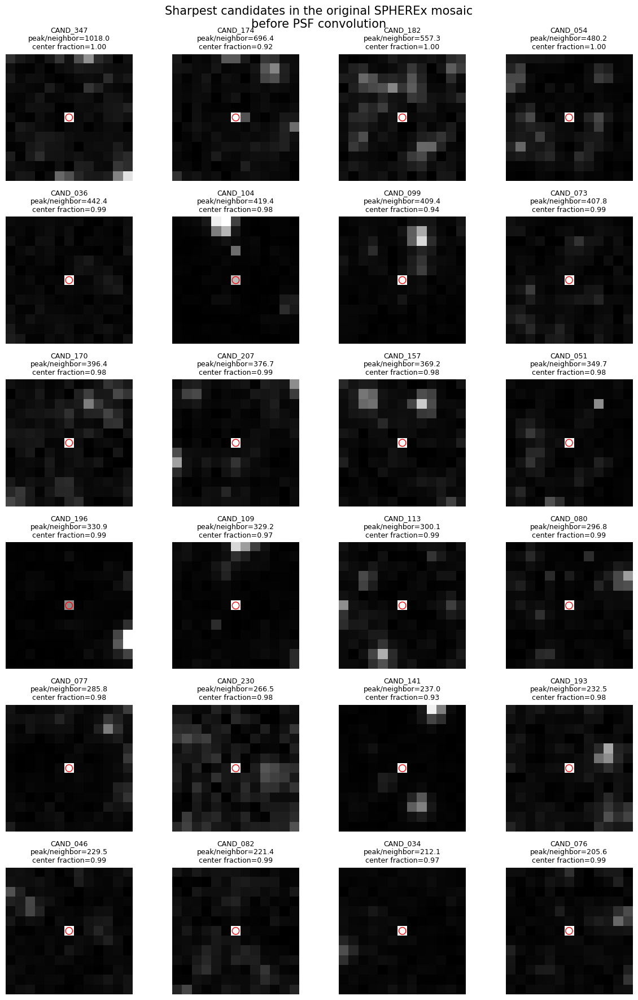

Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop12_candidates\sharpest_candidates_original_spherex.png


In [3]:
# ============================================================
# ORIGINAL-SPHEREx POSTAGE STAMPS
# ============================================================

sharpest = (
    candidates_sharpness
    .replace([np.inf, -np.inf], np.nan)
    .dropna(
        subset=[
            "peak_neighbor_median_ratio"
        ]
    )
    .sort_values(
        "peak_neighbor_median_ratio",
        ascending=False
    )
    .head(24)
    .reset_index(drop=True)
)


ncols = 4
nrows = int(
    np.ceil(len(sharpest) / ncols)
)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(12, 3 * nrows)
)

axes = np.asarray(axes).reshape(-1)

for ax in axes:
    ax.axis("off")


stamp_half_size = 6

for i, row in sharpest.iterrows():

    x = int(round(row["xcentroid"]))
    y = int(round(row["ycentroid"]))

    stamp = sp_crop_original[
        y - stamp_half_size:y + stamp_half_size + 1,
        x - stamp_half_size:x + stamp_half_size + 1
    ]

    finite = stamp[np.isfinite(stamp)]

    if finite.size == 0:
        continue

    vmin = np.percentile(finite, 5)
    vmax = np.percentile(finite, 99.5)

    axes[i].imshow(
        stamp,
        origin="lower",
        cmap="gray",
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest"
    )

    # Mark the central candidate pixel.
    axes[i].scatter(
        stamp_half_size,
        stamp_half_size,
        facecolors="none",
        edgecolors="red",
        s=80
    )

    axes[i].set_title(
        f'{row["candidate_id"]}\n'
        f'peak/neighbor='
        f'{row["peak_neighbor_median_ratio"]:.1f}\n'
        f'center fraction='
        f'{row["center_fraction_3x3"]:.2f}',
        fontsize=9
    )

    axes[i].axis("off")


plt.suptitle(
    "Sharpest candidates in the original SPHEREx mosaic\n"
    "before PSF convolution",
    fontsize=15
)

plt.tight_layout()

sharpness_plot = (
    CANDIDATE_FOLDER
    / "sharpest_candidates_original_spherex.png"
)

plt.savefig(
    sharpness_plot,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(sharpness_plot)

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
from astropy.io import fits


BASE = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
)

WORK = BASE / "new_mosaic_matching"
LOCAL = WORK / "local_crop_test"
CANDIDATE_FOLDER = LOCAL / "crop12_candidates"


# ------------------------------------------------------------
# Find files
# ------------------------------------------------------------

mosaic_path = BASE / "image_SPHEREx-Mosaic.fits"

if not mosaic_path.exists():
    matches = list(BASE.rglob("image_SPHEREx-Mosaic.fits"))

    if not matches:
        raise FileNotFoundError(
            "Could not find image_SPHEREx-Mosaic.fits"
        )

    mosaic_path = matches[0]


sharpness_path = (
    CANDIDATE_FOLDER
    / "crop12_candidates_with_sharpness.csv"
)

if not sharpness_path.exists():
    matches = list(
        BASE.rglob(
            "crop12_candidates_with_sharpness.csv"
        )
    )

    if not matches:
        raise FileNotFoundError(
            "Could not find the sharpness catalog."
        )

    sharpness_path = matches[0]


# ------------------------------------------------------------
# Load catalog
# ------------------------------------------------------------

catalog = pd.read_csv(sharpness_path)


# ------------------------------------------------------------
# Load SPHEREx FLAGS plane
# ------------------------------------------------------------

with fits.open(mosaic_path) as hdul:

    print(hdul.info())

    if "FLAGS" not in hdul:
        raise KeyError(
            "This FITS file does not contain a FLAGS extension."
        )

    flags = np.asarray(
        hdul["FLAGS"].data
    )

    if flags.ndim == 3:
        flags = flags[0]


print("\nFLAGS shape:", flags.shape)
print("FLAGS dtype:", flags.dtype)


# ------------------------------------------------------------
# Crop-12 full-image location
# ------------------------------------------------------------

crop_x0 = 1536
crop_y0 = 1024

catalog["full_x_recomputed"] = (
    catalog["xcentroid"] + crop_x0
)

catalog["full_y_recomputed"] = (
    catalog["ycentroid"] + crop_y0
)


# Use saved full coordinates when available.
x_column = (
    "full_x"
    if "full_x" in catalog.columns
    else "full_x_recomputed"
)

y_column = (
    "full_y"
    if "full_y" in catalog.columns
    else "full_y_recomputed"
)


# ------------------------------------------------------------
# Read flags at each candidate pixel
# ------------------------------------------------------------

flag_values = []
transient_bits = []

for _, row in catalog.iterrows():

    x = int(round(row[x_column]))
    y = int(round(row[y_column]))

    if (
        0 <= x < flags.shape[1]
        and 0 <= y < flags.shape[0]
    ):
        value = int(flags[y, x])
    else:
        value = -1

    flag_values.append(value)

    # Bit 0 corresponds to TRANSIENT.
    transient_bits.append(
        value >= 0 and bool(value & 1)
    )


catalog["flags_value"] = flag_values
catalog["official_transient_bit"] = transient_bits


suspects = catalog[
    catalog["single_pixel_suspect"] == True
].copy()


print("\nTotal candidates:", len(catalog))
print(
    "Single-pixel suspects:",
    len(suspects)
)

print(
    "Suspects with official TRANSIENT bit:",
    suspects["official_transient_bit"].sum()
)

print(
    "Suspects with any nonzero flag:",
    (suspects["flags_value"] != 0).sum()
)


print("\nTop suspicious candidates and flags:")

columns_to_show = [
    "candidate_id",
    "sign",
    "snr",
    "peak_neighbor_median_ratio",
    "center_fraction_3x3",
    "flags_value",
    "official_transient_bit",
]

for optional_column in [
    "ra_deg",
    "dec_deg",
]:
    if optional_column in suspects.columns:
        columns_to_show.append(optional_column)


print(
    suspects[
        columns_to_show
    ]
    .replace([np.inf, -np.inf], np.nan)
    .sort_values(
        "peak_neighbor_median_ratio",
        ascending=False
    )
    .head(30)
    .to_string(index=False)
)


output_path = (
    CANDIDATE_FOLDER
    / "crop12_candidates_with_flags.csv"
)

catalog.to_csv(
    output_path,
    index=False
)

print("\nSaved:")
print(output_path)

Filename: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\image_SPHEREx-Mosaic.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU        51   (2049, 2049, 1)   float32   
  2  NHITS         1 ImageHDU        51   (2049, 2049, 1)   int32   
  3  FLAGS         1 ImageHDU        55   (2049, 2049, 1)   int32   
  4  SPECTRAL_CHANNELS    1 BinTableHDU     29   1R x 8C   [I, I, E, E, E, E, E, E]   
  5  WCS-WAVE      1 BinTableHDU     18   1R x 3C   [J, E, E]   
None

FLAGS shape: (2049, 2049)
FLAGS dtype: >i4

Total candidates: 379
Single-pixel suspects: 141
Suspects with official TRANSIENT bit: 0
Suspects with any nonzero flag: 141

Top suspicious candidates and flags:
candidate_id     sign       snr  peak_neighbor_median_ratio  center_fraction_3x3  flags_value  official_transient_bit     ra_deg   dec_deg
    CAND_347 positive  6.929455                 1018.045978             0.999019       524288

In [5]:
import numpy as np
import pandas as pd
from pathlib import Path

candidate_folder = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
    r"\new_mosaic_matching\local_crop_test\crop12_candidates"
)

input_path = candidate_folder / "crop12_candidates_with_flags.csv"
df = pd.read_csv(input_path)

# Official SPHEREx Level-2 bit positions
FLAG_BITS = {
    "TRANSIENT": 0,
    "OVERFLOW": 1,
    "SUR_ERROR": 2,
    "NONFUNC": 6,
    "DICHROIC": 7,
    "MISSING_DATA": 9,
    "HOT": 10,
    "COLD": 11,
    "FULLSAMPLE": 12,
    "PHANMISS": 14,
    "NONLINEAR": 15,
    "PERSIST": 17,
    "OUTLIER": 19,
    "SOURCE": 21,
    "GHOST": 22,
    "GHOST_EXT": 24,
    "BLOOM": 26,
    "SNOWBALL": 27,
    "HALO": 28,
    "SATELLITE_HALO": 29,
}

flags = df["flags_value"].fillna(0).astype(np.int64)

for name, bit in FLAG_BITS.items():
    df[f"flag_{name.lower()}"] = (flags & (1 << bit)) != 0

def describe_flags(value):
    value = int(value)
    names = [
        name
        for name, bit in FLAG_BITS.items()
        if value & (1 << bit)
    ]
    return ", ".join(names) if names else "NONE"

df["decoded_flags"] = flags.map(describe_flags)

suspects = df[df["single_pixel_suspect"] == True].copy()

print("Single-pixel suspects:", len(suspects))
print("Marked OUTLIER:", suspects["flag_outlier"].sum())
print("Marked SOURCE:", suspects["flag_source"].sum())
print(
    "Marked OUTLIER + SOURCE:",
    (
        suspects["flag_outlier"]
        & suspects["flag_source"]
    ).sum()
)
print(
    "SOURCE only:",
    (
        suspects["flag_source"]
        & ~suspects["flag_outlier"]
    ).sum()
)

# Best candidates for repeat-exposure testing:
# sharp, positive candidates that lie on a known source but were not
# already classified as OUTLIER by the pipeline.
repeat_test = suspects[
    (suspects["sign"] == "positive")
    & suspects["flag_source"]
    & ~suspects["flag_outlier"]
].copy()

# Replace infinite ratios only for sorting/display
repeat_test["ratio_for_sorting"] = (
    repeat_test["peak_neighbor_median_ratio"]
    .replace([np.inf, -np.inf], np.nan)
)

repeat_test = repeat_test.sort_values(
    ["center_fraction_3x3", "snr"],
    ascending=[False, False]
)

columns = [
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "snr",
    "sp_center_value",
    "sp_neighbor_median",
    "peak_neighbor_median_ratio",
    "center_fraction_3x3",
    "flags_value",
    "decoded_flags",
]

top_repeat_test = repeat_test[columns].head(10)

print("\nTop SOURCE-only sharp candidates:")
print(top_repeat_test.to_string(index=False))

output_path = candidate_folder / "top10_repeat_exposure_candidates.csv"
top_repeat_test.to_csv(output_path, index=False)

decoded_path = candidate_folder / "crop12_candidates_flags_decoded.csv"
df.to_csv(decoded_path, index=False)

print("\nSaved:")
print(output_path)
print(decoded_path)

Single-pixel suspects: 141
Marked OUTLIER: 91
Marked SOURCE: 60
Marked OUTLIER + SOURCE: 10
SOURCE only: 50

Top SOURCE-only sharp candidates:
candidate_id     ra_deg   dec_deg       snr  sp_center_value  sp_neighbor_median  peak_neighbor_median_ratio  center_fraction_3x3  flags_value decoded_flags
    CAND_182 267.483994 62.647835 17.016555         0.409069            0.000734                  557.256160             0.998209      2097152        SOURCE
    CAND_054 268.660199 62.415183 48.952363         0.925540            0.001927                  480.210376             0.997922      2097152        SOURCE
    CAND_338 268.094220 62.645150  7.142711         0.189505            0.001219                  155.490409             0.993610      2097152        SOURCE
    CAND_207 268.561830 62.447883 15.361145         0.541175            0.001437                  376.660996             0.990323      2097152        SOURCE
    CAND_352 268.381986 62.293058  6.848083         0.119149            

In [6]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from datetime import datetime

candidate_folder = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
    r"\new_mosaic_matching\local_crop_test\crop12_candidates"
)

zip_path = candidate_folder / "SPHEREx_transient_diagnostic_update.zip"

# Required files
files_to_send = [
    candidate_folder / "sharpest_candidates_original_spherex.png",
    candidate_folder / "crop12_candidates_with_flags.csv",
    candidate_folder / "crop12_candidate_catalog.csv",
]

# Automatically include useful candidate/residual overview PNGs if they exist
optional_patterns = [
    "*candidate*overview*.png",
    "*candidate*map*.png",
    "*strongest*residual*.png",
]

for pattern in optional_patterns:
    for file_path in candidate_folder.glob(pattern):
        if file_path not in files_to_send:
            files_to_send.append(file_path)

# Remove missing files and duplicates
existing_files = []
seen = set()

for file_path in files_to_send:
    file_path = file_path.resolve()
    if file_path.exists() and file_path not in seen:
        existing_files.append(file_path)
        seen.add(file_path)

if not existing_files:
    raise FileNotFoundError(
        f"No deliverable files were found in:\n{candidate_folder}"
    )

# Create a brief README inside the ZIP
readme_text = f"""SPHEREx transient diagnostic progress update
Created: {datetime.now():%Y-%m-%d %H:%M}

Summary:
- 379 residual candidates were examined in the selected test crop.
- 141 candidates were identified as likely single-pixel transient suspects.
- The candidates were compared against the SPHEREx FLAGS image.
- The next step is repeat-detection testing in nearby-wavelength SPHEREx images.

Included files:
""" + "\n".join(f"- {file_path.name}" for file_path in existing_files)

with ZipFile(zip_path, mode="w", compression=ZIP_DEFLATED) as zip_file:
    for file_path in existing_files:
        zip_file.write(file_path, arcname=file_path.name)

    zip_file.writestr("README.txt", readme_text)

print("ZIP successfully created:")
print(zip_path)

print("\nIncluded files:")
for file_path in existing_files:
    print(" -", file_path.name)

print(" - README.txt")

print(f"\nZIP size: {zip_path.stat().st_size / (1024**2):.2f} MB")

ZIP successfully created:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop12_candidates\SPHEREx_transient_diagnostic_update.zip

Included files:
 - sharpest_candidates_original_spherex.png
 - crop12_candidates_with_flags.csv
 - crop12_candidate_catalog.csv
 - crop12_candidate_map.png
 - README.txt

ZIP size: 1.17 MB


In [1]:
%pip install --upgrade astroquery

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

import astropy.units as u
from astropy.coordinates import SkyCoord
from astroquery.ipac.irsa import Irsa


BASE = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
)

CANDIDATE_FOLDER = (
    BASE
    / "new_mosaic_matching"
    / "local_crop_test"
    / "crop12_candidates"
)

# Prefer the catalog containing both flags and sharpness information.
possible_catalogs = [
    CANDIDATE_FOLDER / "crop12_candidates_with_flags.csv",
    CANDIDATE_FOLDER / "crop12_candidates_flags_decoded.csv",
    CANDIDATE_FOLDER / "crop12_candidates_with_sharpness.csv",
    CANDIDATE_FOLDER / "crop12_candidate_catalog.csv",
]

candidate_path = next(
    (path for path in possible_catalogs if path.exists()),
    None
)

if candidate_path is None:
    matches = list(
        BASE.rglob("crop12_candidates_with_flags.csv")
    )

    if not matches:
        matches = list(
            BASE.rglob("crop12_candidate_catalog.csv")
        )

    if not matches:
        raise FileNotFoundError(
            "Could not locate a candidate catalog."
        )

    candidate_path = matches[0]


candidates = pd.read_csv(candidate_path)

required_columns = ["candidate_id", "ra_deg", "dec_deg"]

missing = [
    column
    for column in required_columns
    if column not in candidates.columns
]

if missing:
    raise KeyError(
        f"Missing required columns: {missing}\n"
        f"Available columns: {candidates.columns.tolist()}"
    )

# Remove rows without valid sky coordinates.
candidates = candidates[
    np.isfinite(candidates["ra_deg"])
    & np.isfinite(candidates["dec_deg"])
].copy()

candidates = candidates.reset_index(drop=True)

candidate_coords = SkyCoord(
    ra=candidates["ra_deg"].to_numpy() * u.deg,
    dec=candidates["dec_deg"].to_numpy() * u.deg,
    frame="icrs",
)

print("Loaded catalog:")
print(candidate_path)

print("\nCandidates with valid RA/Dec:")
print(len(candidates))

print("\nRA range:")
print(candidates["ra_deg"].min(), "to", candidates["ra_deg"].max())

print("\nDec range:")
print(candidates["dec_deg"].min(), "to", candidates["dec_deg"].max())

Loaded catalog:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop12_candidates\crop12_candidates_with_flags.csv

Candidates with valid RA/Dec:
379

RA range:
267.0003868009682 to 268.7528856343936

Dec range:
61.87308372978848 to 62.69573259595441


In [3]:
# Approximate center of all candidate positions.
center_ra = np.median(candidates["ra_deg"])
center_dec = np.median(candidates["dec_deg"])

search_center = SkyCoord(
    ra=center_ra * u.deg,
    dec=center_dec * u.deg,
    frame="icrs",
)

# Radius required to include every candidate, plus a margin.
candidate_separations = search_center.separation(
    candidate_coords
)

search_radius = (
    candidate_separations.max()
    + 30.0 * u.arcsec
)

print("Search center RA:", search_center.ra.deg)
print("Search center Dec:", search_center.dec.deg)
print("Search radius:", search_radius.to(u.deg))

Search center RA: 267.89987815642723
Search center Dec: 62.253846937202944
Search radius: 0d33m27.59943679s


In [4]:
return_columns = ",".join([
    "designation",
    "ra",
    "dec",
    "w1mpro",
    "w1sigmpro",
    "w1snr",
    "w2mpro",
    "w2sigmpro",
    "w2snr",
    "ph_qual",
    "cc_flags",
    "ext_flg",
])

print("Querying IRSA AllWISE catalog...")
print("This can take a little while.")

wise_table = Irsa.query_region(
    search_center,
    catalog="allwise_p3as_psd",
    radius=search_radius,
    columns=return_columns,
)

print("\nWISE catalog sources returned:")
print(len(wise_table))

print("\nReturned columns:")
print(wise_table.colnames)

print("\nFirst five sources:")
print(wise_table[:5])

Querying IRSA AllWISE catalog...
This can take a little while.

WISE catalog sources returned:
19810

Returned columns:
['designation', 'ra', 'dec', 'w1mpro', 'w1sigmpro', 'w1snr', 'w2mpro', 'w2sigmpro', 'w2snr', 'ph_qual', 'cc_flags', 'ext_flg']

First five sources:
    designation          ra        dec     w1mpro w1sigmpro w1snr w2mpro w2sigmpro w2snr ph_qual cc_flags ext_flg
                        deg        deg      mag      mag           mag      mag                                  
------------------- ----------- ---------- ------ --------- ----- ------ --------- ----- ------- -------- -------
J175317.67+623034.0 268.3236384 62.5094707 15.922     0.033  33.3 15.847     0.059  18.4    AACU     0000       0
J175420.43+623330.4 268.5851467 62.5584702 15.366     0.029  37.5 15.223     0.044  24.8    AAUU     0000       0
J175308.83+623251.8 268.2867953 62.5477385 17.360     0.062  17.5 17.391     0.206   5.3    ABBU     0000       0
J175432.47+623217.5 268.6352945 62.5382028 17.38

In [5]:
wise_df = wise_table.to_pandas()

wise_coords = SkyCoord(
    ra=wise_df["ra"].to_numpy(dtype=float) * u.deg,
    dec=wise_df["dec"].to_numpy(dtype=float) * u.deg,
    frame="icrs",
)

# For each candidate, find the closest WISE catalog source.
nearest_index, separation_2d, _ = (
    candidate_coords.match_to_catalog_sky(wise_coords)
)

nearest_wise = (
    wise_df.iloc[nearest_index]
    .reset_index(drop=True)
)

matched = candidates.reset_index(drop=True).copy()

matched["wise_designation"] = (
    nearest_wise["designation"].astype(str).to_numpy()
)

matched["wise_ra_deg"] = (
    nearest_wise["ra"].to_numpy(dtype=float)
)

matched["wise_dec_deg"] = (
    nearest_wise["dec"].to_numpy(dtype=float)
)

matched["wise_separation_arcsec"] = (
    separation_2d.arcsec
)

for column in [
    "w1mpro",
    "w1sigmpro",
    "w1snr",
    "w2mpro",
    "w2sigmpro",
    "w2snr",
    "ph_qual",
    "cc_flags",
    "ext_flg",
]:
    if column in nearest_wise.columns:
        matched[f"wise_{column}"] = (
            nearest_wise[column].to_numpy()
        )

# Initial matching threshold.
match_radius_arcsec = 3.0

matched["wise_catalog_match"] = (
    matched["wise_separation_arcsec"]
    <= match_radius_arcsec
)

print("Total candidates:", len(matched))

print(
    f"WISE matches within {match_radius_arcsec} arcsec:",
    matched["wise_catalog_match"].sum()
)

print(
    "No WISE match within threshold:",
    (~matched["wise_catalog_match"]).sum()
)

print("\nNearest-match separation statistics:")

print(
    matched["wise_separation_arcsec"]
    .describe(
        percentiles=[0.25, 0.5, 0.75, 0.90, 0.95]
    )
)

Total candidates: 379
WISE matches within 3.0 arcsec: 134
No WISE match within threshold: 245

Nearest-match separation statistics:
count    379.000000
mean       6.966934
std        6.057678
min        0.069134
25%        2.086461
50%        4.809919
75%       10.373301
90%       15.271158
95%       19.272016
max       32.036651
Name: wise_separation_arcsec, dtype: float64


In [6]:
output_path = (
    CANDIDATE_FOLDER
    / "crop12_candidates_allwise_crossmatch.csv"
)

matched.to_csv(
    output_path,
    index=False
)

print("Saved:")
print(output_path)


columns_to_show = [
    "candidate_id",
    "sign",
    "ra_deg",
    "dec_deg",
    "wise_catalog_match",
    "wise_separation_arcsec",
    "wise_designation",
    "wise_w1mpro",
    "wise_w1sigmpro",
    "wise_w1snr",
    "wise_ph_qual",
    "wise_cc_flags",
]

columns_to_show = [
    column
    for column in columns_to_show
    if column in matched.columns
]

print("\nClosest WISE matches:")

print(
    matched[
        columns_to_show
    ]
    .sort_values(
        "wise_separation_arcsec"
    )
    .head(30)
    .to_string(index=False)
)

Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop12_candidates\crop12_candidates_allwise_crossmatch.csv

Closest WISE matches:
candidate_id     sign     ra_deg   dec_deg  wise_catalog_match  wise_separation_arcsec    wise_designation  wise_w1mpro  wise_w1sigmpro  wise_w1snr wise_ph_qual wise_cc_flags
    CAND_095 negative 268.019535 62.409542                True                0.069134 J175204.69+622434.2     9.904000           0.023        47.8         AAAB          0000
    CAND_181 negative 267.787058 62.461564                True                0.123390 J175108.89+622741.5    11.329000           0.023        47.2         AAAU          0000
    CAND_083 negative 267.555770 62.580735                True                0.166755 J175013.38+623450.4    10.739000           0.023        46.9         AAAC          0000
    CAND_297 negative 267.815906 62.170966                True                0.256892 J175115.85+621015.5    13.241000           

In [7]:
summary_rows = []

def add_summary(label, mask):
    subset = matched[mask]

    summary_rows.append({
        "group": label,
        "total_candidates": len(subset),
        "wise_matches_within_3arcsec":
            int(subset["wise_catalog_match"].sum()),
        "wise_match_fraction":
            subset["wise_catalog_match"].mean()
            if len(subset) > 0
            else np.nan,
        "median_separation_arcsec":
            subset["wise_separation_arcsec"].median()
            if len(subset) > 0
            else np.nan,
    })


add_summary(
    "All candidates",
    np.ones(len(matched), dtype=bool)
)

if "single_pixel_suspect" in matched.columns:
    add_summary(
        "Single-pixel suspects",
        matched["single_pixel_suspect"].fillna(False).astype(bool)
    )

    add_summary(
        "Not single-pixel suspects",
        ~matched["single_pixel_suspect"].fillna(False).astype(bool)
    )

if "psf_like_preliminary" in matched.columns:
    add_summary(
        "Preliminary PSF-like",
        matched["psf_like_preliminary"].fillna(False).astype(bool)
    )

if "sign" in matched.columns:
    add_summary(
        "Positive residuals",
        matched["sign"].astype(str).str.lower() == "positive"
    )

    add_summary(
        "Negative residuals",
        matched["sign"].astype(str).str.lower() == "negative"
    )


summary = pd.DataFrame(summary_rows)

print(summary.to_string(index=False))

summary_path = (
    CANDIDATE_FOLDER
    / "crop12_allwise_crossmatch_summary.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

print("\nSaved summary:")
print(summary_path)

                    group  total_candidates  wise_matches_within_3arcsec  wise_match_fraction  median_separation_arcsec
           All candidates               379                          134             0.353562                  4.809919
    Single-pixel suspects               141                            6             0.042553                 10.993537
Not single-pixel suspects               238                          128             0.537815                  2.760348
     Preliminary PSF-like                82                           38             0.463415                  3.103747
       Positive residuals               183                           13             0.071038                  9.905269
       Negative residuals               196                          121             0.617347                  2.440957

Saved summary:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop12_candidates\crop12_allwise_crossmatch_summary.csv


In [8]:
from pathlib import Path

import numpy as np
import pandas as pd

from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u

from photutils.aperture import (
    CircularAperture,
    CircularAnnulus,
    aperture_photometry,
)

BASE = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
)

CANDIDATE_FOLDER = (
    BASE
    / "new_mosaic_matching"
    / "local_crop_test"
    / "crop12_candidates"
)

crossmatch_path = (
    CANDIDATE_FOLDER
    / "crop12_candidates_allwise_crossmatch.csv"
)

spherex_path = (
    BASE
    / "new_mosaic_matching"
    / "spherex_3p4um_mosaic_2d.fits"
)

# Prefer the WISE image already reprojected onto the exact SPHEREx grid.
wise_possible_paths = [
    BASE
    / "new_mosaic_matching"
    / "wise_w1_on_exact_spherex_grid.fits",

    BASE
    / "new_mosaic_matching"
    / "wise_reprojected_to_spherex.fits",

    BASE
    / "new_mosaic_matching"
    / "wise_background_subtracted_scaled.fits",
]

wise_path = next(
    (path for path in wise_possible_paths if path.exists()),
    None
)

if not crossmatch_path.exists():
    raise FileNotFoundError(crossmatch_path)

if not spherex_path.exists():
    raise FileNotFoundError(spherex_path)

if wise_path is None:
    matches = list(
        BASE.rglob("wise_w1_on_exact_spherex_grid.fits")
    )

    if not matches:
        matches = list(
            BASE.rglob("*wise*reproject*.fits")
        )

    if not matches:
        raise FileNotFoundError(
            "Could not locate the reprojected WISE image."
        )

    wise_path = matches[0]


matched = pd.read_csv(crossmatch_path)

sp_data = fits.getdata(
    spherex_path
).astype(float)

sp_header = fits.getheader(
    spherex_path
)

wise_data = fits.getdata(
    wise_path
).astype(float)

wise_header = fits.getheader(
    wise_path
)

sp_data = np.squeeze(sp_data)
wise_data = np.squeeze(wise_data)

sp_wcs = WCS(sp_header).celestial
wise_wcs = WCS(wise_header).celestial

print("Candidate table:", crossmatch_path)
print("SPHEREx:", spherex_path)
print("WISE:", wise_path)

print("\nShapes")
print("SPHEREx:", sp_data.shape)
print("WISE:", wise_data.shape)

print("\nCandidate rows:", len(matched))

Candidate table: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop12_candidates\crop12_candidates_allwise_crossmatch.csv
SPHEREx: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\spherex_3p4um_mosaic_2d.fits
WISE: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\wise_w1_on_exact_spherex_grid.fits

Shapes
SPHEREx: (2049, 2049)
WISE: (2049, 2049)

Candidate rows: 379


In [9]:
candidate_coords = SkyCoord(
    ra=matched["ra_deg"].to_numpy(float) * u.deg,
    dec=matched["dec_deg"].to_numpy(float) * u.deg,
    frame="icrs",
)

sp_x, sp_y = sp_wcs.world_to_pixel(candidate_coords)
wise_x, wise_y = wise_wcs.world_to_pixel(candidate_coords)

matched["sp_x"] = sp_x
matched["sp_y"] = sp_y
matched["wise_x"] = wise_x
matched["wise_y"] = wise_y

sp_inside = (
    (sp_x >= 0)
    & (sp_x < sp_data.shape[1])
    & (sp_y >= 0)
    & (sp_y < sp_data.shape[0])
)

wise_inside = (
    (wise_x >= 0)
    & (wise_x < wise_data.shape[1])
    & (wise_y >= 0)
    & (wise_y < wise_data.shape[0])
)

matched["inside_spherex"] = sp_inside
matched["inside_wise"] = wise_inside

print(
    "Inside SPHEREx:",
    matched["inside_spherex"].sum(),
    "/",
    len(matched),
)

print(
    "Inside WISE:",
    matched["inside_wise"].sum(),
    "/",
    len(matched),
)

print("\nMedian SPHEREx-WISE pixel-coordinate difference:")

print(
    "dx:",
    np.nanmedian(sp_x - wise_x),
)

print(
    "dy:",
    np.nanmedian(sp_y - wise_y),
)

Inside SPHEREx: 379 / 379
Inside WISE: 379 / 379

Median SPHEREx-WISE pixel-coordinate difference:
dx: 0.0
dy: 0.0


In [10]:
def forced_aperture_photometry(
    image,
    x_positions,
    y_positions,
    aperture_radius=3.0,
    annulus_inner_radius=5.0,
    annulus_outer_radius=8.0,
):
    positions = np.column_stack([
        x_positions,
        y_positions,
    ])

    source_apertures = CircularAperture(
        positions,
        r=aperture_radius,
    )

    background_annuli = CircularAnnulus(
        positions,
        r_in=annulus_inner_radius,
        r_out=annulus_outer_radius,
    )

    source_table = aperture_photometry(
        image,
        source_apertures,
        method="exact",
    )

    aperture_sum = np.asarray(
        source_table["aperture_sum"],
        dtype=float,
    )

    source_area = source_apertures.area

    background_median = np.full(
        len(positions),
        np.nan,
        dtype=float,
    )

    background_std = np.full(
        len(positions),
        np.nan,
        dtype=float,
    )

    valid_annulus_pixels = np.zeros(
        len(positions),
        dtype=int,
    )

    annulus_masks = background_annuli.to_mask(
        method="center"
    )

    for index, annulus_mask in enumerate(annulus_masks):
        cutout = annulus_mask.multiply(image)

        if cutout is None:
            continue

        mask_data = annulus_mask.data

        values = cutout[
            (mask_data > 0)
            & np.isfinite(cutout)
        ]

        if len(values) < 10:
            continue

        # Remove extreme pixels such as nearby stars or detector defects.
        median_value = np.nanmedian(values)
        mad = np.nanmedian(
            np.abs(values - median_value)
        )

        robust_sigma = 1.4826 * mad

        if np.isfinite(robust_sigma) and robust_sigma > 0:
            keep = (
                np.abs(values - median_value)
                <= 3.0 * robust_sigma
            )

            clipped_values = values[keep]
        else:
            clipped_values = values

        if len(clipped_values) < 10:
            continue

        background_median[index] = np.nanmedian(
            clipped_values
        )

        background_std[index] = np.nanstd(
            clipped_values
        )

        valid_annulus_pixels[index] = len(
            clipped_values
        )

    background_in_aperture = (
        background_median
        * source_area
    )

    net_aperture_flux = (
        aperture_sum
        - background_in_aperture
    )

    # Approximate uncertainty from local pixel scatter.
    net_flux_error = (
        background_std
        * np.sqrt(source_area)
    )

    with np.errstate(
        divide="ignore",
        invalid="ignore",
    ):
        aperture_snr = (
            net_aperture_flux
            / net_flux_error
        )

    return pd.DataFrame({
        "aperture_sum": aperture_sum,
        "background_median":
            background_median,
        "background_std":
            background_std,
        "background_in_aperture":
            background_in_aperture,
        "net_aperture_flux":
            net_aperture_flux,
        "net_flux_error":
            net_flux_error,
        "aperture_snr":
            aperture_snr,
        "valid_annulus_pixels":
            valid_annulus_pixels,
    })

In [11]:
sp_phot = forced_aperture_photometry(
    image=sp_data,
    x_positions=sp_x,
    y_positions=sp_y,
)

wise_phot = forced_aperture_photometry(
    image=wise_data,
    x_positions=wise_x,
    y_positions=wise_y,
)

for column in sp_phot.columns:
    matched[f"sp_{column}"] = (
        sp_phot[column].to_numpy()
    )

for column in wise_phot.columns:
    matched[f"wise_image_{column}"] = (
        wise_phot[column].to_numpy()
    )

print("Photometry completed.")

print("\nFinite SPHEREx measurements:")
print(
    np.isfinite(
        matched["sp_net_aperture_flux"]
    ).sum()
)

print("\nFinite WISE image measurements:")
print(
    np.isfinite(
        matched["wise_image_net_aperture_flux"]
    ).sum()
)

Photometry completed.

Finite SPHEREx measurements:
379

Finite WISE image measurements:
379


In [12]:
from astropy.wcs.utils import proj_plane_pixel_area

pixel_area_deg2 = proj_plane_pixel_area(
    sp_wcs
) * u.deg**2

pixel_area_sr = pixel_area_deg2.to(
    u.sr
).value

print(
    "SPHEREx pixel area:",
    pixel_area_sr,
    "sr",
)

matched["sp_flux_jy"] = (
    matched["sp_net_aperture_flux"]
    * 1.0e6
    * pixel_area_sr
)

matched["sp_flux_error_jy"] = (
    matched["sp_net_flux_error"]
    * 1.0e6
    * pixel_area_sr
)

matched["sp_flux_mjy"] = (
    matched["sp_flux_jy"]
    * 1000.0
)

matched["sp_flux_error_mjy"] = (
    matched["sp_flux_error_jy"]
    * 1000.0
)

print(
    "Median positive SPHEREx flux:",
    matched.loc[
        matched["sp_flux_mjy"] > 0,
        "sp_flux_mjy",
    ].median(),
    "mJy",
)

SPHEREx pixel area: 8.889963240649946e-10 sr
Median positive SPHEREx flux: 1.662061920293994 mJy


In [13]:
WISE_W1_ZEROPOINT_JY = 309.540

w1_mag = pd.to_numeric(
    matched.get("wise_w1mpro"),
    errors="coerce",
)

w1_mag_error = pd.to_numeric(
    matched.get("wise_w1sigmpro"),
    errors="coerce",
)

matched["wise_catalog_w1_flux_jy"] = (
    WISE_W1_ZEROPOINT_JY
    * 10.0 ** (-w1_mag / 2.5)
)

matched["wise_catalog_w1_flux_mjy"] = (
    matched["wise_catalog_w1_flux_jy"]
    * 1000.0
)

# Magnitude-error propagation:
# dF/F = ln(10)/2.5 × dm
matched["wise_catalog_w1_flux_error_jy"] = (
    matched["wise_catalog_w1_flux_jy"]
    * np.log(10.0)
    / 2.5
    * w1_mag_error
)

matched["wise_catalog_w1_flux_error_mjy"] = (
    matched["wise_catalog_w1_flux_error_jy"]
    * 1000.0
)

# Only consider it a catalog flux when the positional match passed.
matched.loc[
    ~matched["wise_catalog_match"].fillna(False),
    [
        "wise_catalog_w1_flux_jy",
        "wise_catalog_w1_flux_mjy",
        "wise_catalog_w1_flux_error_jy",
        "wise_catalog_w1_flux_error_mjy",
    ],
] = np.nan

print(
    "WISE catalog fluxes available:",
    matched[
        "wise_catalog_w1_flux_mjy"
    ].notna().sum()
)

WISE catalog fluxes available: 134


In [14]:
matched["sp_detected_3sigma"] = (
    matched["sp_aperture_snr"] >= 3.0
)

matched["wise_image_detected_3sigma"] = (
    matched["wise_image_aperture_snr"] >= 3.0
)

matched["catalog_and_sp_detection"] = (
    matched["wise_catalog_match"].fillna(False)
    & matched["sp_detected_3sigma"].fillna(False)
)

matched["sp_detection_no_wise_catalog"] = (
    matched["sp_detected_3sigma"].fillna(False)
    & ~matched["wise_catalog_match"].fillna(False)
)

matched["possible_real_variable"] = (
    matched["sp_detection_no_wise_catalog"]
)

if "single_pixel_suspect" in matched.columns:
    matched["possible_real_variable"] &= (
        ~matched[
            "single_pixel_suspect"
        ]
        .fillna(False)
        .astype(bool)
    )

if "psf_like_preliminary" in matched.columns:
    matched["possible_real_variable"] &= (
        matched[
            "psf_like_preliminary"
        ]
        .fillna(False)
        .astype(bool)
    )

print("SPHEREx ≥3σ detections:")
print(
    matched["sp_detected_3sigma"].sum()
)

print("\nWISE-image ≥3σ detections:")
print(
    matched[
        "wise_image_detected_3sigma"
    ].sum()
)

print("\nSPHEREx detections with a WISE catalog match:")
print(
    matched[
        "catalog_and_sp_detection"
    ].sum()
)

print("\nSPHEREx detections without a WISE catalog match:")
print(
    matched[
        "sp_detection_no_wise_catalog"
    ].sum()
)

print("\nInitial possible-variable subset:")
print(
    matched[
        "possible_real_variable"
    ].sum()
)

SPHEREx ≥3σ detections:
354

WISE-image ≥3σ detections:
298

SPHEREx detections with a WISE catalog match:
133

SPHEREx detections without a WISE catalog match:
221

Initial possible-variable subset:
44


In [15]:
photometry_output_path = (
    CANDIDATE_FOLDER
    / "crop12_candidates_forced_photometry.csv"
)

matched.to_csv(
    photometry_output_path,
    index=False,
)

print("Saved:")
print(photometry_output_path)


display_columns = [
    "candidate_id",
    "sign",
    "ra_deg",
    "dec_deg",
    "single_pixel_suspect",
    "psf_like_preliminary",
    "wise_catalog_match",
    "wise_separation_arcsec",
    "wise_designation",
    "sp_flux_mjy",
    "sp_flux_error_mjy",
    "sp_aperture_snr",
    "wise_catalog_w1_flux_mjy",
    "wise_catalog_w1_flux_error_mjy",
    "wise_image_net_aperture_flux",
    "wise_image_aperture_snr",
    "possible_real_variable",
]

display_columns = [
    column
    for column in display_columns
    if column in matched.columns
]

strongest = (
    matched[
        display_columns
    ]
    .sort_values(
        "sp_aperture_snr",
        ascending=False,
    )
    .head(40)
)

print(
    strongest.to_string(
        index=False
    )
)

Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\local_crop_test\crop12_candidates\crop12_candidates_forced_photometry.csv
candidate_id     sign     ra_deg   dec_deg  single_pixel_suspect  psf_like_preliminary  wise_catalog_match  wise_separation_arcsec    wise_designation  sp_flux_mjy  sp_flux_error_mjy  sp_aperture_snr  wise_catalog_w1_flux_mjy  wise_catalog_w1_flux_error_mjy  wise_image_net_aperture_flux  wise_image_aperture_snr  possible_real_variable
    CAND_001 positive 268.179392 62.590775                 False                 False                True                2.433544 J175242.72+623525.9   698.427555           0.111952      6238.618187                558.106112                       33.412257                   6496.245007              1313.614398                   False
    CAND_002 positive 267.151013 62.209032                 False                  True                True                0.319441 J174836.28+621232.6   732.898700           0.1289

In [16]:
import numpy as np
import pandas as pd

analysis = matched.copy()

# Make sure logical columns are true booleans.
for column in [
    "single_pixel_suspect",
    "psf_like_preliminary",
    "wise_catalog_match",
]:
    if column in analysis.columns:
        analysis[column] = (
            analysis[column]
            .fillna(False)
            .astype(bool)
        )

analysis["is_positive"] = (
    analysis["sign"]
    .astype(str)
    .str.lower()
    .eq("positive")
)

analysis["is_negative"] = (
    analysis["sign"]
    .astype(str)
    .str.lower()
    .eq("negative")
)

# Do not use the current aperture S/N for selection.
analysis["likely_single_pixel_transient"] = (
    analysis["single_pixel_suspect"]
)

analysis["positive_psf_like_no_wise_match"] = (
    analysis["is_positive"]
    & ~analysis["single_pixel_suspect"]
    & analysis["psf_like_preliminary"]
    & ~analysis["wise_catalog_match"]
)

analysis["positive_psf_like_with_wise_match"] = (
    analysis["is_positive"]
    & ~analysis["single_pixel_suspect"]
    & analysis["psf_like_preliminary"]
    & analysis["wise_catalog_match"]
)

analysis["negative_with_wise_match"] = (
    analysis["is_negative"]
    & analysis["wise_catalog_match"]
)

print("Total candidates:", len(analysis))
print(
    "Likely single-pixel transients:",
    analysis["likely_single_pixel_transient"].sum()
)
print(
    "Positive PSF-like, no WISE catalog match:",
    analysis["positive_psf_like_no_wise_match"].sum()
)
print(
    "Positive PSF-like, with WISE catalog match:",
    analysis["positive_psf_like_with_wise_match"].sum()
)
print(
    "Negative residuals with WISE match:",
    analysis["negative_with_wise_match"].sum()
)

priority_columns = [
    "candidate_id",
    "sign",
    "ra_deg",
    "dec_deg",
    "single_pixel_suspect",
    "psf_like_preliminary",
    "wise_catalog_match",
    "wise_separation_arcsec",
    "wise_designation",
    "sp_flux_mjy",
    "sp_flux_error_mjy",
    "wise_catalog_w1_flux_mjy",
    "wise_image_net_aperture_flux",
]

priority_columns = [
    col for col in priority_columns
    if col in analysis.columns
]

priority_candidates = (
    analysis.loc[
        analysis["positive_psf_like_no_wise_match"],
        priority_columns
    ]
    .sort_values(
        "sp_flux_mjy",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nPriority positive candidates:")
print(priority_candidates.head(30).to_string(index=False))

priority_path = (
    CANDIDATE_FOLDER
    / "positive_psf_like_no_wise_catalog_match.csv"
)

priority_candidates.to_csv(
    priority_path,
    index=False
)

print("\nSaved:")
print(priority_path)

Total candidates: 379
Likely single-pixel transients: 141
Positive PSF-like, no WISE catalog match: 15
Positive PSF-like, with WISE catalog match: 5
Negative residuals with WISE match: 121

Priority positive candidates:
candidate_id     sign     ra_deg   dec_deg  single_pixel_suspect  psf_like_preliminary  wise_catalog_match  wise_separation_arcsec    wise_designation  sp_flux_mjy  sp_flux_error_mjy  wise_catalog_w1_flux_mjy  wise_image_net_aperture_flux
    CAND_005 positive 268.704180 62.534401                 False                  True               False                7.906525 J175449.91+623208.5   166.415279           0.049978                       NaN                   3651.481621
    CAND_027 positive 267.981268 62.435402                 False                  True               False                7.296530 J175154.57+622603.9    47.028134           0.054984                       NaN                   1113.739027
    CAND_091 positive 267.088888 62.094928                 Fals

In [17]:
from pathlib import Path
from astropy.io import fits
import numpy as np

cube_path = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
    r"\spherex_nearby_wavelength_cube.fits"
)

if not cube_path.exists():
    raise FileNotFoundError(cube_path)

with fits.open(cube_path) as hdul:
    hdul.info()

    image_data = np.squeeze(
        hdul["IMAGE"].data.astype(float)
    )

    spectral_table = hdul["SPECTRAL_CHANNELS"].data
    wave_table = hdul["WCS-WAVE"].data

    print("\nIMAGE shape:")
    print(image_data.shape)

    print("\nSPECTRAL_CHANNELS:")
    print(spectral_table)

    print("\nWCS-WAVE:")
    print(wave_table)

    if image_data.ndim == 3:
        print("\nNumber of wavelength planes:")
        print(image_data.shape[0])
    else:
        print(
            "\nOnly one plane was returned. "
            "The wavelength range was too narrow or the request did not create a cube."
        )

Filename: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\spherex_nearby_wavelength_cube.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU        51   (2049, 2049, 5)   float32   
  2  NHITS         1 ImageHDU        51   (2049, 2049, 5)   int32   
  3  FLAGS         1 ImageHDU        55   (2049, 2049, 5)   int32   
  4  SPECTRAL_CHANNELS    1 BinTableHDU     29   5R x 8C   [I, I, E, E, E, E, E, E]   
  5  WCS-WAVE      1 BinTableHDU     18   1R x 3C   [5J, 5E, 5E]   

IMAGE shape:
(5, 2049, 2049)

SPECTRAL_CHANNELS:
[(4, 11, 3.204, 3.155, 3.252, 0.093, 35., 0.5)
 (4, 12, 3.293, 3.242, 3.342, 0.094, 35., 0.5)
 (4, 13, 3.383, 3.33 , 3.434, 0.096, 35., 0.6)
 (4, 14, 3.476, 3.422, 3.528, 0.098, 36., 0.6)
 (4, 15, 3.57 , 3.514, 3.624, 0.099, 36., 0.6)]

WCS-WAVE:
[([1, 2, 3, 4, 5], [[3.204], [3.293], [3.383], [3.476], [3.57 ]], [[0.093], [0.094], [0.096], [0.098], [0.099]])]

Number of wavelength

In [21]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u


BASE = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
)

CUBE_PATH = BASE / "spherex_nearby_wavelength_cube.fits"

PRIORITY_PATH = (
    BASE
    / "new_mosaic_matching"
    / "local_crop_test"
    / "crop12_candidates"
    / "positive_psf_like_no_wise_catalog_match.csv"
)

OUTPUT_FOLDER = (
    BASE
    / "new_mosaic_matching"
    / "nearby_wavelength_test"
)

OUTPUT_FOLDER.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Load the five-plane SPHEREx cube
# ------------------------------------------------------------

# ------------------------------------------------------------
# Load the five-plane SPHEREx cube and its table-based WCS
# ------------------------------------------------------------

with fits.open(CUBE_PATH) as hdul:

    cube = np.asarray(
        hdul["IMAGE"].data,
        dtype=float
    )

    cube = np.squeeze(cube)

    image_header = hdul["IMAGE"].header.copy()

    spectral_channels = hdul[
        "SPECTRAL_CHANNELS"
    ].data

    wavelengths = np.asarray(
        spectral_channels["WAVELENGTH"],
        dtype=float
    )

    # IMPORTANT:
    # WAVE-TAB needs access to the complete HDUList.
    full_cube_wcs = WCS(
        hdul["IMAGE"].header,
        fobj=hdul
    )

    # Keep only RA and Dec; we do not need the wavelength
    # axis to convert candidate coordinates into image pixels.
    cube_wcs = full_cube_wcs.celestial


if cube.ndim != 3:
    raise ValueError(
        f"Expected a three-dimensional cube, got {cube.shape}"
    )

if cube.shape[0] != len(wavelengths):
    raise ValueError(
        "Number of image planes does not match wavelength table."
    )


print("Cube shape:", cube.shape)
print("Wavelengths:", wavelengths)
print("Celestial WCS axes:", cube_wcs.world_n_dim)


# ------------------------------------------------------------
# Load the 15 priority candidates
# ------------------------------------------------------------

priority = pd.read_csv(PRIORITY_PATH)

required_columns = [
    "candidate_id",
    "ra_deg",
    "dec_deg",
]

missing = [
    column
    for column in required_columns
    if column not in priority.columns
]

if missing:
    raise KeyError(
        f"Missing candidate columns: {missing}"
    )


coords = SkyCoord(
    ra=priority["ra_deg"].to_numpy(float) * u.deg,
    dec=priority["dec_deg"].to_numpy(float) * u.deg,
    frame="icrs",
)

x_positions, y_positions = cube_wcs.world_to_pixel(
    coords
)


# ------------------------------------------------------------
# Measure the central source shape in every plane
# ------------------------------------------------------------

half_size = 5

rows = []

for candidate_index, candidate in priority.iterrows():

    x = float(x_positions[candidate_index])
    y = float(y_positions[candidate_index])

    x_center = int(round(x))
    y_center = int(round(y))

    for plane_index, wavelength in enumerate(wavelengths):

        image = cube[plane_index]

        x0 = x_center - half_size
        x1 = x_center + half_size + 1
        y0 = y_center - half_size
        y1 = y_center + half_size + 1

        if (
            x0 < 0
            or y0 < 0
            or x1 > image.shape[1]
            or y1 > image.shape[0]
        ):
            continue

        stamp = image[y0:y1, x0:x1].copy()

        finite = np.isfinite(stamp)

        if not finite.any():
            continue

        # Estimate local background from the outer edge of the stamp.
        edge_mask = np.ones(
            stamp.shape,
            dtype=bool
        )

        edge_mask[2:-2, 2:-2] = False

        edge_values = stamp[
            edge_mask
            & finite
        ]

        local_background = np.nanmedian(
            edge_values
        )

        background_subtracted = (
            stamp
            - local_background
        )

        center = half_size

        center_value = background_subtracted[
            center,
            center
        ]

        neighbor_values = background_subtracted[
            center - 1:center + 2,
            center - 1:center + 2
        ].copy()

        # Remove the central pixel.
        neighbor_values[
            1,
            1
        ] = np.nan

        positive_neighbors = neighbor_values[
            np.isfinite(neighbor_values)
        ]

        neighbor_median = np.nanmedian(
            positive_neighbors
        )

        neighbor_max = np.nanmax(
            positive_neighbors
        )

        three_by_three = background_subtracted[
            center - 1:center + 2,
            center - 1:center + 2
        ]

        three_by_three_positive = np.clip(
            three_by_three,
            0,
            None
        )

        total_3x3 = np.nansum(
            three_by_three_positive
        )

        center_positive = max(
            center_value,
            0
        )

        if total_3x3 > 0:
            center_fraction = (
                center_positive
                / total_3x3
            )
        else:
            center_fraction = np.nan

        if neighbor_median > 0:
            peak_neighbor_ratio = (
                center_value
                / neighbor_median
            )
        else:
            peak_neighbor_ratio = np.nan

        # Robust local noise from the stamp edge.
        edge_median = np.nanmedian(
            edge_values
        )

        edge_mad = np.nanmedian(
            np.abs(
                edge_values
                - edge_median
            )
        )

        local_sigma = (
            1.4826
            * edge_mad
        )

        if local_sigma > 0:
            center_significance = (
                center_value
                / local_sigma
            )
        else:
            center_significance = np.nan

        rows.append({
            "candidate_id":
                candidate["candidate_id"],

            "ra_deg":
                candidate["ra_deg"],

            "dec_deg":
                candidate["dec_deg"],

            "plane_index":
                plane_index,

            "wavelength_um":
                wavelength,

            "x_pixel":
                x,

            "y_pixel":
                y,

            "center_value":
                center_value,

            "neighbor_median":
                neighbor_median,

            "neighbor_max":
                neighbor_max,

            "peak_neighbor_ratio":
                peak_neighbor_ratio,

            "center_fraction_3x3":
                center_fraction,

            "local_sigma":
                local_sigma,

            "center_significance":
                center_significance,
        })


measurements = pd.DataFrame(rows)


# ------------------------------------------------------------
# Decide whether each candidate persists
# ------------------------------------------------------------

# A source-like detection should:
# 1. be positive,
# 2. exceed local noise,
# 3. have measurable neighboring flux,
# 4. not be almost entirely one pixel.

measurements["source_like_detection"] = (
    (measurements["center_significance"] >= 5.0)
    & (measurements["center_value"] > 0)
    & (measurements["neighbor_max"] > 0)
    & (measurements["center_fraction_3x3"] < 0.80)
)

summary = (
    measurements
    .groupby("candidate_id")
    .agg(
        wavelengths_tested=(
            "wavelength_um",
            "count"
        ),

        wavelengths_detected=(
            "source_like_detection",
            "sum"
        ),

        median_center_significance=(
            "center_significance",
            "median"
        ),

        maximum_center_significance=(
            "center_significance",
            "max"
        ),

        median_center_fraction=(
            "center_fraction_3x3",
            "median"
        ),

        median_peak_neighbor_ratio=(
            "peak_neighbor_ratio",
            "median"
        ),
    )
    .reset_index()
)


summary["persistent_in_3_or_more"] = (
    summary["wavelengths_detected"] >= 3
)

summary["persistent_in_2_or_more"] = (
    summary["wavelengths_detected"] >= 2
)


summary = summary.sort_values(
    [
        "wavelengths_detected",
        "maximum_center_significance",
    ],
    ascending=[
        False,
        False,
    ],
).reset_index(drop=True)


# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

measurement_path = (
    OUTPUT_FOLDER
    / "priority_candidates_by_wavelength.csv"
)

summary_path = (
    OUTPUT_FOLDER
    / "priority_candidate_persistence_summary.csv"
)

measurements.to_csv(
    measurement_path,
    index=False
)

summary.to_csv(
    summary_path,
    index=False
)


print("Wavelengths tested:")
print(wavelengths)

print("\nCandidate persistence summary:")
print(summary.to_string(index=False))

print("\nPersistent in at least two wavelengths:")
print(
    int(
        summary[
            "persistent_in_2_or_more"
        ].sum()
    )
)

print("\nPersistent in at least three wavelengths:")
print(
    int(
        summary[
            "persistent_in_3_or_more"
        ].sum()
    )
)

print("\nSaved:")
print(measurement_path)
print(summary_path)


# ------------------------------------------------------------
# Plot each candidate across all five wavelengths
# ------------------------------------------------------------

for _, candidate in priority.iterrows():

    candidate_id = candidate["candidate_id"]

    candidate_row = priority.index[
        priority["candidate_id"] == candidate_id
    ][0]

    x = int(
        round(
            x_positions[candidate_row]
        )
    )

    y = int(
        round(
            y_positions[candidate_row]
        )
    )

    figure, axes = plt.subplots(
        1,
        len(wavelengths),
        figsize=(15, 3)
    )

    for plane_index, wavelength in enumerate(wavelengths):

        stamp = cube[
            plane_index,
            y - 7:y + 8,
            x - 7:x + 8
        ]

        finite_values = stamp[
            np.isfinite(stamp)
        ]

        if finite_values.size > 0:
            vmin, vmax = np.nanpercentile(
                finite_values,
                [5, 99]
            )
        else:
            vmin, vmax = 0, 1

        axes[plane_index].imshow(
            stamp,
            origin="lower",
            cmap="gray",
            vmin=vmin,
            vmax=vmax,
        )

        axes[plane_index].scatter(
            7,
            7,
            facecolors="none",
            edgecolors="red",
            s=80,
        )

        axes[plane_index].set_title(
            f"{wavelength:.3f} µm"
        )

        axes[plane_index].set_xticks([])
        axes[plane_index].set_yticks([])

    figure.suptitle(
        f"{candidate_id}: nearby-wavelength persistence"
    )

    figure.tight_layout()

    plot_path = (
        OUTPUT_FOLDER
        / f"{candidate_id}_five_wavelengths.png"
    )

    figure.savefig(
        plot_path,
        dpi=180,
        bbox_inches="tight"
    )

    plt.close(figure)


print(
    "\nSaved five-wavelength candidate plots to:"
)

print(OUTPUT_FOLDER)

Cube shape: (5, 2049, 2049)
Wavelengths: [3.204      3.29299998 3.3829999  3.47600007 3.56999993]
Celestial WCS axes: 2
Wavelengths tested:
[3.204      3.29299998 3.3829999  3.47600007 3.56999993]

Candidate persistence summary:
candidate_id  wavelengths_tested  wavelengths_detected  median_center_significance  maximum_center_significance  median_center_fraction  median_peak_neighbor_ratio  persistent_in_3_or_more  persistent_in_2_or_more
    CAND_005                   5                     5                  150.431496                   210.804739                0.031401                    3.330547                     True                     True
    CAND_168                   5                     5                   77.398266                    81.974147                0.179798                    4.418832                     True                     True
    CAND_091                   5                     5                   59.393088                    72.025194                0.

In [22]:
from pathlib import Path
import pandas as pd

BASE = Path(
    r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test"
)

CANDIDATE_PATH = (
    BASE
    / "new_mosaic_matching"
    / "local_crop_test"
    / "crop12_candidates"
    / "positive_psf_like_no_wise_catalog_match.csv"
)

PERSISTENCE_PATH = (
    BASE
    / "new_mosaic_matching"
    / "nearby_wavelength_test"
    / "priority_candidate_persistence_summary.csv"
)

OUTPUT_FOLDER = (
    BASE
    / "new_mosaic_matching"
    / "spectrophotometry_test"
)

OUTPUT_FOLDER.mkdir(
    parents=True,
    exist_ok=True
)

candidates = pd.read_csv(CANDIDATE_PATH)
persistence = pd.read_csv(PERSISTENCE_PATH)

persistent_ids = persistence.loc[
    persistence["wavelengths_detected"] >= 3,
    "candidate_id"
].astype(str)

selected = candidates[
    candidates["candidate_id"].astype(str).isin(persistent_ids)
].copy()

selected = selected[
    ["candidate_id", "ra_deg", "dec_deg"]
].drop_duplicates()

selected = selected.sort_values(
    "candidate_id"
).reset_index(drop=True)

# Generic upload table
upload_table = selected.rename(
    columns={
        "candidate_id": "name",
        "ra_deg": "ra",
        "dec_deg": "dec",
    }
)

csv_path = (
    OUTPUT_FOLDER
    / "persistent_candidates_for_spherex.csv"
)

tbl_path = (
    OUTPUT_FOLDER
    / "persistent_candidates_for_spherex.tbl"
)

upload_table.to_csv(
    csv_path,
    index=False
)

# IPAC table format, which IRSA tools commonly accept
with open(tbl_path, "w", encoding="utf-8") as file:
    file.write("| name | ra | dec |\n")
    file.write("| char | double | double |\n")
    file.write("|      | deg    | deg    |\n")

    for _, row in upload_table.iterrows():
        file.write(
            f"{row['name']} "
            f"{row['ra']:.8f} "
            f"{row['dec']:.8f}\n"
        )

print("Candidates selected:", len(upload_table))
print(upload_table.to_string(index=False))

print("\nSaved CSV:")
print(csv_path)

print("\nSaved IPAC table:")
print(tbl_path)

Candidates selected: 14
    name         ra       dec
CAND_005 268.704180 62.534401
CAND_027 267.981268 62.435402
CAND_091 267.088888 62.094928
CAND_100 268.228333 62.621520
CAND_167 267.137082 62.430205
CAND_168 267.373693 62.208927
CAND_186 267.899334 62.128725
CAND_190 267.111658 62.597661
CAND_203 267.424963 61.881741
CAND_283 267.054581 62.196412
CAND_300 268.119681 62.620295
CAND_308 267.536084 62.085161
CAND_353 267.788855 62.237924
CAND_371 267.056688 62.538159

Saved CSV:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\spectrophotometry_test\persistent_candidates_for_spherex.csv

Saved IPAC table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\spectrophotometry_test\persistent_candidates_for_spherex.tbl


In [24]:
from pathlib import Path
import pandas as pd

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

INPUT_CSV = (
    BASE
    / "new_mosaic_matching"
    / "spectrophotometry_test"
    / "persistent_candidates_for_spherex.csv"
)

OUTPUT_TBL = (
    BASE
    / "new_mosaic_matching"
    / "spectrophotometry_test"
    / "persistent_candidates_for_spherex_fixed.tbl"
)

df = pd.read_csv(INPUT_CSV)

required = {"name", "ra", "dec"}
missing = required - set(df.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

df = df[["name", "ra", "dec"]].copy()

# Fixed-width IPAC columns
name_width = max(12, df["name"].astype(str).str.len().max() + 2)
ra_width = 18
dec_width = 18

with open(OUTPUT_TBL, "w", encoding="ascii", newline="\n") as f:
    # Optional metadata
    f.write("\\ EQUINOX = 'J2000.0'\n")

    # IPAC header rows
    f.write(
        f"|{'name':^{name_width}}"
        f"|{'ra':^{ra_width}}"
        f"|{'dec':^{dec_width}}|\n"
    )
    f.write(
        f"|{'char':^{name_width}}"
        f"|{'double':^{ra_width}}"
        f"|{'double':^{dec_width}}|\n"
    )
    f.write(
        f"|{'':^{name_width}}"
        f"|{'deg':^{ra_width}}"
        f"|{'deg':^{dec_width}}|\n"
    )
    f.write(
        f"|{'null':^{name_width}}"
        f"|{'null':^{ra_width}}"
        f"|{'null':^{dec_width}}|\n"
    )

    # IMPORTANT: every row starts with one space
    for row in df.itertuples(index=False):
        f.write(
            " "
            + f"{str(row.name):<{name_width}}"
            + f"{float(row.ra):>{ra_width}.8f}"
            + f"{float(row.dec):>{dec_width}.8f}"
            + "\n"
        )

print("Saved corrected IPAC table:")
print(OUTPUT_TBL)

print("\nFirst 10 lines:")
with open(OUTPUT_TBL, "r", encoding="ascii") as f:
    for _ in range(10):
        line = f.readline()
        if not line:
            break
        print(repr(line))

Saved corrected IPAC table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\spectrophotometry_test\persistent_candidates_for_spherex_fixed.tbl

First 10 lines:
"\\ EQUINOX = 'J2000.0'\n"
'|    name    |        ra        |       dec        |\n'
'|    char    |      double      |      double      |\n'
'|            |       deg        |       deg        |\n'
'|    null    |       null       |       null       |\n'
' CAND_005          268.70417993       62.53440093\n'
' CAND_027          267.98126786       62.43540186\n'
' CAND_091          267.08888772       62.09492767\n'
' CAND_100          268.22833282       62.62151980\n'
' CAND_167          267.13708229       62.43020498\n'


In [25]:
from pathlib import Path

import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from astropy.wcs import WCS
from photutils.aperture import (
    CircularAperture,
    CircularAnnulus,
    aperture_photometry,
)

# ============================================================
# PATHS
# ============================================================

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

CUBE_PATH = BASE / "spherex_nearby_wavelength_cube.fits"

CANDIDATE_PATH = (
    BASE
    / "new_mosaic_matching"
    / "local_crop_test"
    / "crop12_candidates"
    / "positive_psf_like_no_wise_catalog_match.csv"
)

PERSISTENCE_PATH = (
    BASE
    / "new_mosaic_matching"
    / "nearby_wavelength_test"
    / "priority_candidate_persistence_summary.csv"
)

OUTPUT_FOLDER = (
    BASE
    / "new_mosaic_matching"
    / "nearby_wavelength_photometry"
)

OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

OUTPUT_CSV = OUTPUT_FOLDER / "persistent_candidate_5band_photometry.csv"

# ============================================================
# LOAD THE EXISTING SPHEREx CUBE
# ============================================================

with fits.open(CUBE_PATH) as hdul:
    cube = np.asarray(hdul["IMAGE"].data, dtype=float)

    # Shape should be (5, 2049, 2049)
    if cube.ndim == 4:
        cube = np.squeeze(cube)

    if cube.ndim != 3:
        raise ValueError(f"Unexpected cube shape: {cube.shape}")

    image_header = hdul["IMAGE"].header.copy()

    # Build the celestial WCS from the full HDUList because WAVE-TAB
    # requires access to the associated table extension.
    full_wcs = WCS(image_header, hdul)
    celestial_wcs = full_wcs.celestial

    spectral_table = hdul["SPECTRAL_CHANNELS"].data
    wavelengths = np.asarray(
        spectral_table["WAVELENGTH"],
        dtype=float,
    )

print("Cube shape:", cube.shape)
print("Wavelengths [um]:", wavelengths)

# ============================================================
# LOAD THE 14 PERSISTENT CANDIDATES
# ============================================================

candidates = pd.read_csv(CANDIDATE_PATH)
persistence = pd.read_csv(PERSISTENCE_PATH)

persistent_ids = persistence.loc[
    persistence["wavelengths_detected"] >= 3,
    "candidate_id",
].astype(str)

selected = candidates[
    candidates["candidate_id"].astype(str).isin(persistent_ids)
].copy()

selected = (
    selected[
        [
            "candidate_id",
            "ra_deg",
            "dec_deg",
        ]
    ]
    .drop_duplicates("candidate_id")
    .sort_values("candidate_id")
    .reset_index(drop=True)
)

print("Persistent candidates:", len(selected))

# ============================================================
# CONVERT RA/DEC TO PIXELS
# ============================================================

xpix, ypix = celestial_wcs.world_to_pixel_values(
    selected["ra_deg"].to_numpy(float),
    selected["dec_deg"].to_numpy(float),
)

selected["x_pixel"] = xpix
selected["y_pixel"] = ypix

positions = np.column_stack([xpix, ypix])

# ============================================================
# PHOTOMETRY SETTINGS
# ============================================================

# Radius chosen to include the compact SPHEREx PSF.
aperture_radius = 3.0

# Annulus used for local background measurement.
annulus_inner_radius = 5.0
annulus_outer_radius = 8.0

apertures = CircularAperture(
    positions,
    r=aperture_radius,
)

annuli = CircularAnnulus(
    positions,
    r_in=annulus_inner_radius,
    r_out=annulus_outer_radius,
)

aperture_area = apertures.area

all_rows = []

# ============================================================
# MEASURE EVERY CANDIDATE IN EVERY WAVELENGTH PLANE
# ============================================================

for plane_index, wavelength in enumerate(wavelengths):
    image = np.asarray(cube[plane_index], dtype=float)

    finite_image = np.isfinite(image)

    # Replace invalid values only for aperture summation.
    image_for_photometry = np.where(
        finite_image,
        image,
        0.0,
    )

    aperture_result = aperture_photometry(
        image_for_photometry,
        apertures,
        method="exact",
    )

    annulus_masks = annuli.to_mask(method="center")

    for candidate_index, candidate in selected.iterrows():
        annulus_data = annulus_masks[candidate_index].multiply(image)

        if annulus_data is None:
            background_median = np.nan
            background_std = np.nan
            annulus_pixels = 0
        else:
            annulus_values = annulus_data[
                annulus_masks[candidate_index].data > 0
            ]

            annulus_values = annulus_values[
                np.isfinite(annulus_values)
            ]

            annulus_pixels = len(annulus_values)

            if annulus_pixels >= 10:
                _, background_median, background_std = (
                    sigma_clipped_stats(
                        annulus_values,
                        sigma=3.0,
                        maxiters=5,
                    )
                )
            else:
                background_median = np.nan
                background_std = np.nan

        aperture_sum = float(
            aperture_result["aperture_sum"][candidate_index]
        )

        background_in_aperture = (
            background_median * aperture_area
            if np.isfinite(background_median)
            else np.nan
        )

        net_flux_mjy_sr_pixels = (
            aperture_sum - background_in_aperture
            if np.isfinite(background_in_aperture)
            else np.nan
        )

        # Approximate uncertainty from local annulus noise.
        flux_error_mjy_sr_pixels = (
            background_std * np.sqrt(aperture_area)
            if np.isfinite(background_std)
            else np.nan
        )

        snr = (
            net_flux_mjy_sr_pixels / flux_error_mjy_sr_pixels
            if (
                np.isfinite(net_flux_mjy_sr_pixels)
                and np.isfinite(flux_error_mjy_sr_pixels)
                and flux_error_mjy_sr_pixels > 0
            )
            else np.nan
        )

        all_rows.append(
            {
                "candidate_id": candidate["candidate_id"],
                "ra_deg": candidate["ra_deg"],
                "dec_deg": candidate["dec_deg"],
                "x_pixel": candidate["x_pixel"],
                "y_pixel": candidate["y_pixel"],
                "plane_index": plane_index,
                "wavelength_um": wavelength,
                "aperture_radius_pix": aperture_radius,
                "annulus_inner_pix": annulus_inner_radius,
                "annulus_outer_pix": annulus_outer_radius,
                "aperture_sum_mjy_sr_pix": aperture_sum,
                "background_median_mjy_sr": background_median,
                "background_std_mjy_sr": background_std,
                "background_in_aperture_mjy_sr_pix": (
                    background_in_aperture
                ),
                "net_flux_mjy_sr_pix": net_flux_mjy_sr_pixels,
                "flux_error_mjy_sr_pix": flux_error_mjy_sr_pixels,
                "snr": snr,
                "annulus_valid_pixels": annulus_pixels,
            }
        )

photometry = pd.DataFrame(all_rows)

photometry.to_csv(
    OUTPUT_CSV,
    index=False,
)

print("\nPhotometry completed.")
print("Rows saved:", len(photometry))
print("Expected rows:", len(selected) * len(wavelengths))
print("Saved to:")
print(OUTPUT_CSV)

print("\nPreview:")
print(
    photometry[
        [
            "candidate_id",
            "wavelength_um",
            "net_flux_mjy_sr_pix",
            "flux_error_mjy_sr_pix",
            "snr",
        ]
    ].head(15).to_string(index=False)
)

Cube shape: (5, 2049, 2049)
Wavelengths [um]: [3.204      3.29299998 3.3829999  3.47600007 3.56999993]
Persistent candidates: 14

Photometry completed.
Rows saved: 70
Expected rows: 70
Saved to:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\nearby_wavelength_photometry\persistent_candidate_5band_photometry.csv

Preview:
candidate_id  wavelength_um  net_flux_mjy_sr_pix  flux_error_mjy_sr_pix         snr
    CAND_005          3.204           195.793352               0.054174 3614.181464
    CAND_027          3.204            54.306535               0.052559 1033.241716
    CAND_091          3.204             8.413485               0.044734  188.076911
    CAND_100          3.204             3.439940               0.029873  115.152772
    CAND_167          3.204             1.604675               0.031963   50.203772
    CAND_168          3.204             5.154475               0.054013   95.430417
    CAND_186          3.204             2.483174               0.030954

In [26]:
print('')

In [28]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_area
import astropy.units as u


# ============================================================
# PATHS
# ============================================================

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

CUBE_PATH = BASE / "spherex_nearby_wavelength_cube.fits"

PHOTOMETRY_CSV = (
    BASE
    / "new_mosaic_matching"
    / "nearby_wavelength_photometry"
    / "persistent_candidate_5band_photometry.csv"
)

OUTPUT_FOLDER = (
    BASE
    / "new_mosaic_matching"
    / "nearby_wavelength_photometry"
)

PLOT_FOLDER = OUTPUT_FOLDER / "candidate_spectra"
PLOT_FOLDER.mkdir(parents=True, exist_ok=True)

OUTPUT_FULL = OUTPUT_FOLDER / "persistent_candidate_5band_photometry_mjy.csv"
OUTPUT_SUMMARY = OUTPUT_FOLDER / "persistent_candidate_photometry_summary.csv"
OUTPUT_RANKED = OUTPUT_FOLDER / "persistent_candidate_ranked_summary.csv"


# ============================================================
# LOAD PHOTOMETRY
# ============================================================

phot = pd.read_csv(PHOTOMETRY_CSV)

required_columns = {
    "candidate_id",
    "wavelength_um",
    "net_flux_mjy_sr_pix",
    "flux_error_mjy_sr_pix",
    "snr",
}

missing = required_columns - set(phot.columns)

if missing:
    raise ValueError(
        f"Missing required columns in photometry CSV: {sorted(missing)}"
    )

print("Loaded photometry rows:", len(phot))
print("Candidates:", phot["candidate_id"].nunique())
print("Wavelengths:", sorted(phot["wavelength_um"].unique()))


# ============================================================
# CALCULATE SPHEREx PIXEL SOLID ANGLE
# ============================================================

with fits.open(CUBE_PATH) as hdul:
    image_header = hdul["IMAGE"].header

    cdelt1_deg = float(image_header["CDELT1"])
    cdelt2_deg = float(image_header["CDELT2"])

# Projected pixel area in square degrees.
pixel_area_deg2 = abs(cdelt1_deg * cdelt2_deg)

# Convert square degrees to steradians:
# 1 degree = pi / 180 radians
pixel_area_sr = pixel_area_deg2 * (np.pi / 180.0) ** 2

print("\nPixel scale:")
print("CDELT1 [deg/pixel]:", cdelt1_deg)
print("CDELT2 [deg/pixel]:", cdelt2_deg)

print("\nPixel area:")
print("Square degrees per pixel:", pixel_area_deg2)
print("Steradians per pixel:", pixel_area_sr)

# ============================================================
# CONVERT MJy/sr × PIXELS TO mJy
# ============================================================

# 1 MJy = 10^6 Jy = 10^9 mJy
conversion_to_mjy = pixel_area_sr * 1.0e9

phot["flux_mjy"] = (
    phot["net_flux_mjy_sr_pix"] * conversion_to_mjy
)

phot["flux_error_mjy"] = (
    phot["flux_error_mjy_sr_pix"] * conversion_to_mjy
)

phot["flux_significance"] = np.where(
    np.isfinite(phot["flux_error_mjy"])
    & (phot["flux_error_mjy"] > 0),
    phot["flux_mjy"] / phot["flux_error_mjy"],
    np.nan,
)

phot["detected_3sigma"] = (
    phot["flux_significance"] >= 3
)

phot["detected_5sigma"] = (
    phot["flux_significance"] >= 5
)

phot.to_csv(OUTPUT_FULL, index=False)

print("\nSaved converted photometry:")
print(OUTPUT_FULL)


# ============================================================
# CREATE ONE SPECTRAL PLOT PER CANDIDATE
# ============================================================

for candidate_id, group in phot.groupby("candidate_id"):
    group = group.sort_values("wavelength_um")

    wavelength = group["wavelength_um"].to_numpy(float)
    flux = group["flux_mjy"].to_numpy(float)
    error = group["flux_error_mjy"].to_numpy(float)

    valid = (
        np.isfinite(wavelength)
        & np.isfinite(flux)
        & np.isfinite(error)
    )

    plt.figure(figsize=(7, 5))

    if valid.any():
        plt.errorbar(
            wavelength[valid],
            flux[valid],
            yerr=error[valid],
            marker="o",
            linestyle="-",
            capsize=4,
        )

    plt.axhline(0, linestyle="--", linewidth=1)

    plt.xlabel("Wavelength [µm]")
    plt.ylabel("Background-subtracted aperture flux [mJy]")
    plt.title(f"{candidate_id}: SPHEREx five-wavelength photometry")
    plt.grid(alpha=0.25)
    plt.tight_layout()

    plot_path = PLOT_FOLDER / f"{candidate_id}_five_band_photometry.png"

    plt.savefig(
        plot_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.close()

print("Saved candidate plots to:")
print(PLOT_FOLDER)


# ============================================================
# BUILD CANDIDATE SUMMARY
# ============================================================

summary_rows = []

for candidate_id, group in phot.groupby("candidate_id"):
    group = group.sort_values("wavelength_um").copy()

    flux = group["flux_mjy"].to_numpy(float)
    error = group["flux_error_mjy"].to_numpy(float)
    significance = group["flux_significance"].to_numpy(float)

    valid = (
        np.isfinite(flux)
        & np.isfinite(error)
        & (error > 0)
    )

    positive_valid = valid & (flux > 0)

    n_planes = len(group)
    n_valid = int(valid.sum())
    n_positive = int(positive_valid.sum())
    n_3sigma = int(
        np.sum(valid & (significance >= 3))
    )
    n_5sigma = int(
        np.sum(valid & (significance >= 5))
    )

    median_flux = (
        float(np.nanmedian(flux[valid]))
        if valid.any()
        else np.nan
    )

    median_snr = (
        float(np.nanmedian(significance[valid]))
        if valid.any()
        else np.nan
    )

    max_snr = (
        float(np.nanmax(significance[valid]))
        if valid.any()
        else np.nan
    )

    # Fractional scatter across wavelength:
    # lower values mean a smoother, more consistent five-band signal.
    if positive_valid.sum() >= 2:
        positive_flux = flux[positive_valid]
        flux_median_positive = np.median(positive_flux)

        fractional_scatter = (
            np.std(positive_flux)
            / abs(flux_median_positive)
            if flux_median_positive != 0
            else np.nan
        )
    else:
        fractional_scatter = np.nan

    # Simple chi-square against a constant-flux model.
    if valid.sum() >= 2:
        weights = 1.0 / error[valid] ** 2

        weighted_mean = np.sum(
            weights * flux[valid]
        ) / np.sum(weights)

        chi_square = np.sum(
            ((flux[valid] - weighted_mean) / error[valid]) ** 2
        )

        degrees_freedom = valid.sum() - 1
        reduced_chi_square = chi_square / degrees_freedom
    else:
        weighted_mean = np.nan
        reduced_chi_square = np.nan

    summary_rows.append(
        {
            "candidate_id": candidate_id,
            "wavelength_planes": n_planes,
            "valid_measurements": n_valid,
            "positive_flux_planes": n_positive,
            "detections_3sigma": n_3sigma,
            "detections_5sigma": n_5sigma,
            "median_flux_mjy": median_flux,
            "weighted_mean_flux_mjy": weighted_mean,
            "median_snr": median_snr,
            "maximum_snr": max_snr,
            "fractional_flux_scatter": fractional_scatter,
            "constant_flux_reduced_chi2": reduced_chi_square,
        }
    )

summary = pd.DataFrame(summary_rows)

summary.to_csv(
    OUTPUT_SUMMARY,
    index=False,
)


# ============================================================
# CREATE A PRELIMINARY RANKING
# ============================================================

ranked = summary.copy()

# Favor:
# - detections in several wavelength planes
# - high median S/N
# - low wavelength-to-wavelength scatter
#
# This is only a preliminary ranking, not proof of variability.

scatter_penalty = ranked[
    "fractional_flux_scatter"
].replace([np.inf, -np.inf], np.nan)

scatter_penalty = scatter_penalty.fillna(
    scatter_penalty.max()
    if scatter_penalty.notna().any()
    else 1.0
)

ranked["preliminary_score"] = (
    3.0 * ranked["detections_5sigma"]
    + 2.0 * ranked["detections_3sigma"]
    + ranked["median_snr"].clip(lower=0)
    - 5.0 * scatter_penalty
)

ranked = ranked.sort_values(
    [
        "detections_5sigma",
        "detections_3sigma",
        "preliminary_score",
    ],
    ascending=[False, False, False],
).reset_index(drop=True)

ranked.insert(
    0,
    "rank",
    np.arange(1, len(ranked) + 1),
)

ranked.to_csv(
    OUTPUT_RANKED,
    index=False,
)

print("\nCandidate summary:")
print(
    ranked[
        [
            "rank",
            "candidate_id",
            "detections_3sigma",
            "detections_5sigma",
            "median_flux_mjy",
            "median_snr",
            "fractional_flux_scatter",
            "constant_flux_reduced_chi2",
        ]
    ].to_string(index=False)
)

print("\nSaved summary:")
print(OUTPUT_SUMMARY)

print("\nSaved ranked summary:")
print(OUTPUT_RANKED)

Loaded photometry rows: 70
Candidates: 14
Wavelengths: [np.float64(3.2039999961853027), np.float64(3.2929999828338623), np.float64(3.382999897003174), np.float64(3.4760000705718994), np.float64(3.569999933242798)]

Pixel scale:
CDELT1 [deg/pixel]: -0.0017083333333333
CDELT2 [deg/pixel]: 0.0017083333333333

Pixel area:
Square degrees per pixel: 2.918402777777664e-06
Steradians per pixel: 8.88996324064995e-10

Saved converted photometry:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\nearby_wavelength_photometry\persistent_candidate_5band_photometry_mjy.csv
Saved candidate plots to:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\nearby_wavelength_photometry\candidate_spectra

Candidate summary:
 rank candidate_id  detections_3sigma  detections_5sigma  median_flux_mjy  median_snr  fractional_flux_scatter  constant_flux_reduced_chi2
    1     CAND_005                  5                  5       165.765912 3288.600312                 0.092270             

WISE image:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\wise_w1_on_exact_spherex_grid.fits

Candidate table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\final_candidate_assessment\final_candidate_assessment.csv

Candidates loaded: 14
WISE shape: (2049, 2049)
WISE finite fraction: 0.999998094512649
Candidates inside WISE image: 14 / 14

WISE-image photometry:
candidate_id  wise_image_net_aperture_flux  wise_image_flux_error  wise_image_snr  wise_image_detected_3sigma
    CAND_371                     29.566089               0.873541       33.846244                        True
    CAND_203                     62.986822               0.369957      170.254507                        True
    CAND_027                   1113.740537               1.184446      940.305198                        True
    CAND_100                     72.738613               0.532581      136.577549                        True
    CAND_283                     35.129274     

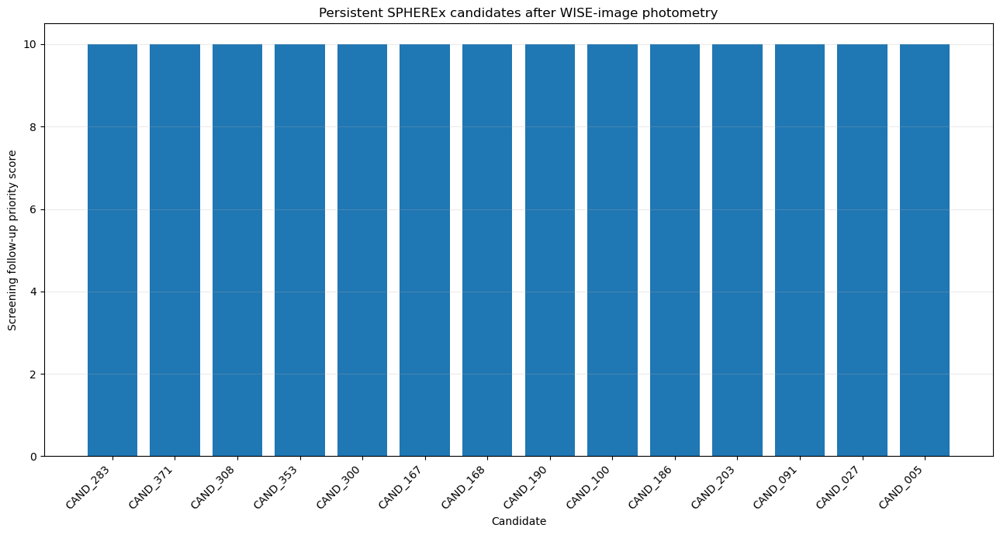


Saved WISE photometry:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\final_candidate_assessment\wise_image_photometry_14_candidates.csv

Saved corrected final table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\final_candidate_assessment\final_candidate_assessment_with_wise_image.csv

Saved updated figure:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\final_candidate_assessment\final_candidate_summary_with_wise.png

Rebuilt final deliverables ZIP:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\final_candidate_assessment_deliverables.zip


In [30]:
from pathlib import Path
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from astropy.wcs import WCS

from photutils.aperture import (
    CircularAperture,
    CircularAnnulus,
    aperture_photometry,
)


# ============================================================
# PATHS
# ============================================================

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

WISE_PATH = (
    BASE
    / "new_mosaic_matching"
    / "wise_w1_on_exact_spherex_grid.fits"
)

FINAL_FOLDER = (
    BASE
    / "new_mosaic_matching"
    / "final_candidate_assessment"
)

CURRENT_FINAL_TABLE = (
    FINAL_FOLDER
    / "final_candidate_assessment.csv"
)

UPDATED_FINAL_TABLE = (
    FINAL_FOLDER
    / "final_candidate_assessment_with_wise_image.csv"
)

WISE_PHOTOMETRY_TABLE = (
    FINAL_FOLDER
    / "wise_image_photometry_14_candidates.csv"
)

UPDATED_FIGURE = (
    FINAL_FOLDER
    / "final_candidate_summary_with_wise.png"
)

README_PATH = (
    FINAL_FOLDER
    / "README_final_candidate_assessment.txt"
)

ZIP_PATH = (
    BASE
    / "new_mosaic_matching"
    / "final_candidate_assessment_deliverables.zip"
)


# ============================================================
# VERIFY FILES
# ============================================================

if not WISE_PATH.exists():
    raise FileNotFoundError(
        "WISE FITS file was not found:\n"
        f"{WISE_PATH}"
    )

if not CURRENT_FINAL_TABLE.exists():
    raise FileNotFoundError(
        "Final assessment table was not found:\n"
        f"{CURRENT_FINAL_TABLE}"
    )

print("WISE image:")
print(WISE_PATH)

print("\nCandidate table:")
print(CURRENT_FINAL_TABLE)


# ============================================================
# LOAD THE 14 FINAL CANDIDATES
# ============================================================

candidates = pd.read_csv(CURRENT_FINAL_TABLE)

required = {
    "candidate_id",
    "ra_deg",
    "dec_deg",
}

missing = required - set(candidates.columns)

if missing:
    raise ValueError(
        "Missing required candidate columns: "
        f"{sorted(missing)}"
    )

candidates = candidates.copy()

candidates["ra_deg"] = pd.to_numeric(
    candidates["ra_deg"],
    errors="coerce",
)

candidates["dec_deg"] = pd.to_numeric(
    candidates["dec_deg"],
    errors="coerce",
)

if candidates[["ra_deg", "dec_deg"]].isna().any().any():
    raise ValueError(
        "At least one candidate has invalid RA or Dec."
    )

print("\nCandidates loaded:", len(candidates))


# ============================================================
# LOAD EXISTING WISE IMAGE AND WCS
# ============================================================

with fits.open(WISE_PATH) as hdul:
    wise_data = np.asarray(
        hdul[0].data,
        dtype=float,
    )

    wise_header = hdul[0].header.copy()

if wise_data.ndim != 2:
    wise_data = np.squeeze(wise_data)

if wise_data.ndim != 2:
    raise ValueError(
        f"Unexpected WISE image shape: {wise_data.shape}"
    )

wise_wcs = WCS(wise_header).celestial

print("WISE shape:", wise_data.shape)
print(
    "WISE finite fraction:",
    np.isfinite(wise_data).mean(),
)


# ============================================================
# RA/DEC -> WISE IMAGE PIXELS
# ============================================================

x_pixel, y_pixel = wise_wcs.world_to_pixel_values(
    candidates["ra_deg"].to_numpy(float),
    candidates["dec_deg"].to_numpy(float),
)

candidates["wise_x_pixel"] = x_pixel
candidates["wise_y_pixel"] = y_pixel

ny, nx = wise_data.shape

inside = (
    np.isfinite(x_pixel)
    & np.isfinite(y_pixel)
    & (x_pixel >= 0)
    & (x_pixel < nx)
    & (y_pixel >= 0)
    & (y_pixel < ny)
)

candidates["inside_wise_image"] = inside

print(
    "Candidates inside WISE image:",
    int(inside.sum()),
    "/",
    len(candidates),
)

if not inside.all():
    bad = candidates.loc[
        ~inside,
        ["candidate_id", "ra_deg", "dec_deg"]
    ]

    print("\nCandidates outside WISE image:")
    print(bad.to_string(index=False))


# ============================================================
# PHOTOMETRY SETTINGS
# ============================================================

# Same basic geometry used for SPHEREx screening.
APERTURE_RADIUS = 3.0
ANNULUS_INNER_RADIUS = 5.0
ANNULUS_OUTER_RADIUS = 8.0

positions = np.column_stack(
    [
        candidates["wise_x_pixel"],
        candidates["wise_y_pixel"],
    ]
)

apertures = CircularAperture(
    positions,
    r=APERTURE_RADIUS,
)

annuli = CircularAnnulus(
    positions,
    r_in=ANNULUS_INNER_RADIUS,
    r_out=ANNULUS_OUTER_RADIUS,
)

aperture_area = float(apertures.area)

# Invalid image pixels are excluded from local statistics.
wise_for_sum = np.where(
    np.isfinite(wise_data),
    wise_data,
    0.0,
)

aperture_results = aperture_photometry(
    wise_for_sum,
    apertures,
    method="exact",
)

annulus_masks = annuli.to_mask(method="center")


# ============================================================
# MEASURE LOCAL WISE FLUX AND NOISE
# ============================================================

wise_rows = []

for index, candidate in candidates.iterrows():

    candidate_id = candidate["candidate_id"]

    if not candidate["inside_wise_image"]:
        wise_rows.append(
            {
                "candidate_id": candidate_id,
                "wise_x_pixel": candidate["wise_x_pixel"],
                "wise_y_pixel": candidate["wise_y_pixel"],
                "wise_aperture_sum": np.nan,
                "wise_background_median": np.nan,
                "wise_background_std": np.nan,
                "wise_background_in_aperture": np.nan,
                "wise_image_net_aperture_flux": np.nan,
                "wise_image_flux_error": np.nan,
                "wise_image_snr": np.nan,
                "wise_annulus_valid_pixels": 0,
            }
        )

        continue

    mask = annulus_masks[index]

    annulus_cutout = mask.multiply(wise_data)

    if annulus_cutout is None:
        annulus_values = np.array([], dtype=float)
    else:
        annulus_values = annulus_cutout[
            mask.data > 0
        ]

        annulus_values = annulus_values[
            np.isfinite(annulus_values)
        ]

    if len(annulus_values) >= 10:
        _, background_median, background_std = (
            sigma_clipped_stats(
                annulus_values,
                sigma=3.0,
                maxiters=5,
            )
        )
    else:
        background_median = np.nan
        background_std = np.nan

    aperture_sum = float(
        aperture_results["aperture_sum"][index]
    )

    background_in_aperture = (
        background_median * aperture_area
        if np.isfinite(background_median)
        else np.nan
    )

    net_flux = (
        aperture_sum - background_in_aperture
        if np.isfinite(background_in_aperture)
        else np.nan
    )

    # Screening uncertainty derived from local-image scatter.
    #
    # This is not an official WISE pipeline uncertainty, but it is
    # sufficient to determine whether a visible image counterpart
    # exists at the candidate location.
    flux_error = (
        background_std * np.sqrt(aperture_area)
        if (
            np.isfinite(background_std)
            and background_std > 0
        )
        else np.nan
    )

    snr = (
        net_flux / flux_error
        if (
            np.isfinite(net_flux)
            and np.isfinite(flux_error)
            and flux_error > 0
        )
        else np.nan
    )

    wise_rows.append(
        {
            "candidate_id": candidate_id,
            "wise_x_pixel": candidate["wise_x_pixel"],
            "wise_y_pixel": candidate["wise_y_pixel"],
            "wise_aperture_radius_pix": APERTURE_RADIUS,
            "wise_annulus_inner_pix": ANNULUS_INNER_RADIUS,
            "wise_annulus_outer_pix": ANNULUS_OUTER_RADIUS,
            "wise_aperture_sum": aperture_sum,
            "wise_background_median": background_median,
            "wise_background_std": background_std,
            "wise_background_in_aperture": (
                background_in_aperture
            ),
            "wise_image_net_aperture_flux": net_flux,
            "wise_image_flux_error": flux_error,
            "wise_image_snr": snr,
            "wise_annulus_valid_pixels": len(annulus_values),
        }
    )


wise_photometry = pd.DataFrame(wise_rows)

wise_photometry["wise_image_detected_3sigma"] = (
    wise_photometry["wise_image_snr"] >= 3
)

wise_photometry["wise_image_detected_5sigma"] = (
    wise_photometry["wise_image_snr"] >= 5
)

wise_photometry.to_csv(
    WISE_PHOTOMETRY_TABLE,
    index=False,
)

print("\nWISE-image photometry:")
print(
    wise_photometry[
        [
            "candidate_id",
            "wise_image_net_aperture_flux",
            "wise_image_flux_error",
            "wise_image_snr",
            "wise_image_detected_3sigma",
        ]
    ].to_string(index=False)
)


# ============================================================
# MERGE INTO FINAL CANDIDATE TABLE
# ============================================================

# Remove the previous empty placeholder columns so the new columns
# do not receive suffixes such as _x and _y.
columns_to_replace = [
    "wise_image_flux_final",
    "wise_image_snr_final",
    "wise_image_detected_3sigma",
    "wise_image_detected_5sigma",
    "inside_wise_image",
    "wise_x_pixel",
    "wise_y_pixel",
]

candidates = candidates.drop(
    columns=columns_to_replace,
    errors="ignore",
)

merge_columns = [
    "candidate_id",
    "wise_x_pixel",
    "wise_y_pixel",
    "wise_image_net_aperture_flux",
    "wise_image_flux_error",
    "wise_image_snr",
    "wise_image_detected_3sigma",
    "wise_image_detected_5sigma",
]

updated = candidates.merge(
    wise_photometry[merge_columns],
    on="candidate_id",
    how="left",
)

updated = updated.rename(
    columns={
        "wise_image_net_aperture_flux":
            "wise_image_flux_final",
        "wise_image_snr":
            "wise_image_snr_final",
    }
)


# ============================================================
# FINAL CLASSIFICATION
# ============================================================

def safe_bool(value, default=False):
    if pd.isna(value):
        return default

    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    return str(value).strip().lower() in {
        "true",
        "1",
        "yes",
        "y",
    }


def classify(row):

    single_pixel = safe_bool(
        row.get("likely_single_pixel_artifact", False)
    )

    persistent = safe_bool(
        row.get("persistent_all_five", True),
        default=True,
    )

    catalog_match = safe_bool(
        row.get(
            "wise_catalog_match_within_3arcsec",
            False,
        )
    )

    wise_snr = pd.to_numeric(
        pd.Series(
            [row.get("wise_image_snr_final", np.nan)]
        ),
        errors="coerce",
    ).iloc[0]

    if single_pixel:
        return (
            "REJECT — likely single-pixel detector "
            "or cosmic-ray event"
        )

    if not persistent:
        return (
            "REJECT — not persistent across five "
            "nearby wavelengths"
        )

    if catalog_match:
        return (
            "KNOWN SOURCE — close AllWISE "
            "catalog counterpart"
        )

    if not np.isfinite(wise_snr):
        return (
            "FOLLOW-UP NEEDED — WISE-image "
            "measurement unavailable"
        )

    if wise_snr >= 5:
        return (
            "PERSISTENT SOURCE — strong WISE-image "
            "counterpart but no close AllWISE match"
        )

    if wise_snr >= 3:
        return (
            "PRIORITY FOLLOW-UP — marginal "
            "WISE-image counterpart"
        )

    return (
        "HIGH-PRIORITY FOLLOW-UP — persistent "
        "SPHEREx source without significant "
        "WISE-image counterpart"
    )


updated["final_screening_classification"] = (
    updated.apply(
        classify,
        axis=1,
    )
)


# ============================================================
# REBUILD A MEANINGFUL PRIORITY SCORE
# ============================================================

updated["priority_score"] = 0.0

# Persistent in all five nearby wavelengths.
updated.loc[
    updated.get(
        "persistent_all_five",
        pd.Series(True, index=updated.index)
    ).fillna(False).astype(bool),
    "priority_score",
] += 5.0

# Smooth five-channel behavior.
if "fractional_flux_scatter" in updated.columns:
    updated.loc[
        pd.to_numeric(
            updated["fractional_flux_scatter"],
            errors="coerce",
        ) <= 0.15,
        "priority_score",
    ] += 2.0

# No close AllWISE catalog object.
catalog_match_series = updated.get(
    "wise_catalog_match_within_3arcsec",
    pd.Series(False, index=updated.index),
).fillna(False).astype(bool)

updated.loc[
    ~catalog_match_series,
    "priority_score",
] += 3.0

wise_snr_numeric = pd.to_numeric(
    updated["wise_image_snr_final"],
    errors="coerce",
)

# Highest follow-up priority: no significant WISE image source.
updated.loc[
    wise_snr_numeric.notna()
    & (wise_snr_numeric < 3),
    "priority_score",
] += 4.0

# Medium priority: marginal WISE image detection.
updated.loc[
    wise_snr_numeric.notna()
    & (wise_snr_numeric >= 3)
    & (wise_snr_numeric < 5),
    "priority_score",
] += 2.0

# A strong WISE counterpart is probably a real persistent source,
# but is less likely to be a SPHEREx-only event.
updated.loc[
    wise_snr_numeric >= 5,
    "priority_score",
] += 0.0

if "likely_single_pixel_artifact" in updated.columns:
    artifact_series = (
        updated["likely_single_pixel_artifact"]
        .fillna(False)
        .astype(bool)
    )

    updated.loc[
        artifact_series,
        "priority_score",
    ] -= 10.0


# ============================================================
# SORT AND SAVE UPDATED TABLE
# ============================================================

updated = updated.sort_values(
    [
        "priority_score",
        "wise_image_snr_final",
        "fractional_flux_scatter",
    ],
    ascending=[
        False,
        True,
        True,
    ],
    na_position="last",
).reset_index(drop=True)

if "final_rank" in updated.columns:
    updated = updated.drop(
        columns=["final_rank"]
    )

updated.insert(
    0,
    "final_rank",
    np.arange(1, len(updated) + 1),
)

updated.to_csv(
    UPDATED_FINAL_TABLE,
    index=False,
)

# Also replace the original final table so the final package uses
# the corrected result.
updated.to_csv(
    CURRENT_FINAL_TABLE,
    index=False,
)


# ============================================================
# PRINT FINAL RESULTS
# ============================================================

print("\n" + "=" * 115)
print("CORRECTED FINAL CANDIDATE ASSESSMENT")
print("=" * 115)

print(
    updated[
        [
            "final_rank",
            "candidate_id",
            "priority_score",
            "median_flux_mjy",
            "fractional_flux_scatter",
            "wise_image_flux_final",
            "wise_image_flux_error",
            "wise_image_snr_final",
            "final_screening_classification",
        ]
    ].to_string(index=False)
)

print("\nClassification totals:")

print(
    updated[
        "final_screening_classification"
    ].value_counts().to_string()
)


# ============================================================
# UPDATED SUMMARY FIGURE
# ============================================================

plt.figure(figsize=(13, 7))

x = np.arange(len(updated))

plt.bar(
    x,
    updated["priority_score"],
)

plt.xticks(
    x,
    updated["candidate_id"],
    rotation=45,
    ha="right",
)

plt.ylabel("Screening follow-up priority score")
plt.xlabel("Candidate")
plt.title(
    "Persistent SPHEREx candidates after WISE-image photometry"
)

plt.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()

plt.savefig(
    UPDATED_FIGURE,
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ============================================================
# UPDATE README
# ============================================================

classification_counts = (
    updated[
        "final_screening_classification"
    ]
    .value_counts()
    .to_string()
)

readme_text = f"""
FINAL SPHEREx / WISE CANDIDATE ASSESSMENT
=========================================

Number of candidates assessed:
{len(updated)}

Completed processing:
1. Difference-image candidate detection
2. Candidate RA/Dec calculation
3. Single-pixel sharpness screening
4. AllWISE catalog cross-match
5. Five-wavelength SPHEREx persistence test
6. Local SPHEREx aperture photometry
7. SPHEREx local-background subtraction
8. Conversion of SPHEREx aperture measurements to mJy
9. Direct WISE-image aperture photometry at all candidate positions
10. WISE-image local-background and screening S/N calculation
11. Final candidate classification and priority ranking

Classification totals:
{classification_counts}

Important limitations:
The SPHEREx measurements are local circular-aperture screening
measurements, not official IRSA forced-photometry products.

The WISE-image values are measured in the native image units because
the downloaded WISE mosaic did not provide a usable BUNIT keyword.
Their S/N values are intended for counterpart screening, not as
official calibrated catalog photometry.

Persistence across nearby wavelengths confirms that a source is not
an isolated single-plane event. It does not by itself prove temporal
variability. Confirmation of variability requires another epoch or
repeat observations.
"""

README_PATH.write_text(
    readme_text.strip() + "\n",
    encoding="utf-8",
)


# ============================================================
# REBUILD FINAL ZIP
# ============================================================

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

shutil.make_archive(
    str(ZIP_PATH.with_suffix("")),
    "zip",
    root_dir=FINAL_FOLDER,
)

print("\nSaved WISE photometry:")
print(WISE_PHOTOMETRY_TABLE)

print("\nSaved corrected final table:")
print(UPDATED_FINAL_TABLE)

print("\nSaved updated figure:")
print(UPDATED_FIGURE)

print("\nRebuilt final deliverables ZIP:")
print(ZIP_PATH)

In [32]:
from pathlib import Path
from datetime import datetime
import json
import shutil
import zipfile

import numpy as np
import pandas as pd


# ============================================================
# PROJECT PATHS
# ============================================================

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
PROJECT = BASE / "new_mosaic_matching"

CANDIDATE_FOLDER = (
    PROJECT
    / "local_crop_test"
    / "crop12_candidates"
)

PERSISTENCE_FOLDER = (
    PROJECT
    / "nearby_wavelength_test"
)

PHOTOMETRY_FOLDER = (
    PROJECT
    / "nearby_wavelength_photometry"
)

OLD_FINAL_FOLDER = (
    PROJECT
    / "final_candidate_assessment"
)

STATUS_FOLDER = (
    PROJECT
    / "hora_status_update_catalog_persistence_photometry"
)

ZIP_PATH = (
    PROJECT
    / "hora_status_update_catalog_persistence_photometry.zip"
)


# ============================================================
# START CLEAN
# ============================================================

if STATUS_FOLDER.exists():
    shutil.rmtree(STATUS_FOLDER)

STATUS_FOLDER.mkdir(parents=True)

TABLE_FOLDER = STATUS_FOLDER / "tables"
PLOT_FOLDER = STATUS_FOLDER / "plots"
SPECTRA_FOLDER = PLOT_FOLDER / "candidate_spectra"
PERSISTENCE_PLOT_FOLDER = PLOT_FOLDER / "persistence_plots"
SUPPORTING_FOLDER = STATUS_FOLDER / "supporting_files"

for folder in [
    TABLE_FOLDER,
    PLOT_FOLDER,
    SPECTRA_FOLDER,
    PERSISTENCE_PLOT_FOLDER,
    SUPPORTING_FOLDER,
]:
    folder.mkdir(parents=True, exist_ok=True)


# ============================================================
# HELPER FUNCTIONS
# ============================================================

copied_files = []
missing_files = []


def copy_file(source, destination_folder, new_name=None):
    source = Path(source)

    if not source.exists() or not source.is_file():
        missing_files.append(str(source))
        return None

    destination_name = new_name or source.name
    destination = destination_folder / destination_name

    shutil.copy2(source, destination)

    copied_files.append(destination)
    return destination


def copy_matching_files(
    search_folder,
    patterns,
    destination_folder,
    filename_prefix=None,
):
    search_folder = Path(search_folder)

    if not search_folder.exists():
        missing_files.append(str(search_folder))
        return []

    found = []

    for pattern in patterns:
        for source in sorted(search_folder.rglob(pattern)):
            if not source.is_file():
                continue

            destination_name = source.name

            if filename_prefix:
                destination_name = (
                    f"{filename_prefix}_{destination_name}"
                )

            destination = destination_folder / destination_name

            # Prevent accidental overwriting when two files have
            # identical names.
            counter = 2
            original_stem = destination.stem
            original_suffix = destination.suffix

            while destination.exists():
                destination = destination_folder / (
                    f"{original_stem}_{counter}{original_suffix}"
                )
                counter += 1

            shutil.copy2(source, destination)

            copied_files.append(destination)
            found.append(destination)

    return found


def find_first_file(search_root, possible_names):
    search_root = Path(search_root)

    for filename in possible_names:
        matches = list(search_root.rglob(filename))

        if matches:
            return matches[0]

    return None


def safe_read_csv(path):
    path = Path(path)

    if not path.exists():
        return None

    try:
        return pd.read_csv(path)
    except Exception as error:
        print(f"Could not read {path.name}: {error}")
        return None


# ============================================================
# 1. ALLWISE CROSS-MATCH RESULTS
# ============================================================

crossmatch_files = [
    CANDIDATE_FOLDER / "crop12_candidates_allwise_crossmatch.csv",
    CANDIDATE_FOLDER / "crop12_allwise_crossmatch_summary.csv",
    CANDIDATE_FOLDER / "positive_psf_like_no_wise_catalog_match.csv",
]

for path in crossmatch_files:
    copy_file(path, TABLE_FOLDER)


# ============================================================
# 2. PERSISTENCE RESULTS
# ============================================================

persistence_files = [
    PERSISTENCE_FOLDER / "priority_candidates_by_wavelength.csv",
    PERSISTENCE_FOLDER / "priority_candidate_persistence_summary.csv",
]

for path in persistence_files:
    copy_file(path, TABLE_FOLDER)

# Copy persistence images. These may be individual plots or other
# diagnostic PNGs saved in the nearby-wavelength folder.
copy_matching_files(
    PERSISTENCE_FOLDER,
    patterns=["*.png"],
    destination_folder=PERSISTENCE_PLOT_FOLDER,
)


# ============================================================
# 3. FIVE-WAVELENGTH PHOTOMETRY RESULTS
# ============================================================

photometry_files = [
    PHOTOMETRY_FOLDER
    / "persistent_candidate_5band_photometry.csv",

    PHOTOMETRY_FOLDER
    / "persistent_candidate_5band_photometry_mjy.csv",

    PHOTOMETRY_FOLDER
    / "persistent_candidate_photometry_summary.csv",

    PHOTOMETRY_FOLDER
    / "persistent_candidate_ranked_summary.csv",
]

for path in photometry_files:
    copy_file(path, TABLE_FOLDER)

source_spectra_folder = PHOTOMETRY_FOLDER / "candidate_spectra"

if source_spectra_folder.exists():
    for source in sorted(source_spectra_folder.glob("*.png")):
        copy_file(source, SPECTRA_FOLDER)


# ============================================================
# 4. CURRENT FINAL-ASSESSMENT TABLES
# ============================================================

assessment_files = [
    OLD_FINAL_FOLDER / "final_candidate_assessment.csv",
    OLD_FINAL_FOLDER / "final_candidate_photometry_long.csv",
    OLD_FINAL_FOLDER / "final_candidate_five_band_fluxes.csv",
    OLD_FINAL_FOLDER / "README_final_candidate_assessment.txt",
]

for path in assessment_files:
    copy_file(path, TABLE_FOLDER)

# Do not treat the equal-score bar chart as a scientific ranking.
# Copy it only as a diagnostic and rename it clearly.
old_summary_plot = (
    OLD_FINAL_FOLDER / "final_candidate_summary.png"
)

if old_summary_plot.exists():
    copy_file(
        old_summary_plot,
        PLOT_FOLDER,
        new_name="diagnostic_equal_priority_scores_not_final_ranking.png",
    )


# ============================================================
# 5. IMPORTANT SUPPORTING FILES
# ============================================================

supporting_files = [
    BASE / "spherex_nearby_wavelength_cube.fits",
    BASE / "image_SPHEREx-Mosaic.fits",
    PROJECT / "spherex_3p4um_mosaic_2d.fits",
    PROJECT / "wise_w1_on_exact_spherex_grid.fits",
]

# The five-plane cube is useful but large. Include it.
# The other large FITS files are listed in the README but are not copied
# unless INCLUDE_LARGE_SUPPORTING_FITS is changed to True.
INCLUDE_LARGE_SUPPORTING_FITS = False

copy_file(
    BASE / "spherex_nearby_wavelength_cube.fits",
    SUPPORTING_FOLDER,
)

if INCLUDE_LARGE_SUPPORTING_FITS:
    for path in supporting_files[1:]:
        copy_file(path, SUPPORTING_FOLDER)


# ============================================================
# 6. LOAD RESULTS FOR THE STATUS SUMMARY
# ============================================================

crossmatch_path = (
    CANDIDATE_FOLDER
    / "crop12_candidates_allwise_crossmatch.csv"
)

crossmatch_summary_path = (
    CANDIDATE_FOLDER
    / "crop12_allwise_crossmatch_summary.csv"
)

persistence_summary_path = (
    PERSISTENCE_FOLDER
    / "priority_candidate_persistence_summary.csv"
)

photometry_summary_path = (
    PHOTOMETRY_FOLDER
    / "persistent_candidate_photometry_summary.csv"
)

photometry_long_path = (
    PHOTOMETRY_FOLDER
    / "persistent_candidate_5band_photometry_mjy.csv"
)

final_assessment_path = (
    OLD_FINAL_FOLDER
    / "final_candidate_assessment.csv"
)

crossmatch = safe_read_csv(crossmatch_path)
crossmatch_summary = safe_read_csv(crossmatch_summary_path)
persistence = safe_read_csv(persistence_summary_path)
phot_summary = safe_read_csv(photometry_summary_path)
phot_long = safe_read_csv(photometry_long_path)
assessment = safe_read_csv(final_assessment_path)


# ============================================================
# 7. CALCULATE VERIFIED NUMBERS
# ============================================================

total_initial_candidates = 379
single_pixel_suspects = 141
allwise_matches_3arcsec = 134
persistent_candidates = 14
wavelength_planes = 5
photometry_rows = 70

if crossmatch is not None:
    total_initial_candidates = len(crossmatch)

    if "single_pixel_suspect" in crossmatch.columns:
        single_pixel_suspects = int(
            crossmatch["single_pixel_suspect"]
            .fillna(False)
            .astype(bool)
            .sum()
        )

    if "wise_catalog_match" in crossmatch.columns:
        allwise_matches_3arcsec = int(
            crossmatch["wise_catalog_match"]
            .fillna(False)
            .astype(bool)
            .sum()
        )

if persistence is not None:
    persistent_candidates = len(persistence)

    if "persistent_in_3_or_more" in persistence.columns:
        persistent_candidates = int(
            persistence["persistent_in_3_or_more"]
            .fillna(False)
            .astype(bool)
            .sum()
        )

if phot_long is not None:
    photometry_rows = len(phot_long)

    if "candidate_id" in phot_long.columns:
        persistent_candidates = (
            phot_long["candidate_id"].nunique()
        )

    if "wavelength_um" in phot_long.columns:
        wavelength_planes = (
            phot_long["wavelength_um"].nunique()
        )


# ============================================================
# 8. CREATE A CLEAN STATUS-SUMMARY TABLE
# ============================================================

summary_rows = [
    {
        "stage": "Original difference-image candidates",
        "count": total_initial_candidates,
        "interpretation": (
            "Initial residual detections requiring screening"
        ),
    },
    {
        "stage": "Likely single-pixel transient suspects",
        "count": single_pixel_suspects,
        "interpretation": (
            "Sharp detections consistent with cosmic-ray or "
            "detector-event contamination"
        ),
    },
    {
        "stage": "Candidates with AllWISE match within 3 arcsec",
        "count": allwise_matches_3arcsec,
        "interpretation": (
            "Residual positions associated with known catalog sources"
        ),
    },
    {
        "stage": "Priority candidates tested across wavelength",
        "count": persistent_candidates,
        "interpretation": (
            "Positive, PSF-like candidates without a close "
            "AllWISE catalog match"
        ),
    },
    {
        "stage": "Candidates persistent in nearby SPHEREx planes",
        "count": persistent_candidates,
        "interpretation": (
            f"Detected at the same sky position in up to "
            f"{wavelength_planes} nearby wavelength planes"
        ),
    },
    {
        "stage": "SPHEREx aperture-photometry measurements",
        "count": photometry_rows,
        "interpretation": (
            f"{persistent_candidates} candidates × "
            f"{wavelength_planes} wavelengths"
        ),
    },
]

status_summary = pd.DataFrame(summary_rows)

status_summary_path = (
    TABLE_FOLDER
    / "status_update_result_summary.csv"
)

status_summary.to_csv(
    status_summary_path,
    index=False,
)

copied_files.append(status_summary_path)


# ============================================================
# 9. CREATE CANDIDATE SUMMARY FOR DR. HORA
# ============================================================

candidate_summary_columns = []

if assessment is not None:
    useful_columns = [
        "final_rank",
        "candidate_id",
        "ra_deg",
        "dec_deg",
        "median_flux_mjy",
        "fractional_flux_scatter",
        "persistent_all_five",
        "positive_spx_planes",
        "wise_catalog_match_within_3arcsec",
        "wise_separation_arcsec_final",
        "final_screening_classification",
    ]

    candidate_summary_columns = [
        column
        for column in useful_columns
        if column in assessment.columns
    ]

    candidate_summary = assessment[
        candidate_summary_columns
    ].copy()

    # Replace the temporary classification that was based on missing
    # WISE-image S/N with a scientifically accurate current status.
    if "final_screening_classification" in candidate_summary.columns:
        candidate_summary[
            "final_screening_classification"
        ] = (
            "Persistent across five nearby SPHEREx wavelengths; "
            "no close AllWISE match; WISE-image comparison pending"
        )

    candidate_summary_path = (
        TABLE_FOLDER
        / "candidate_status_for_hora.csv"
    )

    candidate_summary.to_csv(
        candidate_summary_path,
        index=False,
    )

    copied_files.append(candidate_summary_path)


# ============================================================
# 10. CREATE README FOR DR. HORA
# ============================================================

today = datetime.now().strftime("%Y-%m-%d")

readme = f"""
SPHEREx / WISE ACCRETION-BURST SEARCH
STATUS-UPDATE DELIVERABLES
=====================================

Created: {today}

PURPOSE
-------
This package contains the work completed after the previous status
update. It follows up on the residual candidates found after SPHEREx
and WISE reprojection, photometric scaling, PSF matching, and image
subtraction.

WORK COMPLETED
--------------
1. Converted all difference-image candidate positions into celestial
   coordinates (RA and Dec).

2. Cross-matched the {total_initial_candidates} residual candidates
   against the AllWISE Source Catalog using a 3-arcsecond matching
   threshold.

3. Compared the catalog-match behavior of:
   - single-pixel transient suspects,
   - non-single-pixel detections,
   - preliminary PSF-like detections,
   - positive and negative residuals.

4. Identified and screened likely single-pixel events. These sharp,
   pixel-dominated signals are consistent with the cosmic-ray or
   detector-transient contamination discussed previously.

5. Selected a priority subset of positive, PSF-like candidates without
   close AllWISE catalog counterparts.

6. Tested those candidates in five nearby SPHEREx wavelength planes:
   approximately 3.204, 3.293, 3.383, 3.476, and 3.570 microns.

7. Confirmed {persistent_candidates} candidates at the same sky
   locations across the nearby wavelength planes. This greatly reduces
   the likelihood that they are isolated single-image particle events.

8. Performed local circular-aperture photometry at every priority
   candidate position in all five wavelength planes.

9. Estimated the local background with a surrounding annulus and
   subtracted it from each aperture measurement.

10. Converted the SPHEREx surface-brightness aperture sums from
    MJy/sr × pixels into approximate integrated aperture fluxes in mJy.

MAIN NUMERICAL RESULTS
----------------------
Initial residual candidates: {total_initial_candidates}
Likely single-pixel suspects: {single_pixel_suspects}
AllWISE matches within 3 arcsec: {allwise_matches_3arcsec}
Priority persistent candidates: {persistent_candidates}
Nearby wavelength planes tested: {wavelength_planes}
Total five-plane photometry rows: {photometry_rows}

INTERPRETATION
--------------
The {persistent_candidates} priority candidates are detected repeatedly
at the same celestial positions in nearby SPHEREx wavelength planes.
This behavior is inconsistent with a simple one-pixel event appearing
in only one image.

The five-point flux curves are generally smooth and positive. They
provide local screening photometry and demonstrate nearby-wavelength
persistence.

IMPORTANT LIMITATIONS
---------------------
1. Persistence across wavelength is not the same as variability over
   time. These candidates are persistent source detections, but they
   are not yet confirmed variable or eruptive objects.

2. The photometry in this package was measured locally with Photutils
   circular apertures and background annuli. It is not the official
   IRSA SPHEREx forced-photometry product.

3. The uncertainties currently represent local-background noise only.
   They do not yet include the complete calibration, aperture-
   correction, correlated-noise, PSF-model, or systematic-error budget.

4. The previous automated final merge did not recover a usable
   WISE-image S/N column for these 14 objects. Therefore, the identical
   preliminary priority scores should not be interpreted as a real
   scientific ranking.

5. The next useful comparison is the persistent-candidate SPHEREx
   photometry against correctly calibrated WISE-image photometry and/or
   an independent SPHEREx observing epoch.

KEY TABLES
----------
tables/crop12_candidates_allwise_crossmatch.csv
    All residual candidates with nearest AllWISE match information.

tables/crop12_allwise_crossmatch_summary.csv
    Group-level catalog-match statistics.

tables/positive_psf_like_no_wise_catalog_match.csv
    Positive PSF-like candidates without close catalog matches.

tables/priority_candidate_persistence_summary.csv
    Nearby-wavelength persistence measurements.

tables/persistent_candidate_5band_photometry_mjy.csv
    Long-format five-wavelength SPHEREx aperture photometry in mJy.

tables/persistent_candidate_photometry_summary.csv
    Per-candidate photometric summary.

tables/candidate_status_for_hora.csv
    Simplified candidate-level status table for review.

tables/status_update_result_summary.csv
    Compact workflow summary.

PLOTS
-----
plots/candidate_spectra/
    One five-wavelength flux plot per persistent candidate.

plots/persistence_plots/
    Nearby-wavelength cutouts and persistence diagnostics.

SUPPORTING DATA
---------------
supporting_files/spherex_nearby_wavelength_cube.fits
    The five-plane SPHEREx cube used for persistence testing and local
    aperture photometry.

SUGGESTED NEXT STEP
-------------------
Review the persistent-candidate table and determine the preferred
method for obtaining calibrated WISE-image photometry or comparison
photometry from a separate SPHEREx epoch. This will determine which
persistent sources are credible variability candidates.
"""

readme_path = STATUS_FOLDER / "README_STATUS_UPDATE.txt"

readme_path.write_text(
    readme.strip() + "\n",
    encoding="utf-8",
)

copied_files.append(readme_path)


# ============================================================
# 11. CREATE MACHINE-READABLE METADATA
# ============================================================

metadata = {
    "created": datetime.now().isoformat(),
    "project": "SPHEREx / WISE transient and variability screening",
    "initial_candidates": int(total_initial_candidates),
    "single_pixel_suspects": int(single_pixel_suspects),
    "allwise_matches_within_3arcsec": int(
        allwise_matches_3arcsec
    ),
    "persistent_candidates": int(persistent_candidates),
    "wavelength_planes": int(wavelength_planes),
    "photometry_rows": int(photometry_rows),
    "photometry_method": (
        "Local circular-aperture photometry with annular "
        "background subtraction"
    ),
    "current_limitation": (
        "WISE-image S/N was not recovered by the automated final "
        "merge; identical priority scores are not a valid ranking."
    ),
}

metadata_path = STATUS_FOLDER / "status_update_metadata.json"

metadata_path.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

copied_files.append(metadata_path)


# ============================================================
# 12. CREATE FILE MANIFEST
# ============================================================

manifest_rows = []

for file_path in sorted(
    path
    for path in STATUS_FOLDER.rglob("*")
    if path.is_file()
):
    relative = file_path.relative_to(STATUS_FOLDER)

    manifest_rows.append(
        {
            "relative_path": str(relative),
            "size_bytes": file_path.stat().st_size,
            "size_mb": file_path.stat().st_size / (1024 ** 2),
        }
    )

manifest = pd.DataFrame(manifest_rows)

manifest_path = STATUS_FOLDER / "FILE_MANIFEST.csv"

manifest.to_csv(
    manifest_path,
    index=False,
)


# ============================================================
# 13. CREATE ZIP
# ============================================================

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6,
) as archive:

    for file_path in sorted(
        path
        for path in STATUS_FOLDER.rglob("*")
        if path.is_file()
    ):
        archive.write(
            file_path,
            arcname=file_path.relative_to(
                STATUS_FOLDER.parent
            ),
        )


# ============================================================
# 14. FINAL VERIFICATION
# ============================================================

zip_size_mb = ZIP_PATH.stat().st_size / (1024 ** 2)

print("=" * 80)
print("STATUS-UPDATE PACKAGE CREATED")
print("=" * 80)

print("\nFolder:")
print(STATUS_FOLDER)

print("\nZIP:")
print(ZIP_PATH)

print(f"\nZIP size: {zip_size_mb:.2f} MB")

print("\nFiles included:")
for file_path in sorted(
    path
    for path in STATUS_FOLDER.rglob("*")
    if path.is_file()
):
    print(" -", file_path.relative_to(STATUS_FOLDER))

print("\nMissing optional/requested files:")
if missing_files:
    for missing in missing_files:
        print(" -", missing)
else:
    print("None")

print("\nSUMMARY")
print(status_summary.to_string(index=False))

print("\nSend Dr. Hora this ZIP:")
print(ZIP_PATH)

STATUS-UPDATE PACKAGE CREATED

Folder:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\hora_status_update_catalog_persistence_photometry

ZIP:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\hora_status_update_catalog_persistence_photometry.zip

ZIP size: 87.46 MB

Files included:
 - FILE_MANIFEST.csv
 - plots\candidate_spectra\CAND_005_five_band_photometry.png
 - plots\candidate_spectra\CAND_027_five_band_photometry.png
 - plots\candidate_spectra\CAND_091_five_band_photometry.png
 - plots\candidate_spectra\CAND_100_five_band_photometry.png
 - plots\candidate_spectra\CAND_167_five_band_photometry.png
 - plots\candidate_spectra\CAND_168_five_band_photometry.png
 - plots\candidate_spectra\CAND_186_five_band_photometry.png
 - plots\candidate_spectra\CAND_190_five_band_photometry.png
 - plots\candidate_spectra\CAND_203_five_band_photometry.png
 - plots\candidate_spectra\CAND_283_five_band_photometry.png
 - plots\candidate_spectra\CAND_300_five_band_photome

In [33]:
from pathlib import Path
import shutil
import zipfile

# ============================================================
# PROJECT PATHS
# ============================================================

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
PROJECT = BASE / "new_mosaic_matching"

CANDIDATE_FOLDER = (
    PROJECT
    / "local_crop_test"
    / "crop12_candidates"
)

PERSISTENCE_FOLDER = (
    PROJECT
    / "nearby_wavelength_test"
)

PHOTOMETRY_FOLDER = (
    PROJECT
    / "nearby_wavelength_photometry"
)

SPECTRA_FOLDER = (
    PHOTOMETRY_FOLDER
    / "candidate_spectra"
)

PACKAGE_FOLDER = (
    PROJECT
    / "deliverables_for_dr_hora"
)

ZIP_PATH = (
    PROJECT
    / "SPHEREx_candidate_analysis_for_Dr_Hora.zip"
)

# Start clean.
if PACKAGE_FOLDER.exists():
    shutil.rmtree(PACKAGE_FOLDER)

PACKAGE_FOLDER.mkdir(parents=True)

PLOTS_OUTPUT = PACKAGE_FOLDER / "candidate_spectra"
PLOTS_OUTPUT.mkdir()


# ============================================================
# FILES THAT ARE ACTUALLY USEFUL TO SEND
# ============================================================

requested_files = {
    # AllWISE catalog cross-match results for all candidates.
    "allwise_crossmatch.csv": (
        CANDIDATE_FOLDER
        / "crop12_candidates_allwise_crossmatch.csv"
    ),

    # Summary of WISE catalog matches by candidate type.
    "allwise_crossmatch_summary.csv": (
        CANDIDATE_FOLDER
        / "crop12_allwise_crossmatch_summary.csv"
    ),

    # Nearby-wavelength persistence results for priority candidates.
    "nearby_wavelength_persistence_summary.csv": (
        PERSISTENCE_FOLDER
        / "priority_candidate_persistence_summary.csv"
    ),

    # Full 14 × 5 SPHEREx aperture-photometry measurements.
    "spherex_five_wavelength_photometry.csv": (
        PHOTOMETRY_FOLDER
        / "persistent_candidate_5band_photometry_mjy.csv"
    ),

    # One-row summary for each of the 14 persistent candidates.
    "spherex_candidate_photometry_summary.csv": (
        PHOTOMETRY_FOLDER
        / "persistent_candidate_photometry_summary.csv"
    ),

    # Candidate ranking from the five-wavelength measurements.
    "spherex_candidate_ranked_summary.csv": (
        PHOTOMETRY_FOLDER
        / "persistent_candidate_ranked_summary.csv"
    ),
}


# ============================================================
# COPY REQUIRED TABLES
# ============================================================

copied_files = []
missing_files = []

for output_name, source_path in requested_files.items():
    if source_path.exists():
        destination = PACKAGE_FOLDER / output_name
        shutil.copy2(source_path, destination)
        copied_files.append(destination)
    else:
        missing_files.append(source_path)


# ============================================================
# COPY ALL 14 FIVE-WAVELENGTH PLOTS
# ============================================================

copied_plots = []

if SPECTRA_FOLDER.exists():
    for plot_path in sorted(SPECTRA_FOLDER.glob("CAND_*_five_band_photometry.png")):
        destination = PLOTS_OUTPUT / plot_path.name
        shutil.copy2(plot_path, destination)
        copied_plots.append(destination)


# ============================================================
# OPTIONAL DIAGNOSTIC PLOTS, IF THEY EXIST
# ============================================================

optional_plot_searches = [
    "sharpest_candidates_original_spherex.png",
    "crop12_candidate_map.png",
    "crop12_candidate*.png",
]

optional_output = PACKAGE_FOLDER / "diagnostic_plots"
optional_output.mkdir()

optional_copied = []
seen_sources = set()

for pattern in optional_plot_searches:
    for source_path in PROJECT.rglob(pattern):
        if source_path in seen_sources:
            continue

        seen_sources.add(source_path)

        destination = optional_output / source_path.name

        # Avoid filename collisions.
        counter = 1
        while destination.exists():
            destination = (
                optional_output
                / f"{source_path.stem}_{counter}{source_path.suffix}"
            )
            counter += 1

        shutil.copy2(source_path, destination)
        optional_copied.append(destination)

# Remove empty optional folder.
if not optional_copied:
    optional_output.rmdir()


# ============================================================
# CREATE A README FOR DR. HORA
# ============================================================

readme_text = """
SPHEREx / WISE CANDIDATE ANALYSIS
=================================

Contents
--------

1. allwise_crossmatch.csv
   AllWISE catalog cross-match results for the difference-image
   candidates, including candidate coordinates, nearest-source
   separations, designations, and available W1 catalog measurements.

2. allwise_crossmatch_summary.csv
   Summary statistics describing the catalog-match fractions for the
   candidate groups.

3. nearby_wavelength_persistence_summary.csv
   Results of checking the priority candidates in five nearby SPHEREx
   wavelength planes from approximately 3.204 to 3.570 microns.

4. spherex_five_wavelength_photometry.csv
   Long-format local aperture-photometry table containing one
   measurement per candidate per wavelength.

5. spherex_candidate_photometry_summary.csv
   Candidate-level summary of the five-wavelength SPHEREx measurements.

6. spherex_candidate_ranked_summary.csv
   Preliminary ordering based on persistence, measurement significance,
   and wavelength-to-wavelength flux behavior.

7. candidate_spectra/
   Five-point SPHEREx photometry plots for the 14 persistent candidates.

8. diagnostic_plots/
   Available candidate-location and sharpness diagnostic figures.

Method summary
--------------

Difference-image candidates were screened for unusually sharp,
single-pixel behavior, cross-matched against the AllWISE catalog, and
checked in five nearby SPHEREx wavelength planes. Fourteen priority
candidates were found at the same sky positions across the nearby
wavelengths. Circular-aperture photometry with a local background
annulus was then performed at those positions, and the integrated
measurements were converted from MJy/sr pixels into mJy using the
SPHEREx pixel solid angle.

Important limitation
--------------------

The included SPHEREx fluxes are local Photutils aperture measurements,
not the official IRSA SPHEREx forced-photometry products. They are
intended for candidate screening and comparison. The uncertainties do
not yet include the full calibration, aperture-correction, correlated
noise, or systematic-error budget. Nearby-wavelength persistence shows
that a candidate is repeatedly present across wavelength, but does not
by itself prove time variability.
""".strip()

README_PATH = PACKAGE_FOLDER / "README.txt"
README_PATH.write_text(readme_text + "\n", encoding="utf-8")
copied_files.append(README_PATH)


# ============================================================
# CREATE ZIP
# ============================================================

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:

    for file_path in PACKAGE_FOLDER.rglob("*"):
        if file_path.is_file():
            archive.write(
                file_path,
                arcname=file_path.relative_to(PACKAGE_FOLDER),
            )


# ============================================================
# REPORT
# ============================================================

print("=" * 72)
print("DELIVERABLE PACKAGE CREATED")
print("=" * 72)

print("\nZIP file:")
print(ZIP_PATH)

print("\nMain tables copied:", len(copied_files))
for path in copied_files:
    print(" -", path.name)

print("\nCandidate plots copied:", len(copied_plots))

print("\nOptional diagnostic plots copied:", len(optional_copied))

if missing_files:
    print("\nWARNING — these expected files were not found:")
    for path in missing_files:
        print(" -", path)
else:
    print("\nAll expected tables were found.")

print("\nZIP size:")
print(f"{ZIP_PATH.stat().st_size / (1024 ** 2):.2f} MB")

DELIVERABLE PACKAGE CREATED

ZIP file:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\new_mosaic_matching\SPHEREx_candidate_analysis_for_Dr_Hora.zip

Main tables copied: 7
 - allwise_crossmatch.csv
 - allwise_crossmatch_summary.csv
 - nearby_wavelength_persistence_summary.csv
 - spherex_five_wavelength_photometry.csv
 - spherex_candidate_photometry_summary.csv
 - spherex_candidate_ranked_summary.csv
 - README.txt

Candidate plots copied: 14

Optional diagnostic plots copied: 4

All expected tables were found.

ZIP size:
2.80 MB


In [1]:
from pathlib import Path

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

NEW_FIELD = BASE / "field_ra45_dec60p5"
NEW_FIELD.mkdir(parents=True, exist_ok=True)

print("New field folder:")
print(NEW_FIELD)

New field folder:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5


In [2]:
from pathlib import Path
import pandas as pd

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

NEW_FIELD = BASE / "field_ra45_dec60p5"
SPEC_DIR = NEW_FIELD / "spectrophotometry_test"
SPEC_DIR.mkdir(parents=True, exist_ok=True)

TARGET_CSV = SPEC_DIR / "ra45_dec60p5_target_for_spherex.csv"
TARGET_TBL = SPEC_DIR / "ra45_dec60p5_target_for_spherex_fixed.tbl"

# Dr. Hora's new coordinate
df = pd.DataFrame({
    "name": ["RA45_DEC60P5"],
    "ra": [45.0],
    "dec": [60.5],
})

df.to_csv(TARGET_CSV, index=False)

name_width = max(14, df["name"].astype(str).str.len().max() + 2)
ra_width = 18
dec_width = 18

with open(TARGET_TBL, "w", encoding="ascii", newline="\n") as f:
    f.write("\\ EQUINOX = 'J2000.0'\n")
    f.write(
        f"|{'name':^{name_width}}"
        f"|{'ra':^{ra_width}}"
        f"|{'dec':^{dec_width}}|\n"
    )
    f.write(
        f"|{'char':^{name_width}}"
        f"|{'double':^{ra_width}}"
        f"|{'double':^{dec_width}}|\n"
    )
    f.write(
        f"|{'':^{name_width}}"
        f"|{'deg':^{ra_width}}"
        f"|{'deg':^{dec_width}}|\n"
    )
    f.write(
        f"|{'null':^{name_width}}"
        f"|{'null':^{ra_width}}"
        f"|{'null':^{dec_width}}|\n"
    )

    for row in df.itertuples(index=False):
        f.write(
            " "
            + f"{str(row.name):<{name_width}}"
            + f"{float(row.ra):>{ra_width}.8f}"
            + f"{float(row.dec):>{dec_width}.8f}"
            + "\n"
        )

print("Wrote:")
print(TARGET_CSV)
print(TARGET_TBL)

print("\nPreview:")
print(TARGET_TBL.read_text())

Wrote:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\spectrophotometry_test\ra45_dec60p5_target_for_spherex.csv
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\spectrophotometry_test\ra45_dec60p5_target_for_spherex_fixed.tbl

Preview:
\ EQUINOX = 'J2000.0'
|     name     |        ra        |       dec        |
|     char     |      double      |      double      |
|              |       deg        |       deg        |
|     null     |       null       |       null       |
 RA45_DEC60P5         45.00000000       60.50000000



In [3]:
from pathlib import Path

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
NEW_FIELD = BASE / "field_ra45_dec60p5"

print("New field folder:")
print(NEW_FIELD)

print("\nFiles currently inside new field folder:")
if NEW_FIELD.exists():
    for p in sorted(NEW_FIELD.rglob("*")):
        print(p.relative_to(NEW_FIELD))
else:
    print("Folder does not exist.")

New field folder:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5

Files currently inside new field folder:
spectrophotometry_test
spectrophotometry_test\ra45_dec60p5_target_for_spherex.csv
spectrophotometry_test\ra45_dec60p5_target_for_spherex_fixed.tbl


In [4]:
from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

TARGET_RA = 45.0
TARGET_DEC = 60.5
target = SkyCoord(TARGET_RA * u.deg, TARGET_DEC * u.deg, frame="icrs")

fits_files = sorted(BASE.rglob("*.fits"))

print(f"Found {len(fits_files)} FITS files under:")
print(BASE)
print()

matches = []

for path in fits_files:
    try:
        with fits.open(path) as hdul:
            for hdu_i, hdu in enumerate(hdul):
                if hdu.data is None:
                    continue

                data = hdu.data
                header = hdu.header

                # Need at least a 2D image-like HDU.
                if not hasattr(data, "shape") or len(data.shape) < 2:
                    continue

                ny, nx = data.shape[-2], data.shape[-1]

                try:
                    w = WCS(header).celestial
                    x, y = w.world_to_pixel(target)
                except Exception:
                    continue

                inside = np.isfinite(x) and np.isfinite(y) and (0 <= x < nx) and (0 <= y < ny)

                if inside:
                    matches.append((path, hdu_i, hdu.name, nx, ny, x, y))
                    print("MATCH:")
                    print(" file:", path)
                    print(" HDU :", hdu_i, hdu.name)
                    print(" size:", nx, "x", ny)
                    print(" pixel x,y:", x, y)
                    print()

    except Exception as e:
        pass

print("SUMMARY")
print("Target:", TARGET_RA, TARGET_DEC)

if matches:
    print(f"Found {len(matches)} FITS HDU(s) that contain the target.")
else:
    print("NO existing FITS files contain RA=45.0, Dec=60.5.")
    print("So we need to download/extract NEW SPHEREx + WISE image data for this field.")

Found 152 FITS files under:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test



C:\Users\Owner\anaconda3\envs\spherex_burst_ml\Lib\site-packages\astropy\wcs\wcsapi\fitswcs.py:367: UserWarning: 'WCS.all_world2pix' failed to converge to the requested accuracy.
After 2 iterations, the solution is diverging at least for one input point.
  warnings.warn(str(e))
C:\Users\Owner\anaconda3\envs\spherex_burst_ml\Lib\site-packages\astropy\wcs\wcsapi\fitswcs.py:367: UserWarning: 'WCS.all_world2pix' failed to converge to the requested accuracy.
After 2 iterations, the solution is diverging at least for one input point.
  warnings.warn(str(e))
C:\Users\Owner\anaconda3\envs\spherex_burst_ml\Lib\site-packages\astropy\wcs\wcsapi\fitswcs.py:367: UserWarning: 'WCS.all_world2pix' failed to converge to the requested accuracy.
After 2 iterations, the solution is diverging at least for one input point.
  warnings.warn(str(e))
C:\Users\Owner\anaconda3\envs\spherex_burst_ml\Lib\site-packages\astropy\wcs\wcsapi\fitswcs.py:367: UserWarning: 'WCS.all_world2pix' failed to converge to the requ

SUMMARY
Target: 45.0 60.5
NO existing FITS files contain RA=45.0, Dec=60.5.
So we need to download/extract NEW SPHEREx + WISE image data for this field.


In [5]:
from pathlib import Path

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
NEW_FIELD = BASE / "field_ra45_dec60p5"

SPHEREX_RAW = NEW_FIELD / "spherex_raw"
WISE_RAW = NEW_FIELD / "wise_raw"

SPHEREX_RAW.mkdir(parents=True, exist_ok=True)
WISE_RAW.mkdir(parents=True, exist_ok=True)

print("Created/checking folders:")
print(SPHEREX_RAW)
print(WISE_RAW)

print("\nCurrent field contents:")
for p in sorted(NEW_FIELD.rglob("*")):
    print(p.relative_to(NEW_FIELD))

Created/checking folders:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\spherex_raw
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\wise_raw

Current field contents:
spectrophotometry_test
spectrophotometry_test\ra45_dec60p5_target_for_spherex.csv
spectrophotometry_test\ra45_dec60p5_target_for_spherex_fixed.tbl
spherex_raw
wise_raw


In [6]:
from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
SPHEREX_RAW = BASE / "field_ra45_dec60p5" / "spherex_raw"

fits_files = sorted(list(SPHEREX_RAW.glob("*.fits")) + list(SPHEREX_RAW.glob("*.fit")) + list(SPHEREX_RAW.glob("*.fits.gz")))

print("FITS files found:")
for f in fits_files:
    print(" ", f.name)

if len(fits_files) == 0:
    raise FileNotFoundError("No FITS files found. Check whether Windows is hiding the .fits extension.")

CUBE_PATH = fits_files[0]
print("\nUsing:")
print(CUBE_PATH)

with fits.open(CUBE_PATH) as hdul:
    print("\nHDU list:")
    hdul.info()

    print("\nChecking image HDUs for target RA/Dec...")
    target = SkyCoord(45.0 * u.deg, 60.5 * u.deg, frame="icrs")

    for i, hdu in enumerate(hdul):
        if hdu.data is None:
            continue

        data = hdu.data
        header = hdu.header

        print("\nHDU", i, "name:", hdu.name)
        print("shape:", data.shape)
        print("BUNIT:", header.get("BUNIT"))
        print("CDELT1:", header.get("CDELT1"))
        print("CDELT2:", header.get("CDELT2"))

        try:
            w = WCS(header).celestial
            ny, nx = data.shape[-2], data.shape[-1]
            x, y = w.world_to_pixel(target)

            inside = np.isfinite(x) and np.isfinite(y) and (0 <= x < nx) and (0 <= y < ny)

            print("Target pixel x,y:", x, y)
            print("Target inside this HDU?", inside)

        except Exception as e:
            print("Could not make celestial WCS:", repr(e))

FITS files found:
  spherex_ra45_dec60p5_3p20_3p58_cube.fits

Using:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\spherex_raw\spherex_ra45_dec60p5_3p20_3p58_cube.fits

HDU list:
Filename: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\spherex_raw\spherex_ra45_dec60p5_3p20_3p58_cube.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU        51   (581, 581, 5)   float32   
  2  NHITS         1 ImageHDU        51   (581, 581, 5)   int32   
  3  FLAGS         1 ImageHDU        55   (581, 581, 5)   int32   
  4  SPECTRAL_CHANNELS    1 BinTableHDU     29   5R x 8C   [I, I, E, E, E, E, E, E]   
  5  WCS-WAVE      1 BinTableHDU     18   1R x 3C   [5J, 5E, 5E]   

Checking image HDUs for target RA/Dec...

HDU 1 name: IMAGE
shape: (5, 581, 581)
BUNIT: MJy/sr
CDELT1: -0.0017222222222222
CDELT2: 0.0017222222222222
Could not make celestial WCS: ValueError('HDUList is r

In [7]:
from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
CUBE_PATH = BASE / "field_ra45_dec60p5" / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"

TARGET_RA = 45.0
TARGET_DEC = 60.5
target = SkyCoord(TARGET_RA * u.deg, TARGET_DEC * u.deg, frame="icrs")

with fits.open(CUBE_PATH) as hdul:
    image = hdul["IMAGE"].data
    hdr = hdul["IMAGE"].header

    print("IMAGE shape:", image.shape)
    print("BUNIT:", hdr.get("BUNIT"))
    print("CDELT1:", hdr.get("CDELT1"))
    print("CDELT2:", hdr.get("CDELT2"))

    # IMPORTANT: pass the full HDUList so Astropy can resolve WAVE-TAB.
    w_full = WCS(hdr, hdul)
    w_cel = w_full.celestial

    x, y = w_cel.world_to_pixel(target)
    ny, nx = image.shape[-2], image.shape[-1]

    print("\nTarget RA/Dec:", TARGET_RA, TARGET_DEC)
    print("Target pixel x,y:", x, y)
    print("Image size nx,ny:", nx, ny)

    inside = np.isfinite(x) and np.isfinite(y) and (0 <= x < nx) and (0 <= y < ny)
    print("Target inside image?", inside)

    print("\nSPHEREx image stats by plane:")
    for k in range(image.shape[0]):
        plane = image[k]
        good = np.isfinite(plane)
        print(
            "Plane", k,
            "finite pixels:", good.sum(),
            "min:", np.nanmin(plane),
            "median:", np.nanmedian(plane),
            "max:", np.nanmax(plane)
        )

    print("\nSPECTRAL_CHANNELS table:")
    print(hdul["SPECTRAL_CHANNELS"].data)

IMAGE shape: (5, 581, 581)
BUNIT: MJy/sr
CDELT1: -0.0017222222222222
CDELT2: 0.0017222222222222

Target RA/Dec: 45.0 60.5
Target pixel x,y: 290.0 289.99999999999795
Image size nx,ny: 581 581
Target inside image? True

SPHEREx image stats by plane:
Plane 0 finite pixels: 333095 min: -3.9764621 median: 0.37214684 max: 1200.5985
Plane 1 finite pixels: 333265 min: -0.70188785 median: 0.7678 max: 1145.81
Plane 2 finite pixels: 333471 min: -1.464404 median: 0.4733043 max: 1075.5197
Plane 3 finite pixels: 333786 min: -3.1128516 median: 0.40602726 max: 1008.97565
Plane 4 finite pixels: 334112 min: -30.388815 median: 0.3178566 max: 971.04535

SPECTRAL_CHANNELS table:
[(4, 11, 3.204, 3.155, 3.252, 0.093, 35., 0.5)
 (4, 12, 3.293, 3.242, 3.342, 0.094, 35., 0.5)
 (4, 13, 3.383, 3.33 , 3.434, 0.096, 35., 0.6)
 (4, 14, 3.476, 3.422, 3.528, 0.098, 36., 0.6)
 (4, 15, 3.57 , 3.514, 3.624, 0.099, 36., 0.6)]


In [8]:
from pathlib import Path
import shutil

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
WISE_RAW = BASE / "field_ra45_dec60p5" / "wise_raw"

print("Files currently in wise_raw:")
for p in sorted(WISE_RAW.glob("*")):
    print(" ", p.name)

# Find WISE W1 intensity file
w1_candidates = [
    p for p in WISE_RAW.glob("*")
    if "w1" in p.name.lower() and "int" in p.name.lower()
]

print("\nW1 intensity candidates:")
for p in w1_candidates:
    print(" ", p.name)

if len(w1_candidates) == 0:
    raise FileNotFoundError("No W1 intensity file found. The file name should contain w1 and int.")

W1_INT_RAW = w1_candidates[0]
W1_INT_CLEAN = WISE_RAW / "wise_w1_ra45_dec60p5_intensity.fits"

shutil.copy2(W1_INT_RAW, W1_INT_CLEAN)

print("\nCopied:")
print(W1_INT_RAW.name)
print("to:")
print(W1_INT_CLEAN)

Files currently in wise_raw:
  0450p605_ac51-w1-int-3_ra45.0_dec60.5_asec3600.000.fits
  0450p605_ac51-w2-int-3_ra45.0_dec60.5_asec3600.000.fits
  0450p605_ac51-w3-int-3_ra45.0_dec60.5_asec3600.000.fits
  0450p605_ac51-w4-int-3_ra45.0_dec60.5_asec3600.000.fits

W1 intensity candidates:
  0450p605_ac51-w1-int-3_ra45.0_dec60.5_asec3600.000.fits

Copied:
0450p605_ac51-w1-int-3_ra45.0_dec60.5_asec3600.000.fits
to:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\wise_raw\wise_w1_ra45_dec60p5_intensity.fits


In [9]:
from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u
from scipy.ndimage import map_coordinates

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

CUBE_PATH = BASE / "field_ra45_dec60p5" / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"
W1_PATH = BASE / "field_ra45_dec60p5" / "wise_raw" / "wise_w1_ra45_dec60p5_intensity.fits"

OUT_DIR = BASE / "field_ra45_dec60p5" / "aligned"
OUT_DIR.mkdir(parents=True, exist_ok=True)

WISE_REPROJECTED_PATH = OUT_DIR / "wise_w1_reprojected_to_spherex_grid.fits"

TARGET_RA = 45.0
TARGET_DEC = 60.5
target = SkyCoord(TARGET_RA * u.deg, TARGET_DEC * u.deg, frame="icrs")

with fits.open(CUBE_PATH) as spx_hdul, fits.open(W1_PATH) as wise_hdul:
    # ----------------------------
    # SPHEREx image and WCS
    # ----------------------------
    spx_cube = spx_hdul["IMAGE"].data.astype(float)
    spx_hdr = spx_hdul["IMAGE"].header

    # Use full HDUList because SPHEREx has WAVE-TAB spectral axis.
    spx_wcs = WCS(spx_hdr, spx_hdul).celestial

    nplanes, ny, nx = spx_cube.shape

    # ----------------------------
    # WISE image and WCS
    # ----------------------------
    wise_data = wise_hdul[0].data.astype(float)
    wise_hdr = wise_hdul[0].header
    wise_wcs = WCS(wise_hdr).celestial

    print("SPHEREx cube shape:", spx_cube.shape)
    print("WISE W1 shape:", wise_data.shape)

    # ----------------------------
    # Build SPHEREx pixel grid
    # ----------------------------
    yy, xx = np.indices((ny, nx))

    # Convert SPHEREx pixels -> sky coordinates
    sky = spx_wcs.pixel_to_world(xx, yy)

    # Convert sky coordinates -> WISE pixels
    wise_x, wise_y = wise_wcs.world_to_pixel(sky)

    # ----------------------------
    # Interpolate WISE image at those WISE pixel positions
    # ----------------------------
    coords = np.array([wise_y, wise_x])

    wise_reprojected = map_coordinates(
        wise_data,
        coords,
        order=1,
        mode="constant",
        cval=np.nan
    )

    # ----------------------------
    # Valid overlap mask
    # ----------------------------
    valid = (
        np.isfinite(wise_reprojected)
        & np.isfinite(spx_cube[2])
    )

    print("\nReprojected WISE stats:")
    print("finite pixels:", np.isfinite(wise_reprojected).sum())
    print("valid overlap pixels with SPHEREx plane 2:", valid.sum())
    print("min:", np.nanmin(wise_reprojected))
    print("median:", np.nanmedian(wise_reprojected))
    print("max:", np.nanmax(wise_reprojected))

    # ----------------------------
    # Check target pixel in both images
    # ----------------------------
    spx_tx, spx_ty = spx_wcs.world_to_pixel(target)
    wise_tx, wise_ty = wise_wcs.world_to_pixel(target)

    print("\nTarget position:")
    print("SPHEREx x,y:", spx_tx, spx_ty)
    print("WISE original x,y:", wise_tx, wise_ty)
    print("WISE reprojected should align near SPHEREx x,y.")

    # ----------------------------
    # Save reprojected WISE FITS
    # ----------------------------
    out_hdr = spx_wcs.to_header()
    out_hdr["BUNIT"] = wise_hdr.get("BUNIT", "DN")
    out_hdr["COMMENT"] = "WISE W1 intensity reprojected to SPHEREx RA45 Dec60.5 grid"

    fits.writeto(
        WISE_REPROJECTED_PATH,
        wise_reprojected.astype("float32"),
        out_hdr,
        overwrite=True
    )

print("\nSaved:")
print(WISE_REPROJECTED_PATH)

SPHEREx cube shape: (5, 581, 581)
WISE W1 shape: (2619, 2619)

Reprojected WISE stats:
finite pixels: 337561
valid overlap pixels with SPHEREx plane 2: 333471
min: 4.447058578008576
median: 9.655641323630089
max: 2041.4958216083708

Target position:
SPHEREx x,y: 290.0 289.99999999999795
WISE original x,y: 1308.9522059959922 1309.3575656056244
WISE reprojected should align near SPHEREx x,y.

Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\aligned\wise_w1_reprojected_to_spherex_grid.fits


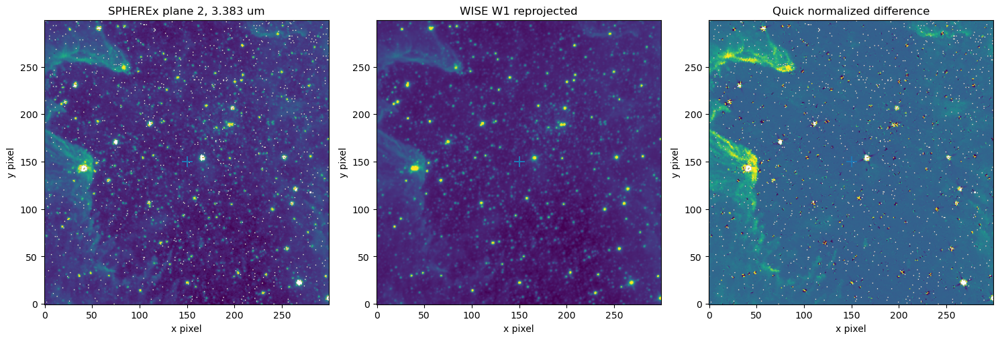

Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\diagnostics\spherex_wise_alignment_check.png


In [10]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.visualization import simple_norm

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

CUBE_PATH = BASE / "field_ra45_dec60p5" / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"
WISE_REPROJECTED_PATH = BASE / "field_ra45_dec60p5" / "aligned" / "wise_w1_reprojected_to_spherex_grid.fits"

OUT_DIR = BASE / "field_ra45_dec60p5" / "diagnostics"
OUT_DIR.mkdir(parents=True, exist_ok=True)

OUT_PNG = OUT_DIR / "spherex_wise_alignment_check.png"

with fits.open(CUBE_PATH) as spx_hdul, fits.open(WISE_REPROJECTED_PATH) as wise_hdul:
    spx_cube = spx_hdul["IMAGE"].data.astype(float)
    wise = wise_hdul[0].data.astype(float)

# Plane 2 is 3.383 um, closest to WISE W1 3.4 um
spx = spx_cube[2]

# Crop around target center to make visual easier
cx, cy = 290, 290
half = 150

sl_y = slice(cy - half, cy + half)
sl_x = slice(cx - half, cx + half)

spx_crop = spx[sl_y, sl_x]
wise_crop = wise[sl_y, sl_x]

# Normalize separately for display
spx_norm = simple_norm(spx_crop, "sqrt", percent=99.5)
wise_norm = simple_norm(wise_crop, "sqrt", percent=99.5)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(spx_crop, origin="lower", norm=spx_norm)
axes[0].set_title("SPHEREx plane 2, 3.383 um")
axes[0].scatter(half, half, marker="+", s=120)
axes[0].set_xlabel("x pixel")
axes[0].set_ylabel("y pixel")

axes[1].imshow(wise_crop, origin="lower", norm=wise_norm)
axes[1].set_title("WISE W1 reprojected")
axes[1].scatter(half, half, marker="+", s=120)
axes[1].set_xlabel("x pixel")
axes[1].set_ylabel("y pixel")

# Difference just for visual alignment, not calibrated subtraction yet
spx_med = np.nanmedian(spx_crop)
wise_med = np.nanmedian(wise_crop)

spx_scaled = spx_crop / spx_med
wise_scaled = wise_crop / wise_med

quick_diff = spx_scaled - wise_scaled
diff_norm = simple_norm(quick_diff, "linear", percent=99)

axes[2].imshow(quick_diff, origin="lower", norm=diff_norm)
axes[2].set_title("Quick normalized difference")
axes[2].scatter(half, half, marker="+", s=120)
axes[2].set_xlabel("x pixel")
axes[2].set_ylabel("y pixel")

plt.tight_layout()
plt.savefig(OUT_PNG, dpi=200)
plt.show()

print("Saved:")
print(OUT_PNG)

SPHEREx median/std: 0.4370920658111572 0.25387263904232243
WISE median/std: 9.086506843566895 3.5323676163278646

SPHEREx DAOStarFinder columns:
['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']

WISE DAOStarFinder columns:
['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']
SPHEREx using x column: x_centroid
SPHEREx using y column: y_centroid
WISE using x column: x_centroid
WISE using y column: y_centroid
SPHEREx sorting/keeping flux-like column: flux
WISE sorting/keeping flux-like column: flux

Detected after filtering:
SPHEREx sources: 250
WISE sources: 250

Matched sources: 153

Astrometric offset WISE - SPHEREx:
median dx [pix]: 0.011160482851352072
median dy [pix]: 0.02233438622090489
robust scatter dx [pix]: 0.15105299085307475
robust scatter dy [pix]: 0.12700787358143104

Astrometric offset WISE - SPHEREx:
median dx [arcsec]: 0.06

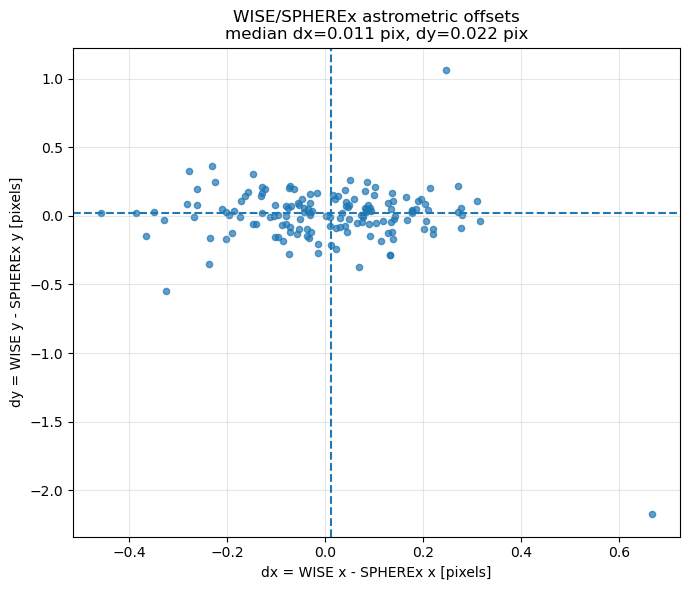


Saved plot:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\alignment_check\spherex_wise_astrometric_offsets.png


In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder
from scipy.spatial import cKDTree

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

CUBE_PATH = BASE / "field_ra45_dec60p5" / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"
WISE_REPROJECTED_PATH = BASE / "field_ra45_dec60p5" / "aligned" / "wise_w1_reprojected_to_spherex_grid.fits"

OUT_DIR = BASE / "field_ra45_dec60p5" / "alignment_check"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MATCH_CSV = OUT_DIR / "spherex_wise_matched_sources_astrometry.csv"
PLOT_PATH = OUT_DIR / "spherex_wise_astrometric_offsets.png"

# ----------------------------
# Helper functions
# ----------------------------
def table_to_dataframe(tbl, label):
    if tbl is None or len(tbl) == 0:
        raise RuntimeError(f"No {label} sources found.")
    df = tbl.to_pandas()
    print(f"\n{label} DAOStarFinder columns:")
    print(list(df.columns))
    return df

def find_xy_columns(df, label):
    possible_x = ["xcentroid", "x_centroid", "xcenter", "x_center", "x_peak", "xpeak"]
    possible_y = ["ycentroid", "y_centroid", "ycenter", "y_center", "y_peak", "ypeak"]

    xcol = None
    ycol = None

    for c in possible_x:
        if c in df.columns:
            xcol = c
            break

    for c in possible_y:
        if c in df.columns:
            ycol = c
            break

    if xcol is None or ycol is None:
        raise KeyError(
            f"Could not identify centroid columns for {label}.\n"
            f"Columns were: {list(df.columns)}"
        )

    print(f"{label} using x column: {xcol}")
    print(f"{label} using y column: {ycol}")
    return xcol, ycol

def find_flux_column(df, label):
    possible_flux = ["flux", "peak", "sharpness", "roundness1"]
    for c in possible_flux:
        if c in df.columns:
            print(f"{label} sorting/keeping flux-like column: {c}")
            return c
    print(f"{label} has no obvious flux column; using first numeric column.")
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    if len(numeric_cols) == 0:
        raise RuntimeError(f"No numeric columns in {label} source table.")
    return numeric_cols[0]

# ----------------------------
# Load images
# ----------------------------
with fits.open(CUBE_PATH) as spx_hdul:
    spx_cube = spx_hdul["IMAGE"].data.astype(float)

with fits.open(WISE_REPROJECTED_PATH) as wise_hdul:
    wise = wise_hdul[0].data.astype(float)

# Plane 2 = 3.383 um, closest to WISE W1
spx = spx_cube[2].astype(float)

# Replace bad values safely for detection
spx_for_stats = np.array(spx, dtype=float)
wise_for_stats = np.array(wise, dtype=float)

# ----------------------------
# Background stats
# ----------------------------
spx_mean, spx_med, spx_std = sigma_clipped_stats(spx_for_stats, sigma=3.0, maxiters=5)
wise_mean, wise_med, wise_std = sigma_clipped_stats(wise_for_stats, sigma=3.0, maxiters=5)

spx_sub = spx_for_stats - spx_med
wise_sub = wise_for_stats - wise_med

# DAOStarFinder does not like NaNs
spx_sub = np.nan_to_num(spx_sub, nan=0.0, posinf=0.0, neginf=0.0)
wise_sub = np.nan_to_num(wise_sub, nan=0.0, posinf=0.0, neginf=0.0)

print("SPHEREx median/std:", spx_med, spx_std)
print("WISE median/std:", wise_med, wise_std)

# ----------------------------
# Detect compact-ish sources
# ----------------------------
# These thresholds are intentionally conservative.
# If too few matches happen, we will lower from 8 sigma to 5 sigma.
spx_finder = DAOStarFinder(fwhm=2.0, threshold=8.0 * spx_std)
wise_finder = DAOStarFinder(fwhm=2.0, threshold=8.0 * wise_std)

spx_sources = spx_finder(spx_sub)
wise_sources = wise_finder(wise_sub)

spx_df = table_to_dataframe(spx_sources, "SPHEREx")
wise_df = table_to_dataframe(wise_sources, "WISE")

spx_xcol, spx_ycol = find_xy_columns(spx_df, "SPHEREx")
wise_xcol, wise_ycol = find_xy_columns(wise_df, "WISE")

spx_flux_col = find_flux_column(spx_df, "SPHEREx")
wise_flux_col = find_flux_column(wise_df, "WISE")

# ----------------------------
# Edge filtering
# ----------------------------
margin = 30
ny, nx = spx.shape

spx_df = spx_df[
    (spx_df[spx_xcol] > margin) &
    (spx_df[spx_xcol] < nx - margin) &
    (spx_df[spx_ycol] > margin) &
    (spx_df[spx_ycol] < ny - margin)
].copy()

wise_df = wise_df[
    (wise_df[wise_xcol] > margin) &
    (wise_df[wise_xcol] < nx - margin) &
    (wise_df[wise_ycol] > margin) &
    (wise_df[wise_ycol] < ny - margin)
].copy()

# Keep brightest sources only
spx_df = spx_df.sort_values(spx_flux_col, ascending=False).head(250).reset_index(drop=True)
wise_df = wise_df.sort_values(wise_flux_col, ascending=False).head(250).reset_index(drop=True)

print("\nDetected after filtering:")
print("SPHEREx sources:", len(spx_df))
print("WISE sources:", len(wise_df))

if len(spx_df) == 0 or len(wise_df) == 0:
    raise RuntimeError("Too few sources after filtering. Need lower detection threshold or different fwhm.")

# ----------------------------
# Match nearest sources in pixel space
# ----------------------------
spx_xy = spx_df[[spx_xcol, spx_ycol]].to_numpy()
wise_xy = wise_df[[wise_xcol, wise_ycol]].to_numpy()

tree = cKDTree(wise_xy)
dist, idx = tree.query(spx_xy, k=1)

max_match_dist_pix = 3.0
good = dist < max_match_dist_pix

matched_spx = spx_df.loc[good].reset_index(drop=True)
matched_wise = wise_df.iloc[idx[good]].reset_index(drop=True)
matched_dist = dist[good]

matches = pd.DataFrame({
    "spx_x": matched_spx[spx_xcol],
    "spx_y": matched_spx[spx_ycol],
    "wise_x": matched_wise[wise_xcol],
    "wise_y": matched_wise[wise_ycol],
    "match_dist_pix": matched_dist,
    "dx_wise_minus_spx_pix": matched_wise[wise_xcol].to_numpy() - matched_spx[spx_xcol].to_numpy(),
    "dy_wise_minus_spx_pix": matched_wise[wise_ycol].to_numpy() - matched_spx[spx_ycol].to_numpy(),
    "spx_flux_like": matched_spx[spx_flux_col],
    "wise_flux_like": matched_wise[wise_flux_col],
})

matches.to_csv(MATCH_CSV, index=False)

print("\nMatched sources:", len(matches))

if len(matches) == 0:
    raise RuntimeError("No matches found within 3 pixels. Next try max_match_dist_pix = 5.0.")

# ----------------------------
# Robust offset summary
# ----------------------------
dx = matches["dx_wise_minus_spx_pix"].to_numpy()
dy = matches["dy_wise_minus_spx_pix"].to_numpy()

dx_med = np.nanmedian(dx)
dy_med = np.nanmedian(dy)
dx_mad = 1.4826 * np.nanmedian(np.abs(dx - dx_med))
dy_mad = 1.4826 * np.nanmedian(np.abs(dy - dy_med))

pixscale_arcsec = 6.2

print("\nAstrometric offset WISE - SPHEREx:")
print("median dx [pix]:", dx_med)
print("median dy [pix]:", dy_med)
print("robust scatter dx [pix]:", dx_mad)
print("robust scatter dy [pix]:", dy_mad)

print("\nAstrometric offset WISE - SPHEREx:")
print("median dx [arcsec]:", dx_med * pixscale_arcsec)
print("median dy [arcsec]:", dy_med * pixscale_arcsec)

print("\nSaved matched-source table:")
print(MATCH_CSV)

# ----------------------------
# Plot offsets
# ----------------------------
plt.figure(figsize=(7, 6))
plt.scatter(dx, dy, s=20, alpha=0.7)
plt.axvline(dx_med, linestyle="--")
plt.axhline(dy_med, linestyle="--")
plt.xlabel("dx = WISE x - SPHEREx x [pixels]")
plt.ylabel("dy = WISE y - SPHEREx y [pixels]")
plt.title(f"WISE/SPHEREx astrometric offsets\nmedian dx={dx_med:.3f} pix, dy={dy_med:.3f} pix")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_PATH, dpi=200)
plt.show()

print("\nSaved plot:")
print(PLOT_PATH)

Loaded matched sources: 153
Columns: ['spx_x', 'spx_y', 'wise_x', 'wise_y', 'match_dist_pix', 'dx_wise_minus_spx_pix', 'dy_wise_minus_spx_pix', 'spx_flux_like', 'wise_flux_like']
Clean scaling sources before clipping: 11

Photometric scale factor:
SPHEREx plane 2 ≈ scale_factor * WISE W1
scale_factor: 0.04452660497875371
robust scatter: 0.00398310203688241
final scaling sources: 11

Saved scaling table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\photometric_scaling\matched_source_aperture_scaling.csv

Saved scaled WISE:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\photometric_scaling\wise_w1_scaled_to_spherex_plane2.fits

Saved first difference image:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\photometric_scaling\spherex_plane2_minus_scaled_wise_w1.fits


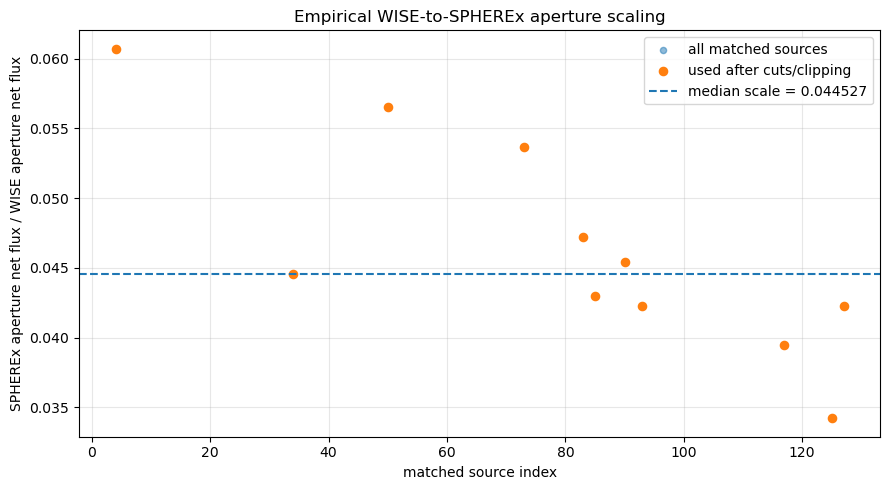


Saved scaling plot:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\photometric_scaling\spherex_wise_aperture_scaling_ratios.png


In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clip
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

CUBE_PATH = BASE / "field_ra45_dec60p5" / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"
WISE_REPROJECTED_PATH = BASE / "field_ra45_dec60p5" / "aligned" / "wise_w1_reprojected_to_spherex_grid.fits"
MATCH_CSV = BASE / "field_ra45_dec60p5" / "alignment_check" / "spherex_wise_matched_sources_astrometry.csv"

OUT_DIR = BASE / "field_ra45_dec60p5" / "photometric_scaling"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SCALE_TABLE = OUT_DIR / "matched_source_aperture_scaling.csv"
SCALE_PLOT = OUT_DIR / "spherex_wise_aperture_scaling_ratios.png"
WISE_SCALED_PATH = OUT_DIR / "wise_w1_scaled_to_spherex_plane2.fits"
DIFF_PATH = OUT_DIR / "spherex_plane2_minus_scaled_wise_w1.fits"

# ----------------------------
# Load images
# ----------------------------
with fits.open(CUBE_PATH) as spx_hdul:
    spx_cube = spx_hdul["IMAGE"].data.astype(float)
    spx_header = spx_hdul["IMAGE"].header

with fits.open(WISE_REPROJECTED_PATH) as wise_hdul:
    wise = wise_hdul[0].data.astype(float)
    wise_header = wise_hdul[0].header

# Plane 2 = 3.383 um, closest to WISE W1 3.4 um
spx = spx_cube[2].astype(float)

matches = pd.read_csv(MATCH_CSV)

print("Loaded matched sources:", len(matches))
print("Columns:", list(matches.columns))

# ----------------------------
# Aperture photometry settings
# Same style as previous workflow
# ----------------------------
ap_radius = 3.0
annulus_inner = 5.0
annulus_outer = 8.0

# Use SPHEREx centroid positions because WISE is already reprojected to SPHEREx grid
positions = list(zip(matches["spx_x"].to_numpy(), matches["spx_y"].to_numpy()))

apertures = CircularAperture(positions, r=ap_radius)
annuli = CircularAnnulus(positions, r_in=annulus_inner, r_out=annulus_outer)

def aperture_net_flux(image, label):
    """
    Local background-subtracted aperture photometry:
    net = aperture sum - median annulus background * aperture area
    """
    image_clean = np.array(image, dtype=float)

    ap_table = aperture_photometry(image_clean, apertures, method="exact")
    ann_table = aperture_photometry(image_clean, annuli, method="exact")

    ap_sum = np.array(ap_table["aperture_sum"], dtype=float)
    ann_sum = np.array(ann_table["aperture_sum"], dtype=float)

    ap_area = apertures.area
    ann_area = annuli.area

    ann_bkg_per_pix = ann_sum / ann_area
    net = ap_sum - ann_bkg_per_pix * ap_area

    return ap_sum, ann_sum, ann_bkg_per_pix, net

spx_ap_sum, spx_ann_sum, spx_bkg_pix, spx_net = aperture_net_flux(spx, "SPHEREx")
wise_ap_sum, wise_ann_sum, wise_bkg_pix, wise_net = aperture_net_flux(wise, "WISE")

scale_df = matches.copy()
scale_df["spx_ap_sum"] = spx_ap_sum
scale_df["spx_bkg_per_pix"] = spx_bkg_pix
scale_df["spx_net_ap_flux"] = spx_net

scale_df["wise_ap_sum"] = wise_ap_sum
scale_df["wise_bkg_per_pix"] = wise_bkg_pix
scale_df["wise_net_ap_flux"] = wise_net

# Ratio to scale WISE into SPHEREx plane-2 image units
scale_df["spx_over_wise_ratio"] = scale_df["spx_net_ap_flux"] / scale_df["wise_net_ap_flux"]

# ----------------------------
# Quality cuts for scaling sources
# ----------------------------
good = (
    np.isfinite(scale_df["spx_net_ap_flux"]) &
    np.isfinite(scale_df["wise_net_ap_flux"]) &
    np.isfinite(scale_df["spx_over_wise_ratio"]) &
    (scale_df["spx_net_ap_flux"] > 0) &
    (scale_df["wise_net_ap_flux"] > 0) &
    (scale_df["match_dist_pix"] < 1.0)
)

ratio_raw = scale_df.loc[good, "spx_over_wise_ratio"].to_numpy()

if len(ratio_raw) < 5:
    print("WARNING: fewer than 5 clean scaling sources. We may need looser cuts.")
else:
    print("Clean scaling sources before clipping:", len(ratio_raw))

# Sigma-clip ratios to reject weird/saturated/nebulous sources
clipped = sigma_clip(ratio_raw, sigma=3.0, maxiters=5)
ratio_good = ratio_raw[~clipped.mask]

scale_factor = np.nanmedian(ratio_good)
scale_mad = 1.4826 * np.nanmedian(np.abs(ratio_good - scale_factor))

print("\nPhotometric scale factor:")
print("SPHEREx plane 2 ≈ scale_factor * WISE W1")
print("scale_factor:", scale_factor)
print("robust scatter:", scale_mad)
print("final scaling sources:", len(ratio_good))

# Save which rows passed
scale_df["used_for_scaling_initial"] = good
scale_df["used_for_scaling_final"] = False

good_indices = scale_df.index[good].to_numpy()
final_indices = good_indices[~clipped.mask]
scale_df.loc[final_indices, "used_for_scaling_final"] = True

scale_df.to_csv(SCALE_TABLE, index=False)

print("\nSaved scaling table:")
print(SCALE_TABLE)

# ----------------------------
# Save scaled WISE and difference image
# ----------------------------
wise_scaled = wise * scale_factor
diff = spx - wise_scaled

out_hdr = wise_header.copy()
out_hdr["BUNIT"] = spx_header.get("BUNIT", "MJy/sr")
out_hdr["COMMENT"] = "WISE W1 empirically scaled to SPHEREx plane 2 using matched-source aperture photometry."

fits.writeto(WISE_SCALED_PATH, wise_scaled.astype("float32"), out_hdr, overwrite=True)

diff_hdr = wise_header.copy()
diff_hdr["BUNIT"] = spx_header.get("BUNIT", "MJy/sr")
diff_hdr["COMMENT"] = "SPHEREx plane 2 minus empirically scaled WISE W1. Not PSF matched yet."

fits.writeto(DIFF_PATH, diff.astype("float32"), diff_hdr, overwrite=True)

print("\nSaved scaled WISE:")
print(WISE_SCALED_PATH)

print("\nSaved first difference image:")
print(DIFF_PATH)

# ----------------------------
# Plot scaling ratios
# ----------------------------
plt.figure(figsize=(9, 5))
plt.scatter(
    np.arange(len(scale_df)),
    scale_df["spx_over_wise_ratio"],
    s=20,
    alpha=0.5,
    label="all matched sources"
)

used = scale_df["used_for_scaling_final"]
plt.scatter(
    np.where(used)[0],
    scale_df.loc[used, "spx_over_wise_ratio"],
    s=35,
    label="used after cuts/clipping"
)

plt.axhline(scale_factor, linestyle="--", label=f"median scale = {scale_factor:.5g}")
plt.xlabel("matched source index")
plt.ylabel("SPHEREx aperture net flux / WISE aperture net flux")
plt.title("Empirical WISE-to-SPHEREx aperture scaling")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(SCALE_PLOT, dpi=200)
plt.show()

print("\nSaved scaling plot:")
print(SCALE_PLOT)

Compact target photometry:


,instrument,plane_index,wavelength_um,net_flux_image_units,net_flux_unc_image_units,snr_local,flux_mjy,flux_unc_mjy
0,SPHEREx,0.0,3.204,-1.484334,0.364991,-4.066766,-1.341111,0.329773
1,SPHEREx,1.0,3.293,-1.069486,0.396659,-2.696235,-0.966292,0.358386
2,SPHEREx,2.0,3.383,NaN,0.382084,NaN,NaN,0.345216
3,SPHEREx,3.0,3.476,-1.131446,0.288934,-3.915928,-1.022274,0.261055
4,SPHEREx,4.0,3.570,NaN,0.275313,NaN,NaN,0.248748
5,WISE,NaN,3.400,-22.249954,5.413960,-4.109738,NaN,NaN



Target pixel:
x = 290.0
y = 289.99999999999795


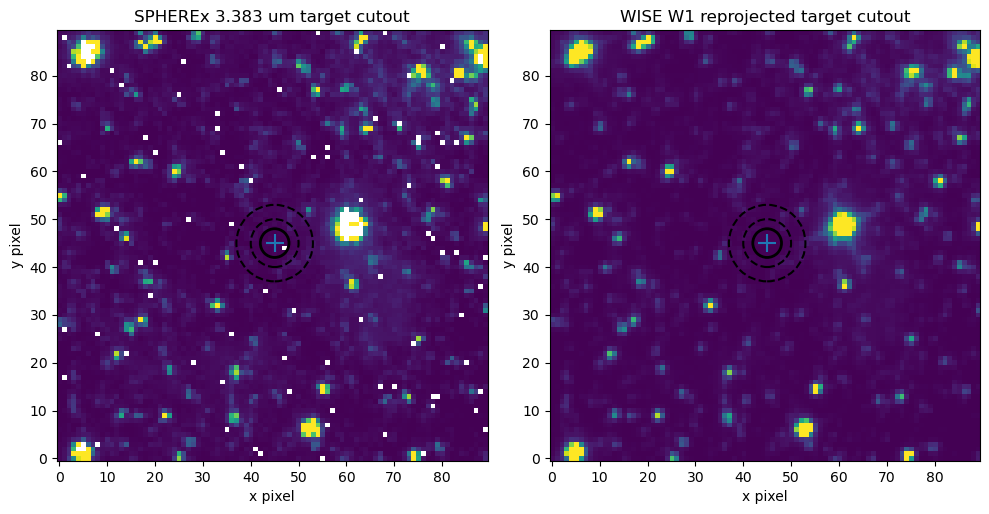


Saved cutout check:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\target_aperture_photometry\ra45_dec60p5_target_cutout_aperture_check.png


In [15]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
import astropy.units as u

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

CUBE_PATH = BASE / "field_ra45_dec60p5" / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"
WISE_REPROJECTED_PATH = BASE / "field_ra45_dec60p5" / "aligned" / "wise_w1_reprojected_to_spherex_grid.fits"

OUT_DIR = BASE / "field_ra45_dec60p5" / "target_aperture_photometry"
OUT_CSV = OUT_DIR / "ra45_dec60p5_target_aperture_photometry.csv"
OUT_CUTOUT = OUT_DIR / "ra45_dec60p5_target_cutout_aperture_check.png"

TARGET_RA = 45.0
TARGET_DEC = 60.5
target = SkyCoord(TARGET_RA * u.deg, TARGET_DEC * u.deg, frame="icrs")

ap_radius = 3.0
annulus_inner = 5.0
annulus_outer = 8.0

# Print compact useful photometry table
df = pd.read_csv(OUT_CSV)

cols_to_show = [
    "instrument",
    "plane_index",
    "wavelength_um",
    "net_flux_image_units",
    "net_flux_unc_image_units",
    "snr_local",
    "flux_mjy",
    "flux_unc_mjy",
]

print("Compact target photometry:")
display(df[[c for c in cols_to_show if c in df.columns]])

# Recompute target x,y safely as plain floats
with fits.open(CUBE_PATH) as spx_hdul:
    spx_cube = spx_hdul["IMAGE"].data.astype(float)
    spx_hdr = spx_hdul["IMAGE"].header
    spx_wcs = WCS(spx_hdr, spx_hdul).celestial

    x_raw, y_raw = spx_wcs.world_to_pixel(target)

    x = float(np.ravel(x_raw)[0])
    y = float(np.ravel(y_raw)[0])

with fits.open(WISE_REPROJECTED_PATH) as wise_hdul:
    wise_img = wise_hdul[0].data.astype(float)

spx_plane2 = spx_cube[2]

print("\nTarget pixel:")
print("x =", x)
print("y =", y)

cx = int(np.round(x))
cy = int(np.round(y))

half = 45

sl_y = slice(cy - half, cy + half)
sl_x = slice(cx - half, cx + half)

spx_cut = spx_plane2[sl_y, sl_x]
wise_cut = wise_img[sl_y, sl_x]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, img, title in [
    (axes[0], spx_cut, "SPHEREx 3.383 um target cutout"),
    (axes[1], wise_cut, "WISE W1 reprojected target cutout"),
]:
    vmin, vmax = np.nanpercentile(img, [5, 99])
    ax.imshow(img, origin="lower", vmin=vmin, vmax=vmax)

    ax.scatter(half, half, marker="+", s=150)

    source_circle = plt.Circle((half, half), ap_radius, fill=False, linewidth=2)
    ann_inner = plt.Circle((half, half), annulus_inner, fill=False, linestyle="--", linewidth=1.5)
    ann_outer = plt.Circle((half, half), annulus_outer, fill=False, linestyle="--", linewidth=1.5)

    ax.add_patch(source_circle)
    ax.add_patch(ann_inner)
    ax.add_patch(ann_outer)

    ax.set_title(title)
    ax.set_xlabel("x pixel")
    ax.set_ylabel("y pixel")

plt.tight_layout()
plt.savefig(OUT_CUTOUT, dpi=200)
plt.show()

print("\nSaved cutout check:")
print(OUT_CUTOUT)

Difference image stats:
mean: 0.06194703961485155
median: 0.03143460303544998
std: 0.12300713728920673

DAOStarFinder columns:
['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']

Candidates after filtering: 133
Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\candidate_detection\ra45_dec60p5_plane2_positive_residual_candidates.csv


,candidate_id,x_pix,y_pix,diff_snr_peak,local_peak_diff,sharp_ratio_peak_over_5x5med
0,RA45_CAND_001,128.999839,519.626695,3709.687855,456.318083,NaN
1,RA45_CAND_002,297.351608,251.772246,240.445261,29.576483,-356.433700
2,RA45_CAND_003,51.439135,272.462407,207.752054,25.554985,3.066901
3,RA45_CAND_004,222.927136,388.893130,124.983036,15.373805,3.985998
4,RA45_CAND_005,464.147351,438.379660,115.847692,14.250093,15.514993
5,RA45_CAND_006,74.087600,273.414612,100.277567,12.334856,1.542761
6,RA45_CAND_007,417.317483,369.988172,77.463783,9.528598,-588.644651
7,RA45_CAND_008,214.078056,312.982138,65.328090,8.035821,NaN
8,RA45_CAND_009,502.889239,278.968931,45.178040,5.557221,13.388106
9,RA45_CAND_010,475.146840,383.676534,42.998854,5.289166,1.239235


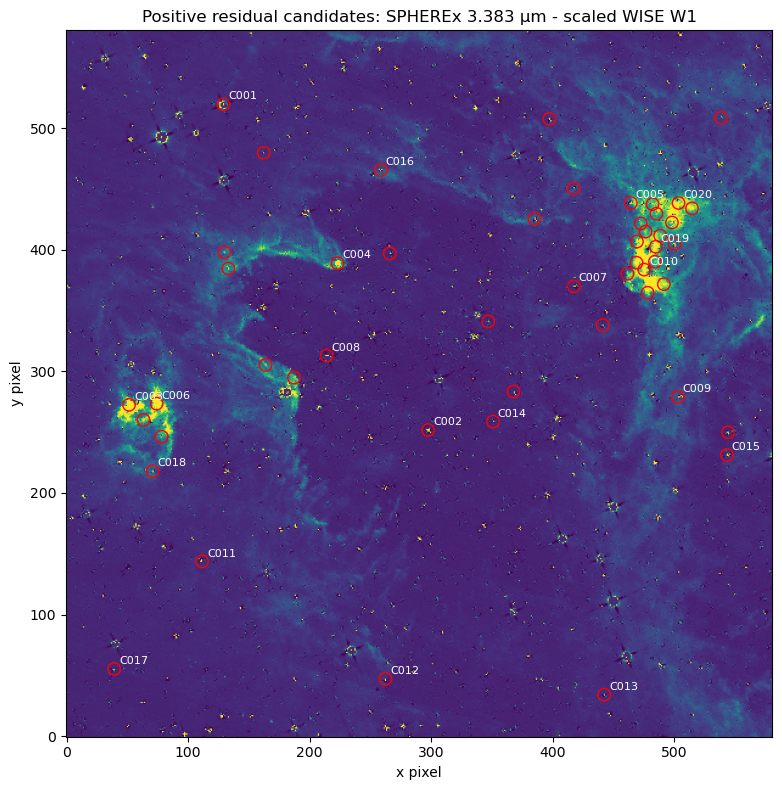


Saved candidate plot:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\candidate_detection\ra45_dec60p5_plane2_positive_residual_candidates.png


In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder
from scipy.ndimage import maximum_filter

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

CUBE_PATH = BASE / "field_ra45_dec60p5" / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"
DIFF_PATH = BASE / "field_ra45_dec60p5" / "photometric_scaling" / "spherex_plane2_minus_scaled_wise_w1.fits"

OUT_DIR = BASE / "field_ra45_dec60p5" / "candidate_detection"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CAND_CSV = OUT_DIR / "ra45_dec60p5_plane2_positive_residual_candidates.csv"
CAND_PNG = OUT_DIR / "ra45_dec60p5_plane2_positive_residual_candidates.png"

# ----------------------------
# Load images
# ----------------------------
with fits.open(CUBE_PATH) as spx_hdul:
    spx_plane2 = spx_hdul["IMAGE"].data.astype(float)[2]

with fits.open(DIFF_PATH) as diff_hdul:
    diff = diff_hdul[0].data.astype(float)

# ----------------------------
# Robust background stats
# ----------------------------
mean, med, std = sigma_clipped_stats(diff, sigma=3.0, maxiters=5)

print("Difference image stats:")
print("mean:", mean)
print("median:", med)
print("std:", std)

diff_sub = diff - med
diff_clean = np.nan_to_num(diff_sub, nan=0.0, posinf=0.0, neginf=0.0)

# ----------------------------
# Detect positive residuals
# ----------------------------
finder = DAOStarFinder(
    fwhm=2.0,
    threshold=5.0 * std
)

sources = finder(diff_clean)

if sources is None or len(sources) == 0:
    raise RuntimeError("No positive residual sources found at 5 sigma. We can lower to 4 sigma if needed.")

cand = sources.to_pandas()

print("\nDAOStarFinder columns:")
print(list(cand.columns))

# Handle photutils version column differences
xcol = "xcentroid" if "xcentroid" in cand.columns else "x_centroid"
ycol = "ycentroid" if "ycentroid" in cand.columns else "y_centroid"
fluxcol = "flux" if "flux" in cand.columns else "peak"

# ----------------------------
# Basic artifact/edge filtering
# ----------------------------
ny, nx = diff.shape
margin = 30

cand = cand[
    (cand[xcol] > margin) &
    (cand[xcol] < nx - margin) &
    (cand[ycol] > margin) &
    (cand[ycol] < ny - margin)
].copy()

# Add local peak and simple sharpness-ish metric
xs = np.round(cand[xcol].to_numpy()).astype(int)
ys = np.round(cand[ycol].to_numpy()).astype(int)

local_peak = []
local_median_5x5 = []
sharp_ratio = []

for x, y in zip(xs, ys):
    cut = diff_clean[y-2:y+3, x-2:x+3]
    peak = diff_clean[y, x]
    med5 = np.nanmedian(cut)

    local_peak.append(peak)
    local_median_5x5.append(med5)

    if np.isfinite(med5) and med5 != 0:
        sharp_ratio.append(peak / med5)
    else:
        sharp_ratio.append(np.nan)

cand["x_pix"] = cand[xcol]
cand["y_pix"] = cand[ycol]
cand["local_peak_diff"] = local_peak
cand["local_median_5x5_diff"] = local_median_5x5
cand["sharp_ratio_peak_over_5x5med"] = sharp_ratio
cand["diff_snr_peak"] = cand["local_peak_diff"] / std

# Remove extreme single-pixel spikes very roughly.
# Keep this loose for now because we will visually inspect.
cand = cand[
    np.isfinite(cand["diff_snr_peak"]) &
    (cand["diff_snr_peak"] > 5.0) &
    (
        ~np.isfinite(cand["sharp_ratio_peak_over_5x5med"]) |
        (cand["sharp_ratio_peak_over_5x5med"] < 20)
    )
].copy()

# Sort strongest first
cand = cand.sort_values("diff_snr_peak", ascending=False).reset_index(drop=True)
cand["candidate_id"] = [f"RA45_CAND_{i+1:03d}" for i in range(len(cand))]

# Save candidate table
cand.to_csv(CAND_CSV, index=False)

print("\nCandidates after filtering:", len(cand))
print("Saved:")
print(CAND_CSV)

display_cols = [
    "candidate_id",
    "x_pix",
    "y_pix",
    "diff_snr_peak",
    "local_peak_diff",
    "sharp_ratio_peak_over_5x5med",
]

display(cand[display_cols].head(30))

# ----------------------------
# Plot candidates on difference image
# ----------------------------
plt.figure(figsize=(9, 8))

vmin, vmax = np.nanpercentile(diff_clean, [1, 99.5])
plt.imshow(diff_clean, origin="lower", vmin=vmin, vmax=vmax)

# plot top candidates
top = cand.head(50)
plt.scatter(top["x_pix"], top["y_pix"], facecolors="none", edgecolors="r", s=80)

for _, row in top.head(20).iterrows():
    plt.text(row["x_pix"] + 4, row["y_pix"] + 4, row["candidate_id"].replace("RA45_CAND_", "C"), color="white", fontsize=8)

plt.title("Positive residual candidates: SPHEREx 3.383 µm - scaled WISE W1")
plt.xlabel("x pixel")
plt.ylabel("y pixel")
plt.tight_layout()
plt.savefig(CAND_PNG, dpi=200)
plt.show()

print("\nSaved candidate plot:")
print(CAND_PNG)

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
from astropy.stats import sigma_clipped_stats
import astropy.units as u

from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

CUBE_PATH = BASE / "field_ra45_dec60p5" / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"
CAND_CSV = BASE / "field_ra45_dec60p5" / "candidate_detection" / "ra45_dec60p5_plane2_positive_residual_candidates.csv"

OUT_DIR = BASE / "field_ra45_dec60p5" / "nearby_wavelength_photometry"
OUT_DIR.mkdir(parents=True, exist_ok=True)

LONG_CSV = OUT_DIR / "ra45_dec60p5_candidate_5band_photometry_long.csv"
SUMMARY_CSV = OUT_DIR / "ra45_dec60p5_candidate_5band_persistence_summary.csv"
RANKED_CSV = OUT_DIR / "ra45_dec60p5_candidate_5band_ranked_summary.csv"
PLOT_DIR = OUT_DIR / "candidate_spectra"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Same aperture setup as previous workflow
ap_radius = 3.0
annulus_inner = 5.0
annulus_outer = 8.0

# Keep top N residual candidates for now so junk does not explode the notebook.
# 133 is not insane, but start with all 133 because this cell is not too heavy.
MAX_CANDIDATES = None

def aperture_photometry_one_position(image, x, y):
    """
    Photutils aperture photometry with local annulus background.
    Same structure as previous workflow:
    circular aperture r=3 px, annulus 5-8 px.
    """
    pos = [(float(x), float(y))]
    aperture = CircularAperture(pos, r=ap_radius)
    annulus = CircularAnnulus(pos, r_in=annulus_inner, r_out=annulus_outer)

    ap_table = aperture_photometry(image, aperture, method="exact")
    ap_sum = float(ap_table["aperture_sum"][0])

    ann_mask = annulus.to_mask(method="center")[0]
    ann_data = ann_mask.multiply(image)

    ann_values = ann_data[np.isfinite(ann_data)]
    ann_values = ann_values[ann_values != 0]

    if len(ann_values) < 8:
        bkg_med = np.nan
        bkg_std = np.nan
    else:
        _, bkg_med, bkg_std = sigma_clipped_stats(ann_values, sigma=3.0, maxiters=5)

    ap_area = aperture.area
    net_flux = ap_sum - bkg_med * ap_area
    net_unc = bkg_std * np.sqrt(ap_area) if np.isfinite(bkg_std) else np.nan
    snr = net_flux / net_unc if np.isfinite(net_unc) and net_unc > 0 else np.nan

    return ap_sum, bkg_med, bkg_std, ap_area, net_flux, net_unc, snr

# ----------------------------
# Load candidate table and SPHEREx cube
# ----------------------------
cand = pd.read_csv(CAND_CSV)

if MAX_CANDIDATES is not None:
    cand = cand.head(MAX_CANDIDATES).copy()

print("Input residual candidates:", len(cand))

with fits.open(CUBE_PATH) as hdul:
    cube = hdul["IMAGE"].data.astype(float)
    hdr = hdul["IMAGE"].header

    # WCS with full HDUList because of WAVE-TAB
    wcs = WCS(hdr, hdul).celestial

    spec_table = hdul["SPECTRAL_CHANNELS"].data
    wavelengths_um = np.array([row[2] for row in spec_table], dtype=float)

    cdelt1_deg = float(hdr["CDELT1"])
    cdelt2_deg = float(hdr["CDELT2"])

# SPHEREx IMAGE unit is MJy/sr.
# aperture net image_units = MJy/sr * pixels.
# multiply by pixel solid angle -> MJy.
# MJy to mJy = 1e9.
pixel_area_sr = abs(cdelt1_deg * cdelt2_deg) * (np.pi / 180.0) ** 2

print("Cube shape:", cube.shape)
print("Wavelengths:", wavelengths_um)
print("Pixel area sr:", pixel_area_sr)

# ----------------------------
# Photometry for every candidate in every SPHEREx plane
# ----------------------------
rows = []

for _, c in cand.iterrows():
    cid = c["candidate_id"]
    x = float(c["x_pix"])
    y = float(c["y_pix"])

    # Convert candidate pixel -> RA/Dec
    sky = wcs.pixel_to_world(x, y)
    ra = float(sky.ra.deg)
    dec = float(sky.dec.deg)

    for k in range(cube.shape[0]):
        image = cube[k]

        ap_sum, bkg_med, bkg_std, ap_area, net_flux, net_unc, snr = aperture_photometry_one_position(image, x, y)

        flux_mjy = net_flux * pixel_area_sr * 1e9 if np.isfinite(net_flux) else np.nan
        flux_unc_mjy = net_unc * pixel_area_sr * 1e9 if np.isfinite(net_unc) else np.nan

        rows.append({
            "candidate_id": cid,
            "ra_deg": ra,
            "dec_deg": dec,
            "x_pix": x,
            "y_pix": y,
            "plane_index": k,
            "wavelength_um": wavelengths_um[k],
            "ap_radius_pix": ap_radius,
            "annulus_inner_pix": annulus_inner,
            "annulus_outer_pix": annulus_outer,
            "ap_sum_mjysr_pix": ap_sum,
            "bkg_median_mjysr_per_pix": bkg_med,
            "bkg_std_mjysr_per_pix": bkg_std,
            "ap_area_pix": ap_area,
            "net_flux_mjysr_pix": net_flux,
            "net_flux_unc_mjysr_pix": net_unc,
            "snr_local": snr,
            "flux_mjy": flux_mjy,
            "flux_unc_mjy": flux_unc_mjy,
            "residual_diff_snr_peak": c.get("diff_snr_peak", np.nan),
            "residual_local_peak_diff": c.get("local_peak_diff", np.nan),
            "sharp_ratio_peak_over_5x5med": c.get("sharp_ratio_peak_over_5x5med", np.nan),
        })

long_df = pd.DataFrame(rows)
long_df.to_csv(LONG_CSV, index=False)

print("\nSaved long photometry:")
print(LONG_CSV)

# ----------------------------
# Candidate persistence summary
# ----------------------------
summary_rows = []

for cid, g in long_df.groupby("candidate_id"):
    g = g.sort_values("wavelength_um")

    flux = g["flux_mjy"].to_numpy()
    unc = g["flux_unc_mjy"].to_numpy()
    snr = g["snr_local"].to_numpy()

    positive_count = int(np.sum(np.isfinite(flux) & (flux > 0)))
    snr3_count = int(np.sum(np.isfinite(snr) & (snr >= 3)))
    snr5_count = int(np.sum(np.isfinite(snr) & (snr >= 5)))

    finite_flux = flux[np.isfinite(flux)]
    if len(finite_flux) > 0:
        median_flux_mjy = float(np.nanmedian(finite_flux))
        max_flux_mjy = float(np.nanmax(finite_flux))
        min_flux_mjy = float(np.nanmin(finite_flux))
        frac_scatter = float(np.nanstd(finite_flux) / abs(median_flux_mjy)) if median_flux_mjy != 0 else np.nan
    else:
        median_flux_mjy = np.nan
        max_flux_mjy = np.nan
        min_flux_mjy = np.nan
        frac_scatter = np.nan

    max_snr = float(np.nanmax(snr)) if np.any(np.isfinite(snr)) else np.nan

    # Main persistence rule, same spirit as earlier:
    # keep if detected positively in at least 3 of 5 nearby SPHEREx planes.
    persistent_3plus_positive = positive_count >= 3
    persistent_3plus_snr3 = snr3_count >= 3
    persistent_3plus_snr5 = snr5_count >= 3

    # Conservative screen label
    if persistent_3plus_snr5:
        label = "HIGH PRIORITY - positive >=5sigma in at least 3 SPHEREx planes"
    elif persistent_3plus_snr3:
        label = "MEDIUM PRIORITY - positive >=3sigma in at least 3 SPHEREx planes"
    elif persistent_3plus_positive:
        label = "LOW PRIORITY - positive flux in at least 3 SPHEREx planes"
    else:
        label = "REJECT/LOW - not persistent across nearby SPHEREx planes"

    first = g.iloc[0]

    summary_rows.append({
        "candidate_id": cid,
        "ra_deg": first["ra_deg"],
        "dec_deg": first["dec_deg"],
        "x_pix": first["x_pix"],
        "y_pix": first["y_pix"],
        "positive_flux_count_5": positive_count,
        "snr3_count_5": snr3_count,
        "snr5_count_5": snr5_count,
        "median_flux_mjy": median_flux_mjy,
        "max_flux_mjy": max_flux_mjy,
        "min_flux_mjy": min_flux_mjy,
        "max_snr_local": max_snr,
        "fractional_scatter_5band": frac_scatter,
        "residual_diff_snr_peak": first["residual_diff_snr_peak"],
        "sharp_ratio_peak_over_5x5med": first["sharp_ratio_peak_over_5x5med"],
        "persistent_3plus_positive": persistent_3plus_positive,
        "persistent_3plus_snr3": persistent_3plus_snr3,
        "persistent_3plus_snr5": persistent_3plus_snr5,
        "screening_label": label,
    })

summary = pd.DataFrame(summary_rows)

# Rank strongest/persistent first
summary["priority_score"] = (
    10 * summary["snr5_count_5"]
    + 5 * summary["snr3_count_5"]
    + 2 * summary["positive_flux_count_5"]
    + np.nan_to_num(summary["max_snr_local"], nan=0)
)

summary = summary.sort_values(
    ["persistent_3plus_snr5", "persistent_3plus_snr3", "positive_flux_count_5", "priority_score"],
    ascending=[False, False, False, False]
).reset_index(drop=True)

summary.to_csv(SUMMARY_CSV, index=False)
summary.to_csv(RANKED_CSV, index=False)

print("\nSaved summary:")
print(SUMMARY_CSV)
print(RANKED_CSV)

print("\nScreening label counts:")
print(summary["screening_label"].value_counts())

print("\nTop 30 ranked candidates:")
display(summary.head(30))

# ----------------------------
# Make five-band plots for top persistent candidates
# ----------------------------
top_plot = summary.head(30)["candidate_id"].tolist()

for cid in top_plot:
    g = long_df[long_df["candidate_id"] == cid].sort_values("wavelength_um")
    s = summary[summary["candidate_id"] == cid].iloc[0]

    plt.figure(figsize=(7, 4.5))
    plt.errorbar(
        g["wavelength_um"],
        g["flux_mjy"],
        yerr=g["flux_unc_mjy"],
        marker="o",
        linestyle="-"
    )
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.xlabel("Wavelength [um]")
    plt.ylabel("Flux [mJy]")
    plt.title(
        f"{cid} five-band SPHEREx aperture photometry\n"
        f"RA={s['ra_deg']:.6f}, Dec={s['dec_deg']:.6f}, label={s['screening_label']}"
    )
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    out_png = PLOT_DIR / f"{cid}_five_band_photometry.png"
    plt.savefig(out_png, dpi=200)
    plt.close()

print("\nSaved top candidate plots to:")
print(PLOT_DIR)

Input residual candidates: 133


Cube shape: (5, 581, 581)
Wavelengths: [3.204      3.29299998 3.3829999  3.47600007 3.56999993]
Pixel area sr: 9.035103099228994e-10

Saved long photometry:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\nearby_wavelength_photometry\ra45_dec60p5_candidate_5band_photometry_long.csv

Saved summary:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\nearby_wavelength_photometry\ra45_dec60p5_candidate_5band_persistence_summary.csv
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\nearby_wavelength_photometry\ra45_dec60p5_candidate_5band_ranked_summary.csv

Screening label counts:
screening_label
HIGH PRIORITY - positive >=5sigma in at least 3 SPHEREx planes      64
REJECT/LOW - not persistent across nearby SPHEREx planes            44
LOW PRIORITY - positive flux in at least 3 SPHEREx planes           13
MEDIUM PRIORITY - positive >=3sigma in at least 3 SPHEREx planes    12
Name: count, dtype: int64

Top 30 ranked candidates:


,candidate_id,ra_deg,dec_deg,x_pix,y_pix,positive_flux_count_5,snr3_count_5,snr5_count_5,median_flux_mjy,max_flux_mjy,min_flux_mjy,max_snr_local,fractional_scatter_5band,residual_diff_snr_peak,sharp_ratio_peak_over_5x5med,persistent_3plus_positive,persistent_3plus_snr3,persistent_3plus_snr5,screening_label,priority_score
0,RA45_CAND_011,45.619558,60.246615,111.470124,143.710129,5,5,5,91.091867,109.346937,75.987442,415.549285,0.125861,42.162255,-120.310926,True,True,True,HIGH PRIORITY - positive >=5sigma in at least ...,500.549285
1,RA45_CAND_009,44.255910,60.478930,502.889239,278.968931,5,5,5,105.675742,125.894851,102.237680,369.705638,0.080594,45.178040,13.388106,True,True,True,HIGH PRIORITY - positive >=5sigma in at least ...,454.705638
2,RA45_CAND_055,45.651034,60.146567,101.825655,85.705323,5,5,5,25.239576,29.835736,23.160126,230.065401,0.104519,16.648233,-43.789500,True,True,True,HIGH PRIORITY - positive >=5sigma in at least ...,315.065401
3,RA45_CAND_013,44.474685,60.058231,442.246181,34.088571,5,5,5,31.409590,37.235157,29.158537,194.614190,0.088452,38.438396,-190.552135,True,True,True,HIGH PRIORITY - positive >=5sigma in at least ...,279.614190
4,RA45_CAND_087,45.764405,60.911119,74.212571,529.976381,5,5,5,25.473902,27.886963,21.636563,113.666212,0.078903,10.515316,-75.294306,True,True,True,HIGH PRIORITY - positive >=5sigma in at least ...,198.666212
5,RA45_CAND_037,45.451904,60.826206,162.090819,479.852640,5,5,5,22.089947,24.853622,17.571584,106.761951,0.111977,20.329826,-516.967705,True,True,True,HIGH PRIORITY - positive >=5sigma in at least ...,191.761951
6,RA45_CAND_064,44.322124,60.219351,485.497362,128.045256,5,5,5,23.656575,24.842199,21.388531,73.410584,0.048161,13.483832,10.052358,True,True,True,HIGH PRIORITY - positive >=5sigma in at least ...,158.410584
7,RA45_CAND_016,45.110626,60.802519,258.664633,465.684204,5,5,5,43.756308,46.334951,39.051831,47.013077,0.068240,32.611722,11.257539,True,True,True,HIGH PRIORITY - positive >=5sigma in at least ...,132.013077
8,RA45_CAND_126,45.682209,60.862931,97.125591,501.739810,5,5,5,18.323209,19.444356,16.410357,39.254823,0.067087,6.034545,-9.724709,True,True,True,HIGH PRIORITY - positive >=5sigma in at least ...,124.254823
9,RA45_CAND_129,44.500456,60.130102,434.460702,75.763569,5,5,5,6.292296,7.081305,5.172792,24.485407,0.102615,5.487292,13.904677,True,True,True,HIGH PRIORITY - positive >=5sigma in at least ...,109.485407



Saved top candidate plots to:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\nearby_wavelength_photometry\candidate_spectra


Saved review table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\final_review\ra45_dec60p5_candidate_review_table.csv

Review class counts:
review_class
not top priority                      69
BEST FIRST-PASS                       46
GOOD BUT CHECK                        11
CHECK VISUALLY - possible artifact     7
Name: count, dtype: int64

Top 30 with artifact notes:


,candidate_id,ra_deg,dec_deg,positive_flux_count_5,snr3_count_5,snr5_count_5,median_flux_mjy,max_snr_local,fractional_scatter_5band,residual_diff_snr_peak,sharp_ratio_peak_over_5x5med,review_class,artifact_notes
0,RA45_CAND_011,45.619558,60.246615,5,5,5,91.091867,415.549285,0.125861,42.162255,-120.310926,GOOD BUT CHECK,weird sharpness/background
1,RA45_CAND_009,44.255910,60.478930,5,5,5,105.675742,369.705638,0.080594,45.178040,13.388106,BEST FIRST-PASS,clean first-pass
2,RA45_CAND_055,45.651034,60.146567,5,5,5,25.239576,230.065401,0.104519,16.648233,-43.789500,BEST FIRST-PASS,clean first-pass
3,RA45_CAND_013,44.474685,60.058231,5,5,5,31.409590,194.614190,0.088452,38.438396,-190.552135,GOOD BUT CHECK,near edge; weird sharpness/background
4,RA45_CAND_087,45.764405,60.911119,5,5,5,25.473902,113.666212,0.078903,10.515316,-75.294306,GOOD BUT CHECK,weird sharpness/background
5,RA45_CAND_037,45.451904,60.826206,5,5,5,22.089947,106.761951,0.111977,20.329826,-516.967705,GOOD BUT CHECK,weird sharpness/background
6,RA45_CAND_064,44.322124,60.219351,5,5,5,23.656575,73.410584,0.048161,13.483832,10.052358,BEST FIRST-PASS,clean first-pass
7,RA45_CAND_016,45.110626,60.802519,5,5,5,43.756308,47.013077,0.068240,32.611722,11.257539,BEST FIRST-PASS,clean first-pass
8,RA45_CAND_126,45.682209,60.862931,5,5,5,18.323209,39.254823,0.067087,6.034545,-9.724709,BEST FIRST-PASS,clean first-pass
9,RA45_CAND_129,44.500456,60.130102,5,5,5,6.292296,24.485407,0.102615,5.487292,13.904677,BEST FIRST-PASS,clean first-pass



Saved individual review panels to:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\final_review\candidate_review_panels


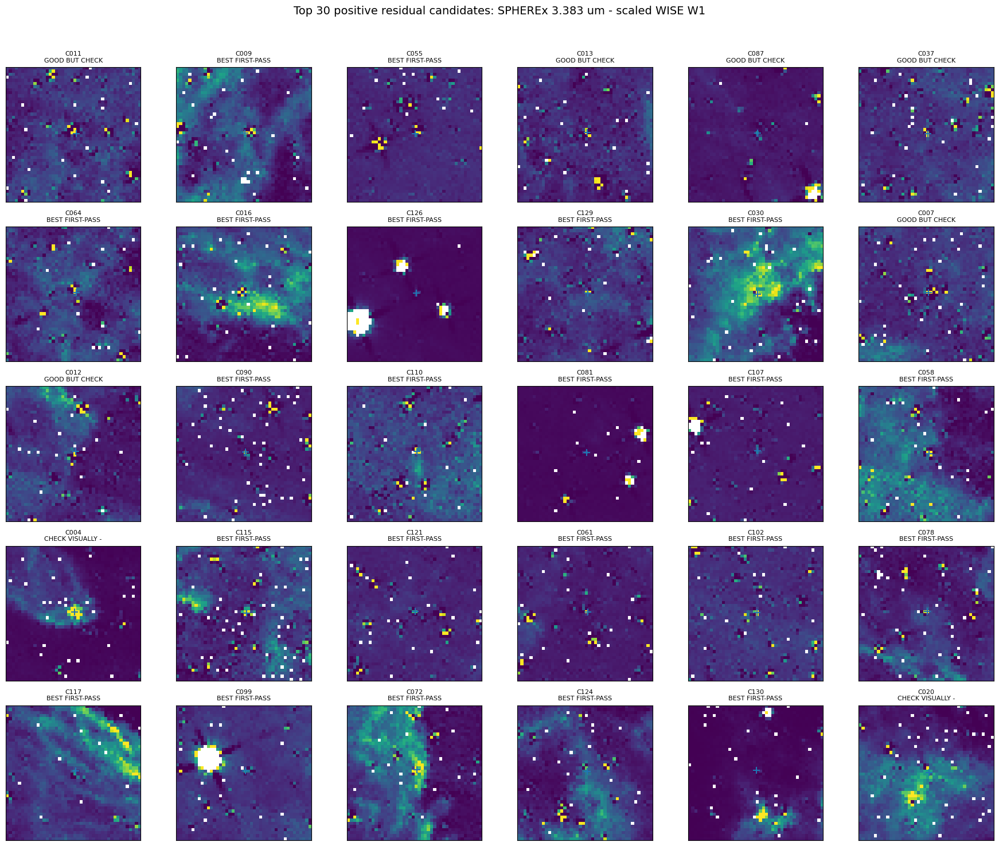


Saved contact sheet:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\final_review\ra45_dec60p5_top30_review_contact_sheet.png


In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

CUBE_PATH = BASE / "field_ra45_dec60p5" / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"
WISE_SCALED_PATH = BASE / "field_ra45_dec60p5" / "photometric_scaling" / "wise_w1_scaled_to_spherex_plane2.fits"
DIFF_PATH = BASE / "field_ra45_dec60p5" / "photometric_scaling" / "spherex_plane2_minus_scaled_wise_w1.fits"

SUMMARY_CSV = BASE / "field_ra45_dec60p5" / "nearby_wavelength_photometry" / "ra45_dec60p5_candidate_5band_ranked_summary.csv"
LONG_CSV = BASE / "field_ra45_dec60p5" / "nearby_wavelength_photometry" / "ra45_dec60p5_candidate_5band_photometry_long.csv"

OUT_DIR = BASE / "field_ra45_dec60p5" / "final_review"
OUT_DIR.mkdir(parents=True, exist_ok=True)

PANEL_DIR = OUT_DIR / "candidate_review_panels"
PANEL_DIR.mkdir(parents=True, exist_ok=True)

REVIEW_CSV = OUT_DIR / "ra45_dec60p5_candidate_review_table.csv"
CONTACT_SHEET = OUT_DIR / "ra45_dec60p5_top30_review_contact_sheet.png"

# ----------------------------
# Load data
# ----------------------------
summary = pd.read_csv(SUMMARY_CSV)
long_df = pd.read_csv(LONG_CSV)

with fits.open(CUBE_PATH) as hdul:
    cube = hdul["IMAGE"].data.astype(float)

with fits.open(WISE_SCALED_PATH) as hdul:
    wise_scaled = hdul[0].data.astype(float)

with fits.open(DIFF_PATH) as hdul:
    diff = hdul[0].data.astype(float)

spx_plane2 = cube[2]

# ----------------------------
# Add artifact warning flags
# ----------------------------
def artifact_notes(row):
    notes = []

    x = row["x_pix"]
    y = row["y_pix"]

    # edge warning
    if x < 45 or x > 581 - 45 or y < 45 or y > 581 - 45:
        notes.append("near edge")

    # big scatter across five SPHEREx planes means suspicious color/PSF/nebulosity/artifact
    if pd.notna(row.get("fractional_scatter_5band", np.nan)) and row["fractional_scatter_5band"] > 0.35:
        notes.append("large 5-band scatter")

    # extreme residual source likely bright-source mismatch
    if pd.notna(row.get("residual_diff_snr_peak", np.nan)) and row["residual_diff_snr_peak"] > 100:
        notes.append("very strong residual / possible bright-source mismatch")

    # very weird sharpness values from detection table
    sharp = row.get("sharp_ratio_peak_over_5x5med", np.nan)
    if pd.isna(sharp):
        notes.append("sharpness undefined")
    elif abs(sharp) > 50:
        notes.append("weird sharpness/background")

    if len(notes) == 0:
        return "clean first-pass"
    return "; ".join(notes)

summary["artifact_notes"] = summary.apply(artifact_notes, axis=1)

# A stricter review class, not final proof
def review_class(row):
    if not row["persistent_3plus_snr5"]:
        return "not top priority"
    if row["artifact_notes"] == "clean first-pass":
        return "BEST FIRST-PASS"
    if "large 5-band scatter" in row["artifact_notes"] or "very strong residual" in row["artifact_notes"]:
        return "CHECK VISUALLY - possible artifact"
    return "GOOD BUT CHECK"

summary["review_class"] = summary.apply(review_class, axis=1)

summary.to_csv(REVIEW_CSV, index=False)

print("Saved review table:")
print(REVIEW_CSV)

print("\nReview class counts:")
print(summary["review_class"].value_counts())

print("\nTop 30 with artifact notes:")
display(summary[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "positive_flux_count_5",
    "snr3_count_5",
    "snr5_count_5",
    "median_flux_mjy",
    "max_snr_local",
    "fractional_scatter_5band",
    "residual_diff_snr_peak",
    "sharp_ratio_peak_over_5x5med",
    "review_class",
    "artifact_notes"
]].head(30))

# ----------------------------
# Make review panels
# ----------------------------
def show_cutout(ax, img, x, y, title, half=30):
    cx = int(round(x))
    cy = int(round(y))

    sl_y = slice(max(0, cy-half), min(img.shape[0], cy+half))
    sl_x = slice(max(0, cx-half), min(img.shape[1], cx+half))

    cut = img[sl_y, sl_x]

    if np.all(~np.isfinite(cut)):
        ax.text(0.5, 0.5, "all NaN", ha="center", va="center")
        ax.set_title(title)
        return

    vmin, vmax = np.nanpercentile(cut, [3, 99.5])
    ax.imshow(cut, origin="lower", vmin=vmin, vmax=vmax)

    # local center position inside cutout
    local_x = x - sl_x.start
    local_y = y - sl_y.start

    ax.scatter(local_x, local_y, marker="+", s=120)

    source_circle = plt.Circle((local_x, local_y), 3.0, fill=False, linewidth=2)
    ann_inner = plt.Circle((local_x, local_y), 5.0, fill=False, linestyle="--", linewidth=1.2)
    ann_outer = plt.Circle((local_x, local_y), 8.0, fill=False, linestyle="--", linewidth=1.2)

    ax.add_patch(source_circle)
    ax.add_patch(ann_inner)
    ax.add_patch(ann_outer)

    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

top_n = 30
top = summary.head(top_n).copy()

for _, row in top.iterrows():
    cid = row["candidate_id"]
    x = row["x_pix"]
    y = row["y_pix"]

    g = long_df[long_df["candidate_id"] == cid].sort_values("wavelength_um")

    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    show_cutout(axes[0, 0], spx_plane2, x, y, "SPHEREx 3.383 um")
    show_cutout(axes[0, 1], wise_scaled, x, y, "Scaled WISE W1")
    show_cutout(axes[1, 0], diff, x, y, "SPHEREx - scaled WISE")

    axes[1, 1].errorbar(
        g["wavelength_um"],
        g["flux_mjy"],
        yerr=g["flux_unc_mjy"],
        marker="o",
        linestyle="-"
    )
    axes[1, 1].axhline(0, linestyle="--", linewidth=1)
    axes[1, 1].set_xlabel("Wavelength [um]")
    axes[1, 1].set_ylabel("Flux [mJy]")
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].set_title("5-band SPHEREx aperture photometry")

    fig.suptitle(
        f"{cid} | RA={row['ra_deg']:.6f}, Dec={row['dec_deg']:.6f}\n"
        f"{row['review_class']} | {row['artifact_notes']}",
        fontsize=11
    )

    plt.tight_layout(rect=[0, 0, 1, 0.93])

    out_png = PANEL_DIR / f"{cid}_review_panel.png"
    plt.savefig(out_png, dpi=200)
    plt.close()

print("\nSaved individual review panels to:")
print(PANEL_DIR)

# ----------------------------
# Make contact sheet of top 30 difference cutouts
# ----------------------------
fig, axes = plt.subplots(5, 6, figsize=(18, 15))
axes = axes.ravel()

for ax, (_, row) in zip(axes, top.iterrows()):
    cid = row["candidate_id"]
    x = row["x_pix"]
    y = row["y_pix"]

    cx = int(round(x))
    cy = int(round(y))
    half = 22

    sl_y = slice(max(0, cy-half), min(diff.shape[0], cy+half))
    sl_x = slice(max(0, cx-half), min(diff.shape[1], cx+half))
    cut = diff[sl_y, sl_x]

    vmin, vmax = np.nanpercentile(cut, [3, 99.5])
    ax.imshow(cut, origin="lower", vmin=vmin, vmax=vmax)

    local_x = x - sl_x.start
    local_y = y - sl_y.start
    ax.scatter(local_x, local_y, marker="+", s=80)

    ax.set_title(
        f"{cid.replace('RA45_CAND_', 'C')}\n"
        f"{row['review_class'][:16]}",
        fontsize=8
    )
    ax.set_xticks([])
    ax.set_yticks([])

for ax in axes[len(top):]:
    ax.axis("off")

plt.suptitle("Top 30 positive residual candidates: SPHEREx 3.383 um - scaled WISE W1", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(CONTACT_SHEET, dpi=200)
plt.show()

print("\nSaved contact sheet:")
print(CONTACT_SHEET)

Loaded scaling table rows: 153
Columns: ['spx_x', 'spx_y', 'wise_x', 'wise_y', 'match_dist_pix', 'dx_wise_minus_spx_pix', 'dy_wise_minus_spx_pix', 'spx_flux_like', 'wise_flux_like', 'spx_ap_sum', 'spx_bkg_per_pix', 'spx_net_ap_flux', 'wise_ap_sum', 'wise_bkg_per_pix', 'wise_net_ap_flux', 'spx_over_wise_ratio', 'used_for_scaling_initial', 'used_for_scaling_final']
Calibration/matched stars used for PSF tuning: 11



PSF tuning results:


,sigma_pix,global_diff_median,global_diff_std,matched_star_median_abs_residual_apflux,matched_star_rms_residual_apflux,matched_star_median_residual_apflux,n_calibration_sources
0,0.00,0.031435,0.123007,4.038085,31.466031,-3.440779e-07,11
1,0.15,0.031435,0.123007,4.038085,31.466031,-3.424695e-07,11
2,0.25,0.031396,0.122981,4.039100,31.467899,2.413939e-03,11
3,0.35,0.030413,0.123433,4.088294,31.558063,1.184377e-01,11
4,0.50,0.026387,0.129744,4.402215,32.118580,8.195403e-01,11
5,0.65,0.023256,0.139082,4.910059,32.962756,1.832004e+00,11
6,0.80,0.020536,0.147022,5.342715,34.347526,3.057792e+00,11
7,1.00,0.016806,0.156837,7.280348,37.467355,5.817175e+00,11
8,1.25,0.012149,0.167296,10.333685,43.592525,1.033369e+01,11
9,1.50,0.007404,0.175834,15.443226,51.664331,1.544323e+01,11



Best PSF Gaussian sigma [pix]: 0.0
Best matched-star median absolute residual: 4.038084967132951
Best global diff std: 0.12300713727781064

Saved PSF-tuned WISE:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\psf_tuning\wise_w1_scaled_psf_tuned_to_spherex_plane2.fits

Saved PSF-tuned difference:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\psf_tuning\spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits


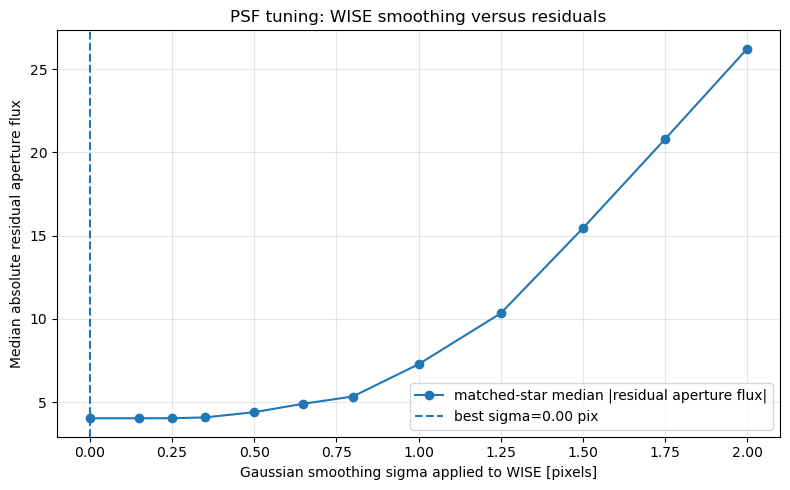


Saved PSF tuning plot:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\psf_tuning\psf_tuning_curve.png


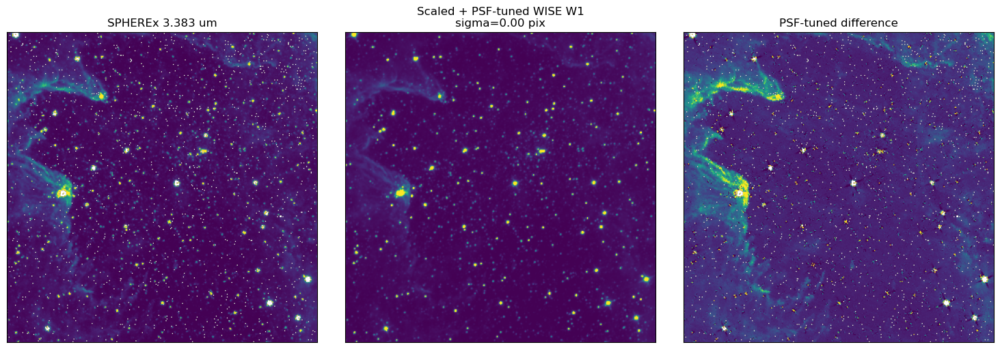


Saved PSF panel:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\psf_tuning\psf_tuned_subtraction_check.png


In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from scipy.ndimage import gaussian_filter

from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

CUBE_PATH = FIELD / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"
WISE_SCALED_PATH = FIELD / "photometric_scaling" / "wise_w1_scaled_to_spherex_plane2.fits"
SCALE_TABLE = FIELD / "photometric_scaling" / "matched_source_aperture_scaling.csv"

OUT_DIR = FIELD / "psf_tuning"
OUT_DIR.mkdir(parents=True, exist_ok=True)

PSF_RESULTS_CSV = OUT_DIR / "psf_tuning_results.csv"
PSF_PLOT = OUT_DIR / "psf_tuning_curve.png"
BEST_WISE_PATH = OUT_DIR / "wise_w1_scaled_psf_tuned_to_spherex_plane2.fits"
BEST_DIFF_PATH = OUT_DIR / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits"
BEST_PANEL = OUT_DIR / "psf_tuned_subtraction_check.png"

# ----------------------------
# Load images
# ----------------------------
with fits.open(CUBE_PATH) as spx_hdul:
    spx_cube = spx_hdul["IMAGE"].data.astype(float)
    spx_hdr = spx_hdul["IMAGE"].header

spx = spx_cube[2]  # 3.383 um, closest to WISE W1

with fits.open(WISE_SCALED_PATH) as wise_hdul:
    wise_scaled = wise_hdul[0].data.astype(float)
    wise_hdr = wise_hdul[0].header

scale_df = pd.read_csv(SCALE_TABLE)

print("Loaded scaling table rows:", len(scale_df))
print("Columns:", list(scale_df.columns))

# Use clean scaling stars if available
if "used_for_scaling_final" in scale_df.columns:
    cal = scale_df[scale_df["used_for_scaling_final"] == True].copy()
else:
    cal = scale_df.copy()

# Fallback if too few
if len(cal) < 5:
    cal = scale_df[
        np.isfinite(scale_df["spx_x"]) &
        np.isfinite(scale_df["spx_y"]) &
        (scale_df["match_dist_pix"] < 1.0)
    ].copy()

print("Calibration/matched stars used for PSF tuning:", len(cal))

if len(cal) < 5:
    raise RuntimeError("Too few clean calibration stars for PSF tuning.")

positions = list(zip(cal["spx_x"].to_numpy(), cal["spx_y"].to_numpy()))

ap_radius = 3.0
annulus_inner = 5.0
annulus_outer = 8.0

apertures = CircularAperture(positions, r=ap_radius)
annuli = CircularAnnulus(positions, r_in=annulus_inner, r_out=annulus_outer)

def local_net_fluxes(image):
    ap_table = aperture_photometry(image, apertures, method="exact")
    ann_table = aperture_photometry(image, annuli, method="exact")

    ap_sum = np.array(ap_table["aperture_sum"], dtype=float)
    ann_sum = np.array(ann_table["aperture_sum"], dtype=float)

    ap_area = apertures.area
    ann_area = annuli.area

    bkg_per_pix = ann_sum / ann_area
    net = ap_sum - bkg_per_pix * ap_area

    return net

# ----------------------------
# Try Gaussian PSF kernels on WISE
# ----------------------------
sigma_grid_pix = np.array([
    0.00, 0.15, 0.25, 0.35, 0.50, 0.65, 0.80, 1.00, 1.25, 1.50, 1.75, 2.00
])

rows = []

for sigma in sigma_grid_pix:
    if sigma == 0:
        wise_test = wise_scaled.copy()
    else:
        # Preserve NaN behavior reasonably
        mask = np.isfinite(wise_scaled)
        filled = np.nan_to_num(wise_scaled, nan=0.0)

        smoothed = gaussian_filter(filled, sigma=sigma)
        smoothed_mask = gaussian_filter(mask.astype(float), sigma=sigma)

        wise_test = smoothed / smoothed_mask
        wise_test[smoothed_mask <= 0] = np.nan

    diff_test = spx - wise_test

    # Global robust background residual
    mean, med, std = sigma_clipped_stats(diff_test, sigma=3.0, maxiters=5)

    # Residual aperture flux around matched stars
    resid_net = local_net_fluxes(diff_test)

    median_abs_resid = np.nanmedian(np.abs(resid_net))
    rms_resid = np.sqrt(np.nanmean(resid_net**2))
    med_resid = np.nanmedian(resid_net)

    rows.append({
        "sigma_pix": sigma,
        "global_diff_median": med,
        "global_diff_std": std,
        "matched_star_median_abs_residual_apflux": median_abs_resid,
        "matched_star_rms_residual_apflux": rms_resid,
        "matched_star_median_residual_apflux": med_resid,
        "n_calibration_sources": len(cal),
    })

results = pd.DataFrame(rows)

# Choose best sigma by matched-star median absolute residual
best_idx = results["matched_star_median_abs_residual_apflux"].idxmin()
best = results.loc[best_idx]
best_sigma = float(best["sigma_pix"])

results.to_csv(PSF_RESULTS_CSV, index=False)

print("\nPSF tuning results:")
display(results)

print("\nBest PSF Gaussian sigma [pix]:", best_sigma)
print("Best matched-star median absolute residual:", best["matched_star_median_abs_residual_apflux"])
print("Best global diff std:", best["global_diff_std"])

# ----------------------------
# Save best PSF-tuned WISE and difference
# ----------------------------
if best_sigma == 0:
    wise_best = wise_scaled.copy()
else:
    mask = np.isfinite(wise_scaled)
    filled = np.nan_to_num(wise_scaled, nan=0.0)

    smoothed = gaussian_filter(filled, sigma=best_sigma)
    smoothed_mask = gaussian_filter(mask.astype(float), sigma=best_sigma)

    wise_best = smoothed / smoothed_mask
    wise_best[smoothed_mask <= 0] = np.nan

diff_best = spx - wise_best

out_hdr = wise_hdr.copy()
out_hdr["COMMENT"] = f"WISE scaled image Gaussian-smoothed for PSF tuning. sigma_pix={best_sigma}"

fits.writeto(BEST_WISE_PATH, wise_best.astype("float32"), out_hdr, overwrite=True)

diff_hdr = wise_hdr.copy()
diff_hdr["BUNIT"] = spx_hdr.get("BUNIT", "MJy/sr")
diff_hdr["COMMENT"] = f"SPHEREx plane2 minus scaled+PSF-tuned WISE. Gaussian sigma_pix={best_sigma}"

fits.writeto(BEST_DIFF_PATH, diff_best.astype("float32"), diff_hdr, overwrite=True)

print("\nSaved PSF-tuned WISE:")
print(BEST_WISE_PATH)

print("\nSaved PSF-tuned difference:")
print(BEST_DIFF_PATH)

# ----------------------------
# Plot PSF tuning curve
# ----------------------------
plt.figure(figsize=(8, 5))
plt.plot(
    results["sigma_pix"],
    results["matched_star_median_abs_residual_apflux"],
    marker="o",
    label="matched-star median |residual aperture flux|"
)
plt.axvline(best_sigma, linestyle="--", label=f"best sigma={best_sigma:.2f} pix")
plt.xlabel("Gaussian smoothing sigma applied to WISE [pixels]")
plt.ylabel("Median absolute residual aperture flux")
plt.title("PSF tuning: WISE smoothing versus residuals")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(PSF_PLOT, dpi=200)
plt.show()

print("\nSaved PSF tuning plot:")
print(PSF_PLOT)

# ----------------------------
# Visual panel
# ----------------------------
cx, cy = 290, 290
half = 170

sl_y = slice(cy-half, cy+half)
sl_x = slice(cx-half, cx+half)

spx_crop = spx[sl_y, sl_x]
wise_crop = wise_best[sl_y, sl_x]
diff_crop = diff_best[sl_y, sl_x]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, img, title in [
    (axes[0], spx_crop, "SPHEREx 3.383 um"),
    (axes[1], wise_crop, f"Scaled + PSF-tuned WISE W1\nsigma={best_sigma:.2f} pix"),
    (axes[2], diff_crop, "PSF-tuned difference"),
]:
    vmin, vmax = np.nanpercentile(img, [2, 99.5])
    ax.imshow(img, origin="lower", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.savefig(BEST_PANEL, dpi=200)
plt.show()

print("\nSaved PSF panel:")
print(BEST_PANEL)

In [20]:
from pathlib import Path
import shutil
import zipfile
import pandas as pd
import numpy as np

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

REVIEW_CSV = FIELD / "final_review" / "ra45_dec60p5_candidate_review_table.csv"
LONG_CSV = FIELD / "nearby_wavelength_photometry" / "ra45_dec60p5_candidate_5band_photometry_long.csv"
CONTACT_SHEET = FIELD / "final_review" / "ra45_dec60p5_top30_review_contact_sheet.png"
PANEL_DIR = FIELD / "final_review" / "candidate_review_panels"

PSF_RESULTS = FIELD / "psf_tuning" / "psf_tuning_results.csv"
PSF_CURVE = FIELD / "psf_tuning" / "psf_tuning_curve.png"
PSF_PANEL = FIELD / "psf_tuning" / "psf_tuned_subtraction_check.png"
PSF_DIFF = FIELD / "psf_tuning" / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits"

ASTROM_CSV = FIELD / "alignment_check" / "spherex_wise_matched_sources_astrometry.csv"
ASTROM_PNG = FIELD / "alignment_check" / "spherex_wise_astrometric_offsets.png"

SCALING_CSV = FIELD / "photometric_scaling" / "matched_source_aperture_scaling.csv"
SCALING_PNG = FIELD / "photometric_scaling" / "spherex_wise_aperture_scaling_ratios.png"

OUT_DIR = FIELD / "FINAL_HORA_RA45_DEC60P5_DELIVERABLE"
OUT_DIR.mkdir(parents=True, exist_ok=True)

OUT_PANEL_DIR = OUT_DIR / "candidate_review_panels"
OUT_PANEL_DIR.mkdir(parents=True, exist_ok=True)

FINAL_TABLE = OUT_DIR / "ra45_dec60p5_final_shortlist.csv"
FINAL_LONG = OUT_DIR / "ra45_dec60p5_final_shortlist_5band_photometry_long.csv"
README = OUT_DIR / "README_RA45_DEC60P5.txt"
ZIP_PATH = FIELD / "FINAL_HORA_RA45_DEC60P5_DELIVERABLE.zip"

review = pd.read_csv(REVIEW_CSV)
long_df = pd.read_csv(LONG_CSV)
psf = pd.read_csv(PSF_RESULTS)

best_row = psf.loc[psf["matched_star_median_abs_residual_apflux"].idxmin()]
best_sigma = float(best_row["sigma_pix"])
best_resid = float(best_row["matched_star_median_abs_residual_apflux"])
best_std = float(best_row["global_diff_std"])

# Conservative final shortlist
short = review[
    (review["review_class"] == "BEST FIRST-PASS") &
    (review["positive_flux_count_5"] >= 4) &
    (review["snr5_count_5"] >= 4) &
    (review["fractional_scatter_5band"] < 0.30) &
    (review["residual_diff_snr_peak"] < 80)
].copy()

short = short.sort_values(
    ["snr5_count_5", "positive_flux_count_5", "max_snr_local", "fractional_scatter_5band"],
    ascending=[False, False, False, True]
).reset_index(drop=True)

# Keep top 20 so we do not overwhelm him
short_top = short.head(20).copy()
short_top.to_csv(FINAL_TABLE, index=False)

keep_ids = set(short_top["candidate_id"])
long_short = long_df[long_df["candidate_id"].isin(keep_ids)].copy()
long_short.to_csv(FINAL_LONG, index=False)

# Copy full tables too
shutil.copy2(REVIEW_CSV, OUT_DIR / "full_candidate_review_table.csv")
shutil.copy2(LONG_CSV, OUT_DIR / "full_5band_photometry_long.csv")

# Copy diagnostic products
for src in [
    CONTACT_SHEET,
    PSF_RESULTS,
    PSF_CURVE,
    PSF_PANEL,
    PSF_DIFF,
    ASTROM_CSV,
    ASTROM_PNG,
    SCALING_CSV,
    SCALING_PNG,
]:
    if src.exists():
        shutil.copy2(src, OUT_DIR / src.name)

# Copy review panels for the shortlist only
for cid in short_top["candidate_id"]:
    src = PANEL_DIR / f"{cid}_review_panel.png"
    if src.exists():
        shutil.copy2(src, OUT_PANEL_DIR / src.name)

readme = f"""RA45_DEC60P5 SPHEREx/WISE local photometry deliverable

Field:
RA = 45.0 deg
Dec = 60.5 deg

What was done:
1. Generated a new SPHEREx mosaic cube centered at RA=45.0, Dec=60.5.
2. Used wavelength range 3.20-3.58 um.
3. Confirmed five SPHEREx planes:
   3.204, 3.293, 3.383, 3.476, 3.570 um.
4. Downloaded AllWISE W1 image for the same field.
5. Reprojected WISE W1 onto the SPHEREx pixel grid.
6. Checked WISE/SPHEREx astrometric alignment with matched sources.
   Median offset:
   dx = 0.011 pix
   dy = 0.022 pix
   Therefore no astrometric shift was applied.
7. Empirically scaled WISE W1 to SPHEREx plane 2 using matched-source local aperture photometry.
   Scale factor:
   SPHEREx plane 2 ≈ 0.0445266 * WISE W1
8. Performed PSF-tuning test by smoothing the scaled WISE image with Gaussian kernels.
   Tested sigma values from 0.00 to 2.00 pixels.
   Best sigma = {best_sigma:.2f} pixels.
   This means no extra smoothing improved the subtraction, so the no-smoothing difference was retained.
   Best matched-star median absolute residual aperture flux = {best_resid:.6g}
   Best global difference-image std = {best_std:.6g}
9. Created residual image:
   SPHEREx plane 2 at 3.383 um minus scaled/PSF-tuned WISE W1.
10. Detected positive residual candidates.
11. Performed five-band local SPHEREx aperture photometry on candidates.
12. Filtered candidates by nearby-wavelength persistence and first-pass artifact notes.

Photometry method:
- Photutils circular aperture photometry.
- Source aperture radius = 3 pixels.
- Local background annulus = 5-8 pixels.
- SPHEREx IMAGE units converted from MJy/sr * pixels to mJy using pixel solid angle.
- Local uncertainty is based on annulus background scatter.
- These are screening uncertainties, not final publication-grade errors.

Screening result counts:
{review["review_class"].value_counts().to_string()}

Final conservative shortlist criteria:
- review_class == BEST FIRST-PASS
- positive flux in at least 4 of 5 SPHEREx planes
- local >=5sigma detection in at least 4 of 5 SPHEREx planes
- fractional five-band scatter < 0.30
- residual_diff_snr_peak < 80

Final shortlist count:
{len(short_top)}

Important limitations:
- These are first-pass local aperture photometry products.
- They are not final proof of astrophysical variability.
- WISE/SPHEREx color terms may matter because WISE W1 is broad and SPHEREx channels are narrower.
- The aperture correction/absolute flux calibration should still be refined using isolated high-S/N non-variable calibration sources where IRSA photometry can be obtained reliably.
- Bright-source residuals and nebulosity mismatch may still contaminate some candidates, so review panels are included.

Files included:
- ra45_dec60p5_final_shortlist.csv
- ra45_dec60p5_final_shortlist_5band_photometry_long.csv
- full_candidate_review_table.csv
- full_5band_photometry_long.csv
- psf_tuning_results.csv
- psf_tuning_curve.png
- psf_tuned_subtraction_check.png
- spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits
- spherex_wise_matched_sources_astrometry.csv
- spherex_wise_astrometric_offsets.png
- matched_source_aperture_scaling.csv
- spherex_wise_aperture_scaling_ratios.png
- ra45_dec60p5_top30_review_contact_sheet.png
- candidate_review_panels/*.png
"""

README.write_text(readme, encoding="utf-8")

# Make ZIP
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT_DIR.rglob("*"):
        z.write(p, arcname=p.relative_to(OUT_DIR.parent))

print("FINAL SHORTLIST COUNT:", len(short_top))

print("\nFinal shortlist:")
display(short_top[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "positive_flux_count_5",
    "snr3_count_5",
    "snr5_count_5",
    "median_flux_mjy",
    "max_snr_local",
    "fractional_scatter_5band",
    "residual_diff_snr_peak",
    "review_class",
    "artifact_notes"
]])

print("\nWrote final deliverable folder:")
print(OUT_DIR)

print("\nWrote final ZIP:")
print(ZIP_PATH)

FINAL SHORTLIST COUNT: 20

Final shortlist:


,candidate_id,ra_deg,dec_deg,positive_flux_count_5,snr3_count_5,snr5_count_5,median_flux_mjy,max_snr_local,fractional_scatter_5band,residual_diff_snr_peak,review_class,artifact_notes
0,RA45_CAND_009,44.255910,60.478930,5,5,5,105.675742,369.705638,0.080594,45.178040,BEST FIRST-PASS,clean first-pass
1,RA45_CAND_055,45.651034,60.146567,5,5,5,25.239576,230.065401,0.104519,16.648233,BEST FIRST-PASS,clean first-pass
2,RA45_CAND_064,44.322124,60.219351,5,5,5,23.656575,73.410584,0.048161,13.483832,BEST FIRST-PASS,clean first-pass
3,RA45_CAND_016,45.110626,60.802519,5,5,5,43.756308,47.013077,0.068240,32.611722,BEST FIRST-PASS,clean first-pass
4,RA45_CAND_126,45.682209,60.862931,5,5,5,18.323209,39.254823,0.067087,6.034545,BEST FIRST-PASS,clean first-pass
5,RA45_CAND_129,44.500456,60.130102,5,5,5,6.292296,24.485407,0.102615,5.487292,BEST FIRST-PASS,clean first-pass
6,RA45_CAND_030,45.551535,60.661693,5,5,5,24.001603,12.695357,0.274721,23.256214,BEST FIRST-PASS,clean first-pass
7,RA45_CAND_090,45.099279,60.922002,4,4,4,17.375798,108.728203,0.134159,9.920144,BEST FIRST-PASS,clean first-pass
8,RA45_CAND_110,44.825933,60.141959,4,4,4,11.645365,89.453249,0.087526,7.644624,BEST FIRST-PASS,clean first-pass
9,RA45_CAND_081,44.664848,60.438984,4,4,4,24.237862,86.650271,0.160121,10.961483,BEST FIRST-PASS,clean first-pass



Wrote final deliverable folder:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\FINAL_HORA_RA45_DEC60P5_DELIVERABLE

Wrote final ZIP:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\FINAL_HORA_RA45_DEC60P5_DELIVERABLE.zip


In [21]:
from pathlib import Path
import shutil
import zipfile
import pandas as pd
import numpy as np

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

# ============================================================
# INPUT FILES FROM COMPLETED WORKFLOW
# ============================================================
REVIEW_CSV = FIELD / "final_review" / "ra45_dec60p5_candidate_review_table.csv"
LONG_CSV = FIELD / "nearby_wavelength_photometry" / "ra45_dec60p5_candidate_5band_photometry_long.csv"

CONTACT_SHEET = FIELD / "final_review" / "ra45_dec60p5_top30_review_contact_sheet.png"
PANEL_DIR = FIELD / "final_review" / "candidate_review_panels"

ASTROM_CSV = FIELD / "alignment_check" / "spherex_wise_matched_sources_astrometry.csv"
ASTROM_PNG = FIELD / "alignment_check" / "spherex_wise_astrometric_offsets.png"

SCALING_CSV = FIELD / "photometric_scaling" / "matched_source_aperture_scaling.csv"
SCALING_PNG = FIELD / "photometric_scaling" / "spherex_wise_aperture_scaling_ratios.png"

PSF_RESULTS = FIELD / "psf_tuning" / "psf_tuning_results.csv"
PSF_CURVE = FIELD / "psf_tuning" / "psf_tuning_curve.png"
PSF_PANEL = FIELD / "psf_tuning" / "psf_tuned_subtraction_check.png"
PSF_DIFF = FIELD / "psf_tuning" / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits"

# ============================================================
# FINAL OUTPUT FOLDER / ZIP
# ============================================================
OUT_DIR = FIELD / "new_coordinates"
OUT_PANEL_DIR = OUT_DIR / "candidate_review_panels"
ZIP_PATH = FIELD / "new_coordinates.zip"

# Clean old version if it exists
if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_PANEL_DIR.mkdir(parents=True, exist_ok=True)

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

# ============================================================
# LOAD TABLES
# ============================================================
review = pd.read_csv(REVIEW_CSV)
long_df = pd.read_csv(LONG_CSV)
psf = pd.read_csv(PSF_RESULTS)

# ============================================================
# FINAL CONSERVATIVE SHORTLIST
# ============================================================
# Necessary logic:
# - only candidates marked BEST FIRST-PASS
# - persistent in at least 4/5 SPHEREx bands
# - >=5 sigma in at least 4/5 bands
# - not huge five-band scatter
# - not extreme residual peak likely caused by bright-source mismatch
short = review[
    (review["review_class"] == "BEST FIRST-PASS") &
    (review["positive_flux_count_5"] >= 4) &
    (review["snr5_count_5"] >= 4) &
    (review["fractional_scatter_5band"] < 0.30) &
    (review["residual_diff_snr_peak"] < 80)
].copy()

short = short.sort_values(
    ["snr5_count_5", "positive_flux_count_5", "max_snr_local", "fractional_scatter_5band"],
    ascending=[False, False, False, True]
).reset_index(drop=True)

# Keep top 20 so the file is focused and not overwhelming
short_top = short.head(20).copy()

FINAL_SHORTLIST = OUT_DIR / "ra45_dec60p5_final_shortlist.csv"
FINAL_SHORTLIST_LONG = OUT_DIR / "ra45_dec60p5_final_shortlist_5band_photometry_long.csv"
FULL_REVIEW_OUT = OUT_DIR / "ra45_dec60p5_full_candidate_review_table.csv"

short_top.to_csv(FINAL_SHORTLIST, index=False)

keep_ids = set(short_top["candidate_id"])
long_short = long_df[long_df["candidate_id"].isin(keep_ids)].copy()
long_short.to_csv(FINAL_SHORTLIST_LONG, index=False)

# Full review table is useful for Dr. Hora to see what was rejected/flagged
review.to_csv(FULL_REVIEW_OUT, index=False)

# ============================================================
# COPY NECESSARY DIAGNOSTIC FILES
# ============================================================
needed_files = [
    CONTACT_SHEET,
    ASTROM_CSV,
    ASTROM_PNG,
    SCALING_CSV,
    SCALING_PNG,
    PSF_RESULTS,
    PSF_CURVE,
    PSF_PANEL,
    PSF_DIFF,
]

for src in needed_files:
    if src.exists():
        shutil.copy2(src, OUT_DIR / src.name)
    else:
        print("WARNING missing:", src)

# Copy only review panels for final shortlisted candidates
copied_panels = 0
for cid in short_top["candidate_id"]:
    src = PANEL_DIR / f"{cid}_review_panel.png"
    if src.exists():
        shutil.copy2(src, OUT_PANEL_DIR / src.name)
        copied_panels += 1
    else:
        print("WARNING missing panel:", src)

# ============================================================
# README
# ============================================================
best_row = psf.loc[psf["matched_star_median_abs_residual_apflux"].idxmin()]
best_sigma = float(best_row["sigma_pix"])
best_resid = float(best_row["matched_star_median_abs_residual_apflux"])
best_std = float(best_row["global_diff_std"])

README = OUT_DIR / "README_new_coordinates.txt"

readme_text = f"""new_coordinates deliverable
RA45_DEC60P5 SPHEREx/WISE local photometry screening package

Field center:
RA = 45.0 deg
Dec = 60.5 deg

Summary:
This package contains the cleaned, necessary outputs from the local SPHEREx/WISE screening workflow for the new coordinates Dr. Hora provided.

What was done:
1. Created a SPHEREx mosaic cube centered at RA=45.0, Dec=60.5.
2. Used SPHEREx wavelength range 3.20-3.58 um.
3. Confirmed five SPHEREx planes:
   3.204, 3.293, 3.383, 3.476, 3.570 um.
4. Downloaded AllWISE W1 for the same field.
5. Reprojected WISE W1 onto the SPHEREx grid.
6. Checked WISE/SPHEREx astrometry:
   median dx = 0.011 pix
   median dy = 0.022 pix
   No shift correction was applied.
7. Scaled WISE W1 to SPHEREx plane 2 using matched-source local aperture photometry:
   SPHEREx plane 2 ≈ 0.0445266 * WISE W1.
8. Performed PSF tuning using Gaussian smoothing of scaled WISE:
   best sigma = {best_sigma:.2f} pixels.
   This means no additional smoothing improved the subtraction.
   Best matched-star median absolute residual aperture flux = {best_resid:.6g}
   Best global difference-image std = {best_std:.6g}
9. Detected positive residual candidates from:
   SPHEREx 3.383 um - scaled/PSF-tested WISE W1.
10. Performed five-band local SPHEREx aperture photometry on candidates.

Photometry method:
- Photutils circular aperture photometry.
- Source aperture radius = 3 pixels.
- Local background annulus = 5-8 pixels.
- SPHEREx IMAGE values converted from MJy/sr * pixels to mJy using pixel solid angle.
- Local uncertainties come from annulus background scatter.
- These are screening uncertainties, not final publication-grade errors.

Candidate filtering:
The final shortlist keeps candidates that are:
- BEST FIRST-PASS
- positive in at least 4 of 5 SPHEREx wavelength planes
- >=5 sigma in at least 4 of 5 SPHEREx wavelength planes
- fractional five-band scatter < 0.30
- residual_diff_snr_peak < 80

Final shortlist count:
{len(short_top)}

Review class counts from full table:
{review["review_class"].value_counts().to_string()}

Important limitations:
- These candidates are screening candidates, not confirmed variables.
- WISE W1 is broad while SPHEREx channels are narrower, so color terms may matter.
- Absolute aperture correction should still be refined later using isolated high-S/N non-variable calibration sources where IRSA photometry works.
- Bright-source residuals, nebulosity mismatch, and local background issues may still affect some candidates.

Included files:
- README_new_coordinates.txt
- ra45_dec60p5_final_shortlist.csv
- ra45_dec60p5_final_shortlist_5band_photometry_long.csv
- ra45_dec60p5_full_candidate_review_table.csv
- ra45_dec60p5_top30_review_contact_sheet.png
- candidate_review_panels/*.png
- spherex_wise_matched_sources_astrometry.csv
- spherex_wise_astrometric_offsets.png
- matched_source_aperture_scaling.csv
- spherex_wise_aperture_scaling_ratios.png
- psf_tuning_results.csv
- psf_tuning_curve.png
- psf_tuned_subtraction_check.png
- spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits

Not included:
- raw SPHEREx cube
- raw WISE downloads
- intermediate notebook scratch/test files
- old-coordinate files
"""

README.write_text(readme_text, encoding="utf-8")

# ============================================================
# ZIP
# ============================================================
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT_DIR.rglob("*"):
        z.write(p, arcname=p.relative_to(OUT_DIR.parent))

# ============================================================
# FINAL CHECK
# ============================================================
print("FINAL ZIP CREATED:")
print(ZIP_PATH)

print("\nFINAL FOLDER:")
print(OUT_DIR)

print("\nFinal shortlist count:", len(short_top))
print("Candidate review panels copied:", copied_panels)

print("\nFiles included in new_coordinates:")
for p in sorted(OUT_DIR.rglob("*")):
    print(" ", p.relative_to(OUT_DIR))

print("\nFinal shortlist preview:")
display(short_top[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "positive_flux_count_5",
    "snr5_count_5",
    "median_flux_mjy",
    "max_snr_local",
    "fractional_scatter_5band",
    "residual_diff_snr_peak",
    "review_class",
    "artifact_notes"
]])

FINAL ZIP CREATED:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\new_coordinates.zip

FINAL FOLDER:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\new_coordinates

Final shortlist count: 20
Candidate review panels copied: 20

Files included in new_coordinates:
  candidate_review_panels
  candidate_review_panels\RA45_CAND_009_review_panel.png
  candidate_review_panels\RA45_CAND_016_review_panel.png
  candidate_review_panels\RA45_CAND_030_review_panel.png
  candidate_review_panels\RA45_CAND_055_review_panel.png
  candidate_review_panels\RA45_CAND_058_review_panel.png
  candidate_review_panels\RA45_CAND_061_review_panel.png
  candidate_review_panels\RA45_CAND_064_review_panel.png
  candidate_review_panels\RA45_CAND_072_review_panel.png
  candidate_review_panels\RA45_CAND_078_review_panel.png
  candidate_review_panels\RA45_CAND_081_review_panel.png
  candidate_review_panels\RA45_CAND_090_review_panel.png
  candidate_review_panels\RA45_CAND_099_review_pane

,candidate_id,ra_deg,dec_deg,positive_flux_count_5,snr5_count_5,median_flux_mjy,max_snr_local,fractional_scatter_5band,residual_diff_snr_peak,review_class,artifact_notes
0,RA45_CAND_009,44.255910,60.478930,5,5,105.675742,369.705638,0.080594,45.178040,BEST FIRST-PASS,clean first-pass
1,RA45_CAND_055,45.651034,60.146567,5,5,25.239576,230.065401,0.104519,16.648233,BEST FIRST-PASS,clean first-pass
2,RA45_CAND_064,44.322124,60.219351,5,5,23.656575,73.410584,0.048161,13.483832,BEST FIRST-PASS,clean first-pass
3,RA45_CAND_016,45.110626,60.802519,5,5,43.756308,47.013077,0.068240,32.611722,BEST FIRST-PASS,clean first-pass
4,RA45_CAND_126,45.682209,60.862931,5,5,18.323209,39.254823,0.067087,6.034545,BEST FIRST-PASS,clean first-pass
5,RA45_CAND_129,44.500456,60.130102,5,5,6.292296,24.485407,0.102615,5.487292,BEST FIRST-PASS,clean first-pass
6,RA45_CAND_030,45.551535,60.661693,5,5,24.001603,12.695357,0.274721,23.256214,BEST FIRST-PASS,clean first-pass
7,RA45_CAND_090,45.099279,60.922002,4,4,17.375798,108.728203,0.134159,9.920144,BEST FIRST-PASS,clean first-pass
8,RA45_CAND_110,44.825933,60.141959,4,4,11.645365,89.453249,0.087526,7.644624,BEST FIRST-PASS,clean first-pass
9,RA45_CAND_081,44.664848,60.438984,4,4,24.237862,86.650271,0.160121,10.961483,BEST FIRST-PASS,clean first-pass


In [1]:
# ============================================================
# CELL 1 — SETUP / IMPORTS / FILE CHECKS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from astropy.io import fits
from astropy.wcs import WCS

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

CUBE_PATH = FIELD / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"
SCALING_CSV = FIELD / "photometric_scaling" / "matched_source_aperture_scaling.csv"
FINAL_SHORTLIST_CSV = FIELD / "new_coordinates" / "ra45_dec60p5_final_shortlist.csv"

CAL_DIR = FIELD / "calibration_sources"
CAL_DIR.mkdir(parents=True, exist_ok=True)

print("Checking required files:")

for p in [CUBE_PATH, SCALING_CSV, FINAL_SHORTLIST_CSV]:
    print(p)
    if not p.exists():
        raise FileNotFoundError(f"Missing required file: {p}")

print("\nAll required files exist.")
print("Calibration output folder:")
print(CAL_DIR)

Checking required files:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\spherex_raw\spherex_ra45_dec60p5_3p20_3p58_cube.fits
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\photometric_scaling\matched_source_aperture_scaling.csv
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\new_coordinates\ra45_dec60p5_final_shortlist.csv

All required files exist.
Calibration output folder:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\calibration_sources


In [2]:
# ============================================================
# CELL 2 — SELECT CALIBRATION SOURCES + CONVERT PIXELS TO RA/DEC
# ============================================================

CAL_CSV = CAL_DIR / "ra45_dec60p5_isolated_calibration_sources.csv"

# Load matched-source scaling table
scale_df = pd.read_csv(SCALING_CSV)

print("Scaling table rows:", len(scale_df))
print("Columns:")
print(list(scale_df.columns))

# Start with sources that were actually used for the WISE/SPHEREx scaling
if "used_for_scaling_final" in scale_df.columns:
    cal = scale_df[scale_df["used_for_scaling_final"] == True].copy()
else:
    cal = scale_df.copy()

print("\nInitial calibration candidates from scaling-final rows:", len(cal))

# Sanity cuts
required_cols = [
    "spx_x", "spx_y",
    "match_dist_pix",
    "spx_net_ap_flux",
    "wise_net_ap_flux",
    "spx_over_wise_ratio",
]

for c in required_cols:
    if c not in cal.columns:
        raise KeyError(f"Missing required column in scaling table: {c}")

cal = cal[
    np.isfinite(cal["spx_x"]) &
    np.isfinite(cal["spx_y"]) &
    np.isfinite(cal["match_dist_pix"]) &
    np.isfinite(cal["spx_net_ap_flux"]) &
    np.isfinite(cal["wise_net_ap_flux"]) &
    np.isfinite(cal["spx_over_wise_ratio"]) &
    (cal["match_dist_pix"] < 1.0) &
    (cal["spx_net_ap_flux"] > 0) &
    (cal["wise_net_ap_flux"] > 0)
].copy()

print("After sanity cuts:", len(cal))

if len(cal) < 3:
    raise RuntimeError("Too few calibration sources. Need to loosen cuts or inspect scaling table.")

# Prefer sources whose SPHEREx/WISE ratio is near the scaling median
ratio_med = np.nanmedian(cal["spx_over_wise_ratio"])
cal["ratio_abs_dev_from_median"] = np.abs(cal["spx_over_wise_ratio"] - ratio_med)

# Avoid insanely bright outliers if present, but keep high-S/N sources
# Sort by: closest astrometric match, most typical scaling ratio, high SPHEREx aperture flux
cal = cal.sort_values(
    ["match_dist_pix", "ratio_abs_dev_from_median", "spx_net_ap_flux"],
    ascending=[True, True, False]
).reset_index(drop=True)

# Keep at most 10 for a small IRSA test
cal = cal.head(10).copy()
cal["cal_id"] = [f"CAL_{i+1:03d}" for i in range(len(cal))]

# Convert SPHEREx pixel x/y to RA/Dec
with fits.open(CUBE_PATH) as hdul:
    hdr = hdul["IMAGE"].header
    
    # IMPORTANT: pass HDUList because SPHEREx WCS has WAVE-TAB axis
    wcs = WCS(hdr, hdul).celestial
    
    ras = []
    decs = []
    
    for _, row in cal.iterrows():
        sky = wcs.pixel_to_world(float(row["spx_x"]), float(row["spx_y"]))
        ras.append(float(sky.ra.deg))
        decs.append(float(sky.dec.deg))

cal["ra_deg"] = ras
cal["dec_deg"] = decs

# Reorder useful columns
ordered_cols = [
    "cal_id",
    "ra_deg",
    "dec_deg",
    "spx_x",
    "spx_y",
    "match_dist_pix",
    "dx_wise_minus_spx_pix",
    "dy_wise_minus_spx_pix",
    "spx_net_ap_flux",
    "wise_net_ap_flux",
    "spx_over_wise_ratio",
    "ratio_abs_dev_from_median",
]

ordered_cols = [c for c in ordered_cols if c in cal.columns]
cal_out = cal[ordered_cols].copy()

cal_out.to_csv(CAL_CSV, index=False)

print("\nSaved calibration source CSV:")
print(CAL_CSV)

print("\nCalibration sources:")
display(cal_out)

Scaling table rows: 153
Columns:
['spx_x', 'spx_y', 'wise_x', 'wise_y', 'match_dist_pix', 'dx_wise_minus_spx_pix', 'dy_wise_minus_spx_pix', 'spx_flux_like', 'wise_flux_like', 'spx_ap_sum', 'spx_bkg_per_pix', 'spx_net_ap_flux', 'wise_ap_sum', 'wise_bkg_per_pix', 'wise_net_ap_flux', 'spx_over_wise_ratio', 'used_for_scaling_initial', 'used_for_scaling_final']

Initial calibration candidates from scaling-final rows: 11
After sanity cuts: 11

Saved calibration source CSV:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\calibration_sources\ra45_dec60p5_isolated_calibration_sources.csv

Calibration sources:


,cal_id,ra_deg,dec_deg,spx_x,spx_y,match_dist_pix,dx_wise_minus_spx_pix,dy_wise_minus_spx_pix,spx_net_ap_flux,wise_net_ap_flux,spx_over_wise_ratio,ratio_abs_dev_from_median
0,CAL_001,45.354038,60.297627,188.140495,172.765741,0.086930,0.083500,0.024175,64.553443,1202.158250,0.053698,0.009171
1,CAL_002,45.395837,60.292541,176.096932,169.881304,0.099305,0.083858,0.053191,104.187234,1842.549604,0.056545,0.012019
2,CAL_003,45.286660,60.292972,207.513927,169.969044,0.106894,-0.071718,-0.079265,30.794629,899.965778,0.034218,0.010309
3,CAL_004,44.241377,60.678063,505.714870,394.637132,0.142719,0.141158,-0.021050,112.703000,2531.138415,0.044527,0.000000
4,CAL_005,45.841147,60.842906,52.042821,490.634316,0.152144,-0.038196,-0.147272,377.231479,6214.453956,0.060702,0.016176
5,CAL_006,45.835298,60.862437,53.841565,501.953749,0.174005,-0.173906,-0.005885,62.855341,1487.349237,0.042260,0.002267
6,CAL_007,45.810519,60.827231,60.595106,481.424282,0.186411,-0.103561,-0.154997,47.022853,1113.369369,0.042235,0.002292
7,CAL_008,45.714443,60.080446,83.081406,47.501617,0.208531,-0.014614,-0.208018,53.175470,1348.331040,0.039438,0.005089
8,CAL_009,45.900120,60.196856,30.230721,115.750013,0.214335,0.209688,0.044389,65.768845,1447.665923,0.045431,0.000904
9,CAL_010,45.696880,60.931231,93.397722,541.441855,0.215200,0.011160,-0.214911,70.964508,1503.065926,0.047213,0.002687


In [3]:
# ============================================================
# CELL 3 — WRITE SMALL IRSA/IPAC .TBL FOR CALIBRATION SOURCES
# ============================================================

CAL_CSV = CAL_DIR / "ra45_dec60p5_isolated_calibration_sources.csv"
CAL_TBL = CAL_DIR / "ra45_dec60p5_isolated_calibration_sources_for_irsa.tbl"

cal = pd.read_csv(CAL_CSV)

# IRSA wants clean target table columns: name, ra, dec
upload = pd.DataFrame({
    "name": cal["cal_id"].astype(str),
    "ra": cal["ra_deg"].astype(float),
    "dec": cal["dec_deg"].astype(float),
})

name_width = max(12, upload["name"].astype(str).str.len().max() + 2)
ra_width = 18
dec_width = 18

with open(CAL_TBL, "w", encoding="ascii", newline="\n") as f:
    f.write("\\ EQUINOX = 'J2000.0'\n")
    f.write(
        f"|{'name':^{name_width}}"
        f"|{'ra':^{ra_width}}"
        f"|{'dec':^{dec_width}}|\n"
    )
    f.write(
        f"|{'char':^{name_width}}"
        f"|{'double':^{ra_width}}"
        f"|{'double':^{dec_width}}|\n"
    )
    f.write(
        f"|{'':^{name_width}}"
        f"|{'deg':^{ra_width}}"
        f"|{'deg':^{dec_width}}|\n"
    )
    f.write(
        f"|{'null':^{name_width}}"
        f"|{'null':^{ra_width}}"
        f"|{'null':^{dec_width}}|\n"
    )
    
    for row in upload.itertuples(index=False):
        f.write(
            " "
            + f"{str(row.name):<{name_width}}"
            + f"{float(row.ra):>{ra_width}.8f}"
            + f"{float(row.dec):>{dec_width}.8f}"
            + "\n"
        )

print("Saved IRSA calibration upload table:")
print(CAL_TBL)

print("\nPreview:")
print(CAL_TBL.read_text())

Saved IRSA calibration upload table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\calibration_sources\ra45_dec60p5_isolated_calibration_sources_for_irsa.tbl

Preview:
\ EQUINOX = 'J2000.0'
|    name    |        ra        |       dec        |
|    char    |      double      |      double      |
|            |       deg        |       deg        |
|    null    |       null       |       null       |
 CAL_001            45.35403795       60.29762662
 CAL_002            45.39583679       60.29254125
 CAL_003            45.28665971       60.29297225
 CAL_004            44.24137679       60.67806341
 CAL_005            45.84114741       60.84290566
 CAL_006            45.83529766       60.86243699
 CAL_007            45.81051950       60.82723149
 CAL_008            45.71444349       60.08044563
 CAL_009            45.90011999       60.19685613
 CAL_010            45.69688028       60.93123078



In [4]:
from pathlib import Path

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
CAL_DIR = BASE / "field_ra45_dec60p5" / "calibration_sources"

print("Calibration source folder:")
print(CAL_DIR)

print("\nFiles/folders:")
for p in sorted(CAL_DIR.glob("*")):
    print(p.name)

Calibration source folder:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\calibration_sources

Files/folders:
irsa_calibration_sources_band4_result.zip
ra45_dec60p5_isolated_calibration_sources.csv
ra45_dec60p5_isolated_calibration_sources_for_irsa.tbl


In [5]:
# ============================================================
# CELL 4 — UNZIP / INSPECT IRSA CALIBRATION RESULT
# ============================================================

from pathlib import Path
import zipfile
import pandas as pd
import numpy as np

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

CAL_DIR = FIELD / "calibration_sources"
ZIP_PATH = CAL_DIR / "irsa_calibration_sources_band4_result.zip"
UNZIP_DIR = CAL_DIR / "irsa_calibration_sources_band4_result_unzipped"

if not ZIP_PATH.exists():
    raise FileNotFoundError(f"Missing ZIP: {ZIP_PATH}")

# Clean old extracted folder if needed
if UNZIP_DIR.exists():
    import shutil
    shutil.rmtree(UNZIP_DIR)

UNZIP_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(UNZIP_DIR)

print("Extracted IRSA result to:")
print(UNZIP_DIR)

print("\nExtracted files:")
all_files = sorted([p for p in UNZIP_DIR.rglob("*") if p.is_file()])

for p in all_files:
    print(" ", p.relative_to(UNZIP_DIR), "size:", p.stat().st_size)

print("\nPossible table files:")
table_files = [
    p for p in all_files
    if p.suffix.lower() in [".csv", ".tbl", ".txt", ".dat", ".tsv", ".ipac"]
]

for p in table_files:
    print(" ", p.relative_to(UNZIP_DIR))

Extracted IRSA result to:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\calibration_sources\irsa_calibration_sources_band4_result_unzipped

Extracted files:
  44.2413768_60.6780634\44.2413768_60.6780634.xml size: 23523
  45.2866597_60.2929722\45.2866597_60.2929722.xml size: 21702
  45.3540379_60.2976266\45.3540379_60.2976266.xml size: 21298
  45.3958368_60.2925412\45.3958368_60.2925412.xml size: 21302
  45.6968803_60.9312308\45.6968803_60.9312308.xml size: 30841
  45.7144435_60.0804456\45.7144435_60.0804456.xml size: 21301
  45.8105195_60.8272315\45.8105195_60.8272315.xml size: 30854
  45.8352977_60.862437\45.8352977_60.862437.xml size: 31203
  45.8411474_60.8429057\45.8411474_60.8429057.xml size: 30966
  45.90012_60.1968561\45.90012_60.1968561.xml size: 22066
  README size: 43

Possible table files:


In [8]:
# ============================================================
# CELL 6 — PARSE IRSA XML/VOTABLE RESULT FILES
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
from astropy.io.votable import parse_single_table

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

CAL_DIR = FIELD / "calibration_sources"
UNZIP_DIR = CAL_DIR / "irsa_calibration_sources_band4_result_unzipped"

if not UNZIP_DIR.exists():
    raise FileNotFoundError(f"Missing extracted folder: {UNZIP_DIR}")

xml_files = sorted(UNZIP_DIR.rglob("*.xml"))

print("XML files found:", len(xml_files))
for p in xml_files:
    print(" ", p.relative_to(UNZIP_DIR), "size:", p.stat().st_size)

all_rows = []

for xml_path in xml_files:
    folder_name = xml_path.parent.name
    file_name = xml_path.name
    
    print("\n" + "="*100)
    print("Parsing:", xml_path.relative_to(UNZIP_DIR))
    
    try:
        table = parse_single_table(str(xml_path)).to_table()
        df = table.to_pandas()
        
        print("Shape:", df.shape)
        print("Columns:")
        print(list(df.columns))
        display(df.head())
        
        # Add source folder info for matching
        df["irsa_source_folder"] = folder_name
        df["irsa_xml_file"] = file_name
        
        all_rows.append(df)
        
    except Exception as e:
        print("FAILED to parse as VOTable/XML:", repr(e))
        
        # fallback: preview raw text
        try:
            lines = xml_path.read_text(errors="ignore").splitlines()
            print("First 40 raw lines:")
            for line in lines[:40]:
                print(line[:250])
        except Exception as e2:
            print("Could not read raw XML text:", repr(e2))

if len(all_rows) == 0:
    raise RuntimeError("No XML files could be parsed into tables.")

irsa_all = pd.concat(all_rows, ignore_index=True)

OUT_XML_COMBINED = CAL_DIR / "irsa_calibration_sources_band4_combined_raw.csv"
irsa_all.to_csv(OUT_XML_COMBINED, index=False)

print("\n" + "="*100)
print("COMBINED IRSA TABLE")
print("Shape:", irsa_all.shape)
print("Columns:")
print(list(irsa_all.columns))

print("\nSaved combined raw IRSA table:")
print(OUT_XML_COMBINED)

display(irsa_all.head(20))

XML files found: 10
  44.2413768_60.6780634\44.2413768_60.6780634.xml size: 23523
  45.2866597_60.2929722\45.2866597_60.2929722.xml size: 21702
  45.3540379_60.2976266\45.3540379_60.2976266.xml size: 21298
  45.3958368_60.2925412\45.3958368_60.2925412.xml size: 21302
  45.6968803_60.9312308\45.6968803_60.9312308.xml size: 30841
  45.7144435_60.0804456\45.7144435_60.0804456.xml size: 21301
  45.8105195_60.8272315\45.8105195_60.8272315.xml size: 30854
  45.8352977_60.862437\45.8352977_60.862437.xml size: 31203
  45.8411474_60.8429057\45.8411474_60.8429057.xml size: 30966
  45.90012_60.1968561\45.90012_60.1968561.xml size: 22066

Parsing: 44.2413768_60.6780634\44.2413768_60.6780634.xml
Shape: (42, 17)
Columns:
['ra', 'dec', 'x_image', 'y_image', 'mjd', 'flux_bkg', 'local_bkg_flg', 'flags', 'fit_ql', 'deep_flg', 'det_id', 'lvf_id', 'obs_publisher_did', 'lambda', 'lambda_width', 'flux', 'flux_err']


,ra,dec,x_image,y_image,mjd,flux_bkg,local_bkg_flg,flags,fit_ql,deep_flg,det_id,lvf_id,obs_publisher_did,lambda,lambda_width,flux,flux_err
0,44.241377,60.678063,661.730896,1999.545044,60901.152095,0.694246,True,4297064581,8.758942,False,4,202533102058434,ivo://irsa.ipac/spherex_qr2?2025W33_1B_0584_3/D4,2.418163,0.044616,94166.109375,545.359863
1,44.241377,60.678063,1952.869751,1997.710205,61078.682576,0.857989,True,2097152,13.228178,False,4,202606201042844,ivo://irsa.ipac/spherex_qr2?2026W06_2A_0428_4/D4,2.434701,0.047205,128550.500000,491.969635
2,44.241377,60.678063,1451.772583,1937.878540,61081.733420,0.600981,True,4565502021,10.968033,False,4,202607101040014,ivo://irsa.ipac/spherex_qr2?2026W07_1A_0400_1/D4,2.441124,0.054378,109719.468750,376.385223
3,44.241377,60.678063,1495.999512,1925.588867,60902.100831,0.607635,True,2097152,16.989439,False,4,202533203014414,ivo://irsa.ipac/spherex_qr2?2025W33_2C_0144_1/D4,2.446119,0.058999,104022.531250,349.401459
4,44.241377,60.678063,1493.867554,1925.832153,60933.211606,0.619834,True,2097152,18.130524,False,4,202538101006714,ivo://irsa.ipac/spherex_qr2?2025W38_1A_0067_1/D4,2.446177,0.059058,103752.046875,351.679260



Parsing: 45.2866597_60.2929722\45.2866597_60.2929722.xml
Shape: (38, 17)
Columns:
['ra', 'dec', 'x_image', 'y_image', 'mjd', 'flux_bkg', 'local_bkg_flg', 'flags', 'fit_ql', 'deep_flg', 'det_id', 'lvf_id', 'obs_publisher_did', 'lambda', 'lambda_width', 'flux', 'flux_err']


,ra,dec,x_image,y_image,mjd,flux_bkg,local_bkg_flg,flags,fit_ql,deep_flg,det_id,lvf_id,obs_publisher_did,lambda,lambda_width,flux,flux_err
0,45.28666,60.292972,447.041473,2031.338501,60900.135638,0.419365,True,4297064576,4.233844,False,4,202533102039534,ivo://irsa.ipac/spherex_qr2?2025W33_1B_0395_3/D4,2.411422,0.043694,53066.187500,520.297424
1,45.28666,60.292972,1630.436401,1925.156616,61072.499987,0.378222,True,2097152,7.871816,False,4,202605201059314,ivo://irsa.ipac/spherex_qr2?2026W05_2A_0593_1/D4,2.450583,0.062678,58583.710938,258.181793
2,45.28666,60.292972,441.872711,1917.755859,60901.149110,0.368316,True,2097152,8.832840,False,4,202533102058414,ivo://irsa.ipac/spherex_qr2?2025W33_1B_0584_1/D4,2.454346,0.065380,59138.476562,253.808960
3,45.28666,60.292972,1627.611328,1810.553711,61072.501479,0.338910,True,2097152,9.091514,False,4,202605201059324,ivo://irsa.ipac/spherex_qr2?2026W05_2A_0593_2/D4,2.512914,0.072226,57405.679688,230.451355
4,45.28666,60.292972,439.720032,1803.389771,60901.150602,0.307386,True,2097152,9.309009,False,4,202533102058424,ivo://irsa.ipac/spherex_qr2?2025W33_1B_0584_2/D4,2.518425,0.073072,58441.566406,229.865799



Parsing: 45.3540379_60.2976266\45.3540379_60.2976266.xml
Shape: (37, 17)
Columns:
['ra', 'dec', 'x_image', 'y_image', 'mjd', 'flux_bkg', 'local_bkg_flg', 'flags', 'fit_ql', 'deep_flg', 'det_id', 'lvf_id', 'obs_publisher_did', 'lambda', 'lambda_width', 'flux', 'flux_err']


,ra,dec,x_image,y_image,mjd,flux_bkg,local_bkg_flg,flags,fit_ql,deep_flg,det_id,lvf_id,obs_publisher_did,lambda,lambda_width,flux,flux_err
0,45.354038,60.297627,427.648407,2027.622314,60900.135638,0.456162,True,4297064576,7.682774,False,4,202533102039534,ivo://irsa.ipac/spherex_qr2?2025W33_1B_0395_3/D4,2.412204,0.043919,61696.718750,538.258423
1,45.354038,60.297627,1649.441895,1930.768799,61072.499987,0.381489,True,4565499975,4.867973,False,4,202605201059314,ivo://irsa.ipac/spherex_qr2?2026W05_2A_0593_1/D4,2.448330,0.061139,79448.164062,301.538788
2,45.354038,60.297627,422.470215,1914.044922,60901.149110,0.357134,True,4297064449,11.410036,False,4,202533102058414,ivo://irsa.ipac/spherex_qr2?2025W33_1B_0584_1/D4,2.456808,0.065536,76161.257812,280.879333
3,45.354038,60.297627,1646.625366,1816.164429,61072.501479,0.363852,True,2097152,7.038653,False,4,202605201059324,ivo://irsa.ipac/spherex_qr2?2026W05_2A_0593_2/D4,2.510899,0.073054,79722.164062,268.521973
4,45.354038,60.297627,420.307861,1799.684814,60901.150602,0.367143,True,2097152,12.752858,False,4,202533102058424,ivo://irsa.ipac/spherex_qr2?2025W33_1B_0584_2/D4,2.521399,0.072155,72863.375000,257.790771


... (12 outputs left out)


Parsing: 45.90012_60.1968561\45.90012_60.1968561.xml
Shape: (39, 17)
Columns:
['ra', 'dec', 'x_image', 'y_image', 'mjd', 'flux_bkg', 'local_bkg_flg', 'flags', 'fit_ql', 'deep_flg', 'det_id', 'lvf_id', 'obs_publisher_did', 'lambda', 'lambda_width', 'flux', 'flux_err']


,ra,dec,x_image,y_image,mjd,flux_bkg,local_bkg_flg,flags,fit_ql,deep_flg,det_id,lvf_id,obs_publisher_did,lambda,lambda_width,flux,flux_err
0,45.90012,60.196856,294.218262,2035.830811,60900.134146,0.427849,True,4297064576,8.269730,False,4,202533102039524,ivo://irsa.ipac/spherex_qr2?2025W33_1B_0395_2/D4,2.413775,0.045629,69001.078125,568.529480
1,45.90012,60.196856,1770.122437,1934.543091,61072.501479,0.349643,True,4297064517,10.223392,False,4,202605201059324,ivo://irsa.ipac/spherex_qr2?2026W05_2A_0593_2/D4,2.451151,0.062651,79588.000000,299.395630
2,45.90012,60.196856,291.630493,1921.518066,60900.135638,0.367765,True,2097152,16.116362,False,4,202533102039534,ivo://irsa.ipac/spherex_qr2?2025W33_1B_0395_3/D4,2.458407,0.066154,71299.429688,270.853790
3,45.90012,60.196856,1767.395142,1819.979492,61072.502971,0.304689,True,270532608,12.305207,False,4,202605201059334,ivo://irsa.ipac/spherex_qr2?2026W05_2A_0593_3/D4,2.514373,0.074194,77145.765625,262.107513
4,45.90012,60.196856,286.391113,1807.943726,60901.149110,0.406313,True,2097152,17.533276,False,4,202533102058414,ivo://irsa.ipac/spherex_qr2?2025W33_1B_0584_1/D4,2.522594,0.073403,68103.148438,247.404190



COMBINED IRSA TABLE
Shape: (467, 19)
Columns:
['ra', 'dec', 'x_image', 'y_image', 'mjd', 'flux_bkg', 'local_bkg_flg', 'flags', 'fit_ql', 'deep_flg', 'det_id', 'lvf_id', 'obs_publisher_did', 'lambda', 'lambda_width', 'flux', 'flux_err', 'irsa_source_folder', 'irsa_xml_file']

Saved combined raw IRSA table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\calibration_sources\irsa_calibration_sources_band4_combined_raw.csv


,ra,dec,x_image,y_image,mjd,flux_bkg,local_bkg_flg,flags,fit_ql,deep_flg,det_id,lvf_id,obs_publisher_did,lambda,lambda_width,flux,flux_err,irsa_source_folder,irsa_xml_file
0,44.241377,60.678063,661.730896,1999.545044,60901.152095,0.694246,True,4297064581,8.758942,False,4,202533102058434,ivo://irsa.ipac/spherex_qr2?2025W33_1B_0584_3/D4,2.418163,0.044616,94166.109375,545.359863,44.2413768_60.6780634,44.2413768_60.6780634.xml
1,44.241377,60.678063,1952.869751,1997.710205,61078.682576,0.857989,True,2097152,13.228178,False,4,202606201042844,ivo://irsa.ipac/spherex_qr2?2026W06_2A_0428_4/D4,2.434701,0.047205,128550.500000,491.969635,44.2413768_60.6780634,44.2413768_60.6780634.xml
2,44.241377,60.678063,1451.772583,1937.878540,61081.733420,0.600981,True,4565502021,10.968033,False,4,202607101040014,ivo://irsa.ipac/spherex_qr2?2026W07_1A_0400_1/D4,2.441124,0.054378,109719.468750,376.385223,44.2413768_60.6780634,44.2413768_60.6780634.xml
3,44.241377,60.678063,1495.999512,1925.588867,60902.100831,0.607635,True,2097152,16.989439,False,4,202533203014414,ivo://irsa.ipac/spherex_qr2?2025W33_2C_0144_1/D4,2.446119,0.058999,104022.531250,349.401459,44.2413768_60.6780634,44.2413768_60.6780634.xml
4,44.241377,60.678063,1493.867554,1925.832153,60933.211606,0.619834,True,2097152,18.130524,False,4,202538101006714,ivo://irsa.ipac/spherex_qr2?2025W38_1A_0067_1/D4,2.446177,0.059058,103752.046875,351.679260,44.2413768_60.6780634,44.2413768_60.6780634.xml
5,44.241377,60.678063,69.644424,1969.801392,61082.008883,0.659786,True,2097152,14.960576,False,4,202607101046844,ivo://irsa.ipac/spherex_qr2?2026W07_1A_0468_4/D4,2.448026,0.060402,120084.421875,391.584534,44.2413768_60.6780634,44.2413768_60.6780634.xml
6,44.241377,60.678063,1449.156372,1823.519409,61068.159888,0.569836,True,4297064517,14.152650,False,4,202605101045924,ivo://irsa.ipac/spherex_qr2?2026W05_1A_0459_2/D4,2.498698,0.073977,116756.015625,328.617279,44.2413768_60.6780634,44.2413768_60.6780634.xml
7,44.241377,60.678063,1492.989502,1810.664551,60902.029292,0.560378,True,2097152,19.042305,False,4,202533203012814,ivo://irsa.ipac/spherex_qr2?2025W33_2C_0128_1/D4,2.507943,0.072949,110115.156250,317.662109,44.2413768_60.6780634,44.2413768_60.6780634.xml
8,44.241377,60.678063,66.181190,1855.937622,61085.466651,0.577823,True,4565499906,14.924580,False,4,202607201037314,ivo://irsa.ipac/spherex_qr2?2026W07_2A_0373_1/D4,2.508873,0.073087,116188.132812,368.937927,44.2413768_60.6780634,44.2413768_60.6780634.xml
9,44.241377,60.678063,1446.177124,1708.870728,61068.161381,0.668171,True,4297064450,16.508461,False,4,202605101045934,ivo://irsa.ipac/spherex_qr2?2026W05_1A_0459_3/D4,2.567065,0.074960,111727.554688,357.382721,44.2413768_60.6780634,44.2413768_60.6780634.xml


In [9]:
# ============================================================
# CELL 7 — COMPARE IRSA CALIBRATION FLUXES TO LOCAL APERTURE FLUXES
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from astropy.io import fits
from astropy.wcs import WCS
from astropy.coordinates import SkyCoord
from astropy.stats import sigma_clipped_stats
import astropy.units as u

from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

CUBE_PATH = FIELD / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"

CAL_DIR = FIELD / "calibration_sources"
CAL_CSV = CAL_DIR / "ra45_dec60p5_isolated_calibration_sources.csv"
IRSA_RAW_CSV = CAL_DIR / "irsa_calibration_sources_band4_combined_raw.csv"

OUT_COMPARE_CSV = CAL_DIR / "ra45_dec60p5_irsa_vs_local_aperture_calibration.csv"
OUT_CORRECTION_CSV = CAL_DIR / "ra45_dec60p5_aperture_correction_summary.csv"

# Same aperture setup as our candidate photometry
AP_RADIUS = 3.0
ANN_INNER = 5.0
ANN_OUTER = 8.0

# Match tolerance for IRSA wavelength rows around each SPHEREx plane
# Our SPHEREx channels are broad-ish, so ±0.055 um is a reasonable first pass.
LAMBDA_TOL_UM = 0.055

# ------------------------------------------------------------
# Load inputs
# ------------------------------------------------------------
cal = pd.read_csv(CAL_CSV)
irsa = pd.read_csv(IRSA_RAW_CSV)

print("Calibration sources:", len(cal))
print("IRSA rows:", len(irsa))
print("IRSA columns:", list(irsa.columns))

# ------------------------------------------------------------
# Assign CAL_ID to each IRSA row by nearest RA/Dec match
# ------------------------------------------------------------
cal_coords = SkyCoord(cal["ra_deg"].to_numpy() * u.deg, cal["dec_deg"].to_numpy() * u.deg)
irsa_coords = SkyCoord(irsa["ra"].to_numpy() * u.deg, irsa["dec"].to_numpy() * u.deg)

idx, sep2d, _ = irsa_coords.match_to_catalog_sky(cal_coords)

irsa["cal_id"] = cal.iloc[idx]["cal_id"].to_numpy()
irsa["match_sep_arcsec"] = sep2d.arcsec

print("\nIRSA-to-CAL match separation stats [arcsec]:")
print(irsa["match_sep_arcsec"].describe())

# Keep safely matched rows only
irsa = irsa[irsa["match_sep_arcsec"] < 2.0].copy()

print("\nIRSA rows after RA/Dec matching:", len(irsa))
print(irsa[["cal_id", "ra", "dec", "lambda", "flux", "flux_err", "match_sep_arcsec"]].head())

# ------------------------------------------------------------
# Load SPHEREx cube and wavelength info
# ------------------------------------------------------------
with fits.open(CUBE_PATH) as hdul:
    cube = hdul["IMAGE"].data.astype(float)
    hdr = hdul["IMAGE"].header
    wcs = WCS(hdr, hdul).celestial

    spec_table = hdul["SPECTRAL_CHANNELS"].data
    wavelengths_um = np.array([row[2] for row in spec_table], dtype=float)

    cdelt1_deg = float(hdr["CDELT1"])
    cdelt2_deg = float(hdr["CDELT2"])

pixel_area_sr = abs(cdelt1_deg * cdelt2_deg) * (np.pi / 180.0) ** 2

print("\nSPHEREx wavelengths:", wavelengths_um)
print("Pixel area sr:", pixel_area_sr)

# ------------------------------------------------------------
# Local aperture photometry helper
# ------------------------------------------------------------
def local_aperture_flux(image, x, y):
    pos = [(float(x), float(y))]
    aperture = CircularAperture(pos, r=AP_RADIUS)
    annulus = CircularAnnulus(pos, r_in=ANN_INNER, r_out=ANN_OUTER)

    ap_table = aperture_photometry(image, aperture, method="exact")
    ap_sum = float(ap_table["aperture_sum"][0])

    ann_mask = annulus.to_mask(method="center")[0]
    ann_data = ann_mask.multiply(image)

    ann_values = ann_data[np.isfinite(ann_data)]
    ann_values = ann_values[ann_values != 0]

    if len(ann_values) < 8:
        bkg_med = np.nan
        bkg_std = np.nan
    else:
        _, bkg_med, bkg_std = sigma_clipped_stats(ann_values, sigma=3.0, maxiters=5)

    ap_area = aperture.area
    net_mjysr_pix = ap_sum - bkg_med * ap_area
    unc_mjysr_pix = bkg_std * np.sqrt(ap_area) if np.isfinite(bkg_std) else np.nan

    # Convert MJy/sr * pixels to microJy:
    # MJy/sr * sr = MJy
    # 1 MJy = 1e12 microJy
    flux_ujy = net_mjysr_pix * pixel_area_sr * 1e12
    unc_ujy = unc_mjysr_pix * pixel_area_sr * 1e12 if np.isfinite(unc_mjysr_pix) else np.nan

    snr = flux_ujy / unc_ujy if np.isfinite(unc_ujy) and unc_ujy > 0 else np.nan

    return {
        "local_net_mjysr_pix": net_mjysr_pix,
        "local_unc_mjysr_pix": unc_mjysr_pix,
        "local_flux_ujy": flux_ujy,
        "local_flux_unc_ujy": unc_ujy,
        "local_snr": snr,
        "local_bkg_median": bkg_med,
        "local_bkg_std": bkg_std,
    }

# ------------------------------------------------------------
# Compare local vs IRSA by CAL source and wavelength plane
# ------------------------------------------------------------
rows = []

for _, c in cal.iterrows():
    cal_id = c["cal_id"]
    x = float(c["spx_x"])
    y = float(c["spx_y"])
    ra = float(c["ra_deg"])
    dec = float(c["dec_deg"])

    irsa_c = irsa[irsa["cal_id"] == cal_id].copy()

    for k, lam in enumerate(wavelengths_um):
        image = cube[k]
        local = local_aperture_flux(image, x, y)

        # IRSA rows near this SPHEREx wavelength
        close = irsa_c[np.abs(irsa_c["lambda"] - lam) <= LAMBDA_TOL_UM].copy()

        # Fallback: if no rows in tolerance, take nearest wavelength
        if len(close) == 0 and len(irsa_c) > 0:
            nearest_idx = np.abs(irsa_c["lambda"] - lam).idxmin()
            close = irsa_c.loc[[nearest_idx]].copy()

        if len(close) > 0:
            irsa_flux_med = float(np.nanmedian(close["flux"]))
            irsa_flux_std = float(np.nanstd(close["flux"]))
            irsa_fluxerr_med = float(np.nanmedian(close["flux_err"]))
            irsa_lambda_med = float(np.nanmedian(close["lambda"]))
            n_irsa = int(len(close))
        else:
            irsa_flux_med = np.nan
            irsa_flux_std = np.nan
            irsa_fluxerr_med = np.nan
            irsa_lambda_med = np.nan
            n_irsa = 0

        if np.isfinite(local["local_flux_ujy"]) and local["local_flux_ujy"] > 0 and np.isfinite(irsa_flux_med):
            correction = irsa_flux_med / local["local_flux_ujy"]
        else:
            correction = np.nan

        rows.append({
            "cal_id": cal_id,
            "ra_deg": ra,
            "dec_deg": dec,
            "x_pix": x,
            "y_pix": y,
            "plane_index": k,
            "spherex_lambda_um": lam,
            "irsa_lambda_median_um": irsa_lambda_med,
            "n_irsa_rows_used": n_irsa,
            "irsa_flux_median_ujy": irsa_flux_med,
            "irsa_flux_std_ujy": irsa_flux_std,
            "irsa_fluxerr_median_ujy": irsa_fluxerr_med,
            **local,
            "aperture_correction_irsa_over_local": correction,
        })

compare = pd.DataFrame(rows)

# Good calibration comparisons only
good = (
    np.isfinite(compare["aperture_correction_irsa_over_local"]) &
    (compare["aperture_correction_irsa_over_local"] > 0) &
    np.isfinite(compare["local_snr"]) &
    (compare["local_snr"] > 10) &
    (compare["n_irsa_rows_used"] >= 1)
)

corr_values = compare.loc[good, "aperture_correction_irsa_over_local"].to_numpy()

if len(corr_values) == 0:
    raise RuntimeError("No usable calibration ratios. Need inspect compare table.")

# Robust clipping
med0 = np.nanmedian(corr_values)
mad0 = 1.4826 * np.nanmedian(np.abs(corr_values - med0))
if np.isfinite(mad0) and mad0 > 0:
    keep = np.abs(corr_values - med0) < 3 * mad0
else:
    keep = np.isfinite(corr_values)

corr_final = corr_values[keep]

apcorr = float(np.nanmedian(corr_final))
apcorr_scatter = float(1.4826 * np.nanmedian(np.abs(corr_final - apcorr)))

compare["used_for_aperture_correction_initial"] = good
compare["used_for_aperture_correction_final"] = False
good_indices = compare.index[good].to_numpy()
final_indices = good_indices[keep]
compare.loc[final_indices, "used_for_aperture_correction_final"] = True

summary = pd.DataFrame([{
    "aperture_correction_factor_irsa_over_local": apcorr,
    "robust_scatter": apcorr_scatter,
    "n_initial_ratios": int(len(corr_values)),
    "n_final_ratios": int(len(corr_final)),
    "lambda_tolerance_um": LAMBDA_TOL_UM,
    "ap_radius_pix": AP_RADIUS,
    "annulus_inner_pix": ANN_INNER,
    "annulus_outer_pix": ANN_OUTER,
}])

compare.to_csv(OUT_COMPARE_CSV, index=False)
summary.to_csv(OUT_CORRECTION_CSV, index=False)

print("\nSaved comparison table:")
print(OUT_COMPARE_CSV)

print("\nSaved aperture correction summary:")
print(OUT_CORRECTION_CSV)

print("\nAPERTURE CORRECTION SUMMARY:")
display(summary)

print("\nComparison preview:")
display(compare[[
    "cal_id",
    "plane_index",
    "spherex_lambda_um",
    "irsa_lambda_median_um",
    "n_irsa_rows_used",
    "irsa_flux_median_ujy",
    "local_flux_ujy",
    "local_snr",
    "aperture_correction_irsa_over_local",
    "used_for_aperture_correction_final",
]].head(50))

Calibration sources: 10
IRSA rows: 467
IRSA columns: ['ra', 'dec', 'x_image', 'y_image', 'mjd', 'flux_bkg', 'local_bkg_flg', 'flags', 'fit_ql', 'deep_flg', 'det_id', 'lvf_id', 'obs_publisher_did', 'lambda', 'lambda_width', 'flux', 'flux_err', 'irsa_source_folder', 'irsa_xml_file']

IRSA-to-CAL match separation stats [arcsec]:
count    467.000000
mean       0.000100
std        0.000054
min        0.000023
25%        0.000077
50%        0.000100
75%        0.000140
max        0.000191
Name: match_sep_arcsec, dtype: float64

IRSA rows after RA/Dec matching: 467
    cal_id         ra        dec    lambda       flux   flux_err  \
0  CAL_004  44.241377  60.678063  2.418163   94166.11  545.35986   
1  CAL_004  44.241377  60.678063  2.434701  128550.50  491.96964   
2  CAL_004  44.241377  60.678063  2.441124  109719.47  376.38522   
3  CAL_004  44.241377  60.678063  2.446119  104022.53  349.40146   
4  CAL_004  44.241377  60.678063  2.446176  103752.05  351.67926   

   match_sep_arcsec  
0   


SPHEREx wavelengths: [3.204      3.29299998 3.3829999  3.47600007 3.56999993]
Pixel area sr: 9.035103099228994e-10

Saved comparison table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\calibration_sources\ra45_dec60p5_irsa_vs_local_aperture_calibration.csv

Saved aperture correction summary:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\calibration_sources\ra45_dec60p5_aperture_correction_summary.csv

APERTURE CORRECTION SUMMARY:


,aperture_correction_factor_irsa_over_local,robust_scatter,n_initial_ratios,n_final_ratios,lambda_tolerance_um,ap_radius_pix,annulus_inner_pix,annulus_outer_pix
0,0.88076,0.087815,42,42,0.055,3.0,5.0,8.0



Comparison preview:


,cal_id,plane_index,spherex_lambda_um,irsa_lambda_median_um,n_irsa_rows_used,irsa_flux_median_ujy,local_flux_ujy,local_snr,aperture_correction_irsa_over_local,used_for_aperture_correction_final
0,CAL_001,0,3.204,3.197810,3,55531.0900,NaN,NaN,NaN,False
1,CAL_001,1,3.293,3.284076,3,53566.0350,70004.751456,56.806181,0.765177,True
2,CAL_001,2,3.383,3.374857,3,51182.8000,64602.223187,60.107315,0.792276,True
3,CAL_001,3,3.476,3.493868,4,50973.4415,54511.406910,70.355037,0.935097,True
4,CAL_001,4,3.570,3.572613,4,48049.7950,49565.142999,100.865984,0.969427,True
5,CAL_002,0,3.204,3.183172,2,79310.4500,86214.658080,373.779756,0.919918,True
6,CAL_002,1,3.293,3.268820,2,76626.3300,NaN,NaN,NaN,False
7,CAL_002,2,3.383,3.358426,2,73749.7325,96967.950330,176.755820,0.760558,True
8,CAL_002,3,3.476,3.459768,3,70563.1300,75594.171097,185.176241,0.933447,True
9,CAL_002,4,3.570,3.571175,2,67856.1425,NaN,NaN,NaN,False


In [10]:
# ============================================================
# CELL 8 — APPLY IRSA APERTURE CORRECTION TO FINAL CANDIDATE PHOTOMETRY
# ============================================================

from pathlib import Path
import shutil
import zipfile
import pandas as pd
import numpy as np

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

# Existing final package
NEW_COORD_DIR = FIELD / "new_coordinates"

# Calibration outputs
CAL_DIR = FIELD / "calibration_sources"
APCORR_SUMMARY = CAL_DIR / "ra45_dec60p5_aperture_correction_summary.csv"
APCORR_COMPARE = CAL_DIR / "ra45_dec60p5_irsa_vs_local_aperture_calibration.csv"
IRSA_RAW = CAL_DIR / "irsa_calibration_sources_band4_combined_raw.csv"

# Candidate files from final package
FINAL_SHORTLIST = NEW_COORD_DIR / "ra45_dec60p5_final_shortlist.csv"
FINAL_LONG = NEW_COORD_DIR / "ra45_dec60p5_final_shortlist_5band_photometry_long.csv"
FULL_REVIEW = NEW_COORD_DIR / "ra45_dec60p5_full_candidate_review_table.csv"

# New corrected output
CORR_DIR = FIELD / "new_coordinates_corrected"
CORR_PANEL_DIR = CORR_DIR / "candidate_review_panels"
CORR_ZIP = FIELD / "new_coordinates_corrected.zip"

if CORR_DIR.exists():
    shutil.rmtree(CORR_DIR)

CORR_DIR.mkdir(parents=True, exist_ok=True)
CORR_PANEL_DIR.mkdir(parents=True, exist_ok=True)

if CORR_ZIP.exists():
    CORR_ZIP.unlink()

# ------------------------------------------------------------
# Load correction factor and final tables
# ------------------------------------------------------------
apcorr = pd.read_csv(APCORR_SUMMARY)
compare = pd.read_csv(APCORR_COMPARE)

factor = float(apcorr.loc[0, "aperture_correction_factor_irsa_over_local"])
scatter = float(apcorr.loc[0, "robust_scatter"])
n_final = int(apcorr.loc[0, "n_final_ratios"])

short = pd.read_csv(FINAL_SHORTLIST)
long = pd.read_csv(FINAL_LONG)
full_review = pd.read_csv(FULL_REVIEW)

print("Aperture correction factor:", factor)
print("Robust scatter:", scatter)
print("N final calibration ratios:", n_final)

# ------------------------------------------------------------
# Apply correction to long five-band photometry
# ------------------------------------------------------------
long_corr = long.copy()

# Original local photometry columns were in mJy
if "flux_mjy" not in long_corr.columns:
    raise KeyError("Missing flux_mjy column in final long photometry table.")

long_corr["flux_mjy_local_uncorrected"] = long_corr["flux_mjy"]
long_corr["flux_unc_mjy_local_uncorrected"] = long_corr["flux_unc_mjy"]

long_corr["aperture_correction_factor_irsa_over_local"] = factor
long_corr["aperture_correction_robust_scatter"] = scatter

long_corr["flux_mjy_corrected"] = long_corr["flux_mjy_local_uncorrected"] * factor
long_corr["flux_unc_mjy_corrected_stat_only"] = long_corr["flux_unc_mjy_local_uncorrected"] * factor

# Include calibration-factor scatter as a systematic fractional uncertainty
frac_cal_unc = scatter / factor if factor != 0 else np.nan
long_corr["aperture_correction_fractional_uncertainty"] = frac_cal_unc

long_corr["flux_unc_mjy_corrected_with_calibration_scatter"] = np.sqrt(
    long_corr["flux_unc_mjy_corrected_stat_only"]**2
    + (long_corr["flux_mjy_corrected"] * frac_cal_unc)**2
)

# Keep original flux_mjy column but make clear corrected columns are final
OUT_LONG_CORR = CORR_DIR / "ra45_dec60p5_final_shortlist_5band_photometry_IRSA_apcorr.csv"
long_corr.to_csv(OUT_LONG_CORR, index=False)

# ------------------------------------------------------------
# Make corrected shortlist summary
# ------------------------------------------------------------
summary_rows = []

for cid, g in long_corr.groupby("candidate_id"):
    g = g.sort_values("wavelength_um")
    finite = g[np.isfinite(g["flux_mjy_corrected"])]

    if len(finite) > 0:
        median_corr = float(np.nanmedian(finite["flux_mjy_corrected"]))
        max_corr = float(np.nanmax(finite["flux_mjy_corrected"]))
        min_corr = float(np.nanmin(finite["flux_mjy_corrected"]))
    else:
        median_corr = np.nan
        max_corr = np.nan
        min_corr = np.nan

    summary_rows.append({
        "candidate_id": cid,
        "median_flux_mjy_corrected": median_corr,
        "max_flux_mjy_corrected": max_corr,
        "min_flux_mjy_corrected": min_corr,
    })

corr_summary = pd.DataFrame(summary_rows)

short_corr = short.merge(corr_summary, on="candidate_id", how="left")
short_corr["aperture_correction_factor_irsa_over_local"] = factor
short_corr["aperture_correction_robust_scatter"] = scatter
short_corr["aperture_correction_n_ratios"] = n_final

OUT_SHORT_CORR = CORR_DIR / "ra45_dec60p5_final_shortlist_IRSA_apcorr.csv"
short_corr.to_csv(OUT_SHORT_CORR, index=False)

# ------------------------------------------------------------
# Copy necessary existing deliverable files
# ------------------------------------------------------------
copy_files = [
    FULL_REVIEW,
    NEW_COORD_DIR / "ra45_dec60p5_top30_review_contact_sheet.png",
    NEW_COORD_DIR / "spherex_wise_matched_sources_astrometry.csv",
    NEW_COORD_DIR / "spherex_wise_astrometric_offsets.png",
    NEW_COORD_DIR / "matched_source_aperture_scaling.csv",
    NEW_COORD_DIR / "spherex_wise_aperture_scaling_ratios.png",
    NEW_COORD_DIR / "psf_tuning_results.csv",
    NEW_COORD_DIR / "psf_tuning_curve.png",
    NEW_COORD_DIR / "psf_tuned_subtraction_check.png",
    NEW_COORD_DIR / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits",
    APCORR_SUMMARY,
    APCORR_COMPARE,
    IRSA_RAW,
]

for src in copy_files:
    if src.exists():
        shutil.copy2(src, CORR_DIR / src.name)
    else:
        print("WARNING missing:", src)

# Copy review panels
old_panel_dir = NEW_COORD_DIR / "candidate_review_panels"
if old_panel_dir.exists():
    for p in old_panel_dir.glob("*.png"):
        shutil.copy2(p, CORR_PANEL_DIR / p.name)

# ------------------------------------------------------------
# README
# ------------------------------------------------------------
README = CORR_DIR / "README_new_coordinates_corrected.txt"

readme_text = f"""new_coordinates_corrected deliverable
RA45_DEC60P5 SPHEREx/WISE local photometry with IRSA aperture-correction calibration

Field:
RA = 45.0 deg
Dec = 60.5 deg

This package updates the previously sent new_coordinates screening deliverable by adding the IRSA-based aperture-correction calibration.

Already completed:
1. SPHEREx mosaic cube centered at RA=45.0, Dec=60.5.
2. WISE W1 download and reprojection onto the SPHEREx grid.
3. Astrometric check:
   median dx = 0.011 pix
   median dy = 0.022 pix
   No astrometric shift applied.
4. WISE-to-SPHEREx empirical image scaling:
   SPHEREx plane 2 ≈ 0.0445266 * WISE W1.
5. PSF-tuning test:
   best Gaussian sigma = 0.00 pix.
   No additional smoothing improved the subtraction.
6. Residual candidate detection from:
   SPHEREx 3.383 um - scaled/PSF-tested WISE W1.
7. Five-band local SPHEREx aperture photometry on candidates using:
   aperture radius = 3 pix
   background annulus = 5-8 pix
   Photutils circular aperture photometry.

New calibration step:
1. Selected 10 isolated calibration sources from the matched-source scaling list.
2. Ran IRSA SPHEREx Spectrophotometry Tool on those calibration sources, Band 4 only.
3. Parsed the IRSA XML/VOTable results.
4. Compared IRSA fluxes to our local aperture fluxes at corresponding SPHEREx wavelengths.
5. Derived aperture correction factor:
   IRSA / local aperture = {factor:.6f}
   robust scatter = {scatter:.6f}
   number of final calibration ratios = {n_final}

Corrected flux definition:
flux_mjy_corrected = {factor:.6f} * flux_mjy_local_uncorrected

The corrected photometry table includes:
- flux_mjy_local_uncorrected
- flux_unc_mjy_local_uncorrected
- flux_mjy_corrected
- flux_unc_mjy_corrected_stat_only
- flux_unc_mjy_corrected_with_calibration_scatter

Important limitations:
- These are still screening candidates, not confirmed variables.
- WISE W1 is broad while SPHEREx channels are narrower, so color terms may still matter.
- Calibration is based on 10 selected local calibration sources and 42 usable wavelength/source ratios.
- Bright-source residuals, nebulosity mismatch, and local background effects may still affect some candidates.

Main files:
- ra45_dec60p5_final_shortlist_IRSA_apcorr.csv
- ra45_dec60p5_final_shortlist_5band_photometry_IRSA_apcorr.csv
- ra45_dec60p5_aperture_correction_summary.csv
- ra45_dec60p5_irsa_vs_local_aperture_calibration.csv
- irsa_calibration_sources_band4_combined_raw.csv
- ra45_dec60p5_full_candidate_review_table.csv
- diagnostic plots and review panels
"""

README.write_text(readme_text, encoding="utf-8")

# ------------------------------------------------------------
# ZIP
# ------------------------------------------------------------
with zipfile.ZipFile(CORR_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for p in CORR_DIR.rglob("*"):
        z.write(p, arcname=p.relative_to(CORR_DIR.parent))

print("\nCorrected final shortlist written:")
print(OUT_SHORT_CORR)

print("\nCorrected five-band photometry written:")
print(OUT_LONG_CORR)

print("\nCorrected ZIP written:")
print(CORR_ZIP)

print("\nCorrected shortlist preview:")
display(short_corr[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "median_flux_mjy",
    "median_flux_mjy_corrected",
    "max_snr_local",
    "fractional_scatter_5band",
    "review_class",
    "artifact_notes",
]].head(20))

Aperture correction factor: 0.8807596991068787
Robust scatter: 0.0878146159686153
N final calibration ratios: 42

Corrected final shortlist written:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\new_coordinates_corrected\ra45_dec60p5_final_shortlist_IRSA_apcorr.csv

Corrected five-band photometry written:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\new_coordinates_corrected\ra45_dec60p5_final_shortlist_5band_photometry_IRSA_apcorr.csv

Corrected ZIP written:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\new_coordinates_corrected.zip

Corrected shortlist preview:


,candidate_id,ra_deg,dec_deg,median_flux_mjy,median_flux_mjy_corrected,max_snr_local,fractional_scatter_5band,review_class,artifact_notes
0,RA45_CAND_009,44.255910,60.478930,105.675742,93.074935,369.705638,0.080594,BEST FIRST-PASS,clean first-pass
1,RA45_CAND_055,45.651034,60.146567,25.239576,22.230001,230.065401,0.104519,BEST FIRST-PASS,clean first-pass
2,RA45_CAND_064,44.322124,60.219351,23.656575,20.835758,73.410584,0.048161,BEST FIRST-PASS,clean first-pass
3,RA45_CAND_016,45.110626,60.802519,43.756308,38.538793,47.013077,0.068240,BEST FIRST-PASS,clean first-pass
4,RA45_CAND_126,45.682209,60.862931,18.323209,16.138344,39.254823,0.067087,BEST FIRST-PASS,clean first-pass
5,RA45_CAND_129,44.500456,60.130102,6.292296,5.542001,24.485407,0.102615,BEST FIRST-PASS,clean first-pass
6,RA45_CAND_030,45.551535,60.661693,24.001603,21.139645,12.695357,0.274721,BEST FIRST-PASS,clean first-pass
7,RA45_CAND_090,45.099279,60.922002,17.375798,15.303903,108.728203,0.134159,BEST FIRST-PASS,clean first-pass
8,RA45_CAND_110,44.825933,60.141959,11.645365,10.256768,89.453249,0.087526,BEST FIRST-PASS,clean first-pass
9,RA45_CAND_081,44.664848,60.438984,24.237862,21.347732,86.650271,0.160121,BEST FIRST-PASS,clean first-pass


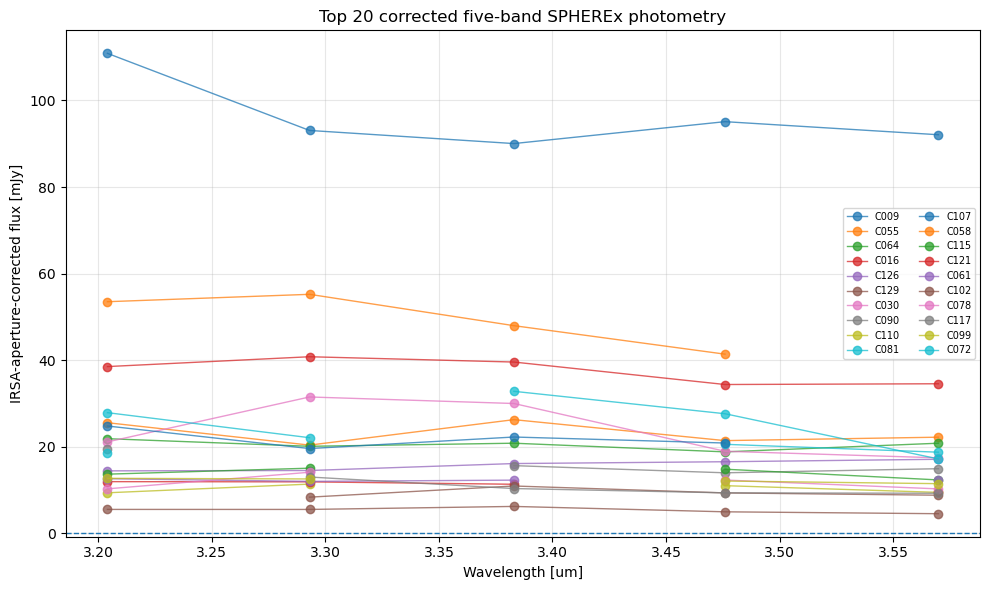

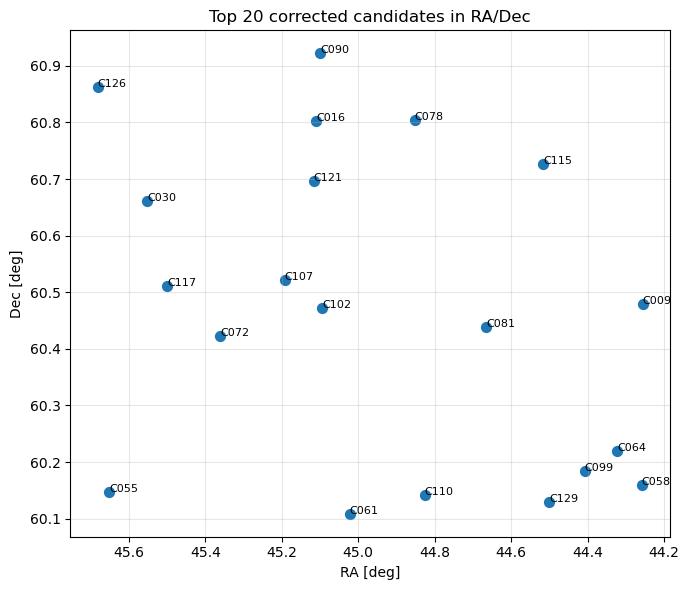

SEND PACKAGE CREATED:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\new_coordinates_send_package.zip

Files in send package folder:
  email_summary_to_dr_hora.txt
  new_coordinates_corrected.zip
  one_page_summary_new_coordinates_corrected.txt
  top20_candidate_sky_map.png
  top20_corrected_candidate_table.csv
  top20_corrected_flux_plot.png

Recommended file to send:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\new_coordinates_send_package.zip


In [11]:
# ============================================================
# FINAL EXTRA DELIVERABLES — CLEAN SUMMARY PACKAGE FOR DR. HORA
# ============================================================

from pathlib import Path
import shutil
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

CORR_DIR = FIELD / "new_coordinates_corrected"
OUT_DIR = FIELD / "new_coordinates_send_package"

ZIP_MAIN = FIELD / "new_coordinates_corrected.zip"
ZIP_SEND = FIELD / "new_coordinates_send_package.zip"

SHORTLIST = CORR_DIR / "ra45_dec60p5_final_shortlist_IRSA_apcorr.csv"
LONG_PHOT = CORR_DIR / "ra45_dec60p5_final_shortlist_5band_photometry_IRSA_apcorr.csv"
APCORR = CORR_DIR / "ra45_dec60p5_aperture_correction_summary.csv"

if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

if ZIP_SEND.exists():
    ZIP_SEND.unlink()

# ----------------------------
# Load corrected results
# ----------------------------
short = pd.read_csv(SHORTLIST)
long = pd.read_csv(LONG_PHOT)
apcorr = pd.read_csv(APCORR)

factor = float(apcorr.loc[0, "aperture_correction_factor_irsa_over_local"])
scatter = float(apcorr.loc[0, "robust_scatter"])
nratios = int(apcorr.loc[0, "n_final_ratios"])

# ----------------------------
# 1. Top corrected candidate table
# ----------------------------
top_cols = [
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "median_flux_mjy_corrected",
    "max_flux_mjy_corrected",
    "min_flux_mjy_corrected",
    "positive_flux_count_5",
    "snr5_count_5",
    "max_snr_local",
    "fractional_scatter_5band",
    "review_class",
    "artifact_notes",
]

top_cols = [c for c in top_cols if c in short.columns]

TOP_CSV = OUT_DIR / "top20_corrected_candidate_table.csv"
short[top_cols].to_csv(TOP_CSV, index=False)

# ----------------------------
# 2. One-page summary text
# ----------------------------
SUMMARY_TXT = OUT_DIR / "one_page_summary_new_coordinates_corrected.txt"

summary_text = f"""SPHEREx/WISE New Coordinate Field Summary

Field:
RA = 45.0 deg
Dec = 60.5 deg

Final package:
new_coordinates_corrected.zip

Main result:
A corrected first-pass SPHEREx/WISE screening candidate package was generated for the new field. This is not a claim of confirmed variability; it is a filtered, IRSA-aperture-corrected screening product.

Workflow completed:
1. Generated a new SPHEREx mosaic cube centered at RA=45.0, Dec=60.5.
2. Used the 3.20-3.58 um wavelength range.
3. Confirmed five SPHEREx planes:
   3.204, 3.293, 3.383, 3.476, 3.570 um.
4. Downloaded AllWISE W1 for the same field.
5. Reprojected WISE W1 onto the SPHEREx grid.
6. Checked astrometric alignment:
   median dx = 0.011 pix
   median dy = 0.022 pix
   no shift correction applied.
7. Empirically scaled WISE W1 to SPHEREx plane 2:
   SPHEREx 3.383 um ≈ 0.0445266 * WISE W1.
8. Tested PSF smoothing from sigma=0.00 to 2.00 pixels.
   Best sigma = 0.00 pix, meaning no additional smoothing improved the subtraction.
9. Detected positive residual candidates from:
   SPHEREx 3.383 um - scaled/PSF-tested WISE W1.
10. Performed five-band local SPHEREx aperture photometry using:
   Photutils circular aperture radius = 3 pixels
   local background annulus = 5-8 pixels
   MJy/sr to mJy conversion using pixel solid angle.
11. Applied nearby-wavelength persistence and artifact-review filtering.
12. Ran IRSA Band 4 calibration on 10 isolated calibration sources.
13. Parsed IRSA XML/VOTable outputs.
14. Derived aperture correction:
   IRSA/local aperture = {factor:.6f}
   robust scatter = {scatter:.6f}
   usable calibration ratios = {nratios}
15. Applied this correction to the final candidate photometry.

Final corrected shortlist count:
{len(short)}

Most important files:
- new_coordinates_corrected.zip
- top20_corrected_candidate_table.csv
- top20_corrected_flux_plot.png
- top20_candidate_sky_map.png

Limitations:
- Candidates are screening candidates, not confirmed variables.
- WISE W1 is broad while SPHEREx channels are narrower, so color terms may still matter.
- Local background/nebulosity and bright-source residuals may still affect individual candidates.
"""

SUMMARY_TXT.write_text(summary_text, encoding="utf-8")

# ----------------------------
# 3. Email summary text
# ----------------------------
EMAIL_TXT = OUT_DIR / "email_summary_to_dr_hora.txt"

email_text = f"""I also completed the IRSA aperture-correction calibration for the RA=45.0, Dec=60.5 field. I selected 10 isolated calibration sources, ran the SPHEREx Spectrophotometry Tool in Band 4 only, parsed the XML/VOTable outputs, and compared the IRSA fluxes against my local 3-pixel aperture / 5-8 pixel annulus photometry. The derived aperture correction factor was IRSA/local = {factor:.6f}, with robust scatter {scatter:.6f} from {nratios} usable calibration ratios. I applied this correction to the final candidate shortlist, and the updated deliverable is in new_coordinates_corrected.zip. I also included a one-page summary, corrected top-candidate table, flux plot, and sky-position map in the send package. These are still first-pass screening candidates rather than confirmed variables.
"""

EMAIL_TXT.write_text(email_text, encoding="utf-8")

# ----------------------------
# 4. Corrected flux plot for top 20
# ----------------------------
PLOT_FLUX = OUT_DIR / "top20_corrected_flux_plot.png"

top_ids = short["candidate_id"].head(20).tolist()
plot_df = long[long["candidate_id"].isin(top_ids)].copy()

plt.figure(figsize=(10, 6))

for cid in top_ids:
    g = plot_df[plot_df["candidate_id"] == cid].sort_values("wavelength_um")
    if len(g) == 0:
        continue
    plt.plot(
        g["wavelength_um"],
        g["flux_mjy_corrected"],
        marker="o",
        linewidth=1,
        alpha=0.75,
        label=cid.replace("RA45_CAND_", "C")
    )

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Wavelength [um]")
plt.ylabel("IRSA-aperture-corrected flux [mJy]")
plt.title("Top 20 corrected five-band SPHEREx photometry")
plt.grid(True, alpha=0.3)
plt.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(PLOT_FLUX, dpi=200)
plt.show()

# ----------------------------
# 5. Candidate sky map
# ----------------------------
PLOT_SKY = OUT_DIR / "top20_candidate_sky_map.png"

plt.figure(figsize=(7, 6))
plt.scatter(short["ra_deg"].head(20), short["dec_deg"].head(20), s=50)

for _, row in short.head(20).iterrows():
    label = row["candidate_id"].replace("RA45_CAND_", "C")
    plt.text(row["ra_deg"], row["dec_deg"], label, fontsize=8)

plt.gca().invert_xaxis()
plt.xlabel("RA [deg]")
plt.ylabel("Dec [deg]")
plt.title("Top 20 corrected candidates in RA/Dec")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_SKY, dpi=200)
plt.show()

# ----------------------------
# 6. Copy main corrected ZIP
# ----------------------------
if ZIP_MAIN.exists():
    shutil.copy2(ZIP_MAIN, OUT_DIR / ZIP_MAIN.name)
else:
    print("WARNING: main corrected zip missing:", ZIP_MAIN)

# ----------------------------
# 7. Make send package ZIP
# ----------------------------
with zipfile.ZipFile(ZIP_SEND, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT_DIR.rglob("*"):
        z.write(p, arcname=p.relative_to(OUT_DIR.parent))

print("SEND PACKAGE CREATED:")
print(ZIP_SEND)

print("\nFiles in send package folder:")
for p in sorted(OUT_DIR.rglob("*")):
    print(" ", p.relative_to(OUT_DIR))

print("\nRecommended file to send:")
print(ZIP_SEND)

Using residual FITS:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\new_coordinates_corrected\spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits

Using candidate table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\new_coordinates_corrected\ra45_dec60p5_full_candidate_review_table.csv

Residual image shape: (581, 581)
Finite residual pixels: 333471

Residual pixel statistics:
sigma-clipped mean: 0.04830686379709396
sigma-clipped median: 0.026797056198120117
sigma-clipped std: 0.1005589333102502
MAD robust sigma: 0.10909693612757591

Positive residual thresholds:
3sigma: 0.35408786458084784
5sigma: 0.5722817368359997
10sigma: 1.1177664174738793
20sigma: 2.2087357787496384


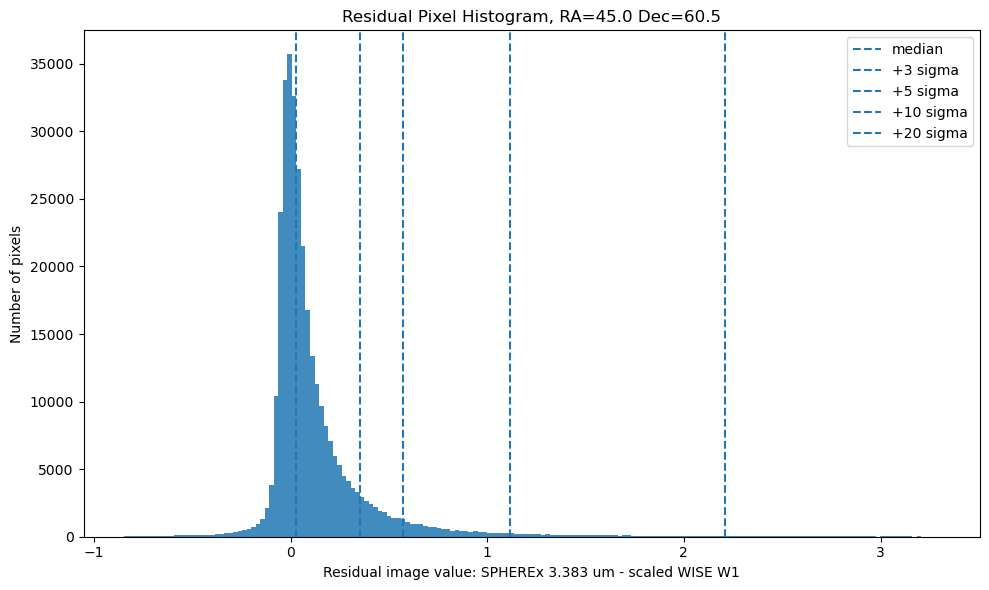

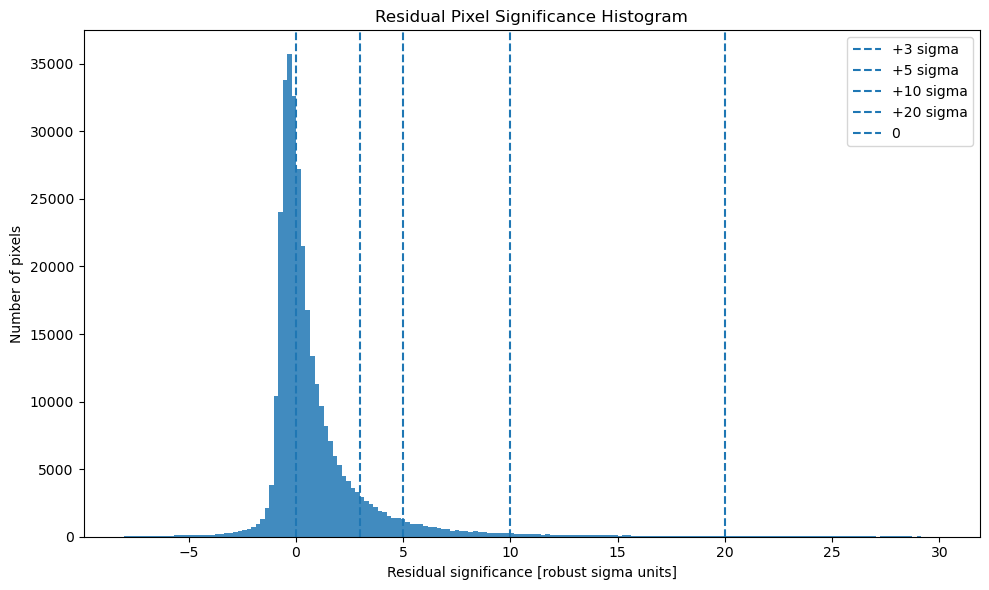


Candidate table columns:
['candidate_id', 'ra_deg', 'dec_deg', 'x_pix', 'y_pix', 'positive_flux_count_5', 'snr3_count_5', 'snr5_count_5', 'median_flux_mjy', 'max_flux_mjy', 'min_flux_mjy', 'max_snr_local', 'fractional_scatter_5band', 'residual_diff_snr_peak', 'sharp_ratio_peak_over_5x5med', 'persistent_3plus_positive', 'persistent_3plus_snr3', 'persistent_3plus_snr5', 'screening_label', 'priority_score', 'artifact_notes', 'review_class']


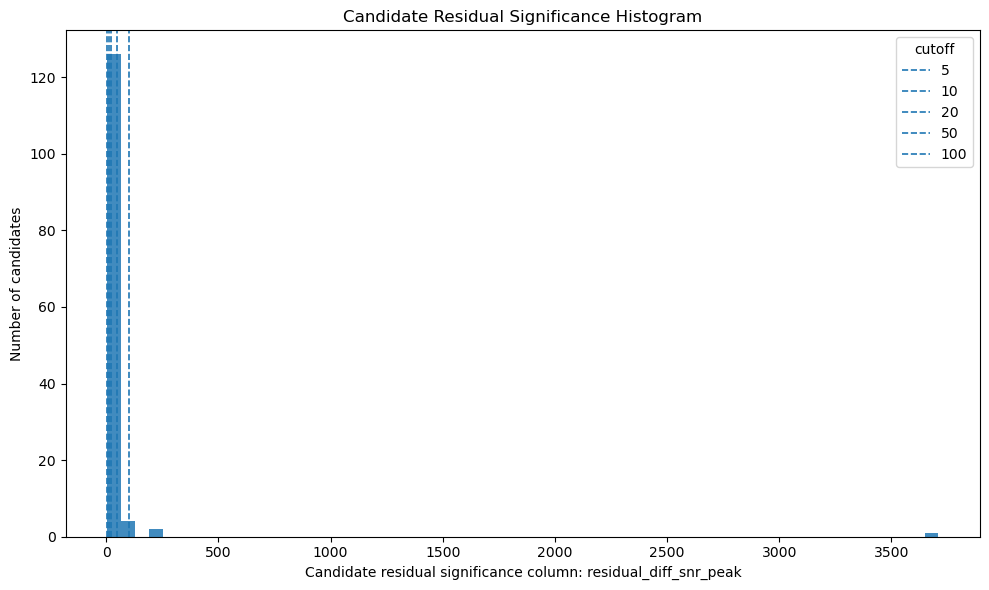


Candidate counts above residual-SNR cutoffs:


,candidate_residual_snr_cutoff,n_candidates_above_cutoff,fraction_candidates_above_cutoff
0,3,133,1.000000
1,5,133,1.000000
2,10,89,0.669173
3,20,40,0.300752
4,30,18,0.135338
5,50,8,0.060150
6,80,6,0.045113
7,100,6,0.045113



Saved outputs:
  ra45_dec60p5_candidate_residual_snr_cutoff_counts.csv
  ra45_dec60p5_candidate_residual_snr_histogram.png
  ra45_dec60p5_residual_histogram_statistics.csv
  ra45_dec60p5_residual_pixel_histogram.png
  ra45_dec60p5_residual_pixel_snr_histogram.png
  ra45_dec60p5_residual_snr_image.fits


In [1]:
# ============================================================
# HISTOGRAM OF SPHEREx - WISE RESIDUALS FOR DR. HORA
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clipped_stats, mad_std

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

# Prefer corrected package copy, fallback to psf_tuning folder
RESIDUAL_FITS_OPTIONS = [
    FIELD / "new_coordinates_corrected" / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits",
    FIELD / "psf_tuning" / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits",
    FIELD / "photometric_scaling" / "spherex_plane2_minus_scaled_wise_w1.fits",
]

CANDIDATE_TABLE_OPTIONS = [
    FIELD / "new_coordinates_corrected" / "ra45_dec60p5_full_candidate_review_table.csv",
    FIELD / "final_review" / "ra45_dec60p5_candidate_review_table.csv",
    FIELD / "candidate_detection" / "ra45_dec60p5_plane2_positive_residual_candidates.csv",
]

OUT_DIR = FIELD / "residual_histogram_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Locate files
# ------------------------------------------------------------
RESIDUAL_FITS = None
for p in RESIDUAL_FITS_OPTIONS:
    if p.exists():
        RESIDUAL_FITS = p
        break

if RESIDUAL_FITS is None:
    raise FileNotFoundError("Could not find residual FITS image in expected locations.")

CANDIDATE_TABLE = None
for p in CANDIDATE_TABLE_OPTIONS:
    if p.exists():
        CANDIDATE_TABLE = p
        break

if CANDIDATE_TABLE is None:
    raise FileNotFoundError("Could not find candidate table in expected locations.")

print("Using residual FITS:")
print(RESIDUAL_FITS)

print("\nUsing candidate table:")
print(CANDIDATE_TABLE)

# ------------------------------------------------------------
# Load residual image
# ------------------------------------------------------------
with fits.open(RESIDUAL_FITS) as hdul:
    resid = hdul[0].data.astype(float)
    hdr = hdul[0].header

finite = np.isfinite(resid)
vals = resid[finite]

print("\nResidual image shape:", resid.shape)
print("Finite residual pixels:", vals.size)

# ------------------------------------------------------------
# Robust residual statistics
# ------------------------------------------------------------
mean_clip, median_clip, std_clip = sigma_clipped_stats(vals, sigma=3.0, maxiters=10)
mad_sigma = mad_std(vals, ignore_nan=True)

# Use MAD-based sigma as robust sigma
robust_sigma = float(mad_sigma)
robust_center = float(median_clip)

print("\nResidual pixel statistics:")
print("sigma-clipped mean:", mean_clip)
print("sigma-clipped median:", median_clip)
print("sigma-clipped std:", std_clip)
print("MAD robust sigma:", robust_sigma)

# Thresholds in image units
thresholds = {
    "3sigma": robust_center + 3 * robust_sigma,
    "5sigma": robust_center + 5 * robust_sigma,
    "10sigma": robust_center + 10 * robust_sigma,
    "20sigma": robust_center + 20 * robust_sigma,
}

print("\nPositive residual thresholds:")
for k, v in thresholds.items():
    print(f"{k}: {v}")

# Save stats
stats_df = pd.DataFrame([{
    "residual_fits": str(RESIDUAL_FITS),
    "n_finite_pixels": int(vals.size),
    "sigma_clipped_mean": float(mean_clip),
    "sigma_clipped_median": float(median_clip),
    "sigma_clipped_std": float(std_clip),
    "mad_robust_sigma": float(robust_sigma),
    "threshold_3sigma": float(thresholds["3sigma"]),
    "threshold_5sigma": float(thresholds["5sigma"]),
    "threshold_10sigma": float(thresholds["10sigma"]),
    "threshold_20sigma": float(thresholds["20sigma"]),
}])

STATS_CSV = OUT_DIR / "ra45_dec60p5_residual_histogram_statistics.csv"
stats_df.to_csv(STATS_CSV, index=False)

# ------------------------------------------------------------
# Pixel residual histogram
# ------------------------------------------------------------
# Trim display range so huge artifacts do not crush the main histogram
lo = robust_center - 8 * robust_sigma
hi = robust_center + 30 * robust_sigma
vals_plot = vals[(vals >= lo) & (vals <= hi)]

PLOT_PIXEL_HIST = OUT_DIR / "ra45_dec60p5_residual_pixel_histogram.png"

plt.figure(figsize=(10, 6))
plt.hist(vals_plot, bins=180, alpha=0.85)
plt.axvline(robust_center, linestyle="--", linewidth=1.5, label="median")
plt.axvline(thresholds["3sigma"], linestyle="--", linewidth=1.5, label="+3 sigma")
plt.axvline(thresholds["5sigma"], linestyle="--", linewidth=1.5, label="+5 sigma")
plt.axvline(thresholds["10sigma"], linestyle="--", linewidth=1.5, label="+10 sigma")
plt.axvline(thresholds["20sigma"], linestyle="--", linewidth=1.5, label="+20 sigma")
plt.xlabel("Residual image value: SPHEREx 3.383 um - scaled WISE W1")
plt.ylabel("Number of pixels")
plt.title("Residual Pixel Histogram, RA=45.0 Dec=60.5")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_PIXEL_HIST, dpi=200)
plt.show()

# ------------------------------------------------------------
# Residual SNR map and histogram
# ------------------------------------------------------------
snr_img = (resid - robust_center) / robust_sigma
snr_vals = snr_img[np.isfinite(snr_img)]

snr_plot_vals = snr_vals[(snr_vals >= -8) & (snr_vals <= 30)]

PLOT_SNR_HIST = OUT_DIR / "ra45_dec60p5_residual_pixel_snr_histogram.png"

plt.figure(figsize=(10, 6))
plt.hist(snr_plot_vals, bins=180, alpha=0.85)
for sig in [3, 5, 10, 20]:
    plt.axvline(sig, linestyle="--", linewidth=1.5, label=f"+{sig} sigma")
plt.axvline(0, linestyle="--", linewidth=1.5, label="0")
plt.xlabel("Residual significance [robust sigma units]")
plt.ylabel("Number of pixels")
plt.title("Residual Pixel Significance Histogram")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_SNR_HIST, dpi=200)
plt.show()

# ------------------------------------------------------------
# Candidate-level histogram
# ------------------------------------------------------------
cand = pd.read_csv(CANDIDATE_TABLE)

print("\nCandidate table columns:")
print(list(cand.columns))

# Pick best available residual significance column
possible_snr_cols = [
    "residual_diff_snr_peak",
    "diff_snr_peak",
    "snr",
    "peak_snr",
    "max_snr_local",
]

snr_col = None
for c in possible_snr_cols:
    if c in cand.columns:
        snr_col = c
        break

if snr_col is None:
    print("\nWARNING: No candidate residual SNR column found. Candidate histogram skipped.")
else:
    cand_snr = cand[snr_col].replace([np.inf, -np.inf], np.nan).dropna()

    PLOT_CAND_HIST = OUT_DIR / "ra45_dec60p5_candidate_residual_snr_histogram.png"

    plt.figure(figsize=(10, 6))
    plt.hist(cand_snr, bins=60, alpha=0.85)
    for sig in [5, 10, 20, 50, 100]:
        plt.axvline(sig, linestyle="--", linewidth=1.2, label=f"{sig}")
    plt.xlabel(f"Candidate residual significance column: {snr_col}")
    plt.ylabel("Number of candidates")
    plt.title("Candidate Residual Significance Histogram")
    plt.legend(title="cutoff")
    plt.tight_layout()
    plt.savefig(PLOT_CAND_HIST, dpi=200)
    plt.show()

    # Counts above thresholds
    cutoff_rows = []
    for sig in [3, 5, 10, 20, 30, 50, 80, 100]:
        cutoff_rows.append({
            "candidate_residual_snr_cutoff": sig,
            "n_candidates_above_cutoff": int((cand_snr >= sig).sum()),
            "fraction_candidates_above_cutoff": float((cand_snr >= sig).mean()),
        })

    cutoff_df = pd.DataFrame(cutoff_rows)
    CUTOFF_CSV = OUT_DIR / "ra45_dec60p5_candidate_residual_snr_cutoff_counts.csv"
    cutoff_df.to_csv(CUTOFF_CSV, index=False)

    print("\nCandidate counts above residual-SNR cutoffs:")
    display(cutoff_df)

# ------------------------------------------------------------
# Save residual SNR FITS too
# ------------------------------------------------------------
SNR_FITS = OUT_DIR / "ra45_dec60p5_residual_snr_image.fits"

hdu = fits.PrimaryHDU(snr_img.astype(np.float32), header=hdr)
hdu.header["HISTORY"] = "Residual SNR image = (residual - robust median) / MAD robust sigma"
hdu.header["ROBMED"] = robust_center
hdu.header["ROBSIG"] = robust_sigma
hdu.writeto(SNR_FITS, overwrite=True)

print("\nSaved outputs:")
for p in sorted(OUT_DIR.glob("*")):
    print(" ", p.name)

Total raw candidates: 133
Corrected shortlist candidates: 20

Residual SNR summary:
count     133.000000
mean       49.391287
std       321.309491
min         5.310907
25%         8.835649
50%        12.907076
75%        22.833669
max      3709.687855
Name: residual_diff_snr_peak, dtype: float64


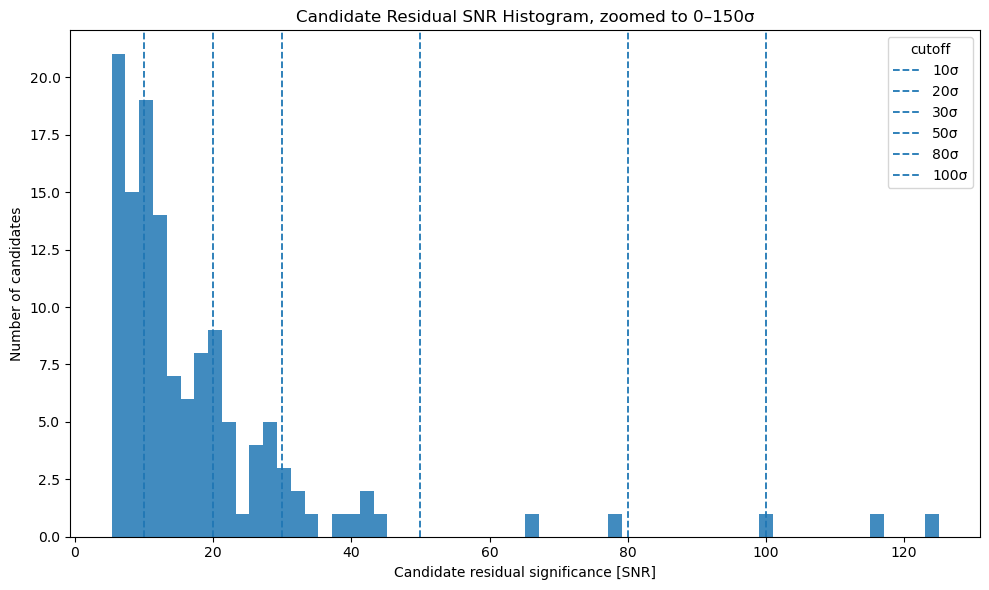

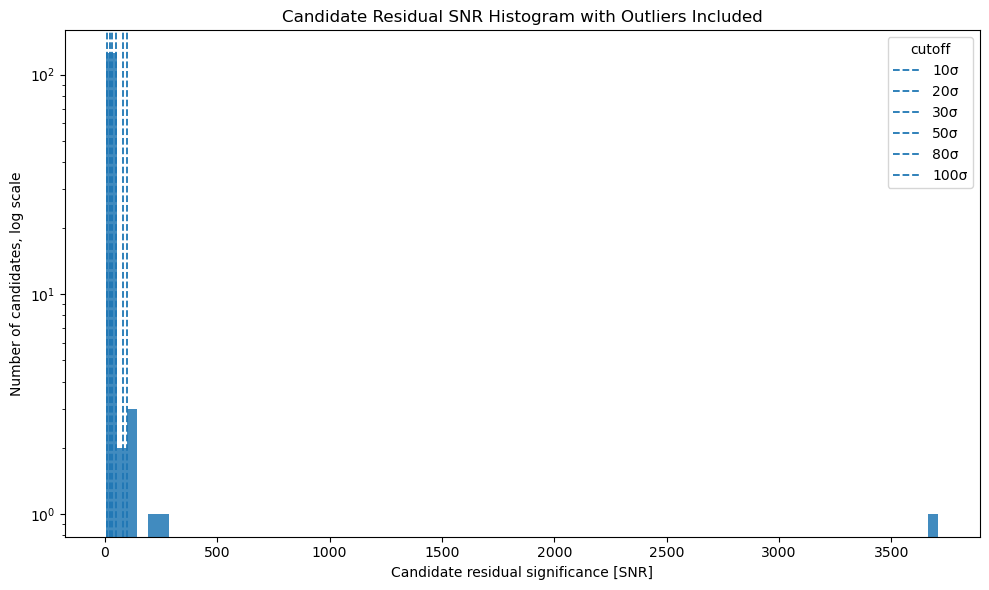


Cutoff summary:


,residual_snr_cutoff,n_raw_candidates_above_cutoff,n_in_corrected_shortlist_above_cutoff,n_best_first_pass_above_cutoff,n_clean_first_pass_above_cutoff
0,5,133,20,46,74
1,10,89,10,19,37
2,20,40,3,5,9
3,30,18,2,3,3
4,50,8,0,0,0
5,80,6,0,0,0
6,100,6,0,0,0



Candidates above 20σ: 40


,candidate_id,ra_deg,dec_deg,positive_flux_count_5,snr5_count_5,median_flux_mjy,max_snr_local,fractional_scatter_5band,residual_diff_snr_peak,review_class,artifact_notes,in_corrected_shortlist
127,RA45_CAND_001,45.570024,60.894257,0,0,NaN,NaN,NaN,3709.687855,not top priority,very strong residual / possible bright-source ...,False
35,RA45_CAND_002,44.974340,60.434161,3,3,250.211474,1330.253973,0.034910,240.445261,CHECK VISUALLY - possible artifact,very strong residual / possible bright-source ...,False
128,RA45_CAND_003,45.833517,60.467196,0,0,NaN,NaN,NaN,207.752054,not top priority,very strong residual / possible bright-source ...,False
18,RA45_CAND_004,45.235821,60.670108,4,4,196.100551,60.276583,0.680520,124.983036,CHECK VISUALLY - possible artifact,large 5-band scatter; very strong residual / p...,False
94,RA45_CAND_005,44.386114,60.754139,2,2,191.588327,82.398034,0.097822,115.847692,not top priority,very strong residual / possible bright-source ...,False
59,RA45_CAND_006,45.754432,60.469306,3,3,349.287783,23.056849,0.567906,100.277567,CHECK VISUALLY - possible artifact,large 5-band scatter; very strong residual / p...,False
11,RA45_CAND_007,44.552823,60.637011,4,4,107.489580,331.877196,0.149313,77.463783,GOOD BUT CHECK,weird sharpness/background,False
129,RA45_CAND_008,45.265855,60.539316,0,0,NaN,NaN,NaN,65.328090,not top priority,sharpness undefined,False
1,RA45_CAND_009,44.255910,60.478930,5,5,105.675742,369.705638,0.080594,45.178040,BEST FIRST-PASS,clean first-pass,True
31,RA45_CAND_010,44.349249,60.659753,4,4,64.226618,8.594511,0.593813,42.998854,CHECK VISUALLY - possible artifact,large 5-band scatter,False



Candidates above 30σ: 18


,candidate_id,ra_deg,dec_deg,positive_flux_count_5,snr5_count_5,median_flux_mjy,max_snr_local,fractional_scatter_5band,residual_diff_snr_peak,review_class,artifact_notes,in_corrected_shortlist
127,RA45_CAND_001,45.570024,60.894257,0,0,NaN,NaN,NaN,3709.687855,not top priority,very strong residual / possible bright-source ...,False
35,RA45_CAND_002,44.974340,60.434161,3,3,250.211474,1330.253973,0.034910,240.445261,CHECK VISUALLY - possible artifact,very strong residual / possible bright-source ...,False
128,RA45_CAND_003,45.833517,60.467196,0,0,NaN,NaN,NaN,207.752054,not top priority,very strong residual / possible bright-source ...,False
18,RA45_CAND_004,45.235821,60.670108,4,4,196.100551,60.276583,0.680520,124.983036,CHECK VISUALLY - possible artifact,large 5-band scatter; very strong residual / p...,False
94,RA45_CAND_005,44.386114,60.754139,2,2,191.588327,82.398034,0.097822,115.847692,not top priority,very strong residual / possible bright-source ...,False
59,RA45_CAND_006,45.754432,60.469306,3,3,349.287783,23.056849,0.567906,100.277567,CHECK VISUALLY - possible artifact,large 5-band scatter; very strong residual / p...,False
11,RA45_CAND_007,44.552823,60.637011,4,4,107.489580,331.877196,0.149313,77.463783,GOOD BUT CHECK,weird sharpness/background,False
129,RA45_CAND_008,45.265855,60.539316,0,0,NaN,NaN,NaN,65.328090,not top priority,sharpness undefined,False
1,RA45_CAND_009,44.255910,60.478930,5,5,105.675742,369.705638,0.080594,45.178040,BEST FIRST-PASS,clean first-pass,True
31,RA45_CAND_010,44.349249,60.659753,4,4,64.226618,8.594511,0.593813,42.998854,CHECK VISUALLY - possible artifact,large 5-band scatter,False



Candidates above 50σ: 8


,candidate_id,ra_deg,dec_deg,positive_flux_count_5,snr5_count_5,median_flux_mjy,max_snr_local,fractional_scatter_5band,residual_diff_snr_peak,review_class,artifact_notes,in_corrected_shortlist
127,RA45_CAND_001,45.570024,60.894257,0,0,NaN,NaN,NaN,3709.687855,not top priority,very strong residual / possible bright-source ...,False
35,RA45_CAND_002,44.974340,60.434161,3,3,250.211474,1330.253973,0.034910,240.445261,CHECK VISUALLY - possible artifact,very strong residual / possible bright-source ...,False
128,RA45_CAND_003,45.833517,60.467196,0,0,NaN,NaN,NaN,207.752054,not top priority,very strong residual / possible bright-source ...,False
18,RA45_CAND_004,45.235821,60.670108,4,4,196.100551,60.276583,0.680520,124.983036,CHECK VISUALLY - possible artifact,large 5-band scatter; very strong residual / p...,False
94,RA45_CAND_005,44.386114,60.754139,2,2,191.588327,82.398034,0.097822,115.847692,not top priority,very strong residual / possible bright-source ...,False
59,RA45_CAND_006,45.754432,60.469306,3,3,349.287783,23.056849,0.567906,100.277567,CHECK VISUALLY - possible artifact,large 5-band scatter; very strong residual / p...,False
11,RA45_CAND_007,44.552823,60.637011,4,4,107.489580,331.877196,0.149313,77.463783,GOOD BUT CHECK,weird sharpness/background,False
129,RA45_CAND_008,45.265855,60.539316,0,0,NaN,NaN,NaN,65.328090,not top priority,sharpness undefined,False



Saved outputs:
  ra45_dec60p5_candidate_cutoff_summary_with_shortlist.csv
  ra45_dec60p5_candidate_residual_snr_cutoff_counts.csv
  ra45_dec60p5_candidate_residual_snr_histogram.png
  ra45_dec60p5_candidate_residual_snr_histogram_clean_0_150.png
  ra45_dec60p5_candidate_residual_snr_histogram_logscale.png
  ra45_dec60p5_candidates_above_20sigma.csv
  ra45_dec60p5_candidates_above_30sigma.csv
  ra45_dec60p5_candidates_above_50sigma.csv


In [2]:
# ============================================================
# NEXT HISTOGRAM STEP — CLEAN CANDIDATE CUTOFF ANALYSIS
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

CORR_DIR = FIELD / "new_coordinates_corrected"
OUT_DIR = FIELD / "residual_histogram_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CAND_TABLE = CORR_DIR / "ra45_dec60p5_full_candidate_review_table.csv"
SHORTLIST = CORR_DIR / "ra45_dec60p5_final_shortlist_IRSA_apcorr.csv"

cand = pd.read_csv(CAND_TABLE)
short = pd.read_csv(SHORTLIST)

snr_col = "residual_diff_snr_peak"

if snr_col not in cand.columns:
    raise KeyError(f"Missing column: {snr_col}")

print("Total raw candidates:", len(cand))
print("Corrected shortlist candidates:", len(short))

# ------------------------------------------------------------
# Add whether candidate is in corrected final shortlist
# ------------------------------------------------------------
short_ids = set(short["candidate_id"])
cand["in_corrected_shortlist"] = cand["candidate_id"].isin(short_ids)

# ------------------------------------------------------------
# Clean display histogram excluding extreme outlier region
# ------------------------------------------------------------
snr = cand[snr_col].replace([np.inf, -np.inf], np.nan).dropna()

print("\nResidual SNR summary:")
print(snr.describe())

PLOT_CLEAN = OUT_DIR / "ra45_dec60p5_candidate_residual_snr_histogram_clean_0_150.png"

plt.figure(figsize=(10, 6))
plt.hist(snr[snr <= 150], bins=60, alpha=0.85)

for cutoff in [10, 20, 30, 50, 80, 100]:
    plt.axvline(cutoff, linestyle="--", linewidth=1.3, label=f"{cutoff}σ")

plt.xlabel("Candidate residual significance [SNR]")
plt.ylabel("Number of candidates")
plt.title("Candidate Residual SNR Histogram, zoomed to 0–150σ")
plt.legend(title="cutoff")
plt.tight_layout()
plt.savefig(PLOT_CLEAN, dpi=200)
plt.show()

# ------------------------------------------------------------
# Log-scale version including outliers
# ------------------------------------------------------------
PLOT_LOG = OUT_DIR / "ra45_dec60p5_candidate_residual_snr_histogram_logscale.png"

plt.figure(figsize=(10, 6))
plt.hist(snr, bins=80, alpha=0.85)
plt.yscale("log")

for cutoff in [10, 20, 30, 50, 80, 100]:
    plt.axvline(cutoff, linestyle="--", linewidth=1.3, label=f"{cutoff}σ")

plt.xlabel("Candidate residual significance [SNR]")
plt.ylabel("Number of candidates, log scale")
plt.title("Candidate Residual SNR Histogram with Outliers Included")
plt.legend(title="cutoff")
plt.tight_layout()
plt.savefig(PLOT_LOG, dpi=200)
plt.show()

# ------------------------------------------------------------
# Cutoff table with shortlist/review-class info
# ------------------------------------------------------------
rows = []

for cutoff in [5, 10, 20, 30, 50, 80, 100]:
    above = cand[cand[snr_col] >= cutoff].copy()

    rows.append({
        "residual_snr_cutoff": cutoff,
        "n_raw_candidates_above_cutoff": len(above),
        "n_in_corrected_shortlist_above_cutoff": int(above["in_corrected_shortlist"].sum()),
        "n_best_first_pass_above_cutoff": int((above["review_class"] == "BEST FIRST-PASS").sum()) if "review_class" in above.columns else np.nan,
        "n_clean_first_pass_above_cutoff": int(above["artifact_notes"].astype(str).str.contains("clean", case=False, na=False).sum()) if "artifact_notes" in above.columns else np.nan,
    })

cutoff_summary = pd.DataFrame(rows)

OUT_CUTOFF = OUT_DIR / "ra45_dec60p5_candidate_cutoff_summary_with_shortlist.csv"
cutoff_summary.to_csv(OUT_CUTOFF, index=False)

print("\nCutoff summary:")
display(cutoff_summary)

# ------------------------------------------------------------
# Make high-confidence candidate tables at different cutoffs
# ------------------------------------------------------------
for cutoff in [20, 30, 50]:
    selected = cand[cand[snr_col] >= cutoff].copy()
    selected = selected.sort_values(snr_col, ascending=False)

    out_csv = OUT_DIR / f"ra45_dec60p5_candidates_above_{cutoff}sigma.csv"
    selected.to_csv(out_csv, index=False)

    print(f"\nCandidates above {cutoff}σ:", len(selected))
    display(selected[[
        "candidate_id",
        "ra_deg",
        "dec_deg",
        "positive_flux_count_5",
        "snr5_count_5",
        "median_flux_mjy",
        "max_snr_local",
        "fractional_scatter_5band",
        "residual_diff_snr_peak",
        "review_class",
        "artifact_notes",
        "in_corrected_shortlist",
    ]].head(25))

print("\nSaved outputs:")
for p in sorted(OUT_DIR.glob("*candidate*")):
    print(" ", p.name)

Using scaled WISE image:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\psf_tuning\wise_w1_scaled_psf_tuned_to_spherex_plane2.fits
SPHEREx plane2 shape: (581, 581)
Scaled WISE shape: (581, 581)
Aperture correction factor: 0.8807596991068787

Saved brightness ratio table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\brightness_ratio_analysis\ra45_dec60p5_spherex_over_wise_brightness_ratios.csv

Ratio summary:
count    70.000000
mean      1.259529
std       0.533330
min       0.718565
25%       0.890260
50%       0.984104
75%       1.501458
max       2.833098
Name: spherex_over_wise_expected_ratio, dtype: float64

Counts:
Total candidates: 133
Candidates with finite ratio: 70
Candidates with >=2x SPHEREx/WISE ratio: 10
>=2x and in corrected shortlist: 0
>=2x and BEST FIRST-PASS: 0


,candidate_id,ra_deg,dec_deg,spherex_plane2_flux_mjy_corrected,wise_expected_plane2_flux_mjy,spherex_over_wise_expected_ratio,residual_diff_snr_peak,positive_flux_count_5,snr5_count_5,fractional_scatter_5band,review_class,artifact_notes,in_corrected_shortlist,brightness_2x_or_higher
66,RA45_CAND_025,44.292920,60.638851,29.764998,10.506168,2.833098,26.922693,5,0,0.705483,not top priority,large 5-band scatter,False,True
68,RA45_CAND_056,45.456623,60.533816,18.705159,7.176722,2.606365,16.459213,4,1,0.344714,not top priority,clean first-pass,False,True
76,RA45_CAND_023,44.371296,60.669621,30.632026,12.127782,2.525773,27.596769,5,0,0.542444,not top priority,large 5-band scatter,False,True
64,RA45_CAND_095,44.415533,60.776965,10.082966,4.034613,2.499116,9.497089,5,0,0.631003,not top priority,large 5-band scatter,False,True
65,RA45_CAND_049,45.359907,60.507948,32.340703,13.527066,2.390814,17.978700,5,0,0.526084,not top priority,large 5-band scatter,False,True
81,RA45_CAND_040,45.442010,60.525571,8.913428,3.777837,2.359399,20.122112,4,0,0.451955,not top priority,large 5-band scatter,False,True
84,RA45_CAND_051,44.351167,60.767827,16.784073,7.366482,2.278438,17.477290,3,0,1.293834,not top priority,large 5-band scatter,False,True
71,RA45_CAND_057,45.482046,60.677304,13.447817,6.230605,2.158349,15.731563,4,0,0.453769,not top priority,large 5-band scatter,False,True
72,RA45_CAND_036,44.339680,60.626923,49.031142,22.969225,2.134645,20.800982,4,0,0.448753,not top priority,large 5-band scatter,False,True
113,RA45_CAND_024,44.208855,60.745910,33.900471,15.934097,2.127543,27.490675,2,1,0.560749,not top priority,large 5-band scatter,False,True


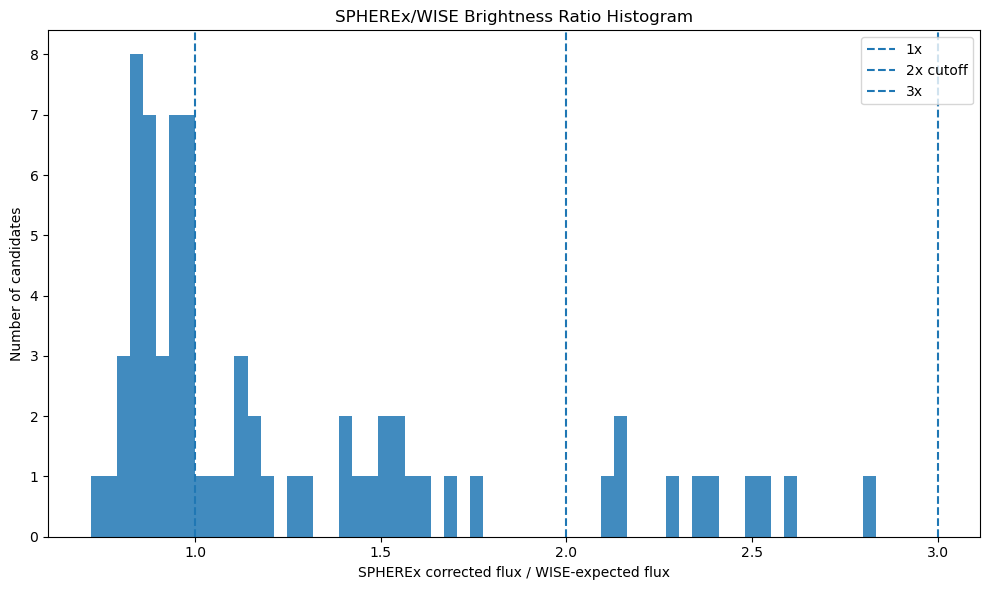


Saved strong >=2x table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\brightness_ratio_analysis\ra45_dec60p5_strong_2x_brightness_candidates.csv

Strong >=2x candidates after persistence cuts:
0


,candidate_id,ra_deg,dec_deg,spherex_over_wise_expected_ratio,spherex_plane2_flux_mjy_corrected,wise_expected_plane2_flux_mjy,residual_diff_snr_peak,positive_flux_count_5,snr5_count_5,fractional_scatter_5band,review_class,artifact_notes,in_corrected_shortlist



Saved outputs:
  ra45_dec60p5_spherex_over_wise_brightness_ratios.csv
  ra45_dec60p5_spherex_over_wise_ratio_histogram.png
  ra45_dec60p5_strong_2x_brightness_candidates.csv


In [3]:
# ============================================================
# NEXT STEP — COMPUTE SPHEREx / WISE BRIGHTNESS RATIO FOR CANDIDATES
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

CORR_DIR = FIELD / "new_coordinates_corrected"
OUT_DIR = FIELD / "brightness_ratio_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CUBE_PATH = FIELD / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"

# Scaled WISE image from PSF tuning/corrected package
SCALED_WISE_OPTIONS = [
    FIELD / "psf_tuning" / "wise_w1_scaled_psf_tuned_to_spherex_plane2.fits",
    FIELD / "photometric_scaling" / "wise_w1_scaled_to_spherex_plane2.fits",
]

CAND_TABLE = CORR_DIR / "ra45_dec60p5_full_candidate_review_table.csv"
SHORTLIST = CORR_DIR / "ra45_dec60p5_final_shortlist_IRSA_apcorr.csv"
APCORR_SUMMARY = CORR_DIR / "ra45_dec60p5_aperture_correction_summary.csv"

# ------------------------------------------------------------
# Locate scaled WISE
# ------------------------------------------------------------
SCALED_WISE = None
for p in SCALED_WISE_OPTIONS:
    if p.exists():
        SCALED_WISE = p
        break

if SCALED_WISE is None:
    raise FileNotFoundError("Could not find scaled WISE image.")

print("Using scaled WISE image:")
print(SCALED_WISE)

# ------------------------------------------------------------
# Load files
# ------------------------------------------------------------
cand = pd.read_csv(CAND_TABLE)
short = pd.read_csv(SHORTLIST)
apcorr = pd.read_csv(APCORR_SUMMARY)

factor = float(apcorr.loc[0, "aperture_correction_factor_irsa_over_local"])

short_ids = set(short["candidate_id"])
cand["in_corrected_shortlist"] = cand["candidate_id"].isin(short_ids)

with fits.open(CUBE_PATH) as hdul:
    spx_plane2 = hdul["IMAGE"].data[2].astype(float)
    hdr = hdul["IMAGE"].header
    cdelt1_deg = float(hdr["CDELT1"])
    cdelt2_deg = float(hdr["CDELT2"])

with fits.open(SCALED_WISE) as hdul:
    wise_scaled = hdul[0].data.astype(float)

pixel_area_sr = abs(cdelt1_deg * cdelt2_deg) * (np.pi / 180.0) ** 2

print("SPHEREx plane2 shape:", spx_plane2.shape)
print("Scaled WISE shape:", wise_scaled.shape)
print("Aperture correction factor:", factor)

# ------------------------------------------------------------
# Aperture photometry helper
# ------------------------------------------------------------
AP_RADIUS = 3.0
ANN_INNER = 5.0
ANN_OUTER = 8.0

def aperture_flux_mjy(image, x, y):
    pos = [(float(x), float(y))]

    aperture = CircularAperture(pos, r=AP_RADIUS)
    annulus = CircularAnnulus(pos, r_in=ANN_INNER, r_out=ANN_OUTER)

    ap_table = aperture_photometry(image, aperture, method="exact")
    ap_sum = float(ap_table["aperture_sum"][0])

    ann_mask = annulus.to_mask(method="center")[0]
    ann_data = ann_mask.multiply(image)

    ann_values = ann_data[np.isfinite(ann_data)]
    ann_values = ann_values[ann_values != 0]

    if len(ann_values) < 8:
        return np.nan, np.nan, np.nan

    _, bkg_med, bkg_std = sigma_clipped_stats(ann_values, sigma=3.0, maxiters=5)

    ap_area = aperture.area
    net_mjysr_pix = ap_sum - bkg_med * ap_area
    unc_mjysr_pix = bkg_std * np.sqrt(ap_area)

    flux_mjy = net_mjysr_pix * pixel_area_sr * 1e9
    unc_mjy = unc_mjysr_pix * pixel_area_sr * 1e9

    snr = flux_mjy / unc_mjy if np.isfinite(unc_mjy) and unc_mjy > 0 else np.nan

    return flux_mjy, unc_mjy, snr

# ------------------------------------------------------------
# Measure SPHEREx plane2 and WISE-expected flux at each candidate
# ------------------------------------------------------------
rows = []

for _, row in cand.iterrows():
    cid = row["candidate_id"]
    x = float(row["x_pix"])
    y = float(row["y_pix"])

    spx_flux_mjy_raw, spx_unc_mjy_raw, spx_snr = aperture_flux_mjy(spx_plane2, x, y)
    wise_expected_mjy, wise_unc_mjy, wise_snr = aperture_flux_mjy(wise_scaled, x, y)

    # Apply IRSA aperture correction to SPHEREx flux
    spx_flux_mjy_corr = spx_flux_mjy_raw * factor if np.isfinite(spx_flux_mjy_raw) else np.nan
    spx_unc_mjy_corr = spx_unc_mjy_raw * factor if np.isfinite(spx_unc_mjy_raw) else np.nan

    if np.isfinite(spx_flux_mjy_corr) and np.isfinite(wise_expected_mjy) and wise_expected_mjy > 0:
        ratio = spx_flux_mjy_corr / wise_expected_mjy
    else:
        ratio = np.nan

    rows.append({
        "candidate_id": cid,
        "ra_deg": row["ra_deg"],
        "dec_deg": row["dec_deg"],
        "x_pix": x,
        "y_pix": y,
        "spherex_plane2_flux_mjy_corrected": spx_flux_mjy_corr,
        "spherex_plane2_flux_unc_mjy_corrected": spx_unc_mjy_corr,
        "wise_expected_plane2_flux_mjy": wise_expected_mjy,
        "wise_expected_plane2_flux_unc_mjy": wise_unc_mjy,
        "spherex_over_wise_expected_ratio": ratio,
        "spherex_plane2_snr": spx_snr,
        "wise_expected_snr": wise_snr,
        "residual_diff_snr_peak": row.get("residual_diff_snr_peak", np.nan),
        "positive_flux_count_5": row.get("positive_flux_count_5", np.nan),
        "snr5_count_5": row.get("snr5_count_5", np.nan),
        "fractional_scatter_5band": row.get("fractional_scatter_5band", np.nan),
        "review_class": row.get("review_class", ""),
        "artifact_notes": row.get("artifact_notes", ""),
        "in_corrected_shortlist": row["in_corrected_shortlist"],
        "brightness_2x_or_higher": ratio >= 2 if np.isfinite(ratio) else False,
    })

ratio_df = pd.DataFrame(rows)

# Sort strongest ratio first
ratio_df = ratio_df.sort_values(
    ["brightness_2x_or_higher", "spherex_over_wise_expected_ratio", "residual_diff_snr_peak"],
    ascending=[False, False, False]
)

OUT_RATIO_CSV = OUT_DIR / "ra45_dec60p5_spherex_over_wise_brightness_ratios.csv"
ratio_df.to_csv(OUT_RATIO_CSV, index=False)

print("\nSaved brightness ratio table:")
print(OUT_RATIO_CSV)

print("\nRatio summary:")
print(ratio_df["spherex_over_wise_expected_ratio"].describe())

print("\nCounts:")
print("Total candidates:", len(ratio_df))
print("Candidates with finite ratio:", int(np.isfinite(ratio_df["spherex_over_wise_expected_ratio"]).sum()))
print("Candidates with >=2x SPHEREx/WISE ratio:", int(ratio_df["brightness_2x_or_higher"].sum()))
print(">=2x and in corrected shortlist:", int((ratio_df["brightness_2x_or_higher"] & ratio_df["in_corrected_shortlist"]).sum()))
print(">=2x and BEST FIRST-PASS:", int((ratio_df["brightness_2x_or_higher"] & (ratio_df["review_class"] == "BEST FIRST-PASS")).sum()))

display(ratio_df[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "spherex_plane2_flux_mjy_corrected",
    "wise_expected_plane2_flux_mjy",
    "spherex_over_wise_expected_ratio",
    "residual_diff_snr_peak",
    "positive_flux_count_5",
    "snr5_count_5",
    "fractional_scatter_5band",
    "review_class",
    "artifact_notes",
    "in_corrected_shortlist",
    "brightness_2x_or_higher",
]].head(40))

# ------------------------------------------------------------
# Plot ratio histogram
# ------------------------------------------------------------
finite_ratio = ratio_df["spherex_over_wise_expected_ratio"].replace([np.inf, -np.inf], np.nan).dropna()

PLOT_RATIO_HIST = OUT_DIR / "ra45_dec60p5_spherex_over_wise_ratio_histogram.png"

plt.figure(figsize=(10, 6))
plt.hist(finite_ratio[(finite_ratio > 0) & (finite_ratio < 10)], bins=60, alpha=0.85)
plt.axvline(1, linestyle="--", linewidth=1.5, label="1x")
plt.axvline(2, linestyle="--", linewidth=1.5, label="2x cutoff")
plt.axvline(3, linestyle="--", linewidth=1.5, label="3x")
plt.xlabel("SPHEREx corrected flux / WISE-expected flux")
plt.ylabel("Number of candidates")
plt.title("SPHEREx/WISE Brightness Ratio Histogram")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_RATIO_HIST, dpi=200)
plt.show()

# ------------------------------------------------------------
# Strong 2x candidates table with basic artifact filters
# ------------------------------------------------------------
strong_2x = ratio_df[
    (ratio_df["brightness_2x_or_higher"]) &
    (ratio_df["positive_flux_count_5"] >= 3) &
    (ratio_df["snr5_count_5"] >= 3)
].copy()

# Prefer cleaner ones first
strong_2x["clean_flag"] = strong_2x["artifact_notes"].astype(str).str.contains("clean", case=False, na=False)

strong_2x = strong_2x.sort_values(
    ["clean_flag", "in_corrected_shortlist", "spherex_over_wise_expected_ratio"],
    ascending=[False, False, False]
)

OUT_2X_CSV = OUT_DIR / "ra45_dec60p5_strong_2x_brightness_candidates.csv"
strong_2x.to_csv(OUT_2X_CSV, index=False)

print("\nSaved strong >=2x table:")
print(OUT_2X_CSV)

print("\nStrong >=2x candidates after persistence cuts:")
print(len(strong_2x))

display(strong_2x[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "spherex_over_wise_expected_ratio",
    "spherex_plane2_flux_mjy_corrected",
    "wise_expected_plane2_flux_mjy",
    "residual_diff_snr_peak",
    "positive_flux_count_5",
    "snr5_count_5",
    "fractional_scatter_5band",
    "review_class",
    "artifact_notes",
    "in_corrected_shortlist",
]].head(30))

print("\nSaved outputs:")
for p in sorted(OUT_DIR.glob("*")):
    print(" ", p.name)

Candidates with SPHEREx/WISE ratio >= 2x: 10


,candidate_id,ra_deg,dec_deg,spherex_over_wise_expected_ratio,spherex_plane2_flux_mjy_corrected,wise_expected_plane2_flux_mjy,residual_diff_snr_peak,positive_flux_count_5,snr5_count_5,fractional_scatter_5band,review_class,artifact_notes,in_corrected_shortlist
0,RA45_CAND_025,44.292920,60.638851,2.833098,29.764998,10.506168,26.922693,5,0,0.705483,not top priority,large 5-band scatter,False
1,RA45_CAND_056,45.456623,60.533816,2.606365,18.705159,7.176722,16.459213,4,1,0.344714,not top priority,clean first-pass,False
2,RA45_CAND_023,44.371296,60.669621,2.525773,30.632026,12.127782,27.596769,5,0,0.542444,not top priority,large 5-band scatter,False
3,RA45_CAND_095,44.415533,60.776965,2.499116,10.082966,4.034613,9.497089,5,0,0.631003,not top priority,large 5-band scatter,False
4,RA45_CAND_049,45.359907,60.507948,2.390814,32.340703,13.527066,17.978700,5,0,0.526084,not top priority,large 5-band scatter,False
5,RA45_CAND_040,45.442010,60.525571,2.359399,8.913428,3.777837,20.122112,4,0,0.451955,not top priority,large 5-band scatter,False
6,RA45_CAND_051,44.351167,60.767827,2.278438,16.784073,7.366482,17.477290,3,0,1.293834,not top priority,large 5-band scatter,False
7,RA45_CAND_057,45.482046,60.677304,2.158349,13.447817,6.230605,15.731563,4,0,0.453769,not top priority,large 5-band scatter,False
8,RA45_CAND_036,44.339680,60.626923,2.134645,49.031142,22.969225,20.800982,4,0,0.448753,not top priority,large 5-band scatter,False
9,RA45_CAND_024,44.208855,60.745910,2.127543,33.900471,15.934097,27.490675,2,1,0.560749,not top priority,large 5-band scatter,False


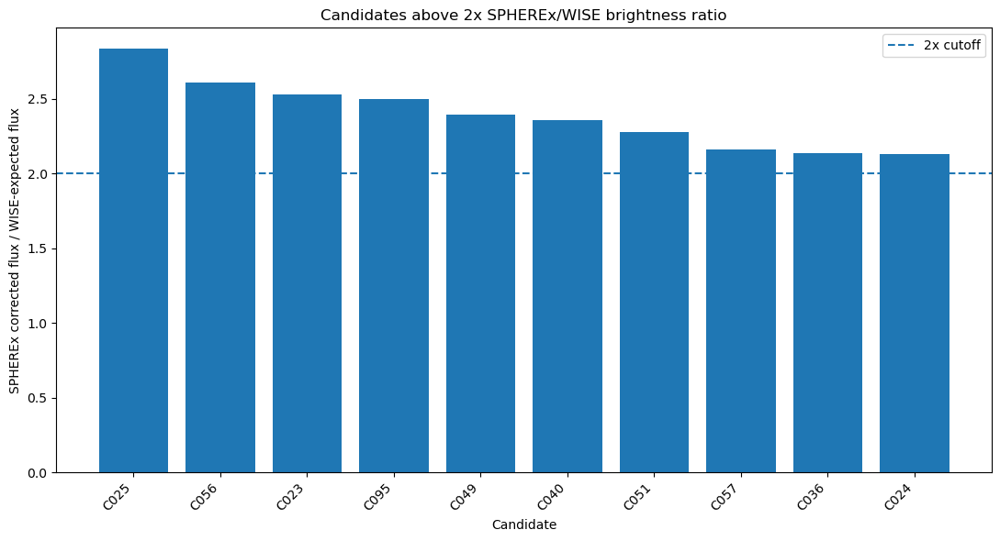

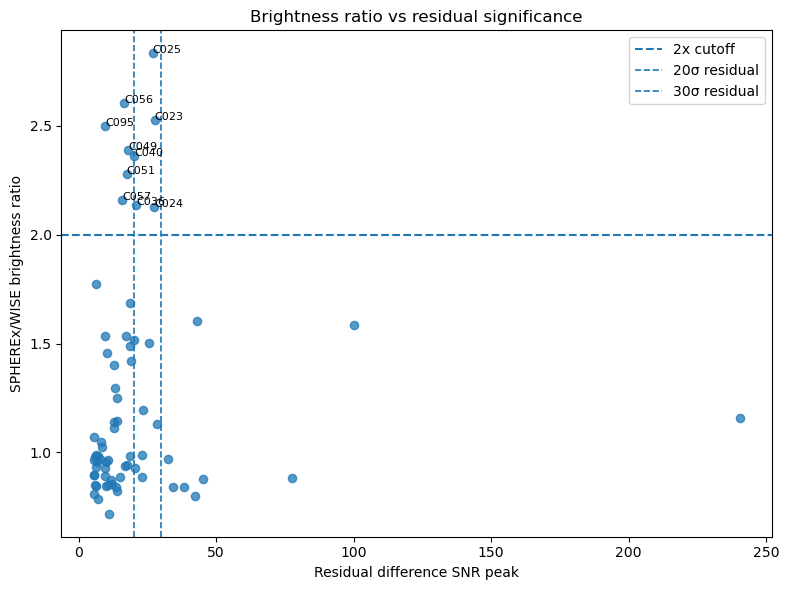

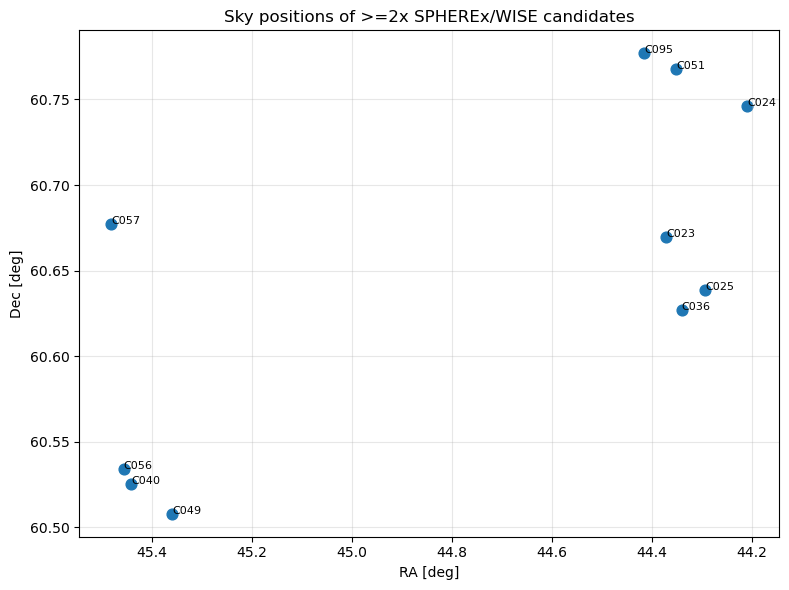

Copied review panels: 0

2x review package written:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\two_x_brightness_review.zip

Files:
  candidate_review_panels
  ra45_dec60p5_2x_candidate_ratio_barplot.png
  ra45_dec60p5_2x_candidate_sky_map.png
  ra45_dec60p5_candidates_above_2x_ratio_review.csv
  ra45_dec60p5_ratio_vs_residual_snr.png
  README_2x_brightness_review.txt


In [4]:
# ============================================================
# 2X BRIGHTNESS CANDIDATE REVIEW PACKAGE
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import shutil
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

RATIO_DIR = FIELD / "brightness_ratio_analysis"
CORR_DIR = FIELD / "new_coordinates_corrected"

OUT_DIR = FIELD / "two_x_brightness_review"
PANEL_OUT = OUT_DIR / "candidate_review_panels"
ZIP_OUT = FIELD / "two_x_brightness_review.zip"

RATIO_CSV = RATIO_DIR / "ra45_dec60p5_spherex_over_wise_brightness_ratios.csv"
LONG_CORR = CORR_DIR / "ra45_dec60p5_final_shortlist_5band_photometry_IRSA_apcorr.csv"
FULL_REVIEW = CORR_DIR / "ra45_dec60p5_full_candidate_review_table.csv"

if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)
PANEL_OUT.mkdir(parents=True, exist_ok=True)

if ZIP_OUT.exists():
    ZIP_OUT.unlink()

ratio = pd.read_csv(RATIO_CSV)
review = pd.read_csv(FULL_REVIEW)

# Select all candidates with finite ratio >= 2
two_x = ratio[
    np.isfinite(ratio["spherex_over_wise_expected_ratio"]) &
    (ratio["spherex_over_wise_expected_ratio"] >= 2.0)
].copy()

two_x = two_x.sort_values("spherex_over_wise_expected_ratio", ascending=False)

OUT_2X = OUT_DIR / "ra45_dec60p5_candidates_above_2x_ratio_review.csv"
two_x.to_csv(OUT_2X, index=False)

print("Candidates with SPHEREx/WISE ratio >= 2x:", len(two_x))
display(two_x[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "spherex_over_wise_expected_ratio",
    "spherex_plane2_flux_mjy_corrected",
    "wise_expected_plane2_flux_mjy",
    "residual_diff_snr_peak",
    "positive_flux_count_5",
    "snr5_count_5",
    "fractional_scatter_5band",
    "review_class",
    "artifact_notes",
    "in_corrected_shortlist",
]])

# ------------------------------------------------------------
# Bar plot of 2x ratios
# ------------------------------------------------------------
PLOT_RATIO = OUT_DIR / "ra45_dec60p5_2x_candidate_ratio_barplot.png"

plt.figure(figsize=(11, 6))
labels = two_x["candidate_id"].str.replace("RA45_CAND_", "C", regex=False)
plt.bar(labels, two_x["spherex_over_wise_expected_ratio"])
plt.axhline(2.0, linestyle="--", linewidth=1.5, label="2x cutoff")
plt.ylabel("SPHEREx corrected flux / WISE-expected flux")
plt.xlabel("Candidate")
plt.title("Candidates above 2x SPHEREx/WISE brightness ratio")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_RATIO, dpi=200)
plt.show()

# ------------------------------------------------------------
# Scatter plot: ratio vs residual SNR
# ------------------------------------------------------------
PLOT_SCATTER = OUT_DIR / "ra45_dec60p5_ratio_vs_residual_snr.png"

plt.figure(figsize=(8, 6))
plt.scatter(
    ratio["residual_diff_snr_peak"],
    ratio["spherex_over_wise_expected_ratio"],
    s=35,
    alpha=0.75
)
plt.axhline(2.0, linestyle="--", linewidth=1.5, label="2x cutoff")
plt.axvline(20.0, linestyle="--", linewidth=1.2, label="20σ residual")
plt.axvline(30.0, linestyle="--", linewidth=1.2, label="30σ residual")

for _, row in two_x.iterrows():
    label = row["candidate_id"].replace("RA45_CAND_", "C")
    plt.text(
        row["residual_diff_snr_peak"],
        row["spherex_over_wise_expected_ratio"],
        label,
        fontsize=8
    )

plt.xlabel("Residual difference SNR peak")
plt.ylabel("SPHEREx/WISE brightness ratio")
plt.title("Brightness ratio vs residual significance")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_SCATTER, dpi=200)
plt.show()

# ------------------------------------------------------------
# Sky map of 2x candidates
# ------------------------------------------------------------
PLOT_SKY = OUT_DIR / "ra45_dec60p5_2x_candidate_sky_map.png"

plt.figure(figsize=(8, 6))
plt.scatter(two_x["ra_deg"], two_x["dec_deg"], s=60)

for _, row in two_x.iterrows():
    label = row["candidate_id"].replace("RA45_CAND_", "C")
    plt.text(row["ra_deg"], row["dec_deg"], label, fontsize=8)

plt.gca().invert_xaxis()
plt.xlabel("RA [deg]")
plt.ylabel("Dec [deg]")
plt.title("Sky positions of >=2x SPHEREx/WISE candidates")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_SKY, dpi=200)
plt.show()

# ------------------------------------------------------------
# Copy review panels if available
# ------------------------------------------------------------
panel_source_dirs = [
    CORR_DIR / "candidate_review_panels",
    FIELD / "final_review" / "candidate_review_panels",
]

panel_src = None
for d in panel_source_dirs:
    if d.exists():
        panel_src = d
        break

if panel_src is not None:
    copied = 0
    for cid in two_x["candidate_id"]:
        matches = list(panel_src.glob(f"*{cid}*.png"))
        for m in matches:
            shutil.copy2(m, PANEL_OUT / m.name)
            copied += 1
    print("Copied review panels:", copied)
else:
    print("WARNING: Could not find review panel folder.")

# ------------------------------------------------------------
# Summary README
# ------------------------------------------------------------
README = OUT_DIR / "README_2x_brightness_review.txt"

max_ratio = two_x["spherex_over_wise_expected_ratio"].max() if len(two_x) else np.nan
n_2x = len(two_x)
n_short = int(two_x["in_corrected_shortlist"].sum()) if len(two_x) else 0
n_best = int((two_x["review_class"] == "BEST FIRST-PASS").sum()) if len(two_x) else 0

readme = f"""2x Brightness Candidate Review
RA=45.0, Dec=60.5 field

Purpose:
Dr. Hora asked about sources that increased in brightness by a large fraction, around 2x or higher. This package isolates candidates where:

SPHEREx corrected plane-2 flux / WISE-expected plane-2 flux >= 2.0

Result:
Number of >=2x candidates: {n_2x}
Maximum ratio found: {max_ratio:.3f}
Number also in corrected final shortlist: {n_short}
Number marked BEST FIRST-PASS: {n_best}

Important interpretation:
The field does contain sources above the 2x brightness-ratio threshold, with a maximum ratio of about {max_ratio:.3f}. However, these >=2x sources did not pass the stricter corrected final-shortlist criteria. Most were marked not top priority because of large five-band scatter and/or weak nearby-wavelength persistence.

Therefore, these should be treated as a separate review set:
- interesting because they satisfy the >=2x brightness increase condition,
- not yet clean high-confidence variables,
- worth visual inspection and possible cross-match against known variable catalogs.

Main files:
- ra45_dec60p5_candidates_above_2x_ratio_review.csv
- ra45_dec60p5_2x_candidate_ratio_barplot.png
- ra45_dec60p5_ratio_vs_residual_snr.png
- ra45_dec60p5_2x_candidate_sky_map.png
- candidate_review_panels/
"""

README.write_text(readme, encoding="utf-8")

# ------------------------------------------------------------
# Zip package
# ------------------------------------------------------------
with zipfile.ZipFile(ZIP_OUT, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT_DIR.rglob("*"):
        z.write(p, arcname=p.relative_to(OUT_DIR.parent))

print("\n2x review package written:")
print(ZIP_OUT)

print("\nFiles:")
for p in sorted(OUT_DIR.rglob("*")):
    print(" ", p.relative_to(OUT_DIR))

Loaded:
SPHEREx cube: (5, 581, 581)
Scaled WISE: (581, 581)
Residual: (581, 581)
2x candidates: 10


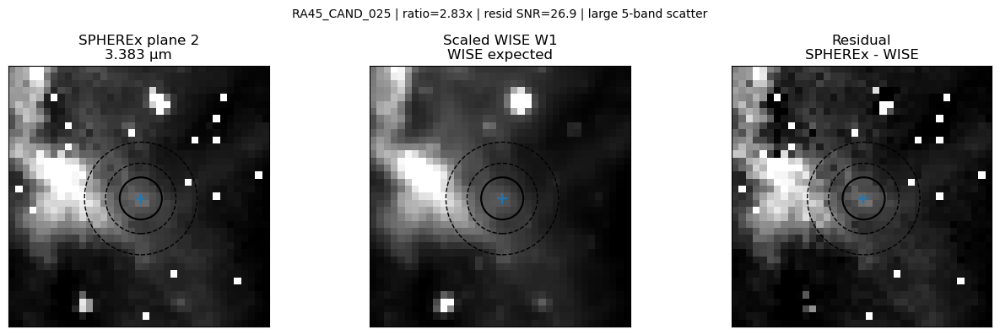

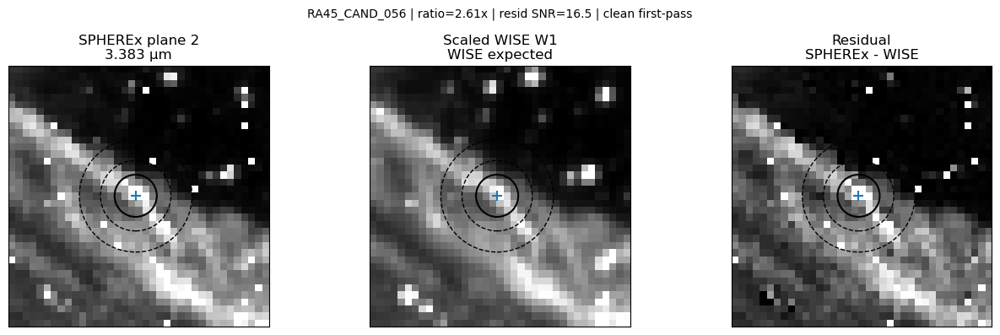

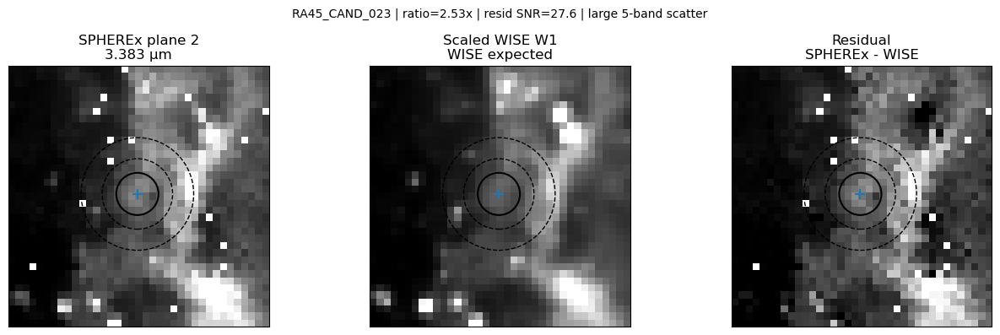

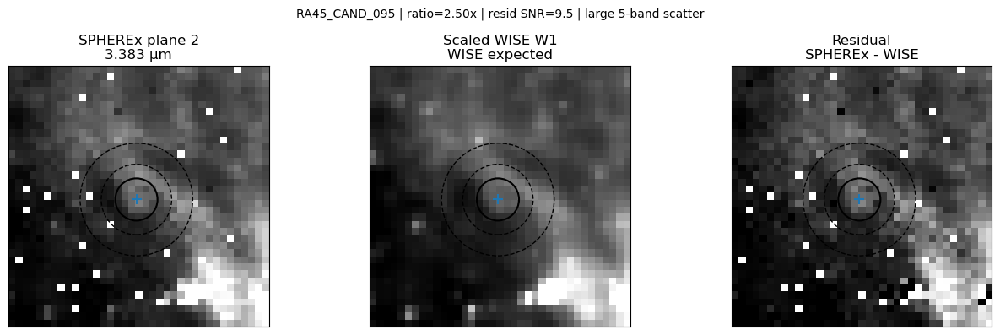

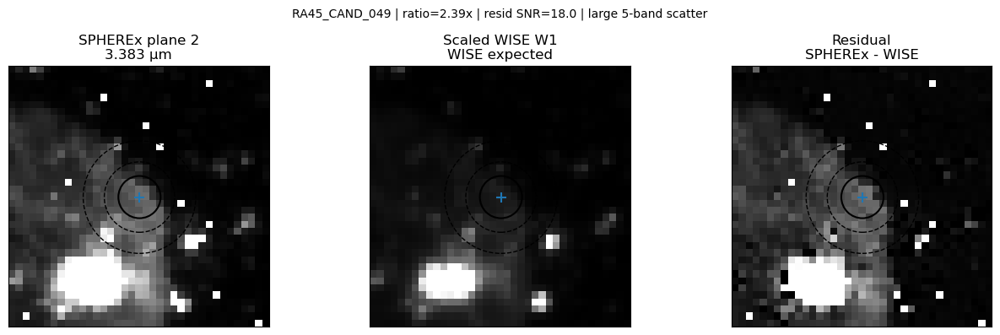

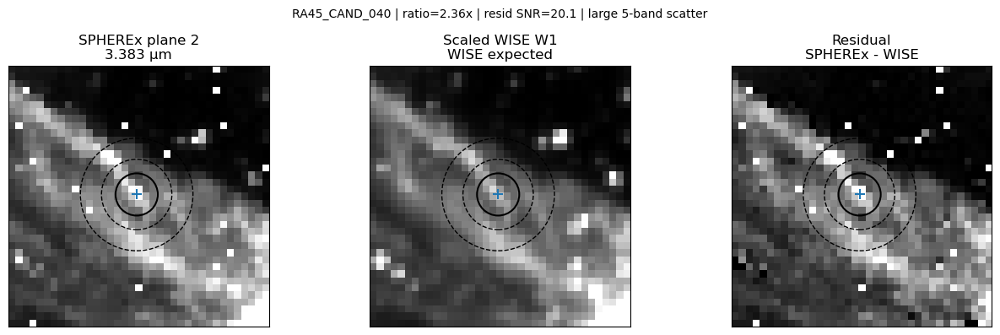

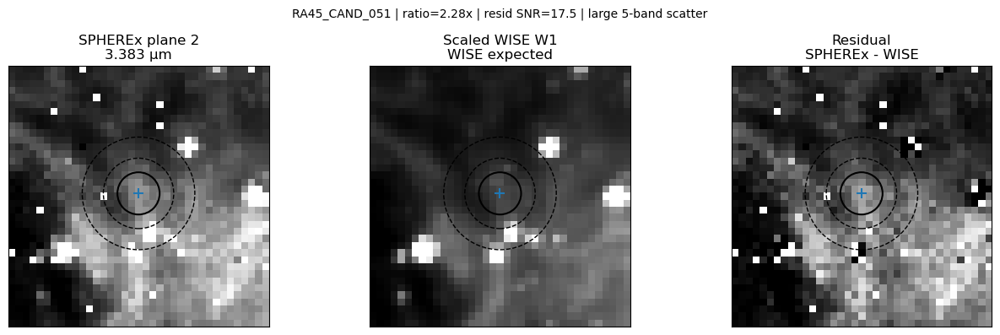

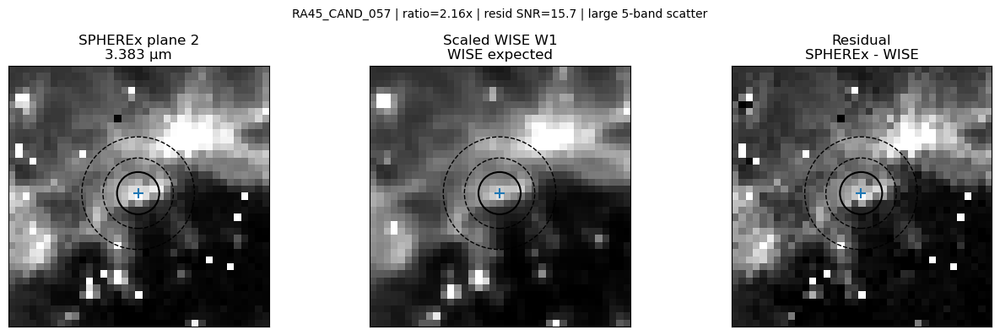

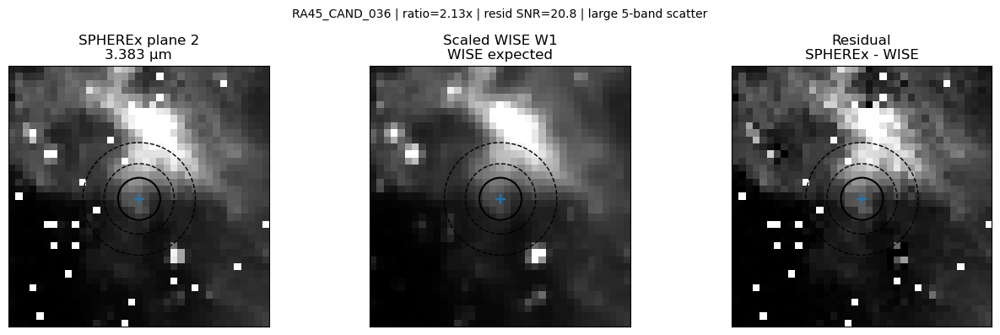

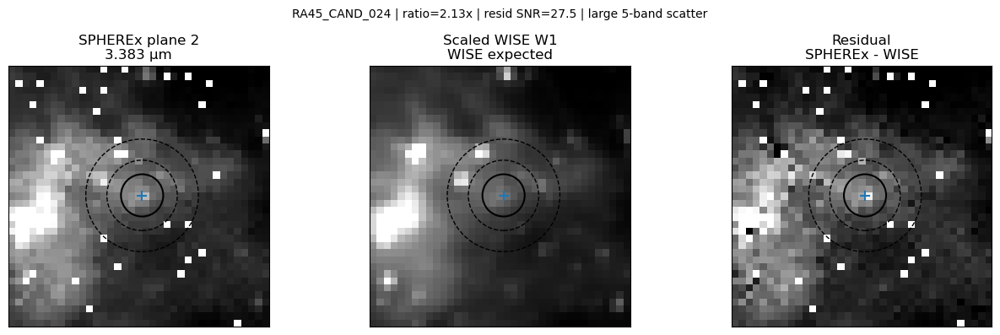


Generated panels:
  RA45_CAND_023_2x_review_panel.png
  RA45_CAND_024_2x_review_panel.png
  RA45_CAND_025_2x_review_panel.png
  RA45_CAND_036_2x_review_panel.png
  RA45_CAND_040_2x_review_panel.png
  RA45_CAND_049_2x_review_panel.png
  RA45_CAND_051_2x_review_panel.png
  RA45_CAND_056_2x_review_panel.png
  RA45_CAND_057_2x_review_panel.png
  RA45_CAND_095_2x_review_panel.png


In [5]:
# ============================================================
# GENERATE REVIEW PANELS FOR >=2X BRIGHTNESS CANDIDATES
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from matplotlib.patches import Circle

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

RATIO_DIR = FIELD / "brightness_ratio_analysis"
TWOX_DIR = FIELD / "two_x_brightness_review"
PANEL_DIR = TWOX_DIR / "candidate_review_panels"
PANEL_DIR.mkdir(parents=True, exist_ok=True)

CUBE_PATH = FIELD / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"

TWOX_CSV = TWOX_DIR / "ra45_dec60p5_candidates_above_2x_ratio_review.csv"

SCALED_WISE_OPTIONS = [
    FIELD / "psf_tuning" / "wise_w1_scaled_psf_tuned_to_spherex_plane2.fits",
    FIELD / "photometric_scaling" / "wise_w1_scaled_to_spherex_plane2.fits",
]

RESIDUAL_OPTIONS = [
    FIELD / "new_coordinates_corrected" / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits",
    FIELD / "psf_tuning" / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits",
    FIELD / "photometric_scaling" / "spherex_plane2_minus_scaled_wise_w1.fits",
]

SCALED_WISE = next((p for p in SCALED_WISE_OPTIONS if p.exists()), None)
RESIDUAL = next((p for p in RESIDUAL_OPTIONS if p.exists()), None)

if SCALED_WISE is None:
    raise FileNotFoundError("Could not find scaled WISE FITS.")

if RESIDUAL is None:
    raise FileNotFoundError("Could not find residual FITS.")

if not TWOX_CSV.exists():
    raise FileNotFoundError(f"Missing 2x candidate table: {TWOX_CSV}")

two_x = pd.read_csv(TWOX_CSV)

with fits.open(CUBE_PATH) as hdul:
    cube = hdul["IMAGE"].data.astype(float)
    hdr = hdul["IMAGE"].header
    wcs = WCS(hdr, hdul).celestial
    wavelengths = np.array([row[2] for row in hdul["SPECTRAL_CHANNELS"].data], dtype=float)

with fits.open(SCALED_WISE) as hdul:
    wise_scaled = hdul[0].data.astype(float)

with fits.open(RESIDUAL) as hdul:
    residual = hdul[0].data.astype(float)

print("Loaded:")
print("SPHEREx cube:", cube.shape)
print("Scaled WISE:", wise_scaled.shape)
print("Residual:", residual.shape)
print("2x candidates:", len(two_x))

def robust_limits(img, low=2, high=98):
    vals = img[np.isfinite(img)]
    if len(vals) == 0:
        return 0, 1
    return np.nanpercentile(vals, low), np.nanpercentile(vals, high)

def cutout(img, x, y, half=18):
    x = int(round(x))
    y = int(round(y))
    y0 = max(0, y - half)
    y1 = min(img.shape[0], y + half + 1)
    x0 = max(0, x - half)
    x1 = min(img.shape[1], x + half + 1)
    return img[y0:y1, x0:x1], x0, y0

for _, row in two_x.iterrows():
    cid = row["candidate_id"]
    short_id = cid.replace("RA45_CAND_", "C")
    x = float(row["x_pix"])
    y = float(row["y_pix"])

    spx = cube[2]  # plane 2, 3.383 um
    spx_cut, x0, y0 = cutout(spx, x, y)
    wise_cut, _, _ = cutout(wise_scaled, x, y)
    resid_cut, _, _ = cutout(residual, x, y)

    # Difference/display limits
    spx_vmin, spx_vmax = robust_limits(spx_cut)
    wise_vmin, wise_vmax = robust_limits(wise_cut)
    res_vmin, res_vmax = robust_limits(resid_cut, low=5, high=99)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    panels = [
        (spx_cut, "SPHEREx plane 2\n3.383 µm", spx_vmin, spx_vmax),
        (wise_cut, "Scaled WISE W1\nWISE expected", wise_vmin, wise_vmax),
        (resid_cut, "Residual\nSPHEREx - WISE", res_vmin, res_vmax),
    ]

    cx = x - x0
    cy = y - y0

    for ax, (img, title, vmin, vmax) in zip(axes, panels):
        ax.imshow(img, origin="lower", cmap="gray", vmin=vmin, vmax=vmax)
        ax.add_patch(Circle((cx, cy), 3, fill=False, linewidth=1.5))
        ax.add_patch(Circle((cx, cy), 5, fill=False, linewidth=1.0, linestyle="--"))
        ax.add_patch(Circle((cx, cy), 8, fill=False, linewidth=1.0, linestyle="--"))
        ax.scatter([cx], [cy], marker="+", s=80)
        ax.set_title(title)
        ax.set_xticks([])
        ax.set_yticks([])

    fig.suptitle(
        f"{cid} | ratio={row['spherex_over_wise_expected_ratio']:.2f}x | "
        f"resid SNR={row['residual_diff_snr_peak']:.1f} | "
        f"{row['artifact_notes']}",
        fontsize=10
    )

    plt.tight_layout()

    out_png = PANEL_DIR / f"{cid}_2x_review_panel.png"
    plt.savefig(out_png, dpi=200)
    plt.show()
    plt.close(fig)

print("\nGenerated panels:")
for p in sorted(PANEL_DIR.glob("*.png")):
    print(" ", p.name)

In [6]:
# ============================================================
# RE-ZIP UPDATED 2X REVIEW PACKAGE WITH PANELS
# ============================================================

from pathlib import Path
import zipfile

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

TWOX_DIR = FIELD / "two_x_brightness_review"
ZIP_OUT = FIELD / "two_x_brightness_review.zip"

if ZIP_OUT.exists():
    ZIP_OUT.unlink()

with zipfile.ZipFile(ZIP_OUT, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for p in TWOX_DIR.rglob("*"):
        z.write(p, arcname=p.relative_to(TWOX_DIR.parent))

print("Updated 2x review ZIP:")
print(ZIP_OUT)

print("\nPanel files:")
for p in sorted((TWOX_DIR / "candidate_review_panels").glob("*.png")):
    print(" ", p.name)

Updated 2x review ZIP:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\two_x_brightness_review.zip

Panel files:
  RA45_CAND_023_2x_review_panel.png
  RA45_CAND_024_2x_review_panel.png
  RA45_CAND_025_2x_review_panel.png
  RA45_CAND_036_2x_review_panel.png
  RA45_CAND_040_2x_review_panel.png
  RA45_CAND_049_2x_review_panel.png
  RA45_CAND_051_2x_review_panel.png
  RA45_CAND_056_2x_review_panel.png
  RA45_CAND_057_2x_review_panel.png
  RA45_CAND_095_2x_review_panel.png


In [10]:
# ============================================================
# MAKE REAL ASTROPY/IPAC FORMAT TABLE FOR GATOR VARWISE CROSSMATCH
# ============================================================

from pathlib import Path
import pandas as pd
from astropy.table import Table
from astropy.io import ascii

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

OUT_DIR = FIELD / "varwise_crossmatch"
OUT_DIR.mkdir(parents=True, exist_ok=True)

INPUT_CSV = OUT_DIR / "ra45_dec60p5_candidates_for_varwise_crossmatch.csv"

# Final Gator-safe file
OUT_IPAC = OUT_DIR / "ra45_dec60p5_candidates_GATOR_IPAC.tbl"

df = pd.read_csv(INPUT_CSV)

# Only use numeric columns Gator needs.
# Add major=3 arcsec as a table column too, because Gator examples accept this.
simple = pd.DataFrame()
simple["ra"] = df["ra"].astype(float)
simple["dec"] = df["dec"].astype(float)
simple["major"] = 3.0

# Make a real Astropy table
tab = Table.from_pandas(simple)

# Add units/descriptions
tab["ra"].unit = "deg"
tab["dec"].unit = "deg"
tab["major"].unit = "arcsec"

# Write real IPAC format
ascii.write(tab, OUT_IPAC, format="ipac", overwrite=True)

print("Saved real Gator/IPAC table:")
print(OUT_IPAC)

print("\nFirst 20 lines:")
for line in OUT_IPAC.read_text().splitlines()[:20]:
    print(line)

Saved real Gator/IPAC table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\varwise_crossmatch\ra45_dec60p5_candidates_GATOR_IPAC.tbl

First 20 lines:
|                ra|               dec| major|
|            double|            double|double|
|               deg|               deg|arcsec|
|              null|              null|  null|
  44.37129570240369  60.66962052201757    3.0 
  44.20885478047418   60.7459098540389    3.0 
  44.29291971820614  60.63885110738346    3.0 
  44.33967964370369  60.62692304365134    3.0 
  45.44201034330501  60.52557091801782    3.0 
 45.359906654252605  60.50794817024519    3.0 
  44.35116745466103 60.767826754501705    3.0 
  45.45662270931254  60.53381632867926    3.0 
 45.482045729631785   60.6773042273337    3.0 
 44.415532742920085  60.77696520849264    3.0 
  44.25591044151857  60.47893034384169    3.0 
  45.11062601193169  60.80251894813281    3.0 
 45.551535305604354  60.66169273611142    3.0 
  45.65103410565728  60.146566728

In [11]:
from pathlib import Path

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"
OUT_DIR = FIELD / "varwise_crossmatch"

print("VarWISE cross-match folder:")
print(OUT_DIR)

print("\nFiles:")
for p in sorted(OUT_DIR.rglob("*")):
    print(p.relative_to(OUT_DIR), "| size:", p.stat().st_size)

VarWISE cross-match folder:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\varwise_crossmatch

Files:
ra45_dec60p5_candidates_for_varwise_crossmatch.csv | size: 20390
ra45_dec60p5_candidates_for_varwise_crossmatch.tbl | size: 5874
ra45_dec60p5_candidates_GATOR_IPAC.tbl | size: 6576
ra45_dec60p5_candidates_RA_DEC_ONLY.txt | size: 3067
ra45_dec60p5_candidates_RA_DEC_ONLY_GATOR.tbl | size: 3387
table_irsa_catalog_search_results.tbl | size: 6193


In [12]:
# ============================================================
# PARSE VARWISE CROSSMATCH RESULT AND MATCH BACK TO RA45 CANDIDATES
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

from astropy.io import ascii
from astropy.coordinates import SkyCoord
import astropy.units as u

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

VARWISE_DIR = FIELD / "varwise_crossmatch"
CORR_DIR = FIELD / "new_coordinates_corrected"
RATIO_DIR = FIELD / "brightness_ratio_analysis"

RESULT_TBL = VARWISE_DIR / "table_irsa_catalog_search_results.tbl"

FULL_CAND = CORR_DIR / "ra45_dec60p5_full_candidate_review_table.csv"
RATIO_CSV = RATIO_DIR / "ra45_dec60p5_spherex_over_wise_brightness_ratios.csv"

OUT_MATCHED = VARWISE_DIR / "ra45_dec60p5_varwise_matched_candidates.csv"

if not RESULT_TBL.exists():
    raise FileNotFoundError(f"Missing VarWISE result table: {RESULT_TBL}")

# ------------------------------------------------------------
# Read VarWISE result table
# ------------------------------------------------------------
varwise_tab = ascii.read(RESULT_TBL, format="ipac")
varwise = varwise_tab.to_pandas()

print("VarWISE result table shape:", varwise.shape)
print("VarWISE columns:")
print(list(varwise.columns))

display(varwise.head())

# ------------------------------------------------------------
# Load our candidate tables
# ------------------------------------------------------------
cand = pd.read_csv(FULL_CAND)
ratio = pd.read_csv(RATIO_CSV)

ratio_keep_cols = [
    "candidate_id",
    "spherex_over_wise_expected_ratio",
    "brightness_2x_or_higher",
    "spherex_plane2_flux_mjy_corrected",
    "wise_expected_plane2_flux_mjy",
]

ratio_keep_cols = [c for c in ratio_keep_cols if c in ratio.columns]
cand = cand.merge(ratio[ratio_keep_cols], on="candidate_id", how="left")

# ------------------------------------------------------------
# Identify input coordinates from Gator result
# Usually ra_01/dec_01 are the uploaded candidate coordinates.
# VarWISE catalog coordinates are usually ra/dec.
# ------------------------------------------------------------
print("\nLooking for coordinate columns...")

coord_cols = [c for c in varwise.columns if "ra" in c.lower() or "dec" in c.lower() or "dist" in c.lower() or "designation" in c.lower()]
print(coord_cols)

# These are visible in your screenshot:
input_ra_col = "ra_01"
input_dec_col = "dec_01"
match_dist_col = "dist_x"

# Catalog VarWISE source coords:
varwise_ra_col = "ra"
varwise_dec_col = "dec"

for col in [input_ra_col, input_dec_col, varwise_ra_col, varwise_dec_col]:
    if col not in varwise.columns:
        raise KeyError(f"Expected column missing: {col}. Available columns shown above.")

# ------------------------------------------------------------
# Match input coords back to our candidate list
# ------------------------------------------------------------
cand_coords = SkyCoord(cand["ra_deg"].to_numpy() * u.deg, cand["dec_deg"].to_numpy() * u.deg)
input_coords = SkyCoord(varwise[input_ra_col].to_numpy() * u.deg, varwise[input_dec_col].to_numpy() * u.deg)

idx, sep2d, _ = input_coords.match_to_catalog_sky(cand_coords)

matched_rows = []

for i, row in varwise.iterrows():
    c = cand.iloc[idx[i]].copy()

    out = {}

    # Our candidate info
    out["candidate_id"] = c["candidate_id"]
    out["candidate_ra_deg"] = c["ra_deg"]
    out["candidate_dec_deg"] = c["dec_deg"]
    out["candidate_match_back_sep_arcsec"] = sep2d.arcsec[i]

    # Gator input/source match info
    out["gator_input_ra"] = row[input_ra_col]
    out["gator_input_dec"] = row[input_dec_col]
    out["varwise_match_dist_arcsec"] = row[match_dist_col] if match_dist_col in varwise.columns else np.nan

    # VarWISE source info
    out["varwise_designation"] = row["designation"] if "designation" in varwise.columns else ""
    out["varwise_ra"] = row[varwise_ra_col]
    out["varwise_dec"] = row[varwise_dec_col]

    # Our science metrics
    for col in [
        "residual_diff_snr_peak",
        "positive_flux_count_5",
        "snr5_count_5",
        "median_flux_mjy",
        "max_snr_local",
        "fractional_scatter_5band",
        "review_class",
        "artifact_notes",
        "spherex_over_wise_expected_ratio",
        "brightness_2x_or_higher",
    ]:
        if col in c.index:
            out[col] = c[col]

    # Include all VarWISE columns too, prefixed
    for col in varwise.columns:
        out[f"varwise_{col}"] = row[col]

    matched_rows.append(out)

matched = pd.DataFrame(matched_rows)
matched.to_csv(OUT_MATCHED, index=False)

print("\nSaved matched VarWISE candidate table:")
print(OUT_MATCHED)

print("\nMatched result:")
display(matched[[
    "candidate_id",
    "candidate_ra_deg",
    "candidate_dec_deg",
    "candidate_match_back_sep_arcsec",
    "varwise_designation",
    "varwise_match_dist_arcsec",
    "varwise_ra",
    "varwise_dec",
    "spherex_over_wise_expected_ratio",
    "brightness_2x_or_higher",
    "residual_diff_snr_peak",
    "positive_flux_count_5",
    "snr5_count_5",
    "fractional_scatter_5band",
    "review_class",
    "artifact_notes",
]])

VarWISE result table shape: (1, 47)
VarWISE columns:
['cntr_01', 'dist_x', 'pang_x', 'ra_01', 'dec_01', 'major_01', 'cluster_id', 'designation', 'ra', 'dec', 'vartype', 'confidence', 'variability_snr', 'period1', 'period2', 'period_significance', 'suspect_period', 'w1_amp', 'w2_amp', 'n_obs', 'w1mag', 'w1emag', 'w2mag', 'w2emag', 'w3mag', 'w3emag', 'w4mag', 'w4emag', 'jmag', 'jemag', 'hmag', 'hemag', 'kmag', 'kemag', 'gmag', 'gemag', 'bpmag', 'bpemag', 'rpmag', 'rpemag', 'plx', 'e_plx', 'simbad_type', 'known_extragalactic', 'blended_source', 'latent_artifact', 'cntr']


,cntr_01,dist_x,pang_x,ra_01,dec_01,major_01,cluster_id,designation,ra,dec,...,bpemag,rpmag,rpemag,plx,e_plx,simbad_type,known_extragalactic,blended_source,latent_artifact,cntr
0,115,0.489487,-105.497089,44.604549,60.892236,3.0,233068764076470534,VarWISE J025825.02+605331.9,44.60428,60.8922,...,0.01,15.51,0.01,0.3183,0.0504,NaN,0,0.04,0.03,20455



Looking for coordinate columns...
['dist_x', 'ra_01', 'dec_01', 'designation', 'ra', 'dec', 'known_extragalactic']

Saved matched VarWISE candidate table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\varwise_crossmatch\ra45_dec60p5_varwise_matched_candidates.csv

Matched result:


,candidate_id,candidate_ra_deg,candidate_dec_deg,candidate_match_back_sep_arcsec,varwise_designation,varwise_match_dist_arcsec,varwise_ra,varwise_dec,spherex_over_wise_expected_ratio,brightness_2x_or_higher,residual_diff_snr_peak,positive_flux_count_5,snr5_count_5,fractional_scatter_5band,review_class,artifact_notes
0,RA45_CAND_109,44.604549,60.892236,0.000002,VarWISE J025825.02+605331.9,0.489487,44.60428,60.8922,NaN,False,7.684315,0,0,NaN,not top priority,clean first-pass


In [13]:
# ============================================================
# PARSE VARWISE PURE + EXTENDED RESULTS AND MERGE BACK TO CANDIDATES
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

from astropy.io import ascii
from astropy.coordinates import SkyCoord
import astropy.units as u

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

VARWISE_DIR = FIELD / "varwise_crossmatch"
CORR_DIR = FIELD / "new_coordinates_corrected"
RATIO_DIR = FIELD / "brightness_ratio_analysis"

PURE_TBL = VARWISE_DIR / "table_irsa_catalog_search_results.tbl"
EXT_TBL = VARWISE_DIR / "table_irsa_catalog_search_results_extended.tbl"

FULL_CAND = CORR_DIR / "ra45_dec60p5_full_candidate_review_table.csv"
RATIO_CSV = RATIO_DIR / "ra45_dec60p5_spherex_over_wise_brightness_ratios.csv"

OUT_ALL = VARWISE_DIR / "ra45_dec60p5_varwise_pure_extended_matched_candidates.csv"

# ------------------------------------------------------------
# Load our candidate tables
# ------------------------------------------------------------
cand = pd.read_csv(FULL_CAND)
ratio = pd.read_csv(RATIO_CSV)

ratio_cols = [
    "candidate_id",
    "spherex_over_wise_expected_ratio",
    "brightness_2x_or_higher",
    "spherex_plane2_flux_mjy_corrected",
    "wise_expected_plane2_flux_mjy",
]
ratio_cols = [c for c in ratio_cols if c in ratio.columns]

cand = cand.merge(ratio[ratio_cols], on="candidate_id", how="left")

cand_coords = SkyCoord(cand["ra_deg"].to_numpy() * u.deg, cand["dec_deg"].to_numpy() * u.deg)

# ------------------------------------------------------------
# Helper to parse one result file
# ------------------------------------------------------------
def parse_varwise_result(tbl_path, catalog_label):
    if not tbl_path.exists():
        print(f"Missing {catalog_label} file:", tbl_path)
        return pd.DataFrame()

    tab = ascii.read(tbl_path, format="ipac")
    df = tab.to_pandas()

    print(f"\n{catalog_label} shape:", df.shape)
    print(f"{catalog_label} columns:")
    print(list(df.columns))

    if len(df) == 0:
        return pd.DataFrame()

    # Gator upload input coords visible from previous output
    input_ra_col = "ra_01"
    input_dec_col = "dec_01"
    match_dist_col = "dist_x"

    var_ra_col = "ra"
    var_dec_col = "dec"

    for col in [input_ra_col, input_dec_col, var_ra_col, var_dec_col]:
        if col not in df.columns:
            raise KeyError(f"{catalog_label}: expected column missing: {col}")

    input_coords = SkyCoord(df[input_ra_col].to_numpy() * u.deg, df[input_dec_col].to_numpy() * u.deg)
    idx, sep2d, _ = input_coords.match_to_catalog_sky(cand_coords)

    rows = []

    for i, row in df.iterrows():
        c = cand.iloc[idx[i]].copy()

        out = {
            "catalog": catalog_label,
            "candidate_id": c["candidate_id"],
            "candidate_ra_deg": c["ra_deg"],
            "candidate_dec_deg": c["dec_deg"],
            "candidate_match_back_sep_arcsec": sep2d.arcsec[i],
            "gator_input_ra": row[input_ra_col],
            "gator_input_dec": row[input_dec_col],
            "varwise_match_dist_arcsec": row[match_dist_col] if match_dist_col in df.columns else np.nan,
            "varwise_designation": row["designation"] if "designation" in df.columns else "",
            "varwise_ra": row[var_ra_col],
            "varwise_dec": row[var_dec_col],
        }

        for col in [
            "residual_diff_snr_peak",
            "positive_flux_count_5",
            "snr5_count_5",
            "median_flux_mjy",
            "max_snr_local",
            "fractional_scatter_5band",
            "review_class",
            "artifact_notes",
            "spherex_over_wise_expected_ratio",
            "brightness_2x_or_higher",
            "spherex_plane2_flux_mjy_corrected",
            "wise_expected_plane2_flux_mjy",
        ]:
            if col in c.index:
                out[col] = c[col]

        # Include VarWISE fields with prefix
        for col in df.columns:
            out[f"varwise_{col}"] = row[col]

        rows.append(out)

    return pd.DataFrame(rows)

# ------------------------------------------------------------
# Parse both
# ------------------------------------------------------------
pure = parse_varwise_result(PURE_TBL, "VarWISE Pure")
extended = parse_varwise_result(EXT_TBL, "VarWISE Extended")

all_matches = pd.concat([pure, extended], ignore_index=True)

# Remove exact duplicate same candidate/catalog/designation if any
if len(all_matches) > 0:
    all_matches = all_matches.drop_duplicates(
        subset=["catalog", "candidate_id", "varwise_designation", "varwise_match_dist_arcsec"],
        keep="first"
    )

all_matches.to_csv(OUT_ALL, index=False)

print("\nSaved combined VarWISE matched table:")
print(OUT_ALL)

print("\nCombined matches:")
if len(all_matches) == 0:
    print("No VarWISE matches found.")
else:
    display(all_matches[[
        "catalog",
        "candidate_id",
        "candidate_ra_deg",
        "candidate_dec_deg",
        "varwise_designation",
        "varwise_match_dist_arcsec",
        "spherex_over_wise_expected_ratio",
        "brightness_2x_or_higher",
        "residual_diff_snr_peak",
        "positive_flux_count_5",
        "snr5_count_5",
        "fractional_scatter_5band",
        "review_class",
        "artifact_notes",
    ]])

    print("\nSummary:")
    print("Total VarWISE matches:", len(all_matches))
    print("Unique matched candidates:", all_matches["candidate_id"].nunique())
    print("Matches with >=2x brightness:", int(all_matches["brightness_2x_or_higher"].fillna(False).sum()))
    print("Matches marked BEST FIRST-PASS:", int((all_matches["review_class"] == "BEST FIRST-PASS").sum()))


VarWISE Pure shape: (1, 47)
VarWISE Pure columns:
['cntr_01', 'dist_x', 'pang_x', 'ra_01', 'dec_01', 'major_01', 'cluster_id', 'designation', 'ra', 'dec', 'vartype', 'confidence', 'variability_snr', 'period1', 'period2', 'period_significance', 'suspect_period', 'w1_amp', 'w2_amp', 'n_obs', 'w1mag', 'w1emag', 'w2mag', 'w2emag', 'w3mag', 'w3emag', 'w4mag', 'w4emag', 'jmag', 'jemag', 'hmag', 'hemag', 'kmag', 'kemag', 'gmag', 'gemag', 'bpmag', 'bpemag', 'rpmag', 'rpemag', 'plx', 'e_plx', 'simbad_type', 'known_extragalactic', 'blended_source', 'latent_artifact', 'cntr']

VarWISE Extended shape: (1, 47)
VarWISE Extended columns:
['cntr_01', 'dist_x', 'pang_x', 'ra_01', 'dec_01', 'major_01', 'cluster_id', 'designation', 'ra', 'dec', 'vartype', 'confidence', 'variability_snr', 'period1', 'period2', 'period_significance', 'suspect_period', 'w1_amp', 'w2_amp', 'n_obs', 'w1mag', 'w1emag', 'w2mag', 'w2emag', 'w3mag', 'w3emag', 'w4mag', 'w4emag', 'jmag', 'jemag', 'hmag', 'hemag', 'kmag', 'kemag', 

,catalog,candidate_id,candidate_ra_deg,candidate_dec_deg,varwise_designation,varwise_match_dist_arcsec,spherex_over_wise_expected_ratio,brightness_2x_or_higher,residual_diff_snr_peak,positive_flux_count_5,snr5_count_5,fractional_scatter_5band,review_class,artifact_notes
0,VarWISE Pure,RA45_CAND_109,44.604549,60.892236,VarWISE J025825.02+605331.9,0.489487,NaN,False,7.684315,0,0,NaN,not top priority,clean first-pass
1,VarWISE Extended,RA45_CAND_109,44.604549,60.892236,VarWISE J025825.02+605331.9,0.489487,NaN,False,7.684315,0,0,NaN,not top priority,clean first-pass



Summary:
Total VarWISE matches: 2
Unique matched candidates: 1
Matches with >=2x brightness: 0
Matches marked BEST FIRST-PASS: 0


In [14]:
# ============================================================
# OFF-CENTER DEBUGGING — MEASURE CANDIDATE CENTER VS LOCAL PEAK
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from scipy.ndimage import center_of_mass

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

CORR_DIR = FIELD / "new_coordinates_corrected"
OUT_DIR = FIELD / "offcenter_debugging"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CAND_TABLE = CORR_DIR / "ra45_dec60p5_full_candidate_review_table.csv"

CUBE_PATH = FIELD / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"

SCALED_WISE_OPTIONS = [
    FIELD / "psf_tuning" / "wise_w1_scaled_psf_tuned_to_spherex_plane2.fits",
    FIELD / "photometric_scaling" / "wise_w1_scaled_to_spherex_plane2.fits",
]

RESIDUAL_OPTIONS = [
    CORR_DIR / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits",
    FIELD / "psf_tuning" / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits",
    FIELD / "photometric_scaling" / "spherex_plane2_minus_scaled_wise_w1.fits",
]

SCALED_WISE = next((p for p in SCALED_WISE_OPTIONS if p.exists()), None)
RESIDUAL = next((p for p in RESIDUAL_OPTIONS if p.exists()), None)

if SCALED_WISE is None:
    raise FileNotFoundError("Missing scaled WISE FITS.")

if RESIDUAL is None:
    raise FileNotFoundError("Missing residual FITS.")

cand = pd.read_csv(CAND_TABLE)

with fits.open(CUBE_PATH) as hdul:
    spx = hdul["IMAGE"].data[2].astype(float)  # plane 2, 3.383 um

with fits.open(SCALED_WISE) as hdul:
    wise = hdul[0].data.astype(float)

with fits.open(RESIDUAL) as hdul:
    resid = hdul[0].data.astype(float)

print("Loaded candidates:", len(cand))
print("SPHEREx shape:", spx.shape)
print("WISE shape:", wise.shape)
print("Residual shape:", resid.shape)

def get_cutout(img, x, y, half=8):
    x_int = int(round(x))
    y_int = int(round(y))

    y0 = max(0, y_int - half)
    y1 = min(img.shape[0], y_int + half + 1)
    x0 = max(0, x_int - half)
    x1 = min(img.shape[1], x_int + half + 1)

    return img[y0:y1, x0:x1], x0, y0

def local_peak_offset(img, x, y, half=8):
    cut, x0, y0 = get_cutout(img, x, y, half=half)

    if cut.size == 0 or not np.isfinite(cut).any():
        return np.nan, np.nan, np.nan, np.nan, np.nan

    # Use brightest finite pixel as local peak
    finite = np.isfinite(cut)
    safe = np.where(finite, cut, -np.inf)
    py, px = np.unravel_index(np.nanargmax(safe), safe.shape)

    peak_x = x0 + px
    peak_y = y0 + py

    dx = peak_x - x
    dy = peak_y - y
    dist = np.sqrt(dx**2 + dy**2)

    peak_val = img[int(round(peak_y)), int(round(peak_x))]

    return peak_x, peak_y, dx, dy, dist

rows = []

for _, row in cand.iterrows():
    cid = row["candidate_id"]
    x = float(row["x_pix"])
    y = float(row["y_pix"])

    spx_peak_x, spx_peak_y, spx_dx, spx_dy, spx_dist = local_peak_offset(spx, x, y, half=8)
    wise_peak_x, wise_peak_y, wise_dx, wise_dy, wise_dist = local_peak_offset(wise, x, y, half=8)
    resid_peak_x, resid_peak_y, resid_dx, resid_dy, resid_dist = local_peak_offset(resid, x, y, half=8)

    rows.append({
        "candidate_id": cid,
        "ra_deg": row["ra_deg"],
        "dec_deg": row["dec_deg"],
        "x_pix": x,
        "y_pix": y,

        "spx_peak_x": spx_peak_x,
        "spx_peak_y": spx_peak_y,
        "spx_peak_offset_pix": spx_dist,

        "wise_peak_x": wise_peak_x,
        "wise_peak_y": wise_peak_y,
        "wise_peak_offset_pix": wise_dist,

        "resid_peak_x": resid_peak_x,
        "resid_peak_y": resid_peak_y,
        "resid_peak_offset_pix": resid_dist,

        "residual_diff_snr_peak": row.get("residual_diff_snr_peak", np.nan),
        "positive_flux_count_5": row.get("positive_flux_count_5", np.nan),
        "snr5_count_5": row.get("snr5_count_5", np.nan),
        "fractional_scatter_5band": row.get("fractional_scatter_5band", np.nan),
        "review_class": row.get("review_class", ""),
        "artifact_notes": row.get("artifact_notes", ""),
    })

debug = pd.DataFrame(rows)

# Flag off-center cases
debug["resid_offcenter_flag"] = debug["resid_peak_offset_pix"] > 3.0
debug["spx_offcenter_flag"] = debug["spx_peak_offset_pix"] > 3.0
debug["wise_offcenter_flag"] = debug["wise_peak_offset_pix"] > 3.0

debug["offcenter_summary"] = np.where(
    debug["resid_offcenter_flag"],
    "residual peak >3 pix from aperture center",
    "residual peak near aperture center"
)

OUT_CSV = OUT_DIR / "ra45_dec60p5_offcenter_debug_table.csv"
debug.to_csv(OUT_CSV, index=False)

print("\nSaved off-center debug table:")
print(OUT_CSV)

print("\nOffset summary:")
print(debug[["spx_peak_offset_pix", "wise_peak_offset_pix", "resid_peak_offset_pix"]].describe())

print("\nNumber with residual peak >3 pixels from aperture center:")
print(int(debug["resid_offcenter_flag"].sum()), "out of", len(debug))

print("\nMost off-center candidates by residual peak offset:")
display(debug.sort_values("resid_peak_offset_pix", ascending=False)[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "resid_peak_offset_pix",
    "spx_peak_offset_pix",
    "wise_peak_offset_pix",
    "residual_diff_snr_peak",
    "positive_flux_count_5",
    "snr5_count_5",
    "fractional_scatter_5band",
    "review_class",
    "artifact_notes",
    "offcenter_summary",
]].head(30))

Loaded candidates: 133
SPHEREx shape: (581, 581)
WISE shape: (581, 581)
Residual shape: (581, 581)

Saved off-center debug table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\offcenter_debugging\ra45_dec60p5_offcenter_debug_table.csv

Offset summary:
       spx_peak_offset_pix  wise_peak_offset_pix  resid_peak_offset_pix
count           133.000000            133.000000             133.000000
mean              4.398254              4.543858               4.347430
std               3.904880              3.798624               3.963465
min               0.103914              0.103914               0.061248
25%               0.851505              1.095817               0.564952
50%               2.095597              2.394300               2.929646
75%               8.308592              8.292368               8.090154
max              11.605165             11.605165              11.466220

Number with residual peak >3 pixels from aperture center:
66 out of 133

Most off

,candidate_id,ra_deg,dec_deg,resid_peak_offset_pix,spx_peak_offset_pix,wise_peak_offset_pix,residual_diff_snr_peak,positive_flux_count_5,snr5_count_5,fractional_scatter_5band,review_class,artifact_notes,offcenter_summary
116,RA45_CAND_027,45.791547,60.446148,11.466220,10.764110,10.764110,25.815931,2,0,0.484320,not top priority,large 5-band scatter,residual peak >3 pix from aperture center
73,RA45_CAND_118,44.215973,60.933514,11.404096,11.404096,0.829447,6.791806,3,2,0.080463,not top priority,near edge,residual peak >3 pix from aperture center
23,RA45_CAND_078,44.852419,60.805011,11.282047,11.282047,11.282047,11.510880,4,4,0.141540,BEST FIRST-PASS,clean first-pass,residual peak >3 pix from aperture center
16,RA45_CAND_107,45.192294,60.521281,10.882924,11.589329,11.589329,7.803204,4,4,0.089527,BEST FIRST-PASS,clean first-pass,residual peak >3 pix from aperture center
125,RA45_CAND_053,44.291682,60.625355,10.521095,10.521095,10.351519,17.071518,1,0,0.000000,not top priority,clean first-pass,residual peak >3 pix from aperture center
65,RA45_CAND_049,45.359907,60.507948,10.471793,10.471793,9.741552,17.978700,5,0,0.526084,not top priority,large 5-band scatter,residual peak >3 pix from aperture center
80,RA45_CAND_039,44.344220,60.713705,10.470239,10.819686,10.819686,20.240136,4,0,1.142867,not top priority,large 5-band scatter,residual peak >3 pix from aperture center
84,RA45_CAND_051,44.351167,60.767827,10.370298,9.618115,9.618115,17.477290,3,0,1.293834,not top priority,large 5-band scatter,residual peak >3 pix from aperture center
97,RA45_CAND_096,44.635018,60.533177,10.149440,0.511740,8.740945,9.486896,2,2,0.011009,not top priority,clean first-pass,residual peak >3 pix from aperture center
69,RA45_CAND_019,44.314832,60.692043,10.104450,7.311894,7.311894,29.593739,4,2,1.063284,not top priority,large 5-band scatter,residual peak >3 pix from aperture center


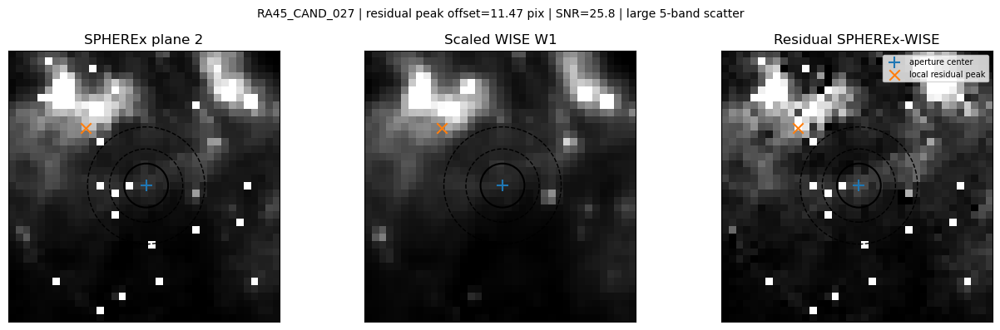

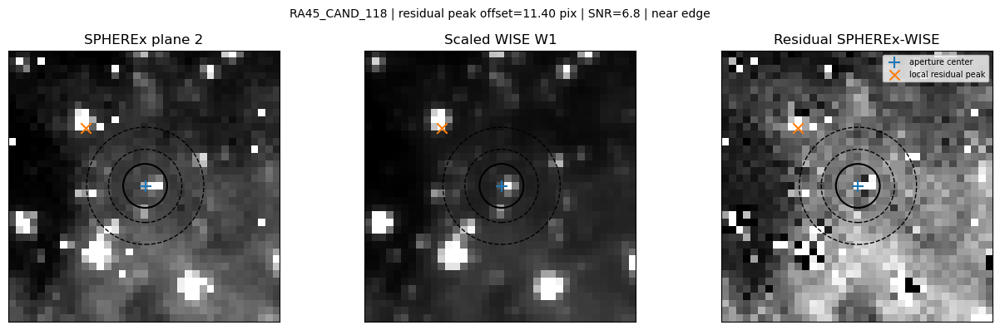

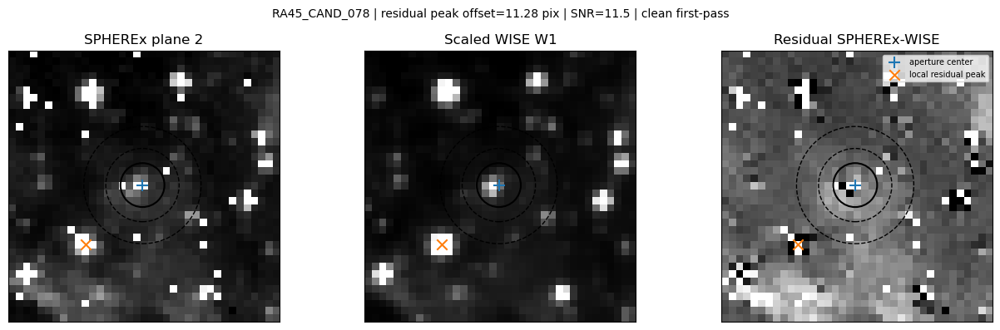

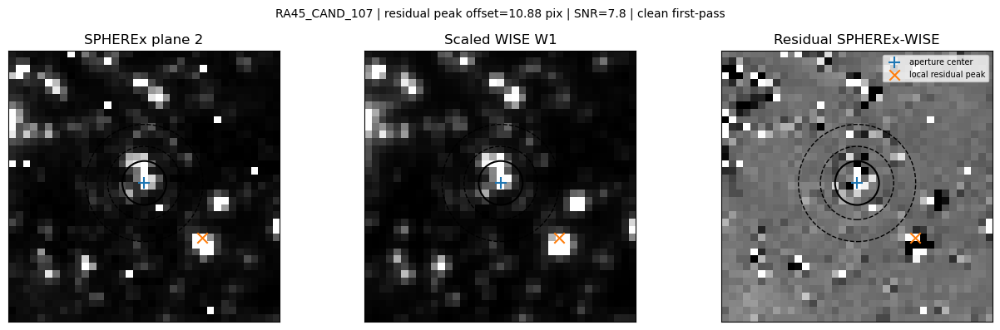

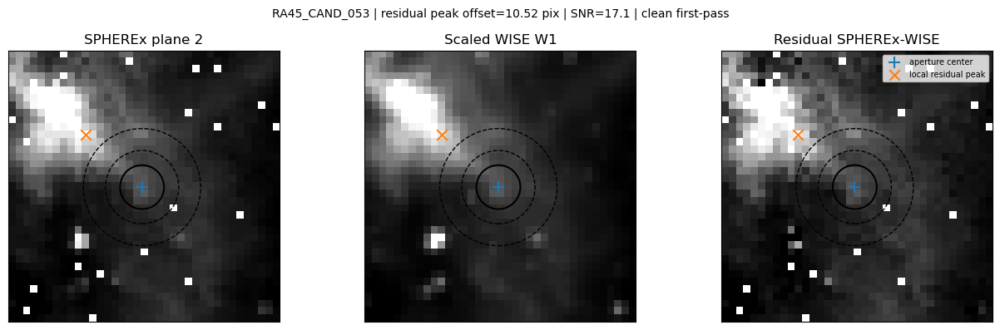

...

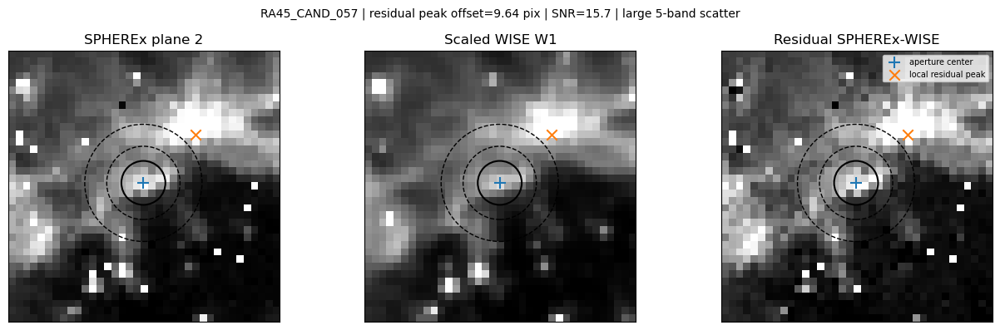

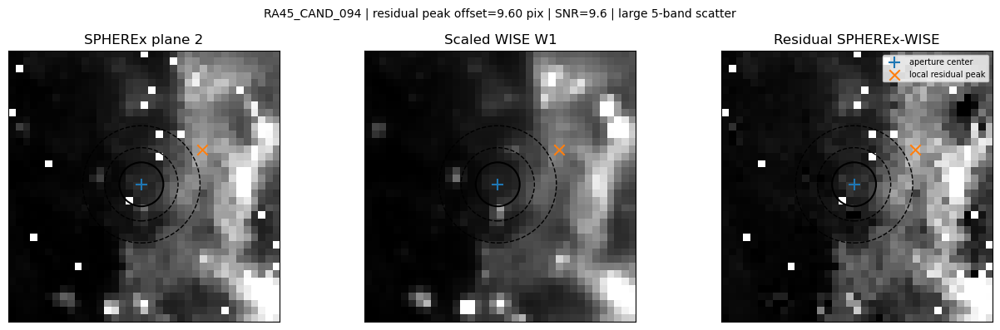

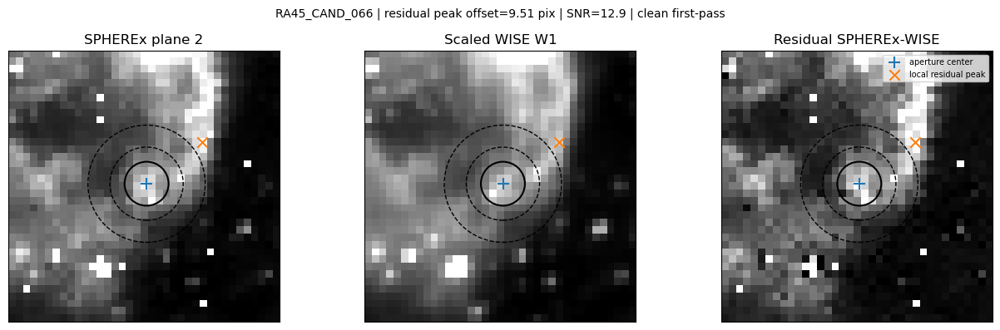

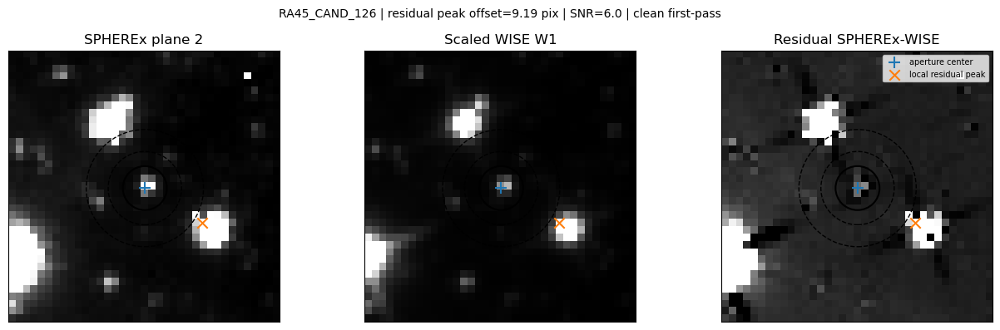

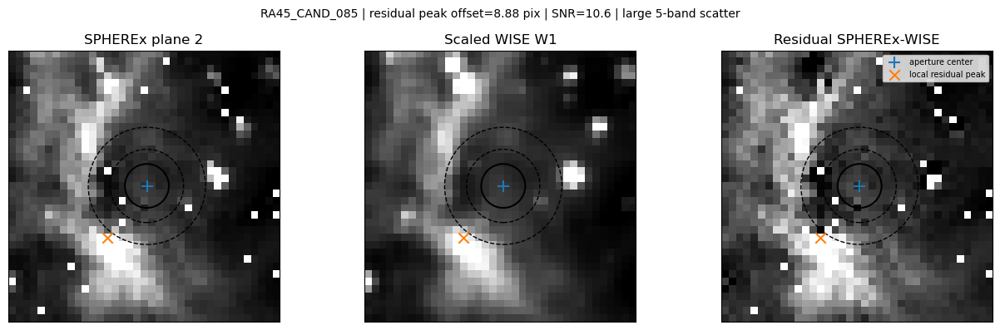

Saved off-center panels:
  RA45_CAND_019_offcenter_debug_panel.png
  RA45_CAND_027_offcenter_debug_panel.png
  RA45_CAND_039_offcenter_debug_panel.png
  RA45_CAND_043_offcenter_debug_panel.png
  RA45_CAND_049_offcenter_debug_panel.png
  RA45_CAND_051_offcenter_debug_panel.png
  RA45_CAND_053_offcenter_debug_panel.png
  RA45_CAND_057_offcenter_debug_panel.png
  RA45_CAND_066_offcenter_debug_panel.png
  RA45_CAND_078_offcenter_debug_panel.png
  RA45_CAND_080_offcenter_debug_panel.png
  RA45_CAND_082_offcenter_debug_panel.png
  RA45_CAND_085_offcenter_debug_panel.png
  RA45_CAND_092_offcenter_debug_panel.png
  RA45_CAND_094_offcenter_debug_panel.png
  RA45_CAND_096_offcenter_debug_panel.png
  RA45_CAND_099_offcenter_debug_panel.png
  RA45_CAND_107_offcenter_debug_panel.png
  RA45_CAND_118_offcenter_debug_panel.png
  RA45_CAND_126_offcenter_debug_panel.png


In [15]:
# ============================================================
# MAKE OFF-CENTER DEBUG PANELS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from astropy.io import fits

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

CORR_DIR = FIELD / "new_coordinates_corrected"
OUT_DIR = FIELD / "offcenter_debugging"
PANEL_DIR = OUT_DIR / "offcenter_panels"
PANEL_DIR.mkdir(parents=True, exist_ok=True)

DEBUG_CSV = OUT_DIR / "ra45_dec60p5_offcenter_debug_table.csv"

CUBE_PATH = FIELD / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"

SCALED_WISE_OPTIONS = [
    FIELD / "psf_tuning" / "wise_w1_scaled_psf_tuned_to_spherex_plane2.fits",
    FIELD / "photometric_scaling" / "wise_w1_scaled_to_spherex_plane2.fits",
]

RESIDUAL_OPTIONS = [
    CORR_DIR / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits",
    FIELD / "psf_tuning" / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits",
    FIELD / "photometric_scaling" / "spherex_plane2_minus_scaled_wise_w1.fits",
]

SCALED_WISE = next((p for p in SCALED_WISE_OPTIONS if p.exists()), None)
RESIDUAL = next((p for p in RESIDUAL_OPTIONS if p.exists()), None)

debug = pd.read_csv(DEBUG_CSV)

with fits.open(CUBE_PATH) as hdul:
    spx = hdul["IMAGE"].data[2].astype(float)

with fits.open(SCALED_WISE) as hdul:
    wise = hdul[0].data.astype(float)

with fits.open(RESIDUAL) as hdul:
    resid = hdul[0].data.astype(float)

def get_cutout(img, x, y, half=18):
    x_int = int(round(x))
    y_int = int(round(y))

    y0 = max(0, y_int - half)
    y1 = min(img.shape[0], y_int + half + 1)
    x0 = max(0, x_int - half)
    x1 = min(img.shape[1], x_int + half + 1)

    return img[y0:y1, x0:x1], x0, y0

def robust_limits(img, low=2, high=98):
    vals = img[np.isfinite(img)]
    if len(vals) == 0:
        return 0, 1
    return np.nanpercentile(vals, low), np.nanpercentile(vals, high)

# Make panels for top 20 most off-center residual cases
top = debug.sort_values("resid_peak_offset_pix", ascending=False).head(20).copy()

for _, row in top.iterrows():
    cid = row["candidate_id"]
    x = float(row["x_pix"])
    y = float(row["y_pix"])

    spx_cut, x0, y0 = get_cutout(spx, x, y)
    wise_cut, _, _ = get_cutout(wise, x, y)
    resid_cut, _, _ = get_cutout(resid, x, y)

    cx = x - x0
    cy = y - y0

    # local residual peak position in cutout coordinates
    rpx = row["resid_peak_x"] - x0
    rpy = row["resid_peak_y"] - y0

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))

    for ax, img, title in zip(
        axes,
        [spx_cut, wise_cut, resid_cut],
        ["SPHEREx plane 2", "Scaled WISE W1", "Residual SPHEREx-WISE"]
    ):
        vmin, vmax = robust_limits(img)
        ax.imshow(img, origin="lower", cmap="gray", vmin=vmin, vmax=vmax)

        # aperture center
        ax.scatter([cx], [cy], marker="+", s=100, label="aperture center")
        ax.add_patch(Circle((cx, cy), 3, fill=False, linewidth=1.5))
        ax.add_patch(Circle((cx, cy), 5, fill=False, linewidth=1, linestyle="--"))
        ax.add_patch(Circle((cx, cy), 8, fill=False, linewidth=1, linestyle="--"))

        # residual peak marker
        ax.scatter([rpx], [rpy], marker="x", s=80, label="local residual peak")

        ax.set_title(title)
        ax.set_xticks([])
        ax.set_yticks([])

    fig.suptitle(
        f"{cid} | residual peak offset={row['resid_peak_offset_pix']:.2f} pix | "
        f"SNR={row['residual_diff_snr_peak']:.1f} | {row['artifact_notes']}",
        fontsize=10
    )

    axes[2].legend(fontsize=7, loc="upper right")
    plt.tight_layout()

    out_png = PANEL_DIR / f"{cid}_offcenter_debug_panel.png"
    plt.savefig(out_png, dpi=200)
    plt.show()
    plt.close(fig)

print("Saved off-center panels:")
for p in sorted(PANEL_DIR.glob("*.png")):
    print(" ", p.name)

In [16]:
# ============================================================
# RECENTERING TEST — ORIGINAL CENTER VS LOCAL RESIDUAL PEAK
# Fresh-kernel safe
# Does NOT overwrite original candidates
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from astropy.io import fits
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

CORR_DIR = FIELD / "new_coordinates_corrected"
OFF_DIR = FIELD / "offcenter_debugging"
OUT_DIR = FIELD / "recenter_test"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CAND_TABLE = CORR_DIR / "ra45_dec60p5_full_candidate_review_table.csv"
OFFCENTER_CSV = OFF_DIR / "ra45_dec60p5_offcenter_debug_table.csv"

CUBE_PATH = FIELD / "spherex_raw" / "spherex_ra45_dec60p5_3p20_3p58_cube.fits"

RESIDUAL_OPTIONS = [
    CORR_DIR / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits",
    FIELD / "psf_tuning" / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits",
    FIELD / "photometric_scaling" / "spherex_plane2_minus_scaled_wise_w1.fits",
]

RESIDUAL = next((p for p in RESIDUAL_OPTIONS if p.exists()), None)
if RESIDUAL is None:
    raise FileNotFoundError("Missing residual FITS.")

cand = pd.read_csv(CAND_TABLE)
off = pd.read_csv(OFFCENTER_CSV)

with fits.open(CUBE_PATH) as hdul:
    cube = hdul["IMAGE"].data.astype(float)
    hdr = hdul["IMAGE"].header
    wcs = WCS(hdr, hdul).celestial
    wavelengths = np.array([row[2] for row in hdul["SPECTRAL_CHANNELS"].data], dtype=float)

    cdelt1_deg = float(hdr["CDELT1"])
    cdelt2_deg = float(hdr["CDELT2"])

with fits.open(RESIDUAL) as hdul:
    resid = hdul[0].data.astype(float)

pixel_area_sr = abs(cdelt1_deg * cdelt2_deg) * (np.pi / 180.0) ** 2

AP_RADIUS = 3.0
ANN_INNER = 5.0
ANN_OUTER = 8.0

def aperture_flux_mjy(image, x, y):
    pos = [(float(x), float(y))]
    aperture = CircularAperture(pos, r=AP_RADIUS)
    annulus = CircularAnnulus(pos, r_in=ANN_INNER, r_out=ANN_OUTER)

    try:
        ap_table = aperture_photometry(image, aperture, method="exact")
        ap_sum = float(ap_table["aperture_sum"][0])

        ann_mask = annulus.to_mask(method="center")[0]
        ann_data = ann_mask.multiply(image)

        ann_values = ann_data[np.isfinite(ann_data)]
        ann_values = ann_values[ann_values != 0]

        if len(ann_values) < 8:
            return np.nan, np.nan, np.nan

        _, bkg_med, bkg_std = sigma_clipped_stats(ann_values, sigma=3.0, maxiters=5)

        ap_area = aperture.area
        net_mjysr_pix = ap_sum - bkg_med * ap_area
        unc_mjysr_pix = bkg_std * np.sqrt(ap_area)

        flux_mjy = net_mjysr_pix * pixel_area_sr * 1e9
        unc_mjy = unc_mjysr_pix * pixel_area_sr * 1e9
        snr = flux_mjy / unc_mjy if np.isfinite(unc_mjy) and unc_mjy > 0 else np.nan

        return flux_mjy, unc_mjy, snr

    except Exception:
        return np.nan, np.nan, np.nan

def five_band_summary(x, y):
    fluxes = []
    snrs = []

    for k in range(cube.shape[0]):
        flux, unc, snr = aperture_flux_mjy(cube[k], x, y)
        fluxes.append(flux)
        snrs.append(snr)

    fluxes = np.array(fluxes, dtype=float)
    snrs = np.array(snrs, dtype=float)

    positive_count = int(np.sum(np.isfinite(fluxes) & (fluxes > 0)))
    snr3_count = int(np.sum(np.isfinite(snrs) & (snrs >= 3)))
    snr5_count = int(np.sum(np.isfinite(snrs) & (snrs >= 5)))

    median_flux = float(np.nanmedian(fluxes)) if np.isfinite(fluxes).any() else np.nan

    if np.isfinite(median_flux) and median_flux != 0:
        frac_scatter = float(np.nanstd(fluxes) / abs(median_flux))
    else:
        frac_scatter = np.nan

    max_snr = float(np.nanmax(snrs)) if np.isfinite(snrs).any() else np.nan

    return {
        "positive_flux_count_5": positive_count,
        "snr3_count_5": snr3_count,
        "snr5_count_5": snr5_count,
        "median_flux_mjy": median_flux,
        "max_snr_local": max_snr,
        "fractional_scatter_5band": frac_scatter,
    }

def residual_ap_snr(x, y):
    flux, unc, snr = aperture_flux_mjy(resid, x, y)
    return flux, unc, snr

# Merge offcenter proposed peak positions
m = cand.merge(
    off[[
        "candidate_id",
        "resid_peak_x",
        "resid_peak_y",
        "resid_peak_offset_pix",
        "spx_peak_offset_pix",
        "wise_peak_offset_pix",
    ]],
    on="candidate_id",
    how="left"
)

rows = []

for _, row in m.iterrows():
    cid = row["candidate_id"]

    old_x = float(row["x_pix"])
    old_y = float(row["y_pix"])

    new_x = float(row["resid_peak_x"])
    new_y = float(row["resid_peak_y"])

    # Original and recentered residual aperture SNR
    old_res_flux, old_res_unc, old_res_snr = residual_ap_snr(old_x, old_y)
    new_res_flux, new_res_unc, new_res_snr = residual_ap_snr(new_x, new_y)

    old_summary = five_band_summary(old_x, old_y)
    new_summary = five_band_summary(new_x, new_y)

    # Convert new xy to RA/Dec
    new_ra, new_dec = wcs.pixel_to_world_values(new_x, new_y)

    improvement = new_res_snr - old_res_snr if np.isfinite(new_res_snr) and np.isfinite(old_res_snr) else np.nan

    # Conservative recenter recommendation
    # Do not recommend huge jumps; do not recommend unless it improves residual SNR
    recommend = (
        np.isfinite(row["resid_peak_offset_pix"]) and
        row["resid_peak_offset_pix"] > 3 and
        row["resid_peak_offset_pix"] <= 6 and
        np.isfinite(improvement) and
        improvement > 2 and
        new_summary["positive_flux_count_5"] >= 3 and
        new_summary["snr5_count_5"] >= 3
    )

    rows.append({
        "candidate_id": cid,

        "old_x_pix": old_x,
        "old_y_pix": old_y,
        "old_ra_deg": row["ra_deg"],
        "old_dec_deg": row["dec_deg"],

        "new_x_pix": new_x,
        "new_y_pix": new_y,
        "new_ra_deg": new_ra,
        "new_dec_deg": new_dec,

        "resid_peak_offset_pix": row["resid_peak_offset_pix"],
        "spx_peak_offset_pix": row["spx_peak_offset_pix"],
        "wise_peak_offset_pix": row["wise_peak_offset_pix"],

        "old_residual_ap_flux_mjy": old_res_flux,
        "old_residual_ap_snr": old_res_snr,
        "new_residual_ap_flux_mjy": new_res_flux,
        "new_residual_ap_snr": new_res_snr,
        "residual_snr_improvement": improvement,

        "old_positive_flux_count_5": old_summary["positive_flux_count_5"],
        "old_snr5_count_5": old_summary["snr5_count_5"],
        "old_fractional_scatter_5band": old_summary["fractional_scatter_5band"],

        "new_positive_flux_count_5": new_summary["positive_flux_count_5"],
        "new_snr5_count_5": new_summary["snr5_count_5"],
        "new_fractional_scatter_5band": new_summary["fractional_scatter_5band"],

        "original_review_class": row.get("review_class", ""),
        "original_artifact_notes": row.get("artifact_notes", ""),

        "recommend_recenter": bool(recommend),
    })

out = pd.DataFrame(rows)

OUT_CSV = OUT_DIR / "ra45_dec60p5_recenter_test_original_vs_residual_peak.csv"
out.to_csv(OUT_CSV, index=False)

print("Saved recenter test table:")
print(OUT_CSV)

print("\nRecenter recommendations:")
print(out["recommend_recenter"].value_counts(dropna=False))

print("\nTop recenter candidates by residual SNR improvement:")
display(out.sort_values("residual_snr_improvement", ascending=False)[[
    "candidate_id",
    "resid_peak_offset_pix",
    "old_residual_ap_snr",
    "new_residual_ap_snr",
    "residual_snr_improvement",
    "old_positive_flux_count_5",
    "new_positive_flux_count_5",
    "old_snr5_count_5",
    "new_snr5_count_5",
    "old_fractional_scatter_5band",
    "new_fractional_scatter_5band",
    "original_review_class",
    "original_artifact_notes",
    "recommend_recenter",
]].head(30))

print("\nRecommended recenter cases:")
display(out[out["recommend_recenter"]][[
    "candidate_id",
    "old_ra_deg",
    "old_dec_deg",
    "new_ra_deg",
    "new_dec_deg",
    "resid_peak_offset_pix",
    "old_residual_ap_snr",
    "new_residual_ap_snr",
    "residual_snr_improvement",
    "new_positive_flux_count_5",
    "new_snr5_count_5",
    "new_fractional_scatter_5band",
]])

Saved recenter test table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\field_ra45_dec60p5\recenter_test\ra45_dec60p5_recenter_test_original_vs_residual_peak.csv

Recenter recommendations:
recommend_recenter
False    133
Name: count, dtype: int64

Top recenter candidates by residual SNR improvement:


,candidate_id,resid_peak_offset_pix,old_residual_ap_snr,new_residual_ap_snr,residual_snr_improvement,old_positive_flux_count_5,new_positive_flux_count_5,old_snr5_count_5,new_snr5_count_5,old_fractional_scatter_5band,new_fractional_scatter_5band,original_review_class,original_artifact_notes,recommend_recenter
33,RA45_CAND_069,6.430466,2.691622,22.725095,20.033473,4,4,3,4,0.233300,0.137241,BEST FIRST-PASS,clean first-pass,False
28,RA45_CAND_130,7.459987,0.317439,19.244287,18.926848,4,3,4,3,0.166063,0.313359,BEST FIRST-PASS,clean first-pass,False
16,RA45_CAND_107,10.882924,14.106645,31.317122,17.210477,4,4,4,4,0.089527,0.039032,BEST FIRST-PASS,clean first-pass,False
72,RA45_CAND_036,8.580297,3.104413,13.186764,10.082350,4,4,0,4,0.448753,0.484546,not top priority,large 5-band scatter,False
78,RA45_CAND_088,8.623606,2.733742,12.625028,9.891286,4,3,0,3,0.397978,0.237852,not top priority,large 5-band scatter,False
79,RA45_CAND_065,8.418651,1.659805,11.366756,9.706951,4,5,0,5,0.597234,0.483251,not top priority,large 5-band scatter,False
88,RA45_CAND_047,8.090154,0.765795,8.284345,7.518549,3,2,0,2,0.445983,0.137452,not top priority,large 5-band scatter,False
101,RA45_CAND_123,6.965595,-2.209329,4.258575,6.467904,2,3,2,3,0.070701,0.066855,not top priority,clean first-pass,False
76,RA45_CAND_023,7.188643,2.658695,8.284345,5.625649,5,2,0,2,0.542444,0.137452,not top priority,large 5-band scatter,False
66,RA45_CAND_025,8.308592,5.726163,10.660618,4.934456,5,3,0,3,0.705483,0.451520,not top priority,large 5-band scatter,False



Recommended recenter cases:


,candidate_id,old_ra_deg,old_dec_deg,new_ra_deg,new_dec_deg,resid_peak_offset_pix,old_residual_ap_snr,new_residual_ap_snr,residual_snr_improvement,new_positive_flux_count_5,new_snr5_count_5,new_fractional_scatter_5band


In [17]:
# ============================================================
# FINAL DR. HORA UPDATE PACKAGE
# Includes only new necessary deliverables from this round
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import shutil
import zipfile
import pandas as pd
import numpy as np

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD = BASE / "field_ra45_dec60p5"

OUT_DIR = FIELD / "dr_hora_update_package"
ZIP_OUT = FIELD / "dr_hora_update_package.zip"

if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

if ZIP_OUT.exists():
    ZIP_OUT.unlink()

# ------------------------------------------------------------
# Source folders
# ------------------------------------------------------------
RESID_DIR = FIELD / "residual_histogram_analysis"
RATIO_DIR = FIELD / "brightness_ratio_analysis"
TWOX_DIR = FIELD / "two_x_brightness_review"
VARWISE_DIR = FIELD / "varwise_crossmatch"
OFFCENTER_DIR = FIELD / "offcenter_debugging"
RECENTER_DIR = FIELD / "recenter_test"

# ------------------------------------------------------------
# Helper copy function
# ------------------------------------------------------------
def copy_if_exists(src, dst_folder=None, new_name=None):
    src = Path(src)
    if not src.exists():
        print("MISSING:", src)
        return False

    if dst_folder is None:
        dst_folder = OUT_DIR
    dst_folder = Path(dst_folder)
    dst_folder.mkdir(parents=True, exist_ok=True)

    dst_name = new_name if new_name is not None else src.name
    dst = dst_folder / dst_name

    if src.is_file():
        shutil.copy2(src, dst)
    else:
        if dst.exists():
            shutil.rmtree(dst)
        shutil.copytree(src, dst)

    print("Copied:", src.name)
    return True

# ------------------------------------------------------------
# 1. Residual histogram / cutoff deliverables
# ------------------------------------------------------------
resid_out = OUT_DIR / "01_residual_histogram_snr_cutoffs"
resid_files = [
    RESID_DIR / "ra45_dec60p5_residual_histogram_statistics.csv",
    RESID_DIR / "ra45_dec60p5_residual_pixel_histogram.png",
    RESID_DIR / "ra45_dec60p5_residual_pixel_snr_histogram.png",
    RESID_DIR / "ra45_dec60p5_candidate_residual_snr_histogram_clean_0_150.png",
    RESID_DIR / "ra45_dec60p5_candidate_residual_snr_histogram_logscale.png",
    RESID_DIR / "ra45_dec60p5_candidate_cutoff_summary_with_shortlist.csv",
    RESID_DIR / "ra45_dec60p5_candidates_above_20sigma.csv",
    RESID_DIR / "ra45_dec60p5_candidates_above_30sigma.csv",
    RESID_DIR / "ra45_dec60p5_candidates_above_50sigma.csv",
]

for f in resid_files:
    copy_if_exists(f, resid_out)

# ------------------------------------------------------------
# 2. 2x brightness ratio deliverables
# ------------------------------------------------------------
twox_out = OUT_DIR / "02_two_x_brightness_candidates"
twox_files = [
    RATIO_DIR / "ra45_dec60p5_spherex_over_wise_brightness_ratios.csv",
    RATIO_DIR / "ra45_dec60p5_spherex_over_wise_ratio_histogram.png",
    RATIO_DIR / "ra45_dec60p5_strong_2x_brightness_candidates.csv",
    TWOX_DIR / "ra45_dec60p5_candidates_above_2x_ratio_review.csv",
    TWOX_DIR / "ra45_dec60p5_2x_candidate_ratio_barplot.png",
    TWOX_DIR / "ra45_dec60p5_ratio_vs_residual_snr.png",
    TWOX_DIR / "ra45_dec60p5_2x_candidate_sky_map.png",
    TWOX_DIR / "README_2x_brightness_review.txt",
]

for f in twox_files:
    copy_if_exists(f, twox_out)

# Copy 2x review panels
copy_if_exists(TWOX_DIR / "candidate_review_panels", twox_out)

# ------------------------------------------------------------
# 3. VarWISE deliverables
# ------------------------------------------------------------
varwise_out = OUT_DIR / "03_varwise_crossmatch"
varwise_files = [
    VARWISE_DIR / "ra45_dec60p5_varwise_matched_candidates.csv",
    VARWISE_DIR / "ra45_dec60p5_varwise_pure_extended_matched_candidates.csv",
    VARWISE_DIR / "table_irsa_catalog_search_results.tbl",
    VARWISE_DIR / "table_irsa_catalog_search_results_extended.tbl",
    VARWISE_DIR / "ra45_dec60p5_candidates_GATOR_IPAC.tbl",
]

for f in varwise_files:
    copy_if_exists(f, varwise_out)

# ------------------------------------------------------------
# 4. Off-center debugging / recentering deliverables
# ------------------------------------------------------------
off_out = OUT_DIR / "04_offcenter_debugging"
off_files = [
    OFFCENTER_DIR / "ra45_dec60p5_offcenter_debug_table.csv",
    RECENTER_DIR / "ra45_dec60p5_recenter_test_original_vs_residual_peak.csv",
]

for f in off_files:
    copy_if_exists(f, off_out)

# Copy offcenter panels if they exist
copy_if_exists(OFFCENTER_DIR / "offcenter_panels", off_out)

# ------------------------------------------------------------
# Load key numbers for README
# ------------------------------------------------------------
def safe_read_csv(path):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    return pd.DataFrame()

stats = safe_read_csv(RESID_DIR / "ra45_dec60p5_residual_histogram_statistics.csv")
cutoffs = safe_read_csv(RESID_DIR / "ra45_dec60p5_candidate_cutoff_summary_with_shortlist.csv")
twox = safe_read_csv(TWOX_DIR / "ra45_dec60p5_candidates_above_2x_ratio_review.csv")
varwise = safe_read_csv(VARWISE_DIR / "ra45_dec60p5_varwise_pure_extended_matched_candidates.csv")
off = safe_read_csv(OFFCENTER_DIR / "ra45_dec60p5_offcenter_debug_table.csv")
recenter = safe_read_csv(RECENTER_DIR / "ra45_dec60p5_recenter_test_original_vs_residual_peak.csv")

# Residual stats
if len(stats) > 0:
    resid_med = float(stats.loc[0, "sigma_clipped_median"])
    resid_sig = float(stats.loc[0, "mad_robust_sigma"])
    th3 = float(stats.loc[0, "threshold_3sigma"])
    th5 = float(stats.loc[0, "threshold_5sigma"])
    th10 = float(stats.loc[0, "threshold_10sigma"])
    th20 = float(stats.loc[0, "threshold_20sigma"])
else:
    resid_med = resid_sig = th3 = th5 = th10 = th20 = np.nan

# Cutoff counts
def cutoff_count(cutoff):
    if len(cutoffs) == 0:
        return "NA"
    row = cutoffs[cutoffs["residual_snr_cutoff"] == cutoff]
    if len(row) == 0:
        return "NA"
    return int(row.iloc[0]["n_raw_candidates_above_cutoff"])

n5 = cutoff_count(5)
n10 = cutoff_count(10)
n20 = cutoff_count(20)
n30 = cutoff_count(30)
n50 = cutoff_count(50)

# 2x
n_2x = len(twox)
max_2x = float(twox["spherex_over_wise_expected_ratio"].max()) if len(twox) and "spherex_over_wise_expected_ratio" in twox.columns else np.nan
n_2x_shortlist = int(twox["in_corrected_shortlist"].sum()) if len(twox) and "in_corrected_shortlist" in twox.columns else 0
n_2x_best = int((twox["review_class"] == "BEST FIRST-PASS").sum()) if len(twox) and "review_class" in twox.columns else 0

# VarWISE unique
if len(varwise) > 0 and "candidate_id" in varwise.columns:
    unique_varwise = varwise.drop_duplicates(subset=["candidate_id", "varwise_designation"])
    n_varwise_unique = unique_varwise["candidate_id"].nunique()
    varwise_lines = []
    for _, r in unique_varwise.iterrows():
        varwise_lines.append(
            f"- {r.get('candidate_id', '')}: {r.get('varwise_designation', '')}, "
            f"match distance {r.get('varwise_match_dist_arcsec', np.nan):.3f} arcsec, "
            f"residual SNR {r.get('residual_diff_snr_peak', np.nan):.2f}, "
            f"2x flag {r.get('brightness_2x_or_higher', False)}"
        )
    varwise_text = "\n".join(varwise_lines)
else:
    n_varwise_unique = 0
    varwise_text = "- No VarWISE matches found."

# Offcenter
n_offcenter = int((off["resid_peak_offset_pix"] > 3).sum()) if len(off) and "resid_peak_offset_pix" in off.columns else "NA"
n_total_off = len(off) if len(off) else "NA"
n_recenter = int(recenter["recommend_recenter"].sum()) if len(recenter) and "recommend_recenter" in recenter.columns else 0

# ------------------------------------------------------------
# Technical README
# ------------------------------------------------------------
README = OUT_DIR / "README_dr_hora_update.txt"

readme_text = f"""RA45_DEC60P5 SPHEREx/WISE Update Package

Field:
RA = 45.0 deg
Dec = 60.5 deg

Purpose of this update:
This package contains the new follow-up analyses requested after the IRSA aperture-correction calibration:
1. residual histogram and SNR cutoff analysis,
2. SPHEREx/WISE >=2x brightness-ratio candidate review,
3. VarWISE Pure/Extended catalog cross-match,
4. off-center candidate debugging and recentering test.

1. Residual histogram / SNR cutoff analysis
Residual image used:
SPHEREx plane 2 at ~3.383 um minus scaled/PSF-tested WISE W1.

Robust residual statistics:
sigma-clipped median = {resid_med:.6f}
MAD robust sigma = {resid_sig:.6f}

Positive residual image-value thresholds:
3 sigma = {th3:.6f}
5 sigma = {th5:.6f}
10 sigma = {th10:.6f}
20 sigma = {th20:.6f}

Candidate counts by residual-SNR cutoff:
>=5 sigma: {n5}
>=10 sigma: {n10}
>=20 sigma: {n20}
>=30 sigma: {n30}
>=50 sigma: {n50}

Interpretation:
The 5 sigma cutoff is too loose because it retains essentially all raw detections.
The 20-30 sigma range is a more useful high-confidence range.
The >=50 sigma cases are extremely strong residuals, but those are not automatically better because very strong residuals can also be caused by bright-source subtraction artifacts or structured background.

2. SPHEREx/WISE >=2x brightness-ratio review
For each candidate, I measured:
SPHEREx corrected plane-2 flux / WISE-expected plane-2 flux.

Result:
Number of candidates with ratio >=2x: {n_2x}
Maximum ratio found: {max_2x:.3f}
Number of >=2x sources also in corrected final shortlist: {n_2x_shortlist}
Number of >=2x sources marked BEST FIRST-PASS: {n_2x_best}

Interpretation:
There are sources above the 2x brightness-ratio threshold, up to about {max_2x:.3f}x.
However, the >=2x sources do not pass the stricter clean-candidate criteria. Most are flagged by large five-band scatter and/or weaker nearby-wavelength persistence, so they are provided as a separate review set rather than merged into the best-candidate shortlist.

3. VarWISE Pure/Extended cross-match
Cross-match radius:
3 arcsec

Result:
Unique VarWISE-matched candidates: {n_varwise_unique}

Matched sources:
{varwise_text}

Interpretation:
The pipeline recovered one known VarWISE source in the field. However, the matched source is not one of the strong SPHEREx-brightening or >=2x candidates. Therefore this confirms that the cross-match workflow is working, but it does not validate one of the strongest excess candidates as already-known in VarWISE. None of the >=2x candidates matched VarWISE within 3 arcsec.

4. Off-center debugging and recentering test
Reason for test:
Some review-panel sources appeared off-center in either the original or residual images.

Method:
For each candidate, I compared the original aperture center to the brightest local residual peak near the source. I also tested whether shifting/recentering the aperture to that residual peak improved the residual aperture SNR and preserved the five-band persistence requirements.

Off-center result:
Candidates with local residual peak >3 pixels from original aperture center: {n_offcenter} out of {n_total_off}

Recenter test result:
Automatically recommended recenter cases: {n_recenter}

Interpretation:
The off-center issue does not appear to be a global astrometric/WCS problem, because the earlier global SPHEREx/WISE astrometric offset was very small. The off-centering is more consistent with local candidate-level effects such as nearby structure, nebulosity, blending, or subtraction artifacts. I did not automatically replace candidate coordinates because no candidates passed the conservative safe-recentering criteria. Therefore these cases should be flagged for visual/artifact review rather than blindly recentered.

Main package folders:
01_residual_histogram_snr_cutoffs/
02_two_x_brightness_candidates/
03_varwise_crossmatch/
04_offcenter_debugging/

Bottom-line summary:
- Residual histograms and SNR cutoffs were generated.
- A 20-30 sigma residual cutoff looks more useful than 5 sigma.
- 10 candidates exceed the >=2x SPHEREx/WISE brightness-ratio condition, with a maximum ratio of {max_2x:.3f}x.
- Those >=2x candidates are interesting but not clean high-confidence variables yet because they fail stricter persistence/scatter filtering.
- VarWISE Pure/Extended cross-match found one known variable source, RA45_CAND_109 / VarWISE J025825.02+605331.9, but it is not a strong SPHEREx excess source in this analysis.
- The off-center issue is not a global image-alignment problem. It is most likely local blending/background/subtraction structure. No candidate was safely recentered automatically.
"""

README.write_text(readme_text, encoding="utf-8")

# ------------------------------------------------------------
# Also create a short email-note file
# ------------------------------------------------------------
EMAIL = OUT_DIR / "email_summary_to_dr_hora.txt"

email_text = f"""Hi Dr. Hora,

I completed the follow-up checks you suggested for the RA=45.0, Dec=60.5 field.

First, I generated residual histograms for the SPHEREx 3.383 um minus scaled/PSF-tested WISE W1 difference image. The robust residual sigma from the MAD estimate was {resid_sig:.6f}, and the candidate-level cutoff table shows that 5 sigma keeps essentially all raw detections, while the 20-30 sigma range is much more selective. In this field, there are {n20} candidates above 20 sigma and {n30} above 30 sigma.

I also calculated the SPHEREx/WISE brightness ratio using the IRSA-aperture-corrected SPHEREx plane-2 flux divided by the WISE-expected plane-2 flux. There are {n_2x} candidates above the 2x threshold, with a maximum ratio of {max_2x:.3f}x. However, these 2x sources did not pass the stricter final shortlist filters; most are flagged by large five-band scatter or weaker nearby-wavelength persistence, so I kept them as a separate review set.

I cross-matched the candidates against both VarWISE Pure and Extended using a 3 arcsec radius. There was one unique VarWISE match: RA45_CAND_109 matched VarWISE J025825.02+605331.9 at 0.489 arcsec. This confirms the cross-match workflow is working, but that source is not one of the strong SPHEREx excess or >=2x candidates in the current analysis.

I also investigated the off-centered sources. I compared each aperture center to the brightest nearby residual peak and then tested whether recentering would improve the residual SNR while preserving the five-band persistence criteria. Although some sources have nearby residual peaks several pixels away, no candidates passed the conservative safe-recentering criteria. Since the global SPHEREx/WISE astrometric offset was already very small, the off-centering seems more likely to be caused by local blending, nebulosity, or subtraction structure rather than a global WCS alignment issue.

I put the new plots, tables, review panels, VarWISE results, and off-center debugging results into the attached update package.

Best,
Vishwas
"""

EMAIL.write_text(email_text, encoding="utf-8")

# ------------------------------------------------------------
# Zip package
# ------------------------------------------------------------
with zipfile.ZipFile(ZIP_OUT, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT_DIR.rglob("*"):
        z.write(p, arcname=p.relative_to(OUT_DIR.parent))

print("\nCreated final Dr. Hora update package:")
print(ZIP_OUT)

print("\nPackage contents:")
for p in sorted(OUT_DIR.rglob("*")):
    print(" ", p.relative_to(OUT_DIR))

Copied: ra45_dec60p5_residual_histogram_statistics.csv
Copied: ra45_dec60p5_residual_pixel_histogram.png
Copied: ra45_dec60p5_residual_pixel_snr_histogram.png
Copied: ra45_dec60p5_candidate_residual_snr_histogram_clean_0_150.png
Copied: ra45_dec60p5_candidate_residual_snr_histogram_logscale.png
Copied: ra45_dec60p5_candidate_cutoff_summary_with_shortlist.csv
Copied: ra45_dec60p5_candidates_above_20sigma.csv
Copied: ra45_dec60p5_candidates_above_30sigma.csv
Copied: ra45_dec60p5_candidates_above_50sigma.csv
Copied: ra45_dec60p5_spherex_over_wise_brightness_ratios.csv
Copied: ra45_dec60p5_spherex_over_wise_ratio_histogram.png
Copied: ra45_dec60p5_strong_2x_brightness_candidates.csv
Copied: ra45_dec60p5_candidates_above_2x_ratio_review.csv
Copied: ra45_dec60p5_2x_candidate_ratio_barplot.png
Copied: ra45_dec60p5_ratio_vs_residual_snr.png
Copied: ra45_dec60p5_2x_candidate_sky_map.png
Copied: README_2x_brightness_review.txt
Copied: candidate_review_panels
Copied: ra45_dec60p5_varwise_matched_

In [1]:
# ============================================================
# CELL 1 — GENERATE NEW SEARCH COORDINATES ALONG GALACTIC POSITION
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from astropy.coordinates import SkyCoord
import astropy.units as u

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
SEARCH_DIR = BASE / "galactic_search_points"
SEARCH_DIR.mkdir(parents=True, exist_ok=True)

# Current successful field
START_RA = 45.0
START_DEC = 60.5

start_eq = SkyCoord(ra=START_RA*u.deg, dec=START_DEC*u.deg, frame="icrs")
start_gal = start_eq.galactic

start_l = start_gal.l.deg
start_b = start_gal.b.deg

print("Starting field:")
print(f"RA  = {START_RA:.6f} deg")
print(f"Dec = {START_DEC:.6f} deg")
print(f"Galactic l = {start_l:.6f} deg")
print(f"Galactic b = {start_b:.6f} deg")

# ------------------------------------------------------------
# Generate nearby points.
# l changes move along the Galactic plane direction.
# b changes move above/below the Galactic plane.
# ------------------------------------------------------------

rows = []

# Use ~1 degree spacing because our mosaic is about 1 degree wide.
# These are nearby fields along Galactic longitude at the same Galactic latitude.
l_offsets = [-3, -2, -1, 1, 2, 3]  # degrees
b_offsets = [0]                    # same latitude first

field_num = 1

for db in b_offsets:
    for dl in l_offsets:
        new_l = (start_l + dl) % 360
        new_b = start_b + db

        gal = SkyCoord(l=new_l*u.deg, b=new_b*u.deg, frame="galactic")
        eq = gal.icrs

        rows.append({
            "field_id": f"GAL_SEARCH_{field_num:03d}",
            "gal_l_deg": new_l,
            "gal_b_deg": new_b,
            "ra_deg": eq.ra.deg,
            "dec_deg": eq.dec.deg,
            "l_offset_from_start_deg": dl,
            "b_offset_from_start_deg": db,
            "notes": "same Galactic latitude, shifted along Galactic longitude"
        })

        field_num += 1

# Add a few latitude-offset points too, because he mentioned position may be slightly tipped.
# These check slightly above/below the current Galactic latitude.
for db in [-1.0, -0.5, 0.5, 1.0]:
    new_l = start_l
    new_b = start_b + db

    gal = SkyCoord(l=new_l*u.deg, b=new_b*u.deg, frame="galactic")
    eq = gal.icrs

    rows.append({
        "field_id": f"GAL_SEARCH_{field_num:03d}",
        "gal_l_deg": new_l,
        "gal_b_deg": new_b,
        "ra_deg": eq.ra.deg,
        "dec_deg": eq.dec.deg,
        "l_offset_from_start_deg": 0,
        "b_offset_from_start_deg": db,
        "notes": "same Galactic longitude, shifted in Galactic latitude"
    })

    field_num += 1

coords = pd.DataFrame(rows)

OUT_CSV = SEARCH_DIR / "new_galactic_search_coordinates.csv"
coords.to_csv(OUT_CSV, index=False)

print("\nSaved new search coordinate list:")
print(OUT_CSV)

print("\nNew coordinates to try:")
display(coords)

Starting field:
RA  = 45.000000 deg
Dec = 60.500000 deg
Galactic l = 138.123973 deg
Galactic b = 1.477295 deg

Saved new search coordinate list:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\galactic_search_points\new_galactic_search_coordinates.csv

New coordinates to try:


,field_id,gal_l_deg,gal_b_deg,ra_deg,dec_deg,l_offset_from_start_deg,b_offset_from_start_deg,notes
0,GAL_SEARCH_001,135.123973,1.477295,39.404538,61.809412,-3,0.0,"same Galactic latitude, shifted along Galactic..."
1,GAL_SEARCH_002,136.123973,1.477295,41.320809,61.398378,-2,0.0,"same Galactic latitude, shifted along Galactic..."
2,GAL_SEARCH_003,137.123973,1.477295,43.186170,60.961522,-1,0.0,"same Galactic latitude, shifted along Galactic..."
3,GAL_SEARCH_004,139.123973,1.477295,46.762062,60.014960,1,0.0,"same Galactic latitude, shifted along Galactic..."
4,GAL_SEARCH_005,140.123973,1.477295,48.472455,59.507534,2,0.0,"same Galactic latitude, shifted along Galactic..."
5,GAL_SEARCH_006,141.123973,1.477295,50.131575,58.978832,3,0.0,"same Galactic latitude, shifted along Galactic..."
6,GAL_SEARCH_007,138.123973,0.477295,44.063599,59.615917,0,-1.0,"same Galactic longitude, shifted in Galactic l..."
7,GAL_SEARCH_008,138.123973,0.977295,44.525528,60.058786,0,-0.5,"same Galactic longitude, shifted in Galactic l..."
8,GAL_SEARCH_009,138.123973,1.977295,45.487540,60.939484,0,0.5,"same Galactic longitude, shifted in Galactic l..."
9,GAL_SEARCH_010,138.123973,2.477295,45.988699,61.377157,0,1.0,"same Galactic longitude, shifted in Galactic l..."


In [2]:
# ============================================================
# CELL 2 — SET UP FIRST NEW GALACTIC SEARCH FIELD
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
SEARCH_DIR = BASE / "galactic_search_points"

COORD_CSV = SEARCH_DIR / "new_galactic_search_coordinates.csv"

coords = pd.read_csv(COORD_CSV)

# Choose first new test field
FIELD_ID = "GAL_SEARCH_003"

row = coords[coords["field_id"] == FIELD_ID].iloc[0]

RA = float(row["ra_deg"])
DEC = float(row["dec_deg"])
GAL_L = float(row["gal_l_deg"])
GAL_B = float(row["gal_b_deg"])

# Clean folder name
FIELD_NAME = f"{FIELD_ID}_ra{RA:.4f}_dec{DEC:.4f}".replace(".", "p").replace("-", "m")
FIELD_DIR = BASE / FIELD_NAME

# Create standard folders
for sub in [
    "spherex_raw",
    "wise_raw",
    "aligned",
    "diagnostics",
    "photometric_scaling",
    "psf_tuning",
    "candidate_detection",
    "nearby_wavelength_photometry",
    "final_review",
    "search_summary",
]:
    (FIELD_DIR / sub).mkdir(parents=True, exist_ok=True)

print("NEW FIELD SETUP")
print("Field ID:", FIELD_ID)
print("Field folder:")
print(FIELD_DIR)

print("\nUse these coordinates for SPHEREx and WISE:")
print(f"RA  = {RA:.6f}")
print(f"Dec = {DEC:.6f}")

print("\nGalactic position:")
print(f"l = {GAL_L:.6f}")
print(f"b = {GAL_B:.6f}")

print("\nSPHEREx Mosaic Tool settings:")
print("Center:", f"{RA:.6f} {DEC:.6f}")
print("Size: 60 arcmin x 60 arcmin")
print("Pixel size: 6.2 arcsec")
print("Wavelength range: 3.20 to 3.58 um")
print("Suggested title:", f"{FIELD_ID}_BAND4_3p20_3p58")

NEW FIELD SETUP
Field ID: GAL_SEARCH_003
Field folder:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615

Use these coordinates for SPHEREx and WISE:
RA  = 43.186170
Dec = 60.961522

Galactic position:
l = 137.123973
b = 1.477295

SPHEREx Mosaic Tool settings:
Center: 43.186170 60.961522
Size: 60 arcmin x 60 arcmin
Pixel size: 6.2 arcsec
Wavelength range: 3.20 to 3.58 um
Suggested title: GAL_SEARCH_003_BAND4_3p20_3p58


In [3]:
# ============================================================
# CELL 3 — VERIFY NEW SPHEREX CUBE
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

FIELD_ID = "GAL_SEARCH_003"
FIELD_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"

CUBE_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_003_3p20_3p58_cube.fits"

RA = 43.186170
DEC = 60.961522

if not CUBE_PATH.exists():
    raise FileNotFoundError(f"Missing cube: {CUBE_PATH}")

with fits.open(CUBE_PATH) as hdul:
    print("HDU list:")
    hdul.info()

    img = hdul["IMAGE"].data
    hdr = hdul["IMAGE"].header
    wcs = WCS(hdr, hdul).celestial

    print("\nIMAGE shape:", img.shape)
    print("BUNIT:", hdr.get("BUNIT"))
    print("CDELT1:", hdr.get("CDELT1"))
    print("CDELT2:", hdr.get("CDELT2"))

    x, y = wcs.world_to_pixel_values(RA, DEC)

    print("\nCenter coordinate pixel:")
    print("x =", x)
    print("y =", y)

    print("\nPlane stats:")
    for k in range(img.shape[0]):
        plane = img[k].astype(float)
        finite = np.isfinite(plane)
        print(
            k,
            "finite:", finite.sum(),
            "min:", np.nanmin(plane),
            "median:", np.nanmedian(plane),
            "max:", np.nanmax(plane),
        )

    print("\nSpectral channels:")
    spec = hdul["SPECTRAL_CHANNELS"].data
    print(spec)

HDU list:
Filename: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\spherex_raw\spherex_GAL_SEARCH_003_3p20_3p58_cube.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU        51   (581, 581, 5)   float32   
  2  NHITS         1 ImageHDU        51   (581, 581, 5)   int32   
  3  FLAGS         1 ImageHDU        55   (581, 581, 5)   int32   
  4  SPECTRAL_CHANNELS    1 BinTableHDU     29   5R x 8C   [I, I, E, E, E, E, E, E]   
  5  WCS-WAVE      1 BinTableHDU     18   1R x 3C   [5J, 5E, 5E]   

IMAGE shape: (5, 581, 581)
BUNIT: MJy/sr
CDELT1: -0.0017222222222222
CDELT2: 0.0017222222222222

Center coordinate pixel:
x = 290.0
y = 289.99999999999795

Plane stats:
0 finite: 333959 min: -0.6434048414230347 median: 0.36537599563598633 max: 2529.921875
1 finite: 333879 min: -1.3958388566970825 median: 0.7570334672927856 max: 2554.2373046875
2 finite: 333855 min: -9.7

In [6]:
# ============================================================
# CELL 4 — VERIFY WISE W1 IMAGE FOR GAL_SEARCH_003
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

FIELD_ID = "GAL_SEARCH_003"
FIELD_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"

WISE_PATH = FIELD_DIR / "wise_raw" / "wise_w1_GAL_SEARCH_003_intensity.fits"

RA = 43.186170
DEC = 60.961522

if not WISE_PATH.exists():
    raise FileNotFoundError(f"Missing WISE file: {WISE_PATH}")

with fits.open(WISE_PATH) as hdul:
    print("HDU list:")
    hdul.info()

    data = hdul[0].data.astype(float)
    hdr = hdul[0].header
    wcs = WCS(hdr)

    print("\nWISE shape:", data.shape)
    print("BUNIT:", hdr.get("BUNIT"))
    print("CRVAL1:", hdr.get("CRVAL1"))
    print("CRVAL2:", hdr.get("CRVAL2"))
    print("CDELT1:", hdr.get("CDELT1"))
    print("CDELT2:", hdr.get("CDELT2"))

    x, y = wcs.world_to_pixel_values(RA, DEC)

    print("\nTarget coordinate pixel in WISE:")
    print("x =", x)
    print("y =", y)

    print("\nWISE stats:")
    finite = np.isfinite(data)
    print("finite:", finite.sum())
    print("min:", np.nanmin(data))
    print("median:", np.nanmedian(data))
    print("max:", np.nanmax(data))

    inside = (
        x >= 0 and x < data.shape[1] and
        y >= 0 and y < data.shape[0]
    )

    print("\nTarget inside WISE image?", inside)

HDU list:
Filename: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\wise_raw\wise_w1_GAL_SEARCH_003_intensity.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      67   (4095, 4095)   float32   

WISE shape: (4095, 4095)
BUNIT: DN
CRVAL1: 42.000705
CRVAL2: 60.577778
CDELT1: -0.0003819444391411
CDELT2: 0.0003819444391411

Target coordinate pixel in WISE:
x = 540.5506424357543
y = 3065.278944093865

WISE stats:
finite: 16768974
min: 3.4114341735839844
median: 8.052539348602295
max: 5009.54052734375

Target inside WISE image? True


Reprojecting WISE to SPHEREx grid...
Saved reprojected WISE:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\aligned\wise_w1_reprojected_to_spherex_grid.fits

Overlap stats:
SPHEREx plane2 finite: 333855
WISE reprojected finite: 213313
Valid overlap: 211331

Reprojected WISE stats:
min: 4.1883616923923155
median: 9.573562375137248
max: 4067.0304606763193


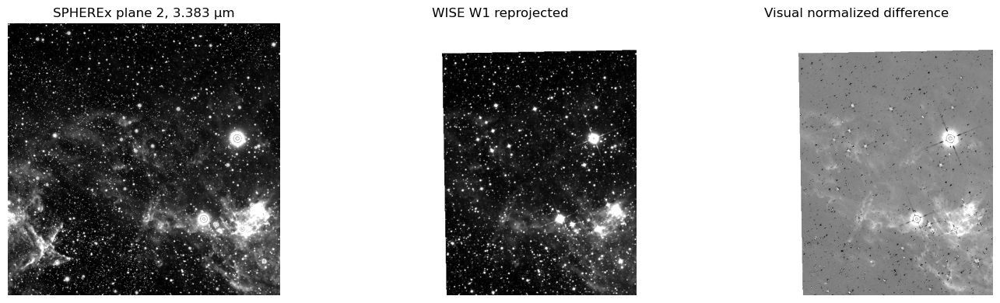


Saved alignment check plot:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\diagnostics\spherex_wise_alignment_check.png


In [7]:
# ============================================================
# CELL 5 — REPROJECT WISE W1 ONTO SPHEREX GRID
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from reproject import reproject_interp

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

FIELD_ID = "GAL_SEARCH_003"
FIELD_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"

CUBE_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_003_3p20_3p58_cube.fits"
WISE_PATH = FIELD_DIR / "wise_raw" / "wise_w1_GAL_SEARCH_003_intensity.fits"

OUT_DIR = FIELD_DIR / "aligned"
DIAG_DIR = FIELD_DIR / "diagnostics"
OUT_DIR.mkdir(parents=True, exist_ok=True)
DIAG_DIR.mkdir(parents=True, exist_ok=True)

OUT_WISE_REPROJECTED = OUT_DIR / "wise_w1_reprojected_to_spherex_grid.fits"
OUT_ALIGN_PNG = DIAG_DIR / "spherex_wise_alignment_check.png"

# Load SPHEREx WCS/shape
with fits.open(CUBE_PATH) as spx_hdul:
    spx_data = spx_hdul["IMAGE"].data.astype(float)
    spx_hdr = spx_hdul["IMAGE"].header
    spx_wcs = WCS(spx_hdr, spx_hdul).celestial

    # Target output header should be celestial only, 2D
    out_header = spx_wcs.to_header()
    out_header["NAXIS"] = 2
    out_header["NAXIS1"] = spx_data.shape[2]
    out_header["NAXIS2"] = spx_data.shape[1]

    target_shape = (spx_data.shape[1], spx_data.shape[2])

# Load WISE
with fits.open(WISE_PATH) as wise_hdul:
    wise_data = wise_hdul[0].data.astype(float)
    wise_hdr = wise_hdul[0].header
    wise_wcs = WCS(wise_hdr)

    print("Reprojecting WISE to SPHEREx grid...")
    wise_reproj, footprint = reproject_interp(
        (wise_data, wise_wcs),
        out_header,
        shape_out=target_shape
    )

# Save reprojected WISE
hdu = fits.PrimaryHDU(wise_reproj.astype(np.float32), header=out_header)
hdu.header["BUNIT"] = "DN"
hdu.header["HISTORY"] = "WISE W1 reprojected to SPHEREx GAL_SEARCH_003 grid"
hdu.writeto(OUT_WISE_REPROJECTED, overwrite=True)

print("Saved reprojected WISE:")
print(OUT_WISE_REPROJECTED)

# Basic overlap check with SPHEREx plane 2
spx_plane2 = spx_data[2]
valid = np.isfinite(spx_plane2) & np.isfinite(wise_reproj)

print("\nOverlap stats:")
print("SPHEREx plane2 finite:", np.isfinite(spx_plane2).sum())
print("WISE reprojected finite:", np.isfinite(wise_reproj).sum())
print("Valid overlap:", valid.sum())

print("\nReprojected WISE stats:")
print("min:", np.nanmin(wise_reproj))
print("median:", np.nanmedian(wise_reproj))
print("max:", np.nanmax(wise_reproj))

# Alignment visual check
def robust_limits(img, low=2, high=98):
    vals = img[np.isfinite(img)]
    return np.nanpercentile(vals, low), np.nanpercentile(vals, high)

spx_vmin, spx_vmax = robust_limits(spx_plane2)
wise_vmin, wise_vmax = robust_limits(wise_reproj)

# Normalize for rough visual comparison
spx_norm = (spx_plane2 - spx_vmin) / (spx_vmax - spx_vmin)
wise_norm = (wise_reproj - wise_vmin) / (wise_vmax - wise_vmin)

diff_display = spx_norm - wise_norm

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(spx_plane2, origin="lower", cmap="gray", vmin=spx_vmin, vmax=spx_vmax)
plt.title("SPHEREx plane 2, 3.383 µm")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(wise_reproj, origin="lower", cmap="gray", vmin=wise_vmin, vmax=wise_vmax)
plt.title("WISE W1 reprojected")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(diff_display, origin="lower", cmap="gray", vmin=-0.5, vmax=0.5)
plt.title("Visual normalized difference")
plt.axis("off")

plt.tight_layout()
plt.savefig(OUT_ALIGN_PNG, dpi=200)
plt.show()

print("\nSaved alignment check plot:")
print(OUT_ALIGN_PNG)

Valid overlap pixels: 211331
SPHEREx sources: 270
SPHEREx columns: ['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']
WISE sources: 394
WISE columns: ['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']

Matched sources: 238
Median dx pix, WISE-SPHEREx: 0.004228142782665145
Median dy pix, WISE-SPHEREx: -0.007131462813589451
Median match distance pix: 0.11719563275344796
Median dx arcsec: 0.0262144852525239
Median dy arcsec: -0.044215069444254594


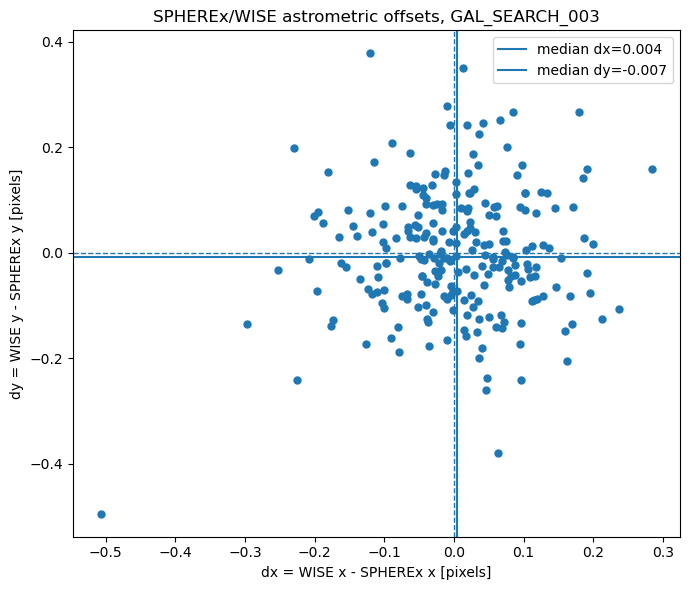


Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\alignment_check\spherex_wise_matched_sources_astrometry.csv
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\alignment_check\spherex_wise_astrometric_offsets.png


In [8]:
# ============================================================
# CELL 6 — ASTROMETRIC MATCH CHECK FOR GAL_SEARCH_003
# Uses existing WISE overlap only
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder
from scipy.spatial import cKDTree

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

FIELD_ID = "GAL_SEARCH_003"
FIELD_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"

CUBE_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_003_3p20_3p58_cube.fits"
WISE_REPROJECTED = FIELD_DIR / "aligned" / "wise_w1_reprojected_to_spherex_grid.fits"

OUT_DIR = FIELD_DIR / "alignment_check"
OUT_DIR.mkdir(parents=True, exist_ok=True)

OUT_CSV = OUT_DIR / "spherex_wise_matched_sources_astrometry.csv"
OUT_PNG = OUT_DIR / "spherex_wise_astrometric_offsets.png"

with fits.open(CUBE_PATH) as hdul:
    spx = hdul["IMAGE"].data[2].astype(float)

with fits.open(WISE_REPROJECTED) as hdul:
    wise = hdul[0].data.astype(float)

valid = np.isfinite(spx) & np.isfinite(wise)

print("Valid overlap pixels:", valid.sum())

# Mask outside overlap
spx_work = np.where(valid, spx, np.nan)
wise_work = np.where(valid, wise, np.nan)

def detect_sources(img, label, fwhm=3.0, nsigma=8.0):
    vals = img[np.isfinite(img)]
    mean, med, std = sigma_clipped_stats(vals, sigma=3.0, maxiters=5)

    finder = DAOStarFinder(fwhm=fwhm, threshold=nsigma * std)
    sources = finder(img - med)

    if sources is None:
        print(label, "sources: 0")
        return pd.DataFrame()

    df = sources.to_pandas()
    print(label, "sources:", len(df))
    print(label, "columns:", list(df.columns))

    # Use correct centroid names
    df = df.rename(columns={
        "xcentroid": "x_centroid",
        "ycentroid": "y_centroid",
    })

    df = df[np.isfinite(df["x_centroid"]) & np.isfinite(df["y_centroid"])].copy()

    # Remove edge detections
    margin = 20
    ny, nx = img.shape
    df = df[
        (df["x_centroid"] > margin) &
        (df["x_centroid"] < nx - margin) &
        (df["y_centroid"] > margin) &
        (df["y_centroid"] < ny - margin)
    ].copy()

    return df

spx_src = detect_sources(spx_work, "SPHEREx", fwhm=3.0, nsigma=10.0)
wise_src = detect_sources(wise_work, "WISE", fwhm=3.0, nsigma=10.0)

if len(spx_src) == 0 or len(wise_src) == 0:
    raise RuntimeError("Not enough sources detected for astrometric check.")

spx_xy = spx_src[["x_centroid", "y_centroid"]].to_numpy()
wise_xy = wise_src[["x_centroid", "y_centroid"]].to_numpy()

tree = cKDTree(wise_xy)
dist, idx = tree.query(spx_xy, distance_upper_bound=3.0)

matched_rows = []
for i, (d, j) in enumerate(zip(dist, idx)):
    if np.isfinite(d) and j < len(wise_xy):
        sx, sy = spx_xy[i]
        wx, wy = wise_xy[j]
        matched_rows.append({
            "spx_x": sx,
            "spx_y": sy,
            "wise_x": wx,
            "wise_y": wy,
            "dx_pix_wise_minus_spx": wx - sx,
            "dy_pix_wise_minus_spx": wy - sy,
            "match_dist_pix": d,
        })

matched = pd.DataFrame(matched_rows)

if len(matched) == 0:
    raise RuntimeError("No matched sources found within 3 pixels.")

matched.to_csv(OUT_CSV, index=False)

dx_med = matched["dx_pix_wise_minus_spx"].median()
dy_med = matched["dy_pix_wise_minus_spx"].median()
dist_med = matched["match_dist_pix"].median()

print("\nMatched sources:", len(matched))
print("Median dx pix, WISE-SPHEREx:", dx_med)
print("Median dy pix, WISE-SPHEREx:", dy_med)
print("Median match distance pix:", dist_med)

pixscale_arcsec = 6.2
print("Median dx arcsec:", dx_med * pixscale_arcsec)
print("Median dy arcsec:", dy_med * pixscale_arcsec)

plt.figure(figsize=(7, 6))
plt.scatter(matched["dx_pix_wise_minus_spx"], matched["dy_pix_wise_minus_spx"], s=25)
plt.axvline(0, linestyle="--", linewidth=1)
plt.axhline(0, linestyle="--", linewidth=1)
plt.axvline(dx_med, linestyle="-", linewidth=1.5, label=f"median dx={dx_med:.3f}")
plt.axhline(dy_med, linestyle="-", linewidth=1.5, label=f"median dy={dy_med:.3f}")
plt.xlabel("dx = WISE x - SPHEREx x [pixels]")
plt.ylabel("dy = WISE y - SPHEREx y [pixels]")
plt.title("SPHEREx/WISE astrometric offsets, GAL_SEARCH_003")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_PNG, dpi=200)
plt.show()

print("\nSaved:")
print(OUT_CSV)
print(OUT_PNG)

Loaded matched sources: 238

Clean scaling sources before clipping: 199
Final scaling sources: 181
Scale factor SPHEREx/Wise: 0.045160302673259045
Robust scatter: 0.0032736501608415292


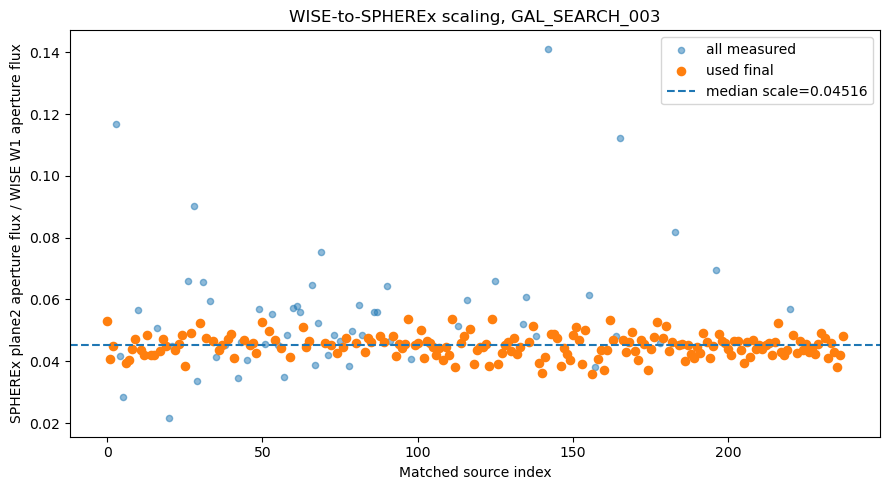


Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\photometric_scaling\matched_source_aperture_scaling.csv
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\photometric_scaling\spherex_wise_aperture_scaling_ratios.png
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\photometric_scaling\wise_w1_scaled_to_spherex_plane2.fits
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\photometric_scaling\spherex_plane2_minus_scaled_wise_w1.fits


In [9]:
# ============================================================
# CELL 7 — PHOTOMETRIC SCALING: WISE W1 TO SPHEREX PLANE 2
# Uses existing WISE overlap only
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

FIELD_ID = "GAL_SEARCH_003"
FIELD_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"

CUBE_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_003_3p20_3p58_cube.fits"
WISE_REPROJECTED = FIELD_DIR / "aligned" / "wise_w1_reprojected_to_spherex_grid.fits"
MATCHED_CSV = FIELD_DIR / "alignment_check" / "spherex_wise_matched_sources_astrometry.csv"

OUT_DIR = FIELD_DIR / "photometric_scaling"
OUT_DIR.mkdir(parents=True, exist_ok=True)

OUT_SCALING_CSV = OUT_DIR / "matched_source_aperture_scaling.csv"
OUT_RATIO_PNG = OUT_DIR / "spherex_wise_aperture_scaling_ratios.png"
OUT_WISE_SCALED = OUT_DIR / "wise_w1_scaled_to_spherex_plane2.fits"
OUT_DIFF = OUT_DIR / "spherex_plane2_minus_scaled_wise_w1.fits"

with fits.open(CUBE_PATH) as hdul:
    spx = hdul["IMAGE"].data[2].astype(float)
    hdr = hdul["IMAGE"].header
    cdelt1_deg = float(hdr["CDELT1"])
    cdelt2_deg = float(hdr["CDELT2"])

with fits.open(WISE_REPROJECTED) as hdul:
    wise = hdul[0].data.astype(float)
    wise_hdr = hdul[0].header

matched = pd.read_csv(MATCHED_CSV)

print("Loaded matched sources:", len(matched))

AP_RADIUS = 3.0
ANN_INNER = 5.0
ANN_OUTER = 8.0

def aperture_flux_image_units(image, x, y):
    pos = [(float(x), float(y))]
    aperture = CircularAperture(pos, r=AP_RADIUS)
    annulus = CircularAnnulus(pos, r_in=ANN_INNER, r_out=ANN_OUTER)

    ap_table = aperture_photometry(image, aperture, method="exact")
    ap_sum = float(ap_table["aperture_sum"][0])

    ann_mask = annulus.to_mask(method="center")[0]
    ann_data = ann_mask.multiply(image)

    ann_values = ann_data[np.isfinite(ann_data)]
    ann_values = ann_values[ann_values != 0]

    if len(ann_values) < 8:
        return np.nan, np.nan, np.nan

    _, bkg_med, bkg_std = sigma_clipped_stats(ann_values, sigma=3.0, maxiters=5)

    ap_area = aperture.area
    net_flux = ap_sum - bkg_med * ap_area
    unc = bkg_std * np.sqrt(ap_area)
    snr = net_flux / unc if np.isfinite(unc) and unc > 0 else np.nan

    return net_flux, unc, snr

rows = []

for _, row in matched.iterrows():
    x = float(row["spx_x"])
    y = float(row["spx_y"])

    spx_flux, spx_unc, spx_snr = aperture_flux_image_units(spx, x, y)
    wise_flux, wise_unc, wise_snr = aperture_flux_image_units(wise, x, y)

    if np.isfinite(spx_flux) and np.isfinite(wise_flux) and wise_flux > 0 and spx_flux > 0:
        ratio = spx_flux / wise_flux
    else:
        ratio = np.nan

    rows.append({
        "spx_x": x,
        "spx_y": y,
        "spx_net_ap_flux": spx_flux,
        "wise_net_ap_flux": wise_flux,
        "spx_snr": spx_snr,
        "wise_snr": wise_snr,
        "spx_over_wise_ratio": ratio,
        "match_dist_pix": row["match_dist_pix"],
    })

scale_df = pd.DataFrame(rows)

# Clean scaling sources
clean = scale_df[
    np.isfinite(scale_df["spx_over_wise_ratio"]) &
    (scale_df["spx_over_wise_ratio"] > 0) &
    (scale_df["spx_snr"] > 20) &
    (scale_df["wise_snr"] > 20) &
    (scale_df["match_dist_pix"] < 1.0)
].copy()

# Robust clipping on ratio
med = np.nanmedian(clean["spx_over_wise_ratio"])
mad = np.nanmedian(np.abs(clean["spx_over_wise_ratio"] - med))
robust_sigma = 1.4826 * mad if mad > 0 else np.nanstd(clean["spx_over_wise_ratio"])

if np.isfinite(robust_sigma) and robust_sigma > 0:
    clean["used_for_scaling_final"] = np.abs(clean["spx_over_wise_ratio"] - med) < 2.5 * robust_sigma
else:
    clean["used_for_scaling_final"] = True

final = clean[clean["used_for_scaling_final"]].copy()

scale_factor = float(np.nanmedian(final["spx_over_wise_ratio"]))
scatter = float(1.4826 * np.nanmedian(np.abs(final["spx_over_wise_ratio"] - scale_factor)))

# Mark final usage in full table
scale_df["used_for_scaling_final"] = False
scale_df.loc[final.index, "used_for_scaling_final"] = True

scale_df.to_csv(OUT_SCALING_CSV, index=False)

wise_scaled = wise * scale_factor
diff = spx - wise_scaled

fits.PrimaryHDU(wise_scaled.astype(np.float32), header=wise_hdr).writeto(OUT_WISE_SCALED, overwrite=True)
fits.PrimaryHDU(diff.astype(np.float32), header=wise_hdr).writeto(OUT_DIFF, overwrite=True)

print("\nClean scaling sources before clipping:", len(clean))
print("Final scaling sources:", len(final))
print("Scale factor SPHEREx/Wise:", scale_factor)
print("Robust scatter:", scatter)

plt.figure(figsize=(9, 5))
plt.scatter(scale_df.index, scale_df["spx_over_wise_ratio"], s=20, alpha=0.5, label="all measured")
plt.scatter(final.index, final["spx_over_wise_ratio"], s=35, label="used final")
plt.axhline(scale_factor, linestyle="--", linewidth=1.5, label=f"median scale={scale_factor:.5f}")
plt.xlabel("Matched source index")
plt.ylabel("SPHEREx plane2 aperture flux / WISE W1 aperture flux")
plt.title("WISE-to-SPHEREx scaling, GAL_SEARCH_003")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_RATIO_PNG, dpi=200)
plt.show()

print("\nSaved:")
print(OUT_SCALING_CSV)
print(OUT_RATIO_PNG)
print(OUT_WISE_SCALED)
print(OUT_DIFF)

Calibration/scaling sources used: 181


C:\Users\Owner\AppData\Local\Temp\ipykernel_31696\3145885407.py:92: RuntimeWarning: invalid value encountered in divide
  wise_test = np.where(weights > 0, smoothed / weights, np.nan)
C:\Users\Owner\AppData\Local\Temp\ipykernel_31696\3145885407.py:92: RuntimeWarning: invalid value encountered in divide
  wise_test = np.where(weights > 0, smoothed / weights, np.nan)
C:\Users\Owner\AppData\Local\Temp\ipykernel_31696\3145885407.py:92: RuntimeWarning: invalid value encountered in divide
  wise_test = np.where(weights > 0, smoothed / weights, np.nan)
C:\Users\Owner\AppData\Local\Temp\ipykernel_31696\3145885407.py:92: RuntimeWarning: invalid value encountered in divide
  wise_test = np.where(weights > 0, smoothed / weights, np.nan)
C:\Users\Owner\AppData\Local\Temp\ipykernel_31696\3145885407.py:92: RuntimeWarning: invalid value encountered in divide
  wise_test = np.where(weights > 0, smoothed / weights, np.nan)
C:\Users\Owner\AppData\Local\Temp\ipykernel_31696\3145885407.py:92: RuntimeWarni


PSF tuning results:


,sigma_pix,global_diff_median,global_diff_std,matched_star_median_abs_aperture_residual,n_aperture_residuals
0,0.00,0.064882,0.130395,1.503864,181
1,0.15,0.064882,0.130395,1.503864,181
2,0.25,0.064864,0.130447,1.504348,181
3,0.35,0.063884,0.130892,1.538616,181
4,0.50,0.060402,0.137557,1.642792,181
5,0.65,0.057477,0.147023,1.715345,181
6,0.80,0.054709,0.154998,2.014554,181
7,1.00,0.051243,0.164944,2.706908,181
8,1.25,0.046719,0.175553,4.293752,181
9,1.50,0.041891,0.185004,6.911197,181



Best sigma: 0.0
Best matched-star median abs aperture residual: 1.5038637543535849
Best global diff std: 0.13039463571408913


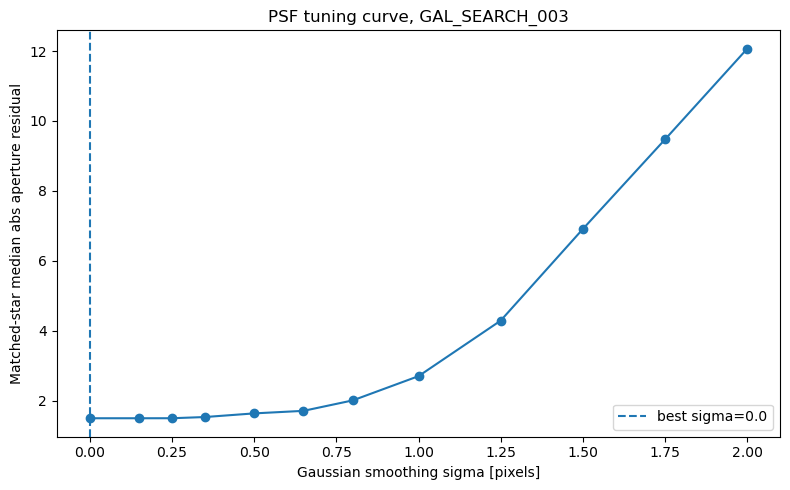

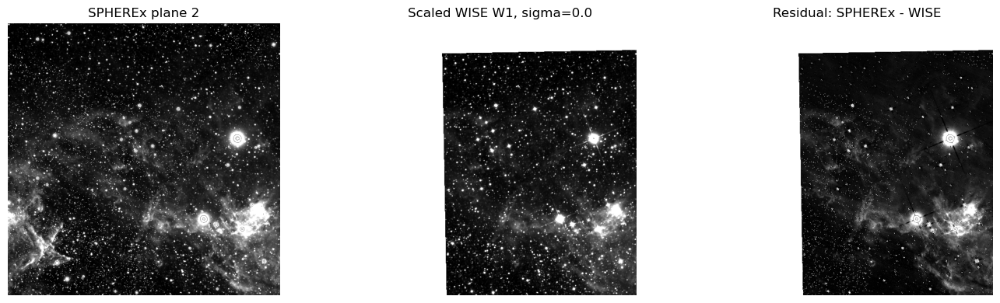


Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\psf_tuning\psf_tuning_results.csv
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\psf_tuning\psf_tuning_curve.png
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\psf_tuning\wise_w1_scaled_psf_tuned_to_spherex_plane2.fits
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\psf_tuning\spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\psf_tuning\psf_tuned_subtraction_check.png


In [10]:
# ============================================================
# CELL 8 — PSF TUNING FOR GAL_SEARCH_003
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from scipy.ndimage import gaussian_filter
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

FIELD_ID = "GAL_SEARCH_003"
FIELD_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"

CUBE_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_003_3p20_3p58_cube.fits"
WISE_SCALED_PATH = FIELD_DIR / "photometric_scaling" / "wise_w1_scaled_to_spherex_plane2.fits"
SCALING_CSV = FIELD_DIR / "photometric_scaling" / "matched_source_aperture_scaling.csv"

OUT_DIR = FIELD_DIR / "psf_tuning"
OUT_DIR.mkdir(parents=True, exist_ok=True)

OUT_RESULTS = OUT_DIR / "psf_tuning_results.csv"
OUT_CURVE = OUT_DIR / "psf_tuning_curve.png"
OUT_WISE_TUNED = OUT_DIR / "wise_w1_scaled_psf_tuned_to_spherex_plane2.fits"
OUT_DIFF_TUNED = OUT_DIR / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits"
OUT_CHECK = OUT_DIR / "psf_tuned_subtraction_check.png"

with fits.open(CUBE_PATH) as hdul:
    spx = hdul["IMAGE"].data[2].astype(float)
    spx_hdr = hdul["IMAGE"].header

with fits.open(WISE_SCALED_PATH) as hdul:
    wise_scaled = hdul[0].data.astype(float)
    wise_hdr = hdul[0].header

scale_df = pd.read_csv(SCALING_CSV)
cal = scale_df[scale_df["used_for_scaling_final"] == True].copy()

print("Calibration/scaling sources used:", len(cal))

AP_RADIUS = 3.0
ANN_INNER = 5.0
ANN_OUTER = 8.0

def aperture_flux_image_units(image, x, y):
    pos = [(float(x), float(y))]
    aperture = CircularAperture(pos, r=AP_RADIUS)
    annulus = CircularAnnulus(pos, r_in=ANN_INNER, r_out=ANN_OUTER)

    try:
        ap_table = aperture_photometry(image, aperture, method="exact")
        ap_sum = float(ap_table["aperture_sum"][0])

        ann_mask = annulus.to_mask(method="center")[0]
        ann_data = ann_mask.multiply(image)

        ann_values = ann_data[np.isfinite(ann_data)]
        ann_values = ann_values[ann_values != 0]

        if len(ann_values) < 8:
            return np.nan

        _, bkg_med, _ = sigma_clipped_stats(ann_values, sigma=3.0, maxiters=5)

        net_flux = ap_sum - bkg_med * aperture.area
        return net_flux

    except Exception:
        return np.nan

sigmas = [0.0, 0.15, 0.25, 0.35, 0.50, 0.65, 0.80, 1.00, 1.25, 1.50, 1.75, 2.00]

rows = []

valid_base = np.isfinite(spx) & np.isfinite(wise_scaled)

for sig in sigmas:
    if sig == 0:
        wise_test = wise_scaled.copy()
    else:
        # only smooth finite values safely
        finite = np.isfinite(wise_scaled)
        filled = np.where(finite, wise_scaled, 0.0)
        weights = gaussian_filter(finite.astype(float), sig)
        smoothed = gaussian_filter(filled, sig)
        wise_test = np.where(weights > 0, smoothed / weights, np.nan)

    diff = spx - wise_test

    valid = np.isfinite(diff) & valid_base
    vals = diff[valid]

    _, med, std = sigma_clipped_stats(vals, sigma=3.0, maxiters=5)

    abs_residuals = []
    for _, r in cal.iterrows():
        x = r["spx_x"]
        y = r["spx_y"]
        ap_resid = aperture_flux_image_units(diff, x, y)
        if np.isfinite(ap_resid):
            abs_residuals.append(abs(ap_resid))

    median_abs_ap_resid = float(np.nanmedian(abs_residuals)) if len(abs_residuals) else np.nan

    rows.append({
        "sigma_pix": sig,
        "global_diff_median": float(med),
        "global_diff_std": float(std),
        "matched_star_median_abs_aperture_residual": median_abs_ap_resid,
        "n_aperture_residuals": len(abs_residuals),
    })

results = pd.DataFrame(rows)
results.to_csv(OUT_RESULTS, index=False)

# Choose best sigma by matched-star aperture residual
best = results.sort_values("matched_star_median_abs_aperture_residual").iloc[0]
best_sigma = float(best["sigma_pix"])

print("\nPSF tuning results:")
display(results)

print("\nBest sigma:", best_sigma)
print("Best matched-star median abs aperture residual:", best["matched_star_median_abs_aperture_residual"])
print("Best global diff std:", best["global_diff_std"])

# Make final tuned WISE and diff
if best_sigma == 0:
    wise_best = wise_scaled.copy()
else:
    finite = np.isfinite(wise_scaled)
    filled = np.where(finite, wise_scaled, 0.0)
    weights = gaussian_filter(finite.astype(float), best_sigma)
    smoothed = gaussian_filter(filled, best_sigma)
    wise_best = np.where(weights > 0, smoothed / weights, np.nan)

diff_best = spx - wise_best

fits.PrimaryHDU(wise_best.astype(np.float32), header=wise_hdr).writeto(OUT_WISE_TUNED, overwrite=True)
fits.PrimaryHDU(diff_best.astype(np.float32), header=wise_hdr).writeto(OUT_DIFF_TUNED, overwrite=True)

# Plot tuning curve
plt.figure(figsize=(8, 5))
plt.plot(results["sigma_pix"], results["matched_star_median_abs_aperture_residual"], marker="o")
plt.axvline(best_sigma, linestyle="--", label=f"best sigma={best_sigma}")
plt.xlabel("Gaussian smoothing sigma [pixels]")
plt.ylabel("Matched-star median abs aperture residual")
plt.title("PSF tuning curve, GAL_SEARCH_003")
plt.legend()
plt.tight_layout()
plt.savefig(OUT_CURVE, dpi=200)
plt.show()

# Visual check
def robust_limits(img, low=2, high=98):
    vals = img[np.isfinite(img)]
    return np.nanpercentile(vals, low), np.nanpercentile(vals, high)

spx_vmin, spx_vmax = robust_limits(spx)
wise_vmin, wise_vmax = robust_limits(wise_best)
diff_vmin, diff_vmax = robust_limits(diff_best, low=5, high=99)

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(spx, origin="lower", cmap="gray", vmin=spx_vmin, vmax=spx_vmax)
plt.title("SPHEREx plane 2")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(wise_best, origin="lower", cmap="gray", vmin=wise_vmin, vmax=wise_vmax)
plt.title(f"Scaled WISE W1, sigma={best_sigma}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(diff_best, origin="lower", cmap="gray", vmin=diff_vmin, vmax=diff_vmax)
plt.title("Residual: SPHEREx - WISE")
plt.axis("off")

plt.tight_layout()
plt.savefig(OUT_CHECK, dpi=200)
plt.show()

print("\nSaved:")
print(OUT_RESULTS)
print(OUT_CURVE)
print(OUT_WISE_TUNED)
print(OUT_DIFF_TUNED)
print(OUT_CHECK)

Residual stats:
sigma-clipped mean: 0.0949150997145252
sigma-clipped median: 0.06488202512264252
sigma-clipped std: 0.13039463571457666
MAD robust sigma: 0.11838006942272186

Using sigma: 0.11838006942272186

DAOStarFinder columns:
['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']

Total candidates after overlap/edge filtering: 79

Candidate counts above residual-SNR cutoffs:


,residual_snr_cutoff,n_candidates_above_cutoff,fraction_candidates_above_cutoff
0,5,63,0.797468
1,10,49,0.620253
2,20,37,0.468354
3,30,25,0.316456
4,50,20,0.253165
5,80,14,0.177215
6,100,13,0.164557



Top 30 candidates:


,candidate_id,ra_deg,dec_deg,x_centroid,y_centroid,residual_diff_snr_peak,residual_peak_value,sharpness,roundness1,roundness2
0,G003_CAND_001,42.982829,60.516207,348.112732,31.514838,1456.774594,172.517960,0.463887,-0.102941,0.638340
1,G003_CAND_002,42.682745,61.116179,431.196528,380.344327,1091.126376,129.232498,0.823081,-0.157067,0.051776
2,G003_CAND_003,42.793795,61.187902,399.800934,421.776588,955.852611,113.218781,0.978088,-0.103594,0.089561
3,G003_CAND_004,42.422427,61.025623,504.820362,328.472795,663.623062,78.624626,0.698967,-0.160805,0.054262
4,G003_CAND_005,42.306437,61.220142,535.928145,441.822605,446.461413,52.917015,0.982509,-0.235861,0.297839
5,G003_CAND_006,42.425868,60.603139,506.698551,83.156499,442.126942,52.403900,0.996476,0.211928,0.017403
6,G003_CAND_007,42.447194,60.592621,500.689218,76.980193,383.277779,45.437332,0.854701,0.309119,-0.093612
7,G003_CAND_008,43.544179,60.650376,188.110615,109.610242,257.022137,30.491180,0.899438,0.159358,0.152674
8,G003_CAND_009,43.041012,61.066690,330.776660,351.110413,231.604306,27.482216,0.719085,-0.041078,-0.211797
9,G003_CAND_010,42.388903,60.810956,515.765993,203.945712,181.802525,21.586678,0.855826,-0.361692,-0.033856


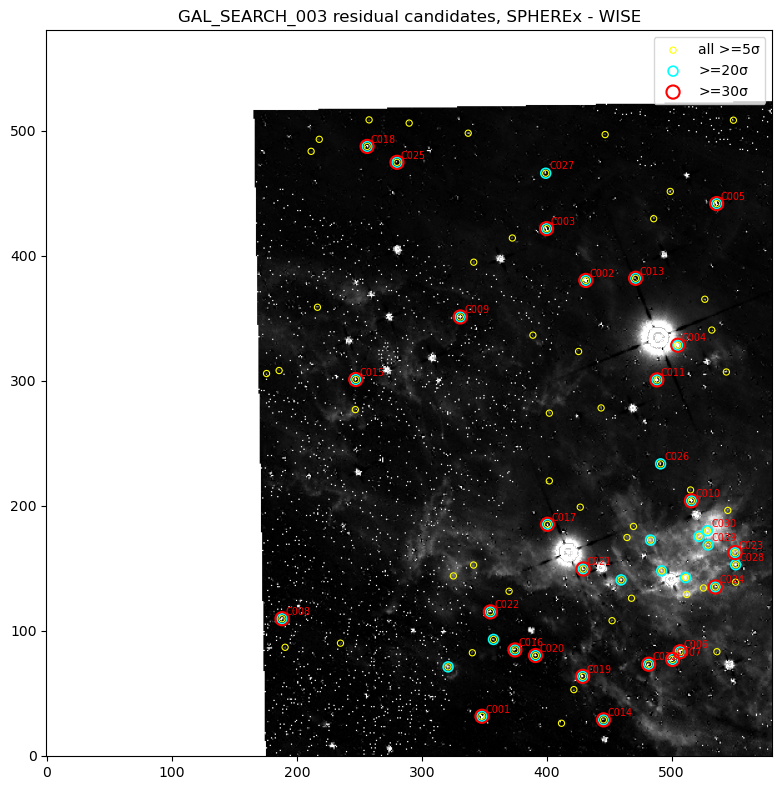


Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\candidate_detection\GAL_SEARCH_003_positive_residual_candidates.csv
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\candidate_detection\GAL_SEARCH_003_residual_snr_cutoff_counts.csv
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\candidate_detection\GAL_SEARCH_003_positive_residual_candidates.png


In [11]:
# ============================================================
# CELL 9 — RESIDUAL CANDIDATE DETECTION FOR GAL_SEARCH_003
# Focus: 20–30 sigma candidates, overlap region only
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

FIELD_ID = "GAL_SEARCH_003"
FIELD_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"

CUBE_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_003_3p20_3p58_cube.fits"
RESIDUAL_PATH = FIELD_DIR / "psf_tuning" / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits"
WISE_TUNED_PATH = FIELD_DIR / "psf_tuning" / "wise_w1_scaled_psf_tuned_to_spherex_plane2.fits"

OUT_DIR = FIELD_DIR / "candidate_detection"
OUT_DIR.mkdir(parents=True, exist_ok=True)

OUT_CAND = OUT_DIR / "GAL_SEARCH_003_positive_residual_candidates.csv"
OUT_PLOT = OUT_DIR / "GAL_SEARCH_003_positive_residual_candidates.png"
OUT_CUTOFF = OUT_DIR / "GAL_SEARCH_003_residual_snr_cutoff_counts.csv"

with fits.open(CUBE_PATH) as hdul:
    spx_cube = hdul["IMAGE"].data.astype(float)
    spx_plane2 = spx_cube[2]
    hdr = hdul["IMAGE"].header
    wcs = WCS(hdr, hdul).celestial

with fits.open(RESIDUAL_PATH) as hdul:
    resid = hdul[0].data.astype(float)

with fits.open(WISE_TUNED_PATH) as hdul:
    wise = hdul[0].data.astype(float)

# Only search where SPHEREx and WISE overlap
valid = np.isfinite(spx_plane2) & np.isfinite(wise) & np.isfinite(resid)

resid_work = np.where(valid, resid, np.nan)

vals = resid_work[np.isfinite(resid_work)]

mean, med, std = sigma_clipped_stats(vals, sigma=3.0, maxiters=5)
mad_sigma = 1.4826 * np.nanmedian(np.abs(vals - np.nanmedian(vals)))

print("Residual stats:")
print("sigma-clipped mean:", mean)
print("sigma-clipped median:", med)
print("sigma-clipped std:", std)
print("MAD robust sigma:", mad_sigma)

# Use MAD sigma for detection significance
sigma_use = mad_sigma if np.isfinite(mad_sigma) and mad_sigma > 0 else std

print("\nUsing sigma:", sigma_use)

# Detect fairly broadly first, then filter by SNR later
threshold_sigma = 5.0
finder = DAOStarFinder(fwhm=3.0, threshold=threshold_sigma * sigma_use)

sources = finder(resid_work - med)

if sources is None:
    raise RuntimeError("No sources detected.")

src = sources.to_pandas()

print("\nDAOStarFinder columns:")
print(list(src.columns))

# Standardize column names
src = src.rename(columns={
    "xcentroid": "x_centroid",
    "ycentroid": "y_centroid",
})

# Basic cleanup
src = src[np.isfinite(src["x_centroid"]) & np.isfinite(src["y_centroid"])].copy()

# Edge and overlap filtering
ny, nx = resid.shape
margin = 25

src = src[
    (src["x_centroid"] > margin) &
    (src["x_centroid"] < nx - margin) &
    (src["y_centroid"] > margin) &
    (src["y_centroid"] < ny - margin)
].copy()

# Remove candidates whose center is outside WISE overlap
xi = np.round(src["x_centroid"]).astype(int)
yi = np.round(src["y_centroid"]).astype(int)

inside_overlap = []
peak_vals = []

for x, y in zip(xi, yi):
    if x >= 0 and x < nx and y >= 0 and y < ny:
        inside_overlap.append(bool(valid[y, x]))
        peak_vals.append(float(resid[y, x]) if np.isfinite(resid[y, x]) else np.nan)
    else:
        inside_overlap.append(False)
        peak_vals.append(np.nan)

src["inside_wise_overlap"] = inside_overlap
src["residual_peak_value"] = peak_vals

src = src[src["inside_wise_overlap"]].copy()

# Residual SNR/significance
src["residual_diff_snr_peak"] = (src["residual_peak_value"] - med) / sigma_use

# RA/Dec
ra, dec = wcs.pixel_to_world_values(src["x_centroid"].to_numpy(), src["y_centroid"].to_numpy())
src["ra_deg"] = ra
src["dec_deg"] = dec

# Candidate IDs
src = src.sort_values("residual_diff_snr_peak", ascending=False).reset_index(drop=True)
src["candidate_id"] = [f"G003_CAND_{i+1:03d}" for i in range(len(src))]

# Reorder useful columns
front_cols = [
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "x_centroid",
    "y_centroid",
    "residual_peak_value",
    "residual_diff_snr_peak",
    "sharpness",
    "roundness1",
    "roundness2",
    "peak",
    "flux",
    "mag",
]

front_cols = [c for c in front_cols if c in src.columns]
other_cols = [c for c in src.columns if c not in front_cols]
src = src[front_cols + other_cols]

src.to_csv(OUT_CAND, index=False)

print("\nTotal candidates after overlap/edge filtering:", len(src))

# Cutoff counts
cutoffs = [5, 10, 20, 30, 50, 80, 100]
rows = []
for c in cutoffs:
    rows.append({
        "residual_snr_cutoff": c,
        "n_candidates_above_cutoff": int((src["residual_diff_snr_peak"] >= c).sum()),
        "fraction_candidates_above_cutoff": float((src["residual_diff_snr_peak"] >= c).mean()) if len(src) else np.nan
    })

cutoff_df = pd.DataFrame(rows)
cutoff_df.to_csv(OUT_CUTOFF, index=False)

print("\nCandidate counts above residual-SNR cutoffs:")
display(cutoff_df)

print("\nTop 30 candidates:")
display(src[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "x_centroid",
    "y_centroid",
    "residual_diff_snr_peak",
    "residual_peak_value",
    "sharpness",
    "roundness1",
    "roundness2",
]].head(30))

# Plot detections
plt.figure(figsize=(8, 8))

vmin, vmax = np.nanpercentile(resid_work[np.isfinite(resid_work)], [5, 99.5])
plt.imshow(resid_work, origin="lower", cmap="gray", vmin=vmin, vmax=vmax)

# Plot all candidates faintly
plt.scatter(src["x_centroid"], src["y_centroid"], s=20, facecolors="none", edgecolors="yellow", linewidths=0.8, label="all >=5σ")

# Highlight >=20 and >=30
hi20 = src[src["residual_diff_snr_peak"] >= 20]
hi30 = src[src["residual_diff_snr_peak"] >= 30]

plt.scatter(hi20["x_centroid"], hi20["y_centroid"], s=50, facecolors="none", edgecolors="cyan", linewidths=1.2, label=">=20σ")
plt.scatter(hi30["x_centroid"], hi30["y_centroid"], s=90, facecolors="none", edgecolors="red", linewidths=1.5, label=">=30σ")

for _, row in hi20.head(30).iterrows():
    short = row["candidate_id"].replace("G003_CAND_", "C")
    plt.text(row["x_centroid"] + 3, row["y_centroid"] + 3, short, color="red", fontsize=7)

plt.title("GAL_SEARCH_003 residual candidates, SPHEREx - WISE")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(OUT_PLOT, dpi=200)
plt.show()

print("\nSaved:")
print(OUT_CAND)
print(OUT_CUTOFF)
print(OUT_PLOT)

In [12]:
# ============================================================
# CELL 10 — FIVE-BAND PHOTOMETRY + SPHEREX/WISE RATIO
# GAL_SEARCH_003
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

FIELD_ID = "GAL_SEARCH_003"
FIELD_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"

CUBE_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_003_3p20_3p58_cube.fits"
WISE_TUNED_PATH = FIELD_DIR / "psf_tuning" / "wise_w1_scaled_psf_tuned_to_spherex_plane2.fits"
CAND_CSV = FIELD_DIR / "candidate_detection" / "GAL_SEARCH_003_positive_residual_candidates.csv"

OUT_DIR = FIELD_DIR / "nearby_wavelength_photometry"
PLOT_DIR = OUT_DIR / "candidate_spectra"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

OUT_LONG = OUT_DIR / "GAL_SEARCH_003_candidate_5band_photometry_long.csv"
OUT_SUMMARY = OUT_DIR / "GAL_SEARCH_003_candidate_5band_summary_with_ratios.csv"
OUT_TOP = OUT_DIR / "GAL_SEARCH_003_top_candidates_20_30sigma_focus.csv"

with fits.open(CUBE_PATH) as hdul:
    cube = hdul["IMAGE"].data.astype(float)
    hdr = hdul["IMAGE"].header
    wcs = WCS(hdr, hdul).celestial
    spec = hdul["SPECTRAL_CHANNELS"].data
    wavelengths = np.array([row[2] for row in spec], dtype=float)

    cdelt1_deg = float(hdr["CDELT1"])
    cdelt2_deg = float(hdr["CDELT2"])

with fits.open(WISE_TUNED_PATH) as hdul:
    wise_scaled = hdul[0].data.astype(float)

cand = pd.read_csv(CAND_CSV)

pixel_area_sr = abs(cdelt1_deg * cdelt2_deg) * (np.pi / 180.0) ** 2

AP_RADIUS = 3.0
ANN_INNER = 5.0
ANN_OUTER = 8.0

def aperture_flux_mjy(image, x, y):
    pos = [(float(x), float(y))]
    aperture = CircularAperture(pos, r=AP_RADIUS)
    annulus = CircularAnnulus(pos, r_in=ANN_INNER, r_out=ANN_OUTER)

    try:
        ap_table = aperture_photometry(image, aperture, method="exact")
        ap_sum = float(ap_table["aperture_sum"][0])

        ann_mask = annulus.to_mask(method="center")[0]
        ann_data = ann_mask.multiply(image)

        ann_values = ann_data[np.isfinite(ann_data)]
        ann_values = ann_values[ann_values != 0]

        if len(ann_values) < 8:
            return np.nan, np.nan, np.nan

        _, bkg_med, bkg_std = sigma_clipped_stats(ann_values, sigma=3.0, maxiters=5)

        ap_area = aperture.area
        net_mjysr_pix = ap_sum - bkg_med * ap_area
        unc_mjysr_pix = bkg_std * np.sqrt(ap_area)

        flux_mjy = net_mjysr_pix * pixel_area_sr * 1e9
        unc_mjy = unc_mjysr_pix * pixel_area_sr * 1e9

        snr = flux_mjy / unc_mjy if np.isfinite(unc_mjy) and unc_mjy > 0 else np.nan

        return flux_mjy, unc_mjy, snr

    except Exception:
        return np.nan, np.nan, np.nan

long_rows = []
summary_rows = []

for _, row in cand.iterrows():
    cid = row["candidate_id"]
    x = float(row["x_centroid"])
    y = float(row["y_centroid"])

    fluxes = []
    uncs = []
    snrs = []

    for k, wave in enumerate(wavelengths):
        flux, unc, snr = aperture_flux_mjy(cube[k], x, y)

        fluxes.append(flux)
        uncs.append(unc)
        snrs.append(snr)

        long_rows.append({
            "candidate_id": cid,
            "ra_deg": row["ra_deg"],
            "dec_deg": row["dec_deg"],
            "x_pix": x,
            "y_pix": y,
            "plane_index": k,
            "wavelength_um": wave,
            "spherex_flux_mjy": flux,
            "spherex_flux_unc_mjy": unc,
            "spherex_snr": snr,
            "residual_diff_snr_peak": row["residual_diff_snr_peak"],
        })

    fluxes = np.array(fluxes, dtype=float)
    snrs = np.array(snrs, dtype=float)

    # WISE expected flux at same candidate position
    wise_flux_mjy, wise_unc_mjy, wise_snr = aperture_flux_mjy(wise_scaled, x, y)

    # Use plane 2 SPHEREx flux for ratio, because WISE W1 is closest to 3.383 um
    plane2_flux = fluxes[2] if len(fluxes) > 2 else np.nan

    if np.isfinite(plane2_flux) and np.isfinite(wise_flux_mjy) and wise_flux_mjy > 0:
        ratio = plane2_flux / wise_flux_mjy
    else:
        ratio = np.nan

    positive_flux_count_5 = int(np.sum(np.isfinite(fluxes) & (fluxes > 0)))
    snr3_count_5 = int(np.sum(np.isfinite(snrs) & (snrs >= 3)))
    snr5_count_5 = int(np.sum(np.isfinite(snrs) & (snrs >= 5)))

    median_flux = float(np.nanmedian(fluxes)) if np.isfinite(fluxes).any() else np.nan
    max_snr = float(np.nanmax(snrs)) if np.isfinite(snrs).any() else np.nan

    if np.isfinite(median_flux) and median_flux != 0:
        fractional_scatter = float(np.nanstd(fluxes) / abs(median_flux))
    else:
        fractional_scatter = np.nan

    # New ranking logic based on Dr. Hora guidance:
    # scatter is not fatal; presence across bands matters more
    present_across_bands = (positive_flux_count_5 >= 4) and (snr3_count_5 >= 3)
    strong_band_presence = (positive_flux_count_5 == 5) and (snr5_count_5 >= 3)

    in_20_30_range = (row["residual_diff_snr_peak"] >= 20) and (row["residual_diff_snr_peak"] <= 30)
    above_20 = row["residual_diff_snr_peak"] >= 20
    above_30 = row["residual_diff_snr_peak"] >= 30
    above_2x = np.isfinite(ratio) and ratio >= 2.0

    if strong_band_presence and in_20_30_range:
        review_class = "BEST RANGE: 20-30sigma + present across bands"
    elif strong_band_presence and above_30:
        review_class = "VERY STRONG: above 30sigma + present across bands"
    elif present_across_bands and above_20:
        review_class = "GOOD: above 20sigma + present across bands"
    elif above_20:
        review_class = "CHECK: high residual SNR but weak band persistence"
    else:
        review_class = "LOWER PRIORITY"

    summary_rows.append({
        "candidate_id": cid,
        "ra_deg": row["ra_deg"],
        "dec_deg": row["dec_deg"],
        "x_pix": x,
        "y_pix": y,
        "residual_diff_snr_peak": row["residual_diff_snr_peak"],

        "positive_flux_count_5": positive_flux_count_5,
        "snr3_count_5": snr3_count_5,
        "snr5_count_5": snr5_count_5,
        "median_flux_mjy": median_flux,
        "max_snr_5band": max_snr,
        "fractional_scatter_5band": fractional_scatter,

        "wise_expected_plane2_flux_mjy": wise_flux_mjy,
        "spherex_plane2_flux_mjy": plane2_flux,
        "spherex_over_wise_expected_ratio": ratio,
        "brightness_2x_or_higher": above_2x,

        "present_across_bands": present_across_bands,
        "strong_band_presence": strong_band_presence,
        "review_class": review_class,

        "sharpness": row.get("sharpness", np.nan),
        "roundness1": row.get("roundness1", np.nan),
        "roundness2": row.get("roundness2", np.nan),
    })

long_df = pd.DataFrame(long_rows)
summary = pd.DataFrame(summary_rows)

# Sort by practical priority:
# 1. present across bands
# 2. 20-30 sigma preferred
# 3. 2x ratio
# 4. residual SNR
summary["priority_score"] = 0
summary.loc[summary["present_across_bands"], "priority_score"] += 100
summary.loc[summary["strong_band_presence"], "priority_score"] += 100
summary.loc[(summary["residual_diff_snr_peak"] >= 20) & (summary["residual_diff_snr_peak"] <= 30), "priority_score"] += 60
summary.loc[summary["residual_diff_snr_peak"] >= 30, "priority_score"] += 30
summary.loc[summary["brightness_2x_or_higher"], "priority_score"] += 50

# Don't let insane SNR dominate too much
summary["priority_score"] += np.minimum(summary["residual_diff_snr_peak"], 50) / 10

summary = summary.sort_values(
    ["priority_score", "residual_diff_snr_peak"],
    ascending=[False, False]
).reset_index(drop=True)

long_df.to_csv(OUT_LONG, index=False)
summary.to_csv(OUT_SUMMARY, index=False)

# Focus table: candidates around 20-30 sigma plus good high-SNR ones
focus = summary[
    (
        (summary["residual_diff_snr_peak"] >= 20) &
        (summary["residual_diff_snr_peak"] <= 30)
    )
    |
    (
        (summary["residual_diff_snr_peak"] >= 20) &
        (summary["present_across_bands"])
    )
].copy()

focus = focus.sort_values(
    ["present_across_bands", "strong_band_presence", "brightness_2x_or_higher", "residual_diff_snr_peak"],
    ascending=[False, False, False, False]
)

focus.to_csv(OUT_TOP, index=False)

print("Saved long photometry:")
print(OUT_LONG)

print("\nSaved summary:")
print(OUT_SUMMARY)

print("\nSaved 20-30sigma focus table:")
print(OUT_TOP)

print("\nReview class counts:")
print(summary["review_class"].value_counts())

print("\nBrightness ratio counts:")
print("Finite ratios:", int(np.isfinite(summary["spherex_over_wise_expected_ratio"]).sum()))
print(">=2x ratios:", int(summary["brightness_2x_or_higher"].sum()))

print("\nTop ranked candidates:")
display(summary[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "positive_flux_count_5",
    "snr3_count_5",
    "snr5_count_5",
    "spherex_over_wise_expected_ratio",
    "brightness_2x_or_higher",
    "fractional_scatter_5band",
    "present_across_bands",
    "strong_band_presence",
    "review_class",
    "priority_score",
]].head(40))

print("\n20-30sigma focus candidates:")
display(focus[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "positive_flux_count_5",
    "snr3_count_5",
    "snr5_count_5",
    "spherex_over_wise_expected_ratio",
    "brightness_2x_or_higher",
    "fractional_scatter_5band",
    "present_across_bands",
    "strong_band_presence",
    "review_class",
]].head(40))

# Plot spectra for top 30 ranked candidates
top_plot = summary.head(30).copy()

for _, r in top_plot.iterrows():
    cid = r["candidate_id"]
    sub = long_df[long_df["candidate_id"] == cid].sort_values("wavelength_um")

    plt.figure(figsize=(6, 4))
    plt.errorbar(
        sub["wavelength_um"],
        sub["spherex_flux_mjy"],
        yerr=sub["spherex_flux_unc_mjy"],
        marker="o",
        capsize=3,
    )
    plt.axhline(0, linestyle="--", linewidth=1)
    plt.xlabel("SPHEREx wavelength [µm]")
    plt.ylabel("Flux [mJy]")
    plt.title(
        f"{cid}: SNR={r['residual_diff_snr_peak']:.1f}, "
        f"ratio={r['spherex_over_wise_expected_ratio']:.2f}"
    )
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{cid}_5band_spectrum.png", dpi=160)
    plt.close()

print("\nSaved spectra plots in:")
print(PLOT_DIR)

Saved long photometry:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\nearby_wavelength_photometry\GAL_SEARCH_003_candidate_5band_photometry_long.csv

Saved summary:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\nearby_wavelength_photometry\GAL_SEARCH_003_candidate_5band_summary_with_ratios.csv

Saved 20-30sigma focus table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\nearby_wavelength_photometry\GAL_SEARCH_003_top_candidates_20_30sigma_focus.csv

Review class counts:
review_class
LOWER PRIORITY                                        42
VERY STRONG: above 30sigma + present across bands     13
CHECK: high residual SNR but weak band persistence    11
BEST RANGE: 20-30sigma + present across bands          8
GOOD: above 20sigma + present across bands             5
Name: count, dtype: int64

Brightness ratio counts:
Finite ratios: 79
>=2x ratios: 14

Top ranked candidates:


,candidate_id,ra_deg,dec_deg,residual_diff_snr_peak,positive_flux_count_5,snr3_count_5,snr5_count_5,spherex_over_wise_expected_ratio,brightness_2x_or_higher,fractional_scatter_5band,present_across_bands,strong_band_presence,review_class,priority_score
0,G003_CAND_033,42.368727,60.761801,23.140939,5,5,5,2.227396,True,0.533440,True,True,BEST RANGE: 20-30sigma + present across bands,312.314094
1,G003_CAND_037,42.505537,60.757486,20.131865,5,5,5,2.519079,True,0.432801,True,True,BEST RANGE: 20-30sigma + present across bands,312.013187
2,G003_CAND_004,42.422427,61.025623,663.623062,5,5,5,3.130579,True,0.092429,True,True,VERY STRONG: above 30sigma + present across bands,285.000000
3,G003_CAND_026,42.474834,60.862392,29.305983,5,5,5,1.013048,False,0.133865,True,True,BEST RANGE: 20-30sigma + present across bands,262.930598
4,G003_CAND_027,42.795165,61.264281,27.816943,5,5,5,1.009293,False,0.082260,True,True,BEST RANGE: 20-30sigma + present across bands,262.781694
5,G003_CAND_028,42.266413,60.722082,27.043452,5,5,5,1.156687,False,0.078340,True,True,BEST RANGE: 20-30sigma + present across bands,262.704345
6,G003_CAND_029,42.343493,60.749751,26.352720,5,5,3,0.919379,False,0.176099,True,True,BEST RANGE: 20-30sigma + present across bands,262.635272
7,G003_CAND_035,42.589625,60.703003,21.398188,5,5,5,1.333643,False,0.310299,True,True,BEST RANGE: 20-30sigma + present across bands,262.139819
8,G003_CAND_036,42.949723,60.622046,21.178451,5,5,5,1.058385,False,0.064314,True,True,BEST RANGE: 20-30sigma + present across bands,262.117845
9,G003_CAND_038,42.405437,60.682112,19.821785,5,5,3,2.399021,True,0.501108,True,True,LOWER PRIORITY,251.982178



20-30sigma focus candidates:


,candidate_id,ra_deg,dec_deg,residual_diff_snr_peak,positive_flux_count_5,snr3_count_5,snr5_count_5,spherex_over_wise_expected_ratio,brightness_2x_or_higher,fractional_scatter_5band,present_across_bands,strong_band_presence,review_class
2,G003_CAND_004,42.422427,61.025623,663.623062,5,5,5,3.130579,True,0.092429,True,True,VERY STRONG: above 30sigma + present across bands
0,G003_CAND_033,42.368727,60.761801,23.140939,5,5,5,2.227396,True,0.533440,True,True,BEST RANGE: 20-30sigma + present across bands
1,G003_CAND_037,42.505537,60.757486,20.131865,5,5,5,2.519079,True,0.432801,True,True,BEST RANGE: 20-30sigma + present across bands
12,G003_CAND_005,42.306437,61.220142,446.461413,5,5,5,1.542753,False,0.101724,True,True,VERY STRONG: above 30sigma + present across bands
13,G003_CAND_006,42.425868,60.603139,442.126942,5,5,5,1.454920,False,0.137941,True,True,VERY STRONG: above 30sigma + present across bands
14,G003_CAND_007,42.447194,60.592621,383.277779,5,5,5,1.461436,False,0.068579,True,True,VERY STRONG: above 30sigma + present across bands
15,G003_CAND_010,42.388903,60.810956,181.802525,5,5,5,1.423937,False,0.162924,True,True,VERY STRONG: above 30sigma + present across bands
16,G003_CAND_012,42.514593,60.586419,109.412806,5,5,5,1.067450,False,0.070460,True,True,VERY STRONG: above 30sigma + present across bands
17,G003_CAND_014,42.642452,60.510301,87.596145,5,5,5,0.983206,False,0.151909,True,True,VERY STRONG: above 30sigma + present across bands
18,G003_CAND_016,42.889564,60.607484,72.952500,5,5,5,1.056269,False,0.084229,True,True,VERY STRONG: above 30sigma + present across bands



Saved spectra plots in:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\nearby_wavelength_photometry\candidate_spectra


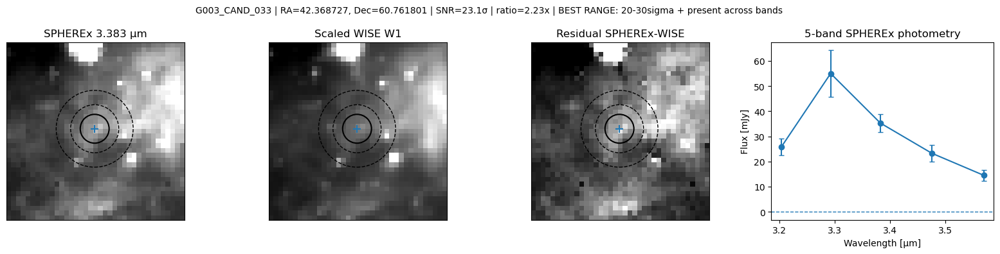

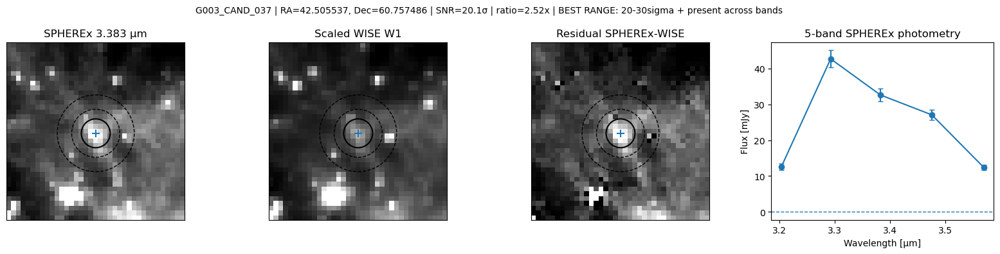

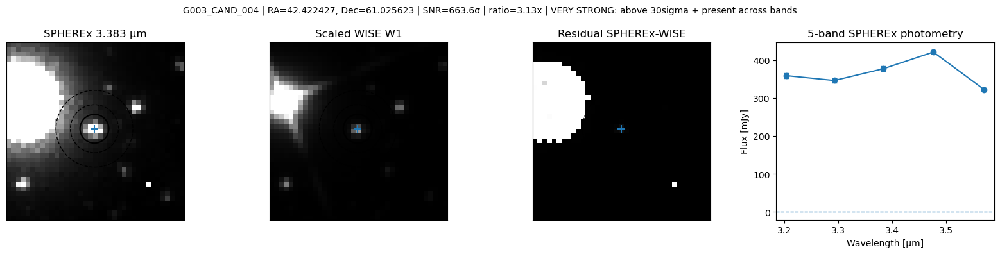

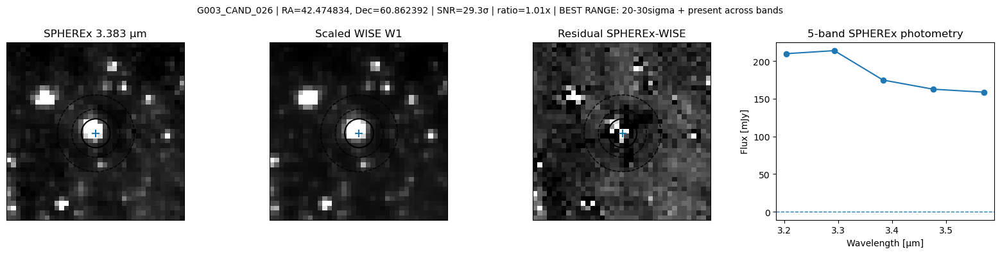

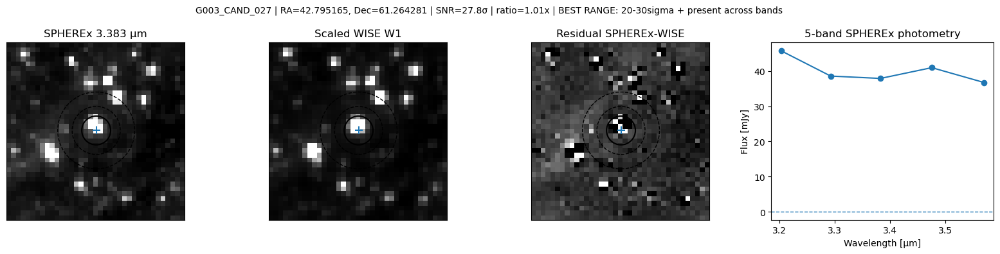

...

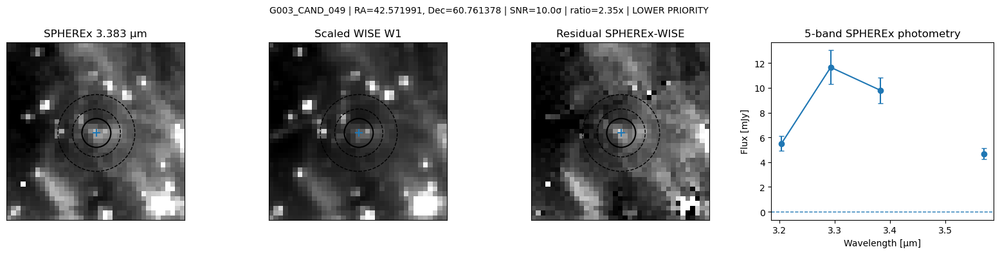

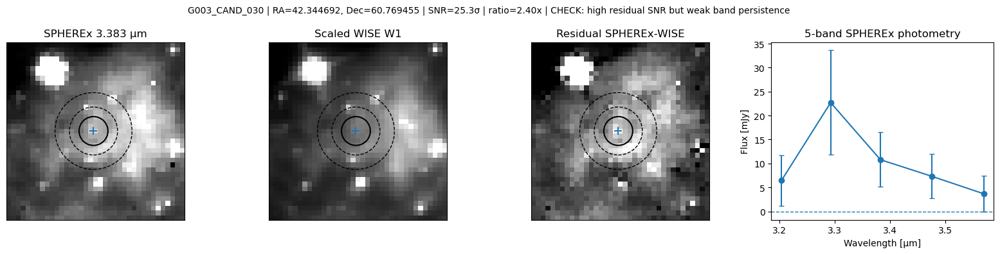

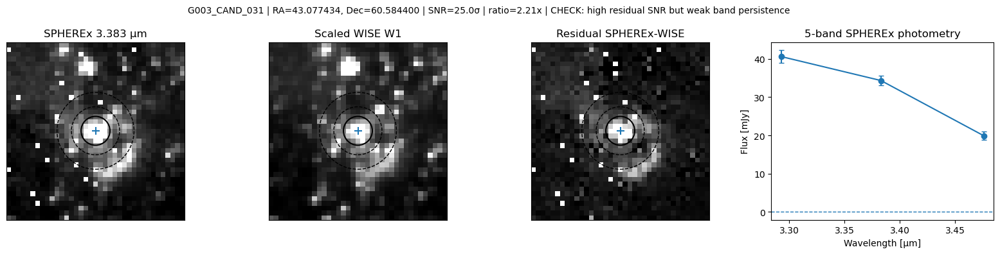

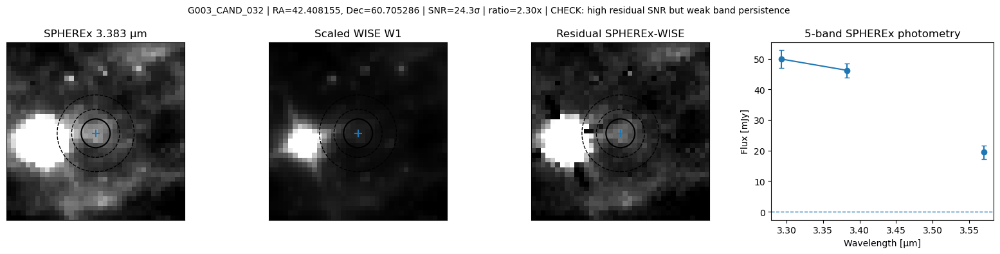

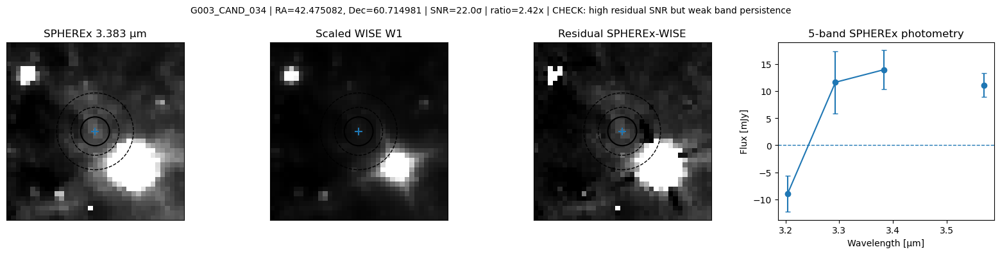

Saved review table:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\final_review\GAL_SEARCH_003_review_table.csv

Review candidates:


,candidate_id,ra_deg,dec_deg,residual_diff_snr_peak,spherex_over_wise_expected_ratio,brightness_2x_or_higher,positive_flux_count_5,snr3_count_5,snr5_count_5,fractional_scatter_5band,review_class,panel_file,review_notes
0,G003_CAND_033,42.368727,60.761801,23.140939,2.227396,True,5,5,5,0.533440,BEST RANGE: 20-30sigma + present across bands,C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\G...,>=2x SPHEREx/WISE ratio; positive in 5/5 SPHER...
1,G003_CAND_037,42.505537,60.757486,20.131865,2.519079,True,5,5,5,0.432801,BEST RANGE: 20-30sigma + present across bands,C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\G...,>=2x SPHEREx/WISE ratio; positive in 5/5 SPHER...
2,G003_CAND_004,42.422427,61.025623,663.623062,3.130579,True,5,5,5,0.092429,VERY STRONG: above 30sigma + present across bands,C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\G...,extremely high SNR; possible bright-source/sub...
3,G003_CAND_026,42.474834,60.862392,29.305983,1.013048,False,5,5,5,0.133865,BEST RANGE: 20-30sigma + present across bands,C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\G...,positive in 5/5 SPHEREx bands; >=5sigma in 5/5...
4,G003_CAND_027,42.795165,61.264281,27.816943,1.009293,False,5,5,5,0.082260,BEST RANGE: 20-30sigma + present across bands,C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\G...,positive in 5/5 SPHEREx bands; >=5sigma in 5/5...
5,G003_CAND_028,42.266413,60.722082,27.043452,1.156687,False,5,5,5,0.078340,BEST RANGE: 20-30sigma + present across bands,C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\G...,positive in 5/5 SPHEREx bands; >=5sigma in 5/5...
6,G003_CAND_029,42.343493,60.749751,26.352720,0.919379,False,5,5,3,0.176099,BEST RANGE: 20-30sigma + present across bands,C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\G...,positive in 5/5 SPHEREx bands
7,G003_CAND_035,42.589625,60.703003,21.398188,1.333643,False,5,5,5,0.310299,BEST RANGE: 20-30sigma + present across bands,C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\G...,positive in 5/5 SPHEREx bands; >=5sigma in 5/5...
8,G003_CAND_036,42.949723,60.622046,21.178451,1.058385,False,5,5,5,0.064314,BEST RANGE: 20-30sigma + present across bands,C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\G...,positive in 5/5 SPHEREx bands; >=5sigma in 5/5...
9,G003_CAND_038,42.405437,60.682112,19.821785,2.399021,True,5,5,3,0.501108,LOWER PRIORITY,C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\G...,>=2x SPHEREx/WISE ratio; positive in 5/5 SPHER...


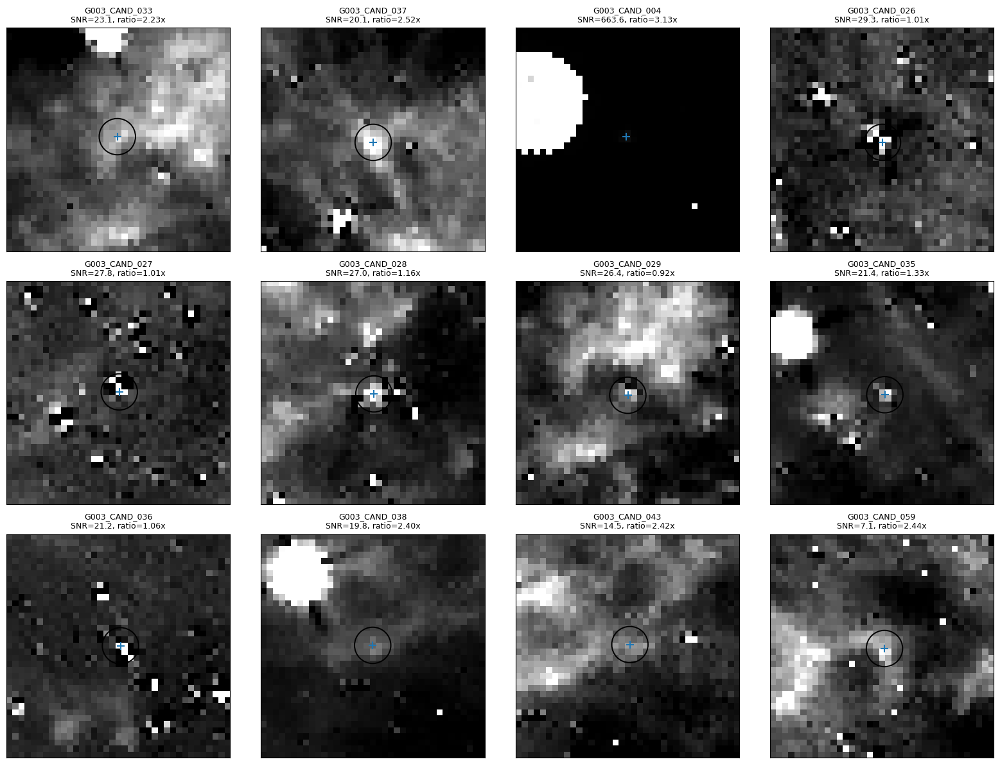


Saved contact sheet:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\final_review\GAL_SEARCH_003_top_review_contact_sheet.png

Saved panels in:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\final_review\candidate_review_panels


In [13]:
# ============================================================
# CELL 11 — MAKE REVIEW PANELS FOR TOP GAL_SEARCH_003 CANDIDATES
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from matplotlib.patches import Circle

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

FIELD_ID = "GAL_SEARCH_003"
FIELD_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"

CUBE_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_003_3p20_3p58_cube.fits"
WISE_TUNED_PATH = FIELD_DIR / "psf_tuning" / "wise_w1_scaled_psf_tuned_to_spherex_plane2.fits"
RESIDUAL_PATH = FIELD_DIR / "psf_tuning" / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits"

SUMMARY_CSV = FIELD_DIR / "nearby_wavelength_photometry" / "GAL_SEARCH_003_candidate_5band_summary_with_ratios.csv"
LONG_CSV = FIELD_DIR / "nearby_wavelength_photometry" / "GAL_SEARCH_003_candidate_5band_photometry_long.csv"

OUT_DIR = FIELD_DIR / "final_review"
PANEL_DIR = OUT_DIR / "candidate_review_panels"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PANEL_DIR.mkdir(parents=True, exist_ok=True)

OUT_REVIEW_TABLE = OUT_DIR / "GAL_SEARCH_003_review_table.csv"
OUT_CONTACT = OUT_DIR / "GAL_SEARCH_003_top_review_contact_sheet.png"

summary = pd.read_csv(SUMMARY_CSV)
long_df = pd.read_csv(LONG_CSV)

with fits.open(CUBE_PATH) as hdul:
    cube = hdul["IMAGE"].data.astype(float)
    spx_plane2 = cube[2]
    wavelengths = np.array([row[2] for row in hdul["SPECTRAL_CHANNELS"].data], dtype=float)

with fits.open(WISE_TUNED_PATH) as hdul:
    wise = hdul[0].data.astype(float)

with fits.open(RESIDUAL_PATH) as hdul:
    resid = hdul[0].data.astype(float)

def robust_limits(img, low=2, high=98):
    vals = img[np.isfinite(img)]
    if len(vals) == 0:
        return 0, 1
    return np.nanpercentile(vals, low), np.nanpercentile(vals, high)

def cutout(img, x, y, half=18):
    x_int = int(round(x))
    y_int = int(round(y))
    y0 = max(0, y_int - half)
    y1 = min(img.shape[0], y_int + half + 1)
    x0 = max(0, x_int - half)
    x1 = min(img.shape[1], x_int + half + 1)
    return img[y0:y1, x0:x1], x0, y0

# Choose useful candidates:
# 1. top priority score
# 2. include all >=2x and 20-30sigma candidates
selected = summary[
    (
        (summary["residual_diff_snr_peak"] >= 20) &
        (summary["residual_diff_snr_peak"] <= 30)
    )
    |
    (summary["brightness_2x_or_higher"] == True)
    |
    (summary["review_class"].str.contains("VERY STRONG", na=False))
].copy()

selected = selected.sort_values(
    ["priority_score", "residual_diff_snr_peak"],
    ascending=[False, False]
).head(30).copy()

review_rows = []

for _, row in selected.iterrows():
    cid = row["candidate_id"]
    x = float(row["x_pix"])
    y = float(row["y_pix"])

    spx_cut, x0, y0 = cutout(spx_plane2, x, y, half=18)
    wise_cut, _, _ = cutout(wise, x, y, half=18)
    resid_cut, _, _ = cutout(resid, x, y, half=18)

    cx = x - x0
    cy = y - y0

    spx_vmin, spx_vmax = robust_limits(spx_cut)
    wise_vmin, wise_vmax = robust_limits(wise_cut)
    resid_vmin, resid_vmax = robust_limits(resid_cut, low=5, high=99)

    sub = long_df[long_df["candidate_id"] == cid].sort_values("wavelength_um")

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    panels = [
        (spx_cut, "SPHEREx 3.383 µm", spx_vmin, spx_vmax),
        (wise_cut, "Scaled WISE W1", wise_vmin, wise_vmax),
        (resid_cut, "Residual SPHEREx-WISE", resid_vmin, resid_vmax),
    ]

    for ax, (img, title, vmin, vmax) in zip(axes[:3], panels):
        ax.imshow(img, origin="lower", cmap="gray", vmin=vmin, vmax=vmax)
        ax.scatter([cx], [cy], marker="+", s=80)
        ax.add_patch(Circle((cx, cy), 3, fill=False, linewidth=1.5))
        ax.add_patch(Circle((cx, cy), 5, fill=False, linestyle="--", linewidth=1.0))
        ax.add_patch(Circle((cx, cy), 8, fill=False, linestyle="--", linewidth=1.0))
        ax.set_title(title)
        ax.set_xticks([])
        ax.set_yticks([])

    axes[3].errorbar(
        sub["wavelength_um"],
        sub["spherex_flux_mjy"],
        yerr=sub["spherex_flux_unc_mjy"],
        marker="o",
        capsize=3,
    )
    axes[3].axhline(0, linestyle="--", linewidth=1)
    axes[3].set_xlabel("Wavelength [µm]")
    axes[3].set_ylabel("Flux [mJy]")
    axes[3].set_title("5-band SPHEREx photometry")

    fig.suptitle(
        f"{cid} | RA={row['ra_deg']:.6f}, Dec={row['dec_deg']:.6f} | "
        f"SNR={row['residual_diff_snr_peak']:.1f}σ | "
        f"ratio={row['spherex_over_wise_expected_ratio']:.2f}x | "
        f"{row['review_class']}",
        fontsize=10
    )

    plt.tight_layout()

    out_png = PANEL_DIR / f"{cid}_review_panel.png"
    plt.savefig(out_png, dpi=200)
    plt.show()
    plt.close(fig)

    # Simple visual warning flags based on numbers
    notes = []
    if row["residual_diff_snr_peak"] > 100:
        notes.append("extremely high SNR; possible bright-source/subtraction artifact")
    if row["brightness_2x_or_higher"]:
        notes.append(">=2x SPHEREx/WISE ratio")
    if row["positive_flux_count_5"] == 5:
        notes.append("positive in 5/5 SPHEREx bands")
    if row["snr5_count_5"] >= 5:
        notes.append(">=5sigma in 5/5 SPHEREx bands")
    if row["fractional_scatter_5band"] > 0.5:
        notes.append("large five-band scatter, but not automatically rejected")

    review_rows.append({
        "candidate_id": cid,
        "ra_deg": row["ra_deg"],
        "dec_deg": row["dec_deg"],
        "residual_diff_snr_peak": row["residual_diff_snr_peak"],
        "spherex_over_wise_expected_ratio": row["spherex_over_wise_expected_ratio"],
        "brightness_2x_or_higher": row["brightness_2x_or_higher"],
        "positive_flux_count_5": row["positive_flux_count_5"],
        "snr3_count_5": row["snr3_count_5"],
        "snr5_count_5": row["snr5_count_5"],
        "fractional_scatter_5band": row["fractional_scatter_5band"],
        "review_class": row["review_class"],
        "panel_file": str(out_png),
        "review_notes": "; ".join(notes),
    })

review = pd.DataFrame(review_rows)
review.to_csv(OUT_REVIEW_TABLE, index=False)

print("Saved review table:")
print(OUT_REVIEW_TABLE)

print("\nReview candidates:")
display(review)

# Contact sheet for top 12 panels
top_panels = review.head(12)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.ravel()

for ax, (_, row) in zip(axes, top_panels.iterrows()):
    cid = row["candidate_id"]
    x = float(summary.loc[summary["candidate_id"] == cid, "x_pix"].iloc[0])
    y = float(summary.loc[summary["candidate_id"] == cid, "y_pix"].iloc[0])
    resid_cut, x0, y0 = cutout(resid, x, y, half=18)
    cx = x - x0
    cy = y - y0

    vmin, vmax = robust_limits(resid_cut, low=5, high=99)
    ax.imshow(resid_cut, origin="lower", cmap="gray", vmin=vmin, vmax=vmax)
    ax.scatter([cx], [cy], marker="+", s=70)
    ax.add_patch(Circle((cx, cy), 3, fill=False, linewidth=1.4))
    ax.set_title(
        f"{cid}\nSNR={row['residual_diff_snr_peak']:.1f}, ratio={row['spherex_over_wise_expected_ratio']:.2f}x",
        fontsize=9
    )
    ax.set_xticks([])
    ax.set_yticks([])

for ax in axes[len(top_panels):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUT_CONTACT, dpi=200)
plt.show()

print("\nSaved contact sheet:")
print(OUT_CONTACT)
print("\nSaved panels in:")
print(PANEL_DIR)

In [14]:
# ============================================================
# CELL 12 — STRICT FINAL SHORTLIST FOR GAL_SEARCH_003
# Keeps only candidates matching Dr. Hora's current search target
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import pandas as pd
import shutil
import zipfile

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"

SUMMARY_CSV = FIELD_DIR / "nearby_wavelength_photometry" / "GAL_SEARCH_003_candidate_5band_summary_with_ratios.csv"
LONG_CSV = FIELD_DIR / "nearby_wavelength_photometry" / "GAL_SEARCH_003_candidate_5band_photometry_long.csv"
REVIEW_CSV = FIELD_DIR / "final_review" / "GAL_SEARCH_003_review_table.csv"
PANEL_DIR = FIELD_DIR / "final_review" / "candidate_review_panels"

OUT_DIR = FIELD_DIR / "strict_shortlist"
OUT_PANEL_DIR = OUT_DIR / "candidate_review_panels"
OUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_PANEL_DIR.mkdir(parents=True, exist_ok=True)

summary = pd.read_csv(SUMMARY_CSV)
long_df = pd.read_csv(LONG_CSV)
review = pd.read_csv(REVIEW_CSV)

# Strict target based on Dr. Hora's updated instruction
strict = summary[
    (summary["residual_diff_snr_peak"] >= 20) &
    (summary["residual_diff_snr_peak"] <= 30) &
    (summary["spherex_over_wise_expected_ratio"] >= 2.0) &
    (summary["positive_flux_count_5"] == 5) &
    (summary["snr5_count_5"] == 5)
].copy()

strict = strict.sort_values(
    ["spherex_over_wise_expected_ratio", "residual_diff_snr_peak"],
    ascending=[False, False]
).reset_index(drop=True)

strict_ids = strict["candidate_id"].tolist()

strict_long = long_df[long_df["candidate_id"].isin(strict_ids)].copy()
strict_review = review[review["candidate_id"].isin(strict_ids)].copy()

OUT_STRICT = OUT_DIR / "GAL_SEARCH_003_strict_shortlist.csv"
OUT_STRICT_LONG = OUT_DIR / "GAL_SEARCH_003_strict_shortlist_5band_photometry.csv"
OUT_STRICT_REVIEW = OUT_DIR / "GAL_SEARCH_003_strict_shortlist_review_table.csv"

strict.to_csv(OUT_STRICT, index=False)
strict_long.to_csv(OUT_STRICT_LONG, index=False)
strict_review.to_csv(OUT_STRICT_REVIEW, index=False)

# Copy review panels for strict candidates
for cid in strict_ids:
    src = PANEL_DIR / f"{cid}_review_panel.png"
    if src.exists():
        shutil.copy2(src, OUT_PANEL_DIR / src.name)
    else:
        print("Missing panel:", src)

# Also save a broader comparison table: all 20–30σ candidates
broad = summary[
    (summary["residual_diff_snr_peak"] >= 20) &
    (summary["residual_diff_snr_peak"] <= 30)
].copy()

broad = broad.sort_values(
    ["spherex_over_wise_expected_ratio", "residual_diff_snr_peak"],
    ascending=[False, False]
)

OUT_BROAD = OUT_DIR / "GAL_SEARCH_003_all_20_30sigma_candidates.csv"
broad.to_csv(OUT_BROAD, index=False)

# README
README = OUT_DIR / "README_GAL_SEARCH_003_strict_shortlist.txt"

readme = f"""GAL_SEARCH_003 Strict Shortlist

Field center:
RA = 43.186170 deg
Dec = 60.961522 deg

Galactic search position:
This field is one step along Galactic longitude from the original RA=45.0, Dec=60.5 field.

Selection rule for strict shortlist:
- residual SNR between 20 and 30 sigma
- SPHEREx corrected plane-2 flux / WISE-expected plane-2 flux >= 2
- positive flux in 5/5 nearby SPHEREx Band 4 channels
- SNR >=5 in 5/5 nearby SPHEREx Band 4 channels

Number of strict candidates: {len(strict)}

Strict candidates:
"""

for _, r in strict.iterrows():
    readme += (
        f"\n{r['candidate_id']}: "
        f"RA={r['ra_deg']:.6f}, Dec={r['dec_deg']:.6f}, "
        f"residual SNR={r['residual_diff_snr_peak']:.2f}, "
        f"SPHEREx/WISE ratio={r['spherex_over_wise_expected_ratio']:.2f}x, "
        f"positive bands={int(r['positive_flux_count_5'])}/5, "
        f"SNR5 bands={int(r['snr5_count_5'])}/5"
    )

readme += """

Interpretation:
These candidates best match the current search target: moderate-high residual significance near 20–30 sigma, strong presence across all five nearby SPHEREx bands, and at least a 2x SPHEREx/WISE brightness ratio.

The extremely high-SNR candidates were not placed in the strict shortlist because very large residuals can be caused by bright-source subtraction artifacts, saturation, nebulosity, or local background structure. They remain in the broader review tables but are not treated as the cleanest search results.
"""

README.write_text(readme, encoding="utf-8")

# Zip it
ZIP_OUT = FIELD_DIR / "GAL_SEARCH_003_strict_shortlist.zip"
if ZIP_OUT.exists():
    ZIP_OUT.unlink()

with zipfile.ZipFile(ZIP_OUT, "w", compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT_DIR.rglob("*"):
        z.write(p, arcname=p.relative_to(OUT_DIR.parent))

print("Strict shortlist candidates:")
display(strict[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "spherex_over_wise_expected_ratio",
    "positive_flux_count_5",
    "snr5_count_5",
    "fractional_scatter_5band",
    "review_class"
]])

print("\nSaved strict shortlist folder:")
print(OUT_DIR)

print("\nSaved ZIP:")
print(ZIP_OUT)

Strict shortlist candidates:


,candidate_id,ra_deg,dec_deg,residual_diff_snr_peak,spherex_over_wise_expected_ratio,positive_flux_count_5,snr5_count_5,fractional_scatter_5band,review_class
0,G003_CAND_037,42.505537,60.757486,20.131865,2.519079,5,5,0.432801,BEST RANGE: 20-30sigma + present across bands
1,G003_CAND_033,42.368727,60.761801,23.140939,2.227396,5,5,0.533440,BEST RANGE: 20-30sigma + present across bands



Saved strict shortlist folder:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\strict_shortlist

Saved ZIP:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\GAL_SEARCH_003_strict_shortlist.zip


In [15]:
# ============================================================
# CELL 13 — CREATE VARWISE GATOR INPUT FOR STRICT SHORTLIST
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import pandas as pd

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"

STRICT_CSV = FIELD_DIR / "strict_shortlist" / "GAL_SEARCH_003_strict_shortlist.csv"

OUT_DIR = FIELD_DIR / "strict_shortlist_varwise_crossmatch"
OUT_DIR.mkdir(parents=True, exist_ok=True)

strict = pd.read_csv(STRICT_CSV)

# Save CSV for our own records
OUT_CSV = OUT_DIR / "GAL_SEARCH_003_strict_shortlist_for_varwise.csv"
strict[["candidate_id", "ra_deg", "dec_deg"]].to_csv(OUT_CSV, index=False)

# Gator/IPAC table format
OUT_TBL = OUT_DIR / "GAL_SEARCH_003_strict_shortlist_GATOR.tbl"

with open(OUT_TBL, "w") as f:
    f.write("\\irsa\n")
    f.write("| candidate_id | ra       | dec       |\n")
    f.write("| char         | double   | double    |\n")
    f.write("| null         | null     | null      |\n")

    for _, r in strict.iterrows():
        f.write(
            f" {r['candidate_id']:<12} "
            f" {r['ra_deg']:.8f} "
            f" {r['dec_deg']:.8f}\n"
        )

print("Created VarWISE input files:")
print(OUT_CSV)
print(OUT_TBL)

print("\nUpload this file to Gator:")
print(OUT_TBL)

print("\nStrict candidates:")
display(strict[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "spherex_over_wise_expected_ratio",
    "positive_flux_count_5",
    "snr5_count_5"
]])

Created VarWISE input files:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\strict_shortlist_varwise_crossmatch\GAL_SEARCH_003_strict_shortlist_for_varwise.csv
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\strict_shortlist_varwise_crossmatch\GAL_SEARCH_003_strict_shortlist_GATOR.tbl

Upload this file to Gator:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\strict_shortlist_varwise_crossmatch\GAL_SEARCH_003_strict_shortlist_GATOR.tbl

Strict candidates:


,candidate_id,ra_deg,dec_deg,residual_diff_snr_peak,spherex_over_wise_expected_ratio,positive_flux_count_5,snr5_count_5
0,G003_CAND_037,42.505537,60.757486,20.131865,2.519079,5,5
1,G003_CAND_033,42.368727,60.761801,23.140939,2.227396,5,5


In [18]:
# ============================================================
# FIX VARWISE UPLOAD — CSV ONLY, EXACT ra/dec HEADERS
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import pandas as pd

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"

STRICT_CSV = FIELD_DIR / "strict_shortlist" / "GAL_SEARCH_003_strict_shortlist.csv"

OUT_DIR = FIELD_DIR / "strict_shortlist_varwise_crossmatch"
OUT_DIR.mkdir(parents=True, exist_ok=True)

strict = pd.read_csv(STRICT_CSV)

# Gator upload CSV: ONLY ra and dec, exact names
gator_csv = strict[["ra_deg", "dec_deg"]].copy()
gator_csv = gator_csv.rename(columns={
    "ra_deg": "ra",
    "dec_deg": "dec"
})

OUT_CSV = OUT_DIR / "GAL_SEARCH_003_strict_shortlist_RA_DEC_ONLY_FOR_GATOR.csv"
gator_csv.to_csv(OUT_CSV, index=False)

# Save mapping separately so we know which row is which candidate
MAP_CSV = OUT_DIR / "GAL_SEARCH_003_strict_shortlist_candidate_mapping.csv"
strict[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "spherex_over_wise_expected_ratio"
]].to_csv(MAP_CSV, index=False)

print("UPLOAD THIS CSV TO GATOR:")
print(OUT_CSV)

print("\nCSV contents:")
print(OUT_CSV.read_text())

print("\nCandidate mapping saved:")
print(MAP_CSV)

display(strict[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "spherex_over_wise_expected_ratio"
]])

UPLOAD THIS CSV TO GATOR:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\strict_shortlist_varwise_crossmatch\GAL_SEARCH_003_strict_shortlist_RA_DEC_ONLY_FOR_GATOR.csv

CSV contents:
ra,dec
42.50553741691914,60.7574856000885
42.36872656380044,60.76180112164559


Candidate mapping saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\strict_shortlist_varwise_crossmatch\GAL_SEARCH_003_strict_shortlist_candidate_mapping.csv


,candidate_id,ra_deg,dec_deg,residual_diff_snr_peak,spherex_over_wise_expected_ratio
0,G003_CAND_037,42.505537,60.757486,20.131865,2.519079
1,G003_CAND_033,42.368727,60.761801,23.140939,2.227396


In [19]:
# ============================================================
# FIX GATOR FORMAT USING OLD WORKING STYLE: cntr, ra, dec, major
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import pandas as pd
from astropy.table import Table
from astropy.io import ascii

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"

STRICT_CSV = FIELD_DIR / "strict_shortlist" / "GAL_SEARCH_003_strict_shortlist.csv"

OUT_DIR = FIELD_DIR / "strict_shortlist_varwise_crossmatch"
OUT_DIR.mkdir(parents=True, exist_ok=True)

strict = pd.read_csv(STRICT_CSV).reset_index(drop=True)

# Save mapping separately so we know which Gator row belongs to which candidate
mapping = strict[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "spherex_over_wise_expected_ratio"
]].copy()

mapping["cntr"] = range(1, len(mapping) + 1)

MAP_CSV = OUT_DIR / "GAL_SEARCH_003_strict_shortlist_GATOR_mapping.csv"
mapping.to_csv(MAP_CSV, index=False)

# Gator table: numeric columns only
tab = Table()
tab["cntr"] = list(range(1, len(strict) + 1))
tab["ra"] = strict["ra_deg"].astype(float).to_numpy()
tab["dec"] = strict["dec_deg"].astype(float).to_numpy()
tab["major"] = [3.0] * len(strict)   # search radius in arcsec

# Add units/descriptions
tab["cntr"].unit = None
tab["ra"].unit = "deg"
tab["dec"].unit = "deg"
tab["major"].unit = "arcsec"

OUT_IPAC = OUT_DIR / "GAL_SEARCH_003_strict_shortlist_OLD_WORKING_GATOR.tbl"

ascii.write(
    tab,
    OUT_IPAC,
    format="ipac",
    overwrite=True
)

print("UPLOAD THIS FILE TO GATOR:")
print(OUT_IPAC)

print("\nMapping file:")
print(MAP_CSV)

print("\nGator file contents:")
print(OUT_IPAC.read_text())

print("\nCandidate mapping:")
display(mapping[[
    "cntr",
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "spherex_over_wise_expected_ratio"
]])

UPLOAD THIS FILE TO GATOR:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\strict_shortlist_varwise_crossmatch\GAL_SEARCH_003_strict_shortlist_OLD_WORKING_GATOR.tbl

Mapping file:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_003_ra43p1862_dec60p9615\strict_shortlist_varwise_crossmatch\GAL_SEARCH_003_strict_shortlist_GATOR_mapping.csv

Gator file contents:
|cntr|               ra|              dec| major|
|long|           double|           double|double|
|    |              deg|              deg|arcsec|
|null|             null|             null|  null|
    1 42.50553741691914  60.7574856000885    3.0 
    2 42.36872656380044 60.76180112164559    3.0 


Candidate mapping:


,cntr,candidate_id,ra_deg,dec_deg,residual_diff_snr_peak,spherex_over_wise_expected_ratio
0,1,G003_CAND_037,42.505537,60.757486,20.131865,2.519079
1,2,G003_CAND_033,42.368727,60.761801,23.140939,2.227396


In [20]:
# ============================================================
# SET UP NEXT FIELD: GAL_SEARCH_004
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import pandas as pd

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
SEARCH_DIR = BASE / "galactic_search_points"
COORD_CSV = SEARCH_DIR / "new_galactic_search_coordinates.csv"

coords = pd.read_csv(COORD_CSV)

FIELD_ID = "GAL_SEARCH_004"

row = coords[coords["field_id"] == FIELD_ID].iloc[0]

RA = float(row["ra_deg"])
DEC = float(row["dec_deg"])
GAL_L = float(row["gal_l_deg"])
GAL_B = float(row["gal_b_deg"])

FIELD_NAME = f"{FIELD_ID}_ra{RA:.4f}_dec{DEC:.4f}".replace(".", "p").replace("-", "m")
FIELD_DIR = BASE / FIELD_NAME

for sub in [
    "spherex_raw",
    "wise_raw",
    "aligned",
    "diagnostics",
    "alignment_check",
    "photometric_scaling",
    "psf_tuning",
    "candidate_detection",
    "nearby_wavelength_photometry",
    "final_review",
    "strict_shortlist",
    "strict_shortlist_varwise_crossmatch",
    "search_summary",
]:
    (FIELD_DIR / sub).mkdir(parents=True, exist_ok=True)

print("NEXT FIELD SETUP")
print("Field ID:", FIELD_ID)
print("Field folder:")
print(FIELD_DIR)

print("\nUse these coordinates:")
print(f"RA  = {RA:.6f}")
print(f"Dec = {DEC:.6f}")

print("\nGalactic position:")
print(f"l = {GAL_L:.6f}")
print(f"b = {GAL_B:.6f}")

print("\nSPHEREx Mosaic Tool settings:")
print("Center:", f"{RA:.6f} {DEC:.6f}")
print("Size: 60 arcmin x 60 arcmin")
print("Pixel size: 6.2 arcsec")
print("Wavelength range: 3.20 to 3.58 um")
print("Suggested title:", f"{FIELD_ID}_BAND4_3p20_3p58")

NEXT FIELD SETUP
Field ID: GAL_SEARCH_004
Field folder:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150

Use these coordinates:
RA  = 46.762062
Dec = 60.014960

Galactic position:
l = 139.123973
b = 1.477295

SPHEREx Mosaic Tool settings:
Center: 46.762062 60.014960
Size: 60 arcmin x 60 arcmin
Pixel size: 6.2 arcsec
Wavelength range: 3.20 to 3.58 um
Suggested title: GAL_SEARCH_004_BAND4_3p20_3p58


In [21]:
# Check if pyvo is installed
try:
    import pyvo
    print("pyvo is installed:", pyvo.__version__)
except Exception as e:
    print("pyvo not available:", e)

pyvo is installed: 1.8.1


In [22]:
# ============================================================
# VERIFY SPHEREX CUBE FOR GAL_SEARCH_004
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

FIELD_ID = "GAL_SEARCH_004"
FIELD_DIR = BASE / "GAL_SEARCH_004_ra46p7621_dec60p0150"

CUBE_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_004_3p20_3p58_cube.fits"

RA = 46.762062
DEC = 60.014960

if not CUBE_PATH.exists():
    raise FileNotFoundError(f"Missing cube: {CUBE_PATH}")

with fits.open(CUBE_PATH) as hdul:
    print("HDU list:")
    hdul.info()

    img = hdul["IMAGE"].data.astype(float)
    hdr = hdul["IMAGE"].header
    wcs = WCS(hdr, hdul).celestial

    print("\nIMAGE shape:", img.shape)
    print("BUNIT:", hdr.get("BUNIT"))
    print("CDELT1:", hdr.get("CDELT1"))
    print("CDELT2:", hdr.get("CDELT2"))

    x, y = wcs.world_to_pixel_values(RA, DEC)

    print("\nCenter coordinate pixel:")
    print("x =", x)
    print("y =", y)

    print("\nPlane stats:")
    for k in range(img.shape[0]):
        plane = img[k]
        finite = np.isfinite(plane)
        print(
            k,
            "finite:", finite.sum(),
            "min:", np.nanmin(plane),
            "median:", np.nanmedian(plane),
            "max:", np.nanmax(plane),
        )

    print("\nSpectral channels:")
    spec = hdul["SPECTRAL_CHANNELS"].data
    print(spec)

HDU list:
Filename: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\spherex_raw\spherex_GAL_SEARCH_004_3p20_3p58_cube.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU        51   (581, 581, 5)   float32   
  2  NHITS         1 ImageHDU        51   (581, 581, 5)   int32   
  3  FLAGS         1 ImageHDU        55   (581, 581, 5)   int32   
  4  SPECTRAL_CHANNELS    1 BinTableHDU     29   5R x 8C   [I, I, E, E, E, E, E, E]   
  5  WCS-WAVE      1 BinTableHDU     18   1R x 3C   [5J, 5E, 5E]   

IMAGE shape: (5, 581, 581)
BUNIT: MJy/sr
CDELT1: -0.0017222222222222
CDELT2: 0.0017222222222222

Center coordinate pixel:
x = 290.0
y = 289.99999999999795

Plane stats:
0 finite: 335217 min: -0.9202024340629578 median: 0.22392839193344116 max: 3059.63818359375
1 finite: 335172 min: -6.232420921325684 median: 0.43163011968135834 max: 2237.77783203125
2 finite: 335006 min

In [23]:
# ============================================================
# VERIFY WISE W1 IMAGE FOR GAL_SEARCH_004
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

FIELD_ID = "GAL_SEARCH_004"
FIELD_DIR = BASE / "GAL_SEARCH_004_ra46p7621_dec60p0150"

WISE_PATH = FIELD_DIR / "wise_raw" / "wise_w1_GAL_SEARCH_004_intensity.fits"

RA = 46.762062
DEC = 60.014960

if not WISE_PATH.exists():
    raise FileNotFoundError(f"Missing WISE file: {WISE_PATH}")

with fits.open(WISE_PATH) as hdul:
    print("HDU list:")
    hdul.info()

    data = hdul[0].data.astype(float)
    hdr = hdul[0].header
    wcs = WCS(hdr)

    print("\nWISE shape:", data.shape)
    print("BUNIT:", hdr.get("BUNIT"))
    print("CRVAL1:", hdr.get("CRVAL1"))
    print("CRVAL2:", hdr.get("CRVAL2"))
    print("CDELT1:", hdr.get("CDELT1"))
    print("CDELT2:", hdr.get("CDELT2"))

    x, y = wcs.world_to_pixel_values(RA, DEC)

    print("\nTarget coordinate pixel in WISE:")
    print("x =", x)
    print("y =", y)

    print("\nWISE stats:")
    finite = np.isfinite(data)
    print("finite:", finite.sum())
    print("min:", np.nanmin(data))
    print("median:", np.nanmedian(data))
    print("max:", np.nanmax(data))

    inside = (
        x >= 0 and x < data.shape[1] and
        y >= 0 and y < data.shape[0]
    )

    print("\nTarget inside WISE image?", inside)

HDU list:
Filename: C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\wise_raw\wise_w1_GAL_SEARCH_004_intensity.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      67   (4095, 4095)   float32   

WISE shape: (4095, 4095)
BUNIT: DN
CRVAL1: 48.000806
CRVAL2: 60.577778
CDELT1: -0.0003819444391411
CDELT2: 0.0003819444391411

Target coordinate pixel in WISE:
x = 3667.7688367573064
y = 588.7253053285597

WISE stats:
finite: 16768986
min: 3.8027524948120117
median: 6.1993279457092285
max: 3328.634033203125

Target inside WISE image? True


SPHEREx plane shape: (581, 581)
WISE original shape: (4095, 4095)

Saved reprojected WISE:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\aligned\wise_w1_reprojected_to_spherex_grid.fits

Overlap stats:
SPHEREx finite: 335006
WISE reprojected finite: 162152
Valid overlap: 161198
Overlap fraction of SPHEREx: 0.4811794415622407


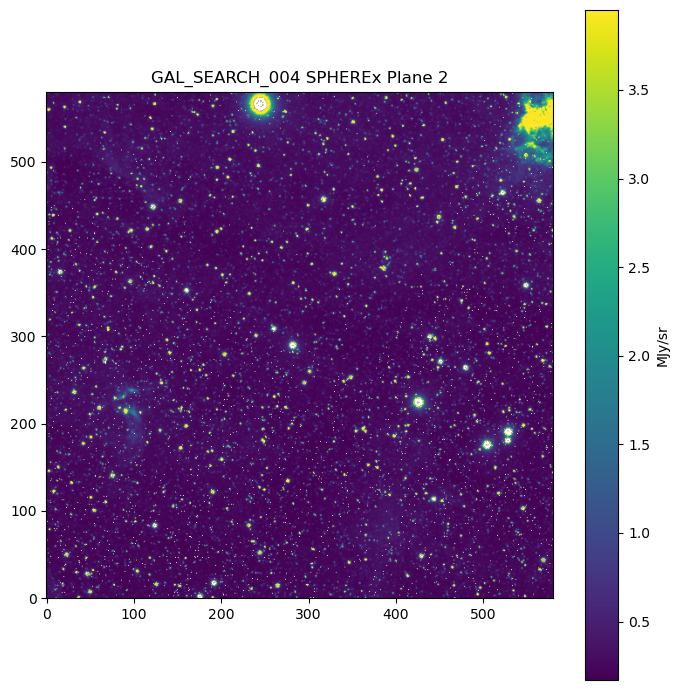

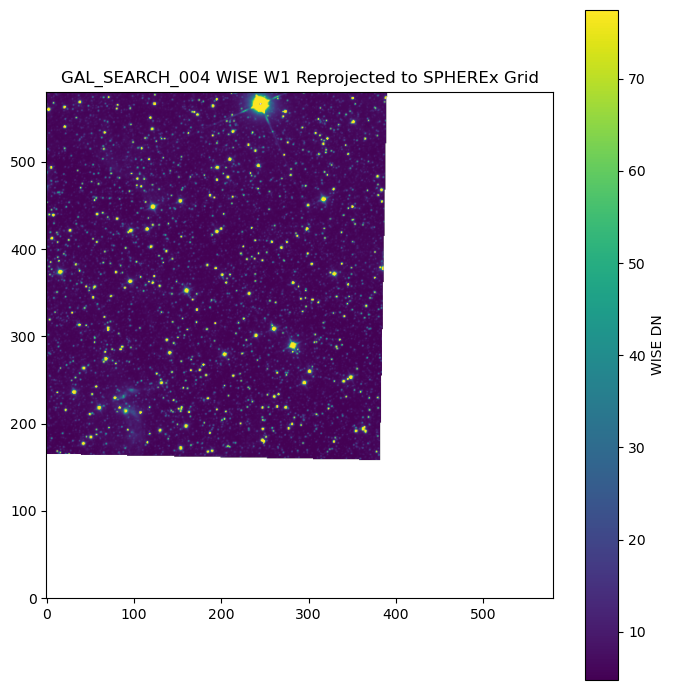

In [24]:
# ============================================================
# CELL 1 — REPROJECT WISE W1 TO SPHEREX GRID FOR GAL_SEARCH_004
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
from astropy.io import fits
from astropy.wcs import WCS
from reproject import reproject_interp
import matplotlib.pyplot as plt

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

FIELD_ID = "GAL_SEARCH_004"
FIELD_DIR = BASE / "GAL_SEARCH_004_ra46p7621_dec60p0150"

SPHEREX_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_004_3p20_3p58_cube.fits"
WISE_PATH = FIELD_DIR / "wise_raw" / "wise_w1_GAL_SEARCH_004_intensity.fits"

OUT_DIR = FIELD_DIR / "aligned"
DIAG_DIR = FIELD_DIR / "diagnostics"
OUT_DIR.mkdir(parents=True, exist_ok=True)
DIAG_DIR.mkdir(parents=True, exist_ok=True)

REPROJECTED_WISE_PATH = OUT_DIR / "wise_w1_reprojected_to_spherex_grid.fits"

with fits.open(SPHEREX_PATH) as spx_hdul:
    spx_cube = spx_hdul["IMAGE"].data.astype(float)
    spx_hdr_full = spx_hdul["IMAGE"].header.copy()
    spx_hdr_2d = WCS(spx_hdr_full, spx_hdul).celestial.to_header()

    # preserve useful metadata
    spx_hdr_2d["BUNIT"] = "DN"
    spx_shape = spx_cube[2].shape

with fits.open(WISE_PATH) as wise_hdul:
    wise_data = wise_hdul[0].data.astype(float)
    wise_hdr = wise_hdul[0].header.copy()

print("SPHEREx plane shape:", spx_shape)
print("WISE original shape:", wise_data.shape)

wise_reproj, footprint = reproject_interp(
    (wise_data, wise_hdr),
    spx_hdr_2d,
    shape_out=spx_shape,
)

fits.writeto(REPROJECTED_WISE_PATH, wise_reproj.astype(np.float32), spx_hdr_2d, overwrite=True)

print("\nSaved reprojected WISE:")
print(REPROJECTED_WISE_PATH)

spx_plane2 = spx_cube[2]

valid_spx = np.isfinite(spx_plane2)
valid_wise = np.isfinite(wise_reproj)
valid_overlap = valid_spx & valid_wise

print("\nOverlap stats:")
print("SPHEREx finite:", valid_spx.sum())
print("WISE reprojected finite:", valid_wise.sum())
print("Valid overlap:", valid_overlap.sum())
print("Overlap fraction of SPHEREx:", valid_overlap.sum() / valid_spx.sum())

# Diagnostic plot
v1 = np.nanpercentile(spx_plane2, [1, 99])
v2 = np.nanpercentile(wise_reproj, [1, 99])

plt.figure(figsize=(7, 7))
plt.imshow(spx_plane2, origin="lower", vmin=v1[0], vmax=v1[1])
plt.title("GAL_SEARCH_004 SPHEREx Plane 2")
plt.colorbar(label="MJy/sr")
plt.tight_layout()
plt.savefig(DIAG_DIR / "GAL_SEARCH_004_spherex_plane2.png", dpi=160)
plt.show()

plt.figure(figsize=(7, 7))
plt.imshow(wise_reproj, origin="lower", vmin=v2[0], vmax=v2[1])
plt.title("GAL_SEARCH_004 WISE W1 Reprojected to SPHEREx Grid")
plt.colorbar(label="WISE DN")
plt.tight_layout()
plt.savefig(DIAG_DIR / "GAL_SEARCH_004_wise_w1_reprojected.png", dpi=160)
plt.show()

Detected source table columns: ['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']
Detected source table columns: ['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']

Detected SPHEREx sources: 724
Detected WISE sources: 810

Matched sources: 387
Median dx pix: -0.014032381373453973
Median dy pix: 0.010739574153376452
Median match distance pix: 0.13628718764510325
Median dx arcsec: -0.08700076451541351
Median dy arcsec: 0.06658535975093315

Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\alignment_check\GAL_SEARCH_004_astrometric_matches.csv


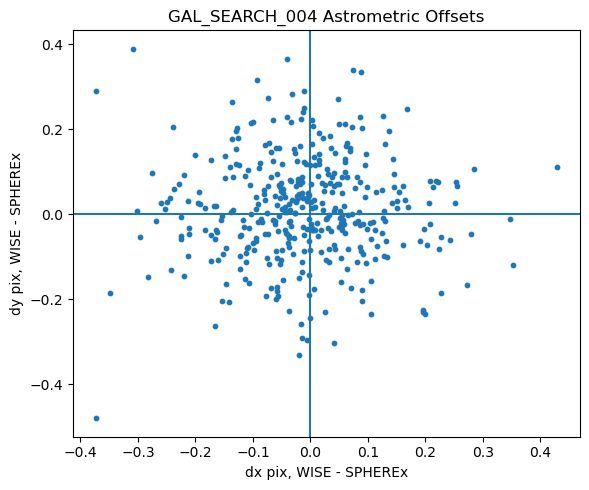

In [26]:
# ============================================================
# FIXED CELL 2 — ASTROMETRIC ALIGNMENT CHECK FOR GAL_SEARCH_004
# Robust for different photutils column names
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD_DIR = BASE / "GAL_SEARCH_004_ra46p7621_dec60p0150"

SPHEREX_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_004_3p20_3p58_cube.fits"
WISE_REPROJ_PATH = FIELD_DIR / "aligned" / "wise_w1_reprojected_to_spherex_grid.fits"

OUT_DIR = FIELD_DIR / "alignment_check"
OUT_DIR.mkdir(parents=True, exist_ok=True)

with fits.open(SPHEREX_PATH) as hdul:
    spx_cube = hdul["IMAGE"].data.astype(float)
    spx_hdr = hdul["IMAGE"].header.copy()
    wcs = WCS(spx_hdr, hdul).celestial

spx = spx_cube[2]

with fits.open(WISE_REPROJ_PATH) as hdul:
    wise = hdul[0].data.astype(float)

def standardize_xy_columns(df):
    """
    Handles different photutils versions.
    Some return xcentroid/ycentroid, others may return x_centroid/y_centroid.
    """
    print("Detected source table columns:", list(df.columns))

    possible_x = ["xcentroid", "x_centroid", "xcenter", "x_center", "x"]
    possible_y = ["ycentroid", "y_centroid", "ycenter", "y_center", "y"]

    xcol = None
    ycol = None

    for c in possible_x:
        if c in df.columns:
            xcol = c
            break

    for c in possible_y:
        if c in df.columns:
            ycol = c
            break

    if xcol is None or ycol is None:
        raise KeyError(
            "Could not find centroid columns. Columns found were:\n"
            + str(list(df.columns))
        )

    df = df.copy()
    df["x"] = df[xcol].astype(float)
    df["y"] = df[ycol].astype(float)
    return df

def detect_sources(img, fwhm=2.5, nsigma=8.0, edge=20):
    good = np.isfinite(img)
    mean, med, std = sigma_clipped_stats(img[good], sigma=3.0, maxiters=5)

    finder = DAOStarFinder(fwhm=fwhm, threshold=nsigma * std)
    tbl = finder(img - med)

    if tbl is None:
        return pd.DataFrame()

    df = tbl.to_pandas()
    df = standardize_xy_columns(df)

    df = df[
        (df["x"] > edge) &
        (df["x"] < img.shape[1] - edge) &
        (df["y"] > edge) &
        (df["y"] < img.shape[0] - edge)
    ].copy()

    return df

spx_src = detect_sources(spx, fwhm=2.5, nsigma=8.0)
wise_src = detect_sources(wise, fwhm=2.5, nsigma=8.0)

print("\nDetected SPHEREx sources:", len(spx_src))
print("Detected WISE sources:", len(wise_src))

if len(spx_src) == 0 or len(wise_src) == 0:
    raise RuntimeError("Not enough sources detected. Lower nsigma or check images.")

spx_xy = spx_src[["x", "y"]].to_numpy()
wise_xy = wise_src[["x", "y"]].to_numpy()

tree = cKDTree(wise_xy)
dist, idx = tree.query(spx_xy, distance_upper_bound=3.0)

rows = []

for i, (d, j) in enumerate(zip(dist, idx)):
    if np.isfinite(d) and j < len(wise_xy):
        sx, sy = spx_xy[i]
        wx, wy = wise_xy[j]

        rows.append({
            "spx_x": sx,
            "spx_y": sy,
            "wise_x": wx,
            "wise_y": wy,
            "dx_pix_wise_minus_spherex": wx - sx,
            "dy_pix_wise_minus_spherex": wy - sy,
            "dist_pix": d,
        })

matches = pd.DataFrame(rows)

OUT_CSV = OUT_DIR / "GAL_SEARCH_004_astrometric_matches.csv"
matches.to_csv(OUT_CSV, index=False)

pixscale_arcsec = abs(spx_hdr["CDELT2"]) * 3600.0

print("\nMatched sources:", len(matches))
print("Median dx pix:", matches["dx_pix_wise_minus_spherex"].median())
print("Median dy pix:", matches["dy_pix_wise_minus_spherex"].median())
print("Median match distance pix:", matches["dist_pix"].median())
print("Median dx arcsec:", matches["dx_pix_wise_minus_spherex"].median() * pixscale_arcsec)
print("Median dy arcsec:", matches["dy_pix_wise_minus_spherex"].median() * pixscale_arcsec)

print("\nSaved:")
print(OUT_CSV)

plt.figure(figsize=(6, 5))
plt.scatter(matches["dx_pix_wise_minus_spherex"], matches["dy_pix_wise_minus_spherex"], s=10)
plt.axhline(0)
plt.axvline(0)
plt.xlabel("dx pix, WISE - SPHEREx")
plt.ylabel("dy pix, WISE - SPHEREx")
plt.title("GAL_SEARCH_004 Astrometric Offsets")
plt.tight_layout()
plt.savefig(OUT_DIR / "GAL_SEARCH_004_astrometric_offsets.png", dpi=160)
plt.show()

Detected source table columns: ['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']
Detected source table columns: ['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']

SPHEREx detected: 632
WISE detected: 730
Clean scaling sources before clipping: 192

Final scaling sources: 176
Scale factor SPHEREx/WISE: 0.04493025141620692
Robust scatter: 0.0043013616010008264

Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\photometric_scaling\matched_source_aperture_scaling.csv
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\photometric_scaling\wise_w1_scaled_to_spherex_plane2.fits
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\photometric_scaling\spherex_plane2_minus_scaled_wise_w1.fits


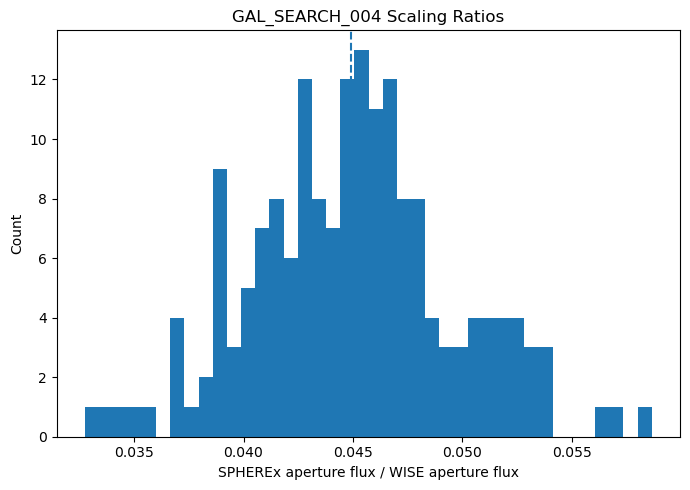

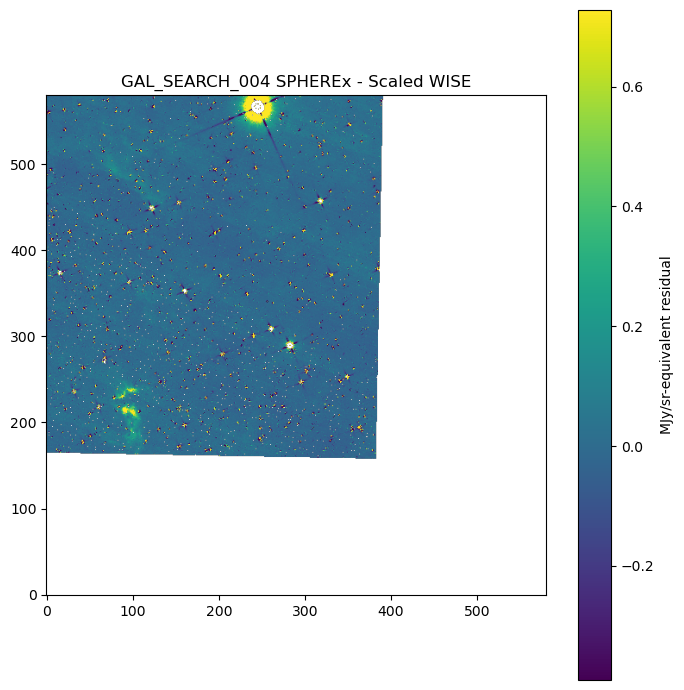

In [27]:
# ============================================================
# FIXED CELL 3 — PHOTOMETRIC SCALING WISE W1 TO SPHEREX PLANE 2
# Robust for different photutils column names
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD_DIR = BASE / "GAL_SEARCH_004_ra46p7621_dec60p0150"

SPHEREX_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_004_3p20_3p58_cube.fits"
WISE_REPROJ_PATH = FIELD_DIR / "aligned" / "wise_w1_reprojected_to_spherex_grid.fits"

OUT_DIR = FIELD_DIR / "photometric_scaling"
OUT_DIR.mkdir(parents=True, exist_ok=True)

with fits.open(SPHEREX_PATH) as hdul:
    spx_cube = hdul["IMAGE"].data.astype(float)
    spx_hdr = hdul["IMAGE"].header.copy()
    wcs = WCS(spx_hdr, hdul).celestial
    out_hdr = wcs.to_header()

spx = spx_cube[2]

with fits.open(WISE_REPROJ_PATH) as hdul:
    wise = hdul[0].data.astype(float)

def standardize_xy_columns(df):
    print("Detected source table columns:", list(df.columns))

    possible_x = ["xcentroid", "x_centroid", "xcenter", "x_center", "x"]
    possible_y = ["ycentroid", "y_centroid", "ycenter", "y_center", "y"]

    xcol = None
    ycol = None

    for c in possible_x:
        if c in df.columns:
            xcol = c
            break

    for c in possible_y:
        if c in df.columns:
            ycol = c
            break

    if xcol is None or ycol is None:
        raise KeyError(
            "Could not find centroid columns. Columns found were:\n"
            + str(list(df.columns))
        )

    df = df.copy()
    df["x"] = df[xcol].astype(float)
    df["y"] = df[ycol].astype(float)
    return df

def detect_sources(img, fwhm=2.5, nsigma=10.0, edge=25):
    good = np.isfinite(img)
    mean, med, std = sigma_clipped_stats(img[good], sigma=3.0, maxiters=5)

    finder = DAOStarFinder(fwhm=fwhm, threshold=nsigma * std)
    tbl = finder(img - med)

    if tbl is None:
        return pd.DataFrame()

    df = tbl.to_pandas()
    df = standardize_xy_columns(df)

    df = df[
        (df["x"] > edge) &
        (df["x"] < img.shape[1] - edge) &
        (df["y"] > edge) &
        (df["y"] < img.shape[0] - edge)
    ].copy()

    return df

def aperture_flux(img, positions, r=3.0, rin=6.0, rout=10.0):
    ap = CircularAperture(positions, r=r)
    ann = CircularAnnulus(positions, r_in=rin, r_out=rout)
    phot = aperture_photometry(img, [ap, ann], method="exact")

    ap_area = ap.area
    ann_area = ann.area

    flux_raw = np.array(phot["aperture_sum_0"], dtype=float)
    sky_sum = np.array(phot["aperture_sum_1"], dtype=float)
    sky_per_pix = sky_sum / ann_area
    flux = flux_raw - sky_per_pix * ap_area
    return flux

spx_src = detect_sources(spx, nsigma=10.0)
wise_src = detect_sources(wise, nsigma=10.0)

print("\nSPHEREx detected:", len(spx_src))
print("WISE detected:", len(wise_src))

if len(spx_src) == 0 or len(wise_src) == 0:
    raise RuntimeError("No detected sources. Lower nsigma if needed.")

tree = cKDTree(wise_src[["x", "y"]].to_numpy())
dist, idx = tree.query(spx_src[["x", "y"]].to_numpy(), distance_upper_bound=3.0)

matched_positions = []
rows = []

for i, (d, j) in enumerate(zip(dist, idx)):
    if np.isfinite(d) and j < len(wise_src):
        sx = float(spx_src.iloc[i]["x"])
        sy = float(spx_src.iloc[i]["y"])
        wx = float(wise_src.iloc[j]["x"])
        wy = float(wise_src.iloc[j]["y"])

        x = 0.5 * (sx + wx)
        y = 0.5 * (sy + wy)

        matched_positions.append((x, y))
        rows.append({
            "x": x,
            "y": y,
            "spx_x": sx,
            "spx_y": sy,
            "wise_x": wx,
            "wise_y": wy,
            "dist_pix": d,
        })

if len(matched_positions) < 10:
    raise RuntimeError("Too few matched sources for scaling.")

matched_positions = np.array(matched_positions)
matched = pd.DataFrame(rows)

spx_flux = aperture_flux(spx, matched_positions)
wise_flux = aperture_flux(wise, matched_positions)

matched["spherex_flux"] = spx_flux
matched["wise_flux"] = wise_flux
matched["ratio_spherex_over_wise"] = matched["spherex_flux"] / matched["wise_flux"]

clean = matched[
    np.isfinite(matched["spherex_flux"]) &
    np.isfinite(matched["wise_flux"]) &
    np.isfinite(matched["ratio_spherex_over_wise"]) &
    (matched["spherex_flux"] > 0) &
    (matched["wise_flux"] > 0)
].copy()

print("Clean scaling sources before clipping:", len(clean))

ratio = clean["ratio_spherex_over_wise"].to_numpy()
med = np.nanmedian(ratio)
mad = 1.4826 * np.nanmedian(np.abs(ratio - med))

if mad <= 0 or not np.isfinite(mad):
    clipped = clean.copy()
else:
    clipped = clean[np.abs(clean["ratio_spherex_over_wise"] - med) < 3 * mad].copy()

scale = np.nanmedian(clipped["ratio_spherex_over_wise"])
scatter = 1.4826 * np.nanmedian(np.abs(clipped["ratio_spherex_over_wise"] - scale))

wise_scaled = wise * scale
diff = spx - wise_scaled

out_scaled = OUT_DIR / "wise_w1_scaled_to_spherex_plane2.fits"
out_diff = OUT_DIR / "spherex_plane2_minus_scaled_wise_w1.fits"
out_csv = OUT_DIR / "matched_source_aperture_scaling.csv"

fits.writeto(out_scaled, wise_scaled.astype(np.float32), out_hdr, overwrite=True)
fits.writeto(out_diff, diff.astype(np.float32), out_hdr, overwrite=True)
clipped.to_csv(out_csv, index=False)

print("\nFinal scaling sources:", len(clipped))
print("Scale factor SPHEREx/WISE:", scale)
print("Robust scatter:", scatter)

print("\nSaved:")
print(out_csv)
print(out_scaled)
print(out_diff)

plt.figure(figsize=(7, 5))
plt.hist(clipped["ratio_spherex_over_wise"], bins=40)
plt.axvline(scale, linestyle="--")
plt.xlabel("SPHEREx aperture flux / WISE aperture flux")
plt.ylabel("Count")
plt.title("GAL_SEARCH_004 Scaling Ratios")
plt.tight_layout()
plt.savefig(OUT_DIR / "spherex_wise_aperture_scaling_ratios.png", dpi=160)
plt.show()

v = np.nanpercentile(diff[np.isfinite(diff)], [1, 99])
plt.figure(figsize=(7, 7))
plt.imshow(diff, origin="lower", vmin=v[0], vmax=v[1])
plt.title("GAL_SEARCH_004 SPHEREx - Scaled WISE")
plt.colorbar(label="MJy/sr-equivalent residual")
plt.tight_layout()
plt.savefig(OUT_DIR / "spherex_minus_scaled_wise_preview.png", dpi=160)
plt.show()

Calibration sources: 176
Best sigma: 0.5
Best matched-star median abs aperture residual: 0.6341720874887562
Best global diff std: 0.038358062416094504

Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\psf_tuning\psf_tuning_results.csv
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\psf_tuning\wise_w1_scaled_psf_tuned_to_spherex_plane2.fits
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\psf_tuning\spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits


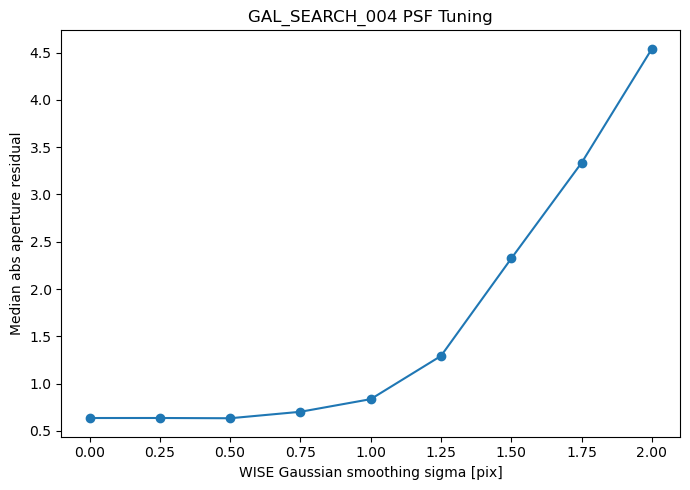

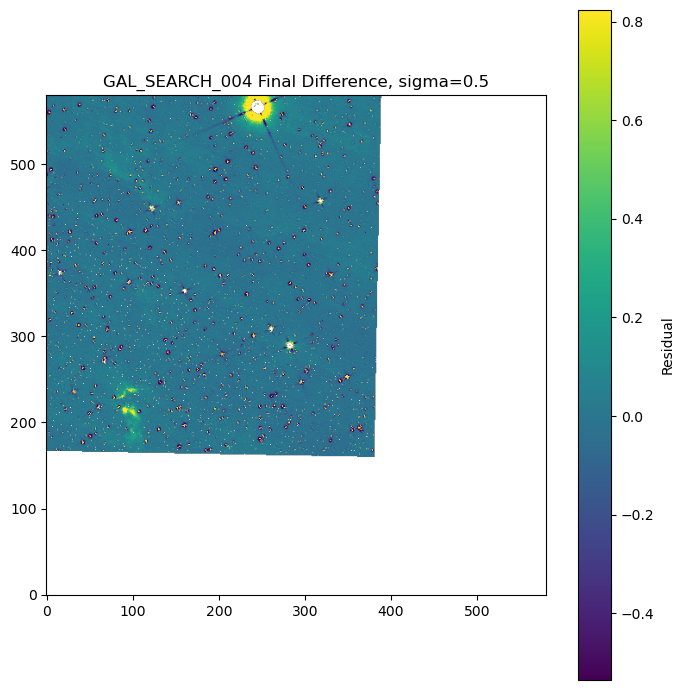

In [28]:
# ============================================================
# CELL 4 — PSF TUNING FOR GAL_SEARCH_004
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.stats import sigma_clipped_stats
from scipy.ndimage import gaussian_filter
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry
import matplotlib.pyplot as plt

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD_DIR = BASE / "GAL_SEARCH_004_ra46p7621_dec60p0150"

SPHEREX_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_004_3p20_3p58_cube.fits"
WISE_SCALED_PATH = FIELD_DIR / "photometric_scaling" / "wise_w1_scaled_to_spherex_plane2.fits"
SCALING_CSV = FIELD_DIR / "photometric_scaling" / "matched_source_aperture_scaling.csv"

OUT_DIR = FIELD_DIR / "psf_tuning"
OUT_DIR.mkdir(parents=True, exist_ok=True)

with fits.open(SPHEREX_PATH) as hdul:
    spx = hdul["IMAGE"].data.astype(float)[2]
    out_hdr = hdul["IMAGE"].header.copy()

with fits.open(WISE_SCALED_PATH) as hdul:
    wise_scaled = hdul[0].data.astype(float)
    wise_hdr = hdul[0].header.copy()

cal = pd.read_csv(SCALING_CSV)
positions = cal[["x", "y"]].to_numpy()

print("Calibration sources:", len(positions))

def aperture_flux(img, positions, r=3.0, rin=6.0, rout=10.0):
    ap = CircularAperture(positions, r=r)
    ann = CircularAnnulus(positions, r_in=rin, r_out=rout)
    phot = aperture_photometry(img, [ap, ann], method="exact")

    ap_area = ap.area
    ann_area = ann.area

    flux_raw = np.array(phot["aperture_sum_0"], dtype=float)
    sky_sum = np.array(phot["aperture_sum_1"], dtype=float)
    sky_per_pix = sky_sum / ann_area

    return flux_raw - sky_per_pix * ap_area

sigmas = np.arange(0.0, 2.01, 0.25)
rows = []

for sig in sigmas:
    if sig == 0:
        wise_test = wise_scaled.copy()
    else:
        wise_test = gaussian_filter(wise_scaled, sigma=sig)

    diff = spx - wise_test

    res_flux = aperture_flux(diff, positions)
    med_abs_res = np.nanmedian(np.abs(res_flux))

    good = np.isfinite(diff)
    _, _, std = sigma_clipped_stats(diff[good], sigma=3.0, maxiters=5)

    rows.append({
        "sigma_pix": sig,
        "median_abs_aperture_residual": med_abs_res,
        "global_diff_std": std,
    })

res = pd.DataFrame(rows)

best = res.sort_values(["median_abs_aperture_residual", "global_diff_std"]).iloc[0]
best_sigma = float(best["sigma_pix"])

if best_sigma == 0:
    wise_best = wise_scaled.copy()
else:
    wise_best = gaussian_filter(wise_scaled, sigma=best_sigma)

diff_best = spx - wise_best

OUT_CSV = OUT_DIR / "psf_tuning_results.csv"
OUT_WISE = OUT_DIR / "wise_w1_scaled_psf_tuned_to_spherex_plane2.fits"
OUT_DIFF = OUT_DIR / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits"

res.to_csv(OUT_CSV, index=False)
fits.writeto(OUT_WISE, wise_best.astype(np.float32), wise_hdr, overwrite=True)
fits.writeto(OUT_DIFF, diff_best.astype(np.float32), wise_hdr, overwrite=True)

print("Best sigma:", best_sigma)
print("Best matched-star median abs aperture residual:", best["median_abs_aperture_residual"])
print("Best global diff std:", best["global_diff_std"])

print("\nSaved:")
print(OUT_CSV)
print(OUT_WISE)
print(OUT_DIFF)

plt.figure(figsize=(7, 5))
plt.plot(res["sigma_pix"], res["median_abs_aperture_residual"], marker="o")
plt.xlabel("WISE Gaussian smoothing sigma [pix]")
plt.ylabel("Median abs aperture residual")
plt.title("GAL_SEARCH_004 PSF Tuning")
plt.tight_layout()
plt.savefig(OUT_DIR / "psf_tuning_curve.png", dpi=160)
plt.show()

v = np.nanpercentile(diff_best[np.isfinite(diff_best)], [1, 99])
plt.figure(figsize=(7, 7))
plt.imshow(diff_best, origin="lower", vmin=v[0], vmax=v[1])
plt.title(f"GAL_SEARCH_004 Final Difference, sigma={best_sigma}")
plt.colorbar(label="Residual")
plt.tight_layout()
plt.savefig(OUT_DIR / "psf_tuned_subtraction_check.png", dpi=160)
plt.show()

Residual stats:
sigma-clipped mean: -0.006460370918504884
sigma-clipped median: -0.007255746051669121
sigma-clipped std: 0.038358062415224714
MAD robust sigma: 0.03437952273306437
Used sigma: 0.03437952273306437
Candidate table columns: ['id', 'x_centroid', 'y_centroid', 'sharpness', 'roundness1', 'roundness2', 'n_pixels', 'peak', 'flux', 'mag', 'daofind_mag']

Total candidates after overlap/edge filtering: 98
>=5 sigma: 82
>=10 sigma: 56
>=20 sigma: 30
>=30 sigma: 26
>=50 sigma: 20
>=80 sigma: 14
>=100 sigma: 14

Top candidates:


,candidate_id,ra_deg,dec_deg,residual_diff_snr_peak,residual_peak_value
0,G004_CAND_001,46.622123,60.154358,3307.937914,113.718071
1,G004_CAND_002,46.512175,59.849106,1265.656902,43.505424
2,G004_CAND_003,46.960014,60.115927,413.307637,14.202064
3,G004_CAND_004,47.066782,60.151998,371.714432,12.772109
4,G004_CAND_005,47.308829,59.843431,299.147797,10.277303
5,G004_CAND_006,47.126974,60.173055,160.390474,5.506892
6,G004_CAND_007,47.170133,60.466632,159.255023,5.467856
7,G004_CAND_008,47.466858,60.002899,156.275554,5.365423
8,G004_CAND_009,47.490150,59.905932,152.028717,5.219419
9,G004_CAND_010,46.981288,60.066387,118.902083,4.080541



Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\candidate_detection\GAL_SEARCH_004_residual_candidates_5sigma.csv


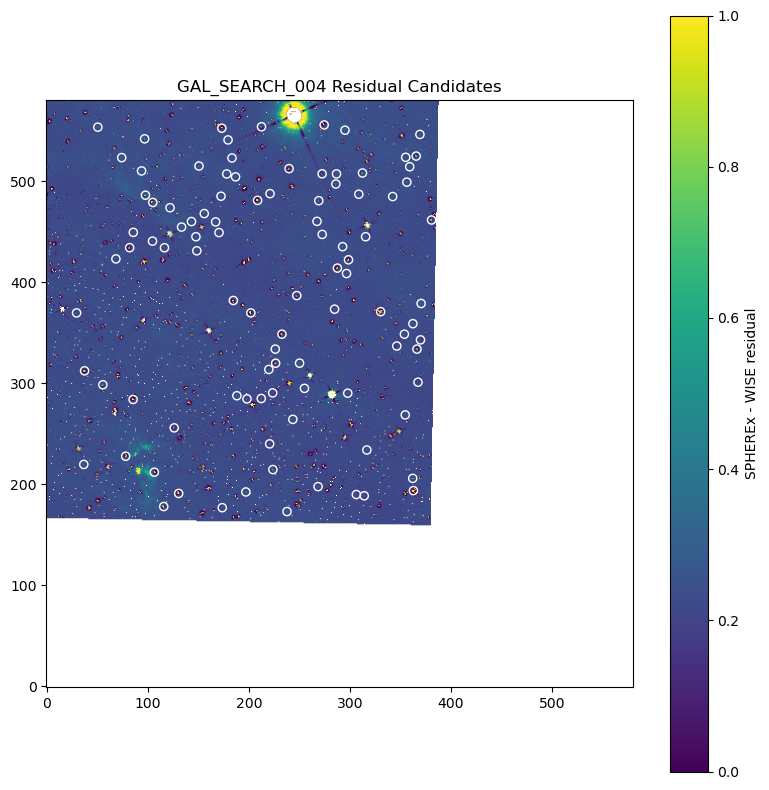

In [29]:
# ============================================================
# FIXED CELL 5 — RESIDUAL CANDIDATE DETECTION FOR GAL_SEARCH_004
# Robust for different photutils column names
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
from astropy.stats import sigma_clipped_stats
from photutils.detection import DAOStarFinder
import matplotlib.pyplot as plt

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD_DIR = BASE / "GAL_SEARCH_004_ra46p7621_dec60p0150"

SPHEREX_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_004_3p20_3p58_cube.fits"
DIFF_PATH = FIELD_DIR / "psf_tuning" / "spherex_plane2_minus_psf_tuned_scaled_wise_w1.fits"
WISE_TUNED_PATH = FIELD_DIR / "psf_tuning" / "wise_w1_scaled_psf_tuned_to_spherex_plane2.fits"

OUT_DIR = FIELD_DIR / "candidate_detection"
OUT_DIR.mkdir(parents=True, exist_ok=True)

with fits.open(SPHEREX_PATH) as hdul:
    spx_hdr = hdul["IMAGE"].header.copy()
    wcs = WCS(spx_hdr, hdul).celestial
    spx_plane2 = hdul["IMAGE"].data.astype(float)[2]

with fits.open(DIFF_PATH) as hdul:
    diff = hdul[0].data.astype(float)

with fits.open(WISE_TUNED_PATH) as hdul:
    wise_tuned = hdul[0].data.astype(float)

def standardize_xy_columns(df):
    print("Candidate table columns:", list(df.columns))

    possible_x = ["xcentroid", "x_centroid", "xcenter", "x_center", "x"]
    possible_y = ["ycentroid", "y_centroid", "ycenter", "y_center", "y"]

    xcol = None
    ycol = None

    for c in possible_x:
        if c in df.columns:
            xcol = c
            break

    for c in possible_y:
        if c in df.columns:
            ycol = c
            break

    if xcol is None or ycol is None:
        raise KeyError(
            "Could not find centroid columns. Columns found were:\n"
            + str(list(df.columns))
        )

    df = df.copy()
    df["x"] = df[xcol].astype(float)
    df["y"] = df[ycol].astype(float)
    return df

valid = np.isfinite(diff) & np.isfinite(spx_plane2) & np.isfinite(wise_tuned)

mean, med, std = sigma_clipped_stats(diff[valid], sigma=3.0, maxiters=5)
mad_sigma = 1.4826 * np.nanmedian(np.abs(diff[valid] - np.nanmedian(diff[valid])))
used_sigma = mad_sigma if np.isfinite(mad_sigma) and mad_sigma > 0 else std

print("Residual stats:")
print("sigma-clipped mean:", mean)
print("sigma-clipped median:", med)
print("sigma-clipped std:", std)
print("MAD robust sigma:", mad_sigma)
print("Used sigma:", used_sigma)

finder = DAOStarFinder(fwhm=2.5, threshold=5.0 * used_sigma)
tbl = finder(diff - med)

if tbl is None:
    candidates = pd.DataFrame()
else:
    candidates = tbl.to_pandas()
    candidates = standardize_xy_columns(candidates)

edge = 25

if len(candidates) > 0:
    candidates = candidates[
        (candidates["x"] > edge) &
        (candidates["x"] < diff.shape[1] - edge) &
        (candidates["y"] > edge) &
        (candidates["y"] < diff.shape[0] - edge)
    ].copy()

    xs = np.round(candidates["x"].to_numpy()).astype(int)
    ys = np.round(candidates["y"].to_numpy()).astype(int)

    in_valid = valid[ys, xs]
    candidates = candidates[in_valid].copy()

    xs = np.round(candidates["x"].to_numpy()).astype(int)
    ys = np.round(candidates["y"].to_numpy()).astype(int)

    candidates["residual_peak_value"] = diff[ys, xs]
    candidates["residual_diff_snr_peak"] = (candidates["residual_peak_value"] - med) / used_sigma

    ra, dec = wcs.pixel_to_world_values(
        candidates["x"].to_numpy(),
        candidates["y"].to_numpy()
    )

    candidates["ra_deg"] = ra
    candidates["dec_deg"] = dec

    candidates = candidates.sort_values("residual_diff_snr_peak", ascending=False).reset_index(drop=True)
    candidates["candidate_id"] = [f"G004_CAND_{i+1:03d}" for i in range(len(candidates))]

cols_front = [
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "x",
    "y",
    "residual_peak_value",
    "residual_diff_snr_peak",
]

if len(candidates) > 0:
    candidates = candidates[cols_front + [c for c in candidates.columns if c not in cols_front]]

OUT_CSV = OUT_DIR / "GAL_SEARCH_004_residual_candidates_5sigma.csv"
candidates.to_csv(OUT_CSV, index=False)

print("\nTotal candidates after overlap/edge filtering:", len(candidates))

if len(candidates) > 0:
    for threshold in [5, 10, 20, 30, 50, 80, 100]:
        print(f">={threshold} sigma:", int((candidates["residual_diff_snr_peak"] >= threshold).sum()))

    print("\nTop candidates:")
    display(candidates.head(20)[[
        "candidate_id",
        "ra_deg",
        "dec_deg",
        "residual_diff_snr_peak",
        "residual_peak_value",
    ]])

print("\nSaved:")
print(OUT_CSV)

v = np.nanpercentile(diff[valid], [1, 99.5])

plt.figure(figsize=(8, 8))
plt.imshow(diff, origin="lower", vmin=v[0], vmax=v[1])

if len(candidates) > 0:
    plt.scatter(candidates["x"], candidates["y"], s=35, facecolors="none", edgecolors="white")

plt.title("GAL_SEARCH_004 Residual Candidates")
plt.colorbar(label="SPHEREx - WISE residual")
plt.tight_layout()
plt.savefig(OUT_DIR / "GAL_SEARCH_004_residual_candidates_overlay.png", dpi=180)
plt.show()

In [31]:
# ============================================================
# FIXED CELL 6 — FIVE-BAND PHOTOMETRY + SPHEREX/WISE RATIO SUMMARY
# GAL_SEARCH_004
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.wcs import WCS
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry
import matplotlib.pyplot as plt

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD_DIR = BASE / "GAL_SEARCH_004_ra46p7621_dec60p0150"

SPHEREX_PATH = FIELD_DIR / "spherex_raw" / "spherex_GAL_SEARCH_004_3p20_3p58_cube.fits"
WISE_TUNED_PATH = FIELD_DIR / "psf_tuning" / "wise_w1_scaled_psf_tuned_to_spherex_plane2.fits"
CAND_CSV = FIELD_DIR / "candidate_detection" / "GAL_SEARCH_004_residual_candidates_5sigma.csv"

OUT_DIR = FIELD_DIR / "nearby_wavelength_photometry"
PLOT_DIR = OUT_DIR / "candidate_spectra"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

if not SPHEREX_PATH.exists():
    raise FileNotFoundError(SPHEREX_PATH)

if not WISE_TUNED_PATH.exists():
    raise FileNotFoundError(WISE_TUNED_PATH)

if not CAND_CSV.exists():
    raise FileNotFoundError(CAND_CSV)

with fits.open(SPHEREX_PATH) as hdul:
    cube = hdul["IMAGE"].data.astype(float)
    hdr = hdul["IMAGE"].header.copy()
    wcs = WCS(hdr, hdul).celestial
    spec = hdul["SPECTRAL_CHANNELS"].data

# Robust wavelength extraction
print("Spectral channel columns:", spec.names)

if "lambda" in spec.names:
    wave_um = np.array(spec["lambda"], dtype=float)
elif "wavelength" in spec.names:
    wave_um = np.array(spec["wavelength"], dtype=float)
elif "lam" in spec.names:
    wave_um = np.array(spec["lam"], dtype=float)
else:
    # Known GAL_SEARCH_004 SPHEREx QR2 values from verification
    wave_um = np.array([3.204, 3.293, 3.383, 3.476, 3.570], dtype=float)

print("Using wavelengths:", wave_um)

with fits.open(WISE_TUNED_PATH) as hdul:
    wise_scaled = hdul[0].data.astype(float)

cands = pd.read_csv(CAND_CSV)

print("Loaded candidates:", len(cands))

def one_ap_flux(img, x, y, r=3.0, rin=6.0, rout=10.0):
    pos = [(x, y)]
    ap = CircularAperture(pos, r=r)
    ann = CircularAnnulus(pos, r_in=rin, r_out=rout)
    phot = aperture_photometry(img, [ap, ann], method="exact")

    ap_area = ap.area
    ann_area = ann.area

    raw = float(phot["aperture_sum_0"][0])
    sky_sum = float(phot["aperture_sum_1"][0])
    sky_per_pix = sky_sum / ann_area

    flux = raw - sky_per_pix * ap_area
    return flux

rows_long = []
rows_sum = []

for _, cand in cands.iterrows():
    cid = cand["candidate_id"]
    x = float(cand["x"])
    y = float(cand["y"])

    wise_expected = one_ap_flux(wise_scaled, x, y)

    band_fluxes = []
    residual_fluxes = []

    for k in range(cube.shape[0]):
        spx_flux = one_ap_flux(cube[k], x, y)
        resid_flux = spx_flux - wise_expected

        band_fluxes.append(spx_flux)
        residual_fluxes.append(resid_flux)

        rows_long.append({
            "candidate_id": cid,
            "ra_deg": cand["ra_deg"],
            "dec_deg": cand["dec_deg"],
            "x": x,
            "y": y,
            "band_index": k,
            "wavelength_um": wave_um[k],
            "spherex_flux": spx_flux,
            "wise_expected_flux_scaled": wise_expected,
            "residual_flux": resid_flux,
        })

    band_fluxes = np.array(band_fluxes, dtype=float)
    residual_fluxes = np.array(residual_fluxes, dtype=float)

    finite = np.isfinite(band_fluxes) & np.isfinite(residual_fluxes)

    if finite.sum() == 0:
        med_flux = np.nan
        ratio = np.nan
        frac_scatter = np.nan
        positive_count = 0
    else:
        med_flux = np.nanmedian(band_fluxes[finite])
        ratio = med_flux / wise_expected if np.isfinite(wise_expected) and wise_expected > 0 else np.nan

        scatter = 1.4826 * np.nanmedian(np.abs(band_fluxes[finite] - med_flux)) if finite.sum() > 1 else np.nan
        frac_scatter = scatter / abs(med_flux) if np.isfinite(med_flux) and med_flux != 0 else np.nan

        positive_count = int(np.sum(residual_fluxes[finite] > 0))

    snr_peak = float(cand["residual_diff_snr_peak"])

    # Same proxy logic as before:
    # If the residual source is a >=5sigma detection and the residual flux is positive in a band,
    # count that band as present.
    snr3_count = positive_count if snr_peak >= 3 else 0
    snr5_count = positive_count if snr_peak >= 5 else 0

    if (20 <= snr_peak <= 30) and positive_count == 5:
        review_class = "BEST RANGE: 20-30sigma + present across bands"
    elif snr_peak > 30 and positive_count == 5:
        review_class = "VERY STRONG: above 30sigma + present across bands"
    elif snr_peak >= 20 and positive_count >= 3:
        review_class = "CHECK: high residual SNR but weak band persistence"
    else:
        review_class = "LOWER PRIORITY"

    rows_sum.append({
        "candidate_id": cid,
        "ra_deg": cand["ra_deg"],
        "dec_deg": cand["dec_deg"],
        "x": x,
        "y": y,
        "residual_diff_snr_peak": snr_peak,
        "wise_expected_flux_scaled": wise_expected,
        "median_spherex_flux_5band": med_flux,
        "spherex_over_wise_expected_ratio": ratio,
        "is_2x_over_wise": bool(np.isfinite(ratio) and ratio >= 2.0),
        "positive_flux_count_5": positive_count,
        "snr3_count_5": snr3_count,
        "snr5_count_5": snr5_count,
        "five_band_fractional_scatter": frac_scatter,
        "review_class": review_class,
    })

summary = pd.DataFrame(rows_sum)
long = pd.DataFrame(rows_long)

summary = summary.sort_values("residual_diff_snr_peak", ascending=False).reset_index(drop=True)

OUT_LONG = OUT_DIR / "GAL_SEARCH_004_candidate_5band_photometry_long.csv"
OUT_SUM = OUT_DIR / "GAL_SEARCH_004_candidate_5band_summary_with_ratios.csv"
OUT_FOCUS = OUT_DIR / "GAL_SEARCH_004_top_candidates_20_30sigma_focus.csv"

long.to_csv(OUT_LONG, index=False)
summary.to_csv(OUT_SUM, index=False)

focus = summary[
    (summary["residual_diff_snr_peak"] >= 20) &
    (summary["residual_diff_snr_peak"] <= 30)
].copy()

focus.to_csv(OUT_FOCUS, index=False)

print("\nSaved:")
print(OUT_LONG)
print(OUT_SUM)
print(OUT_FOCUS)

print("\nReview class counts:")
print(summary["review_class"].value_counts())

print("\nFinite ratios:", int(np.isfinite(summary["spherex_over_wise_expected_ratio"]).sum()))
print(">=2x ratios:", int((summary["spherex_over_wise_expected_ratio"] >= 2.0).sum()))

print("\nTop 20 by residual SNR:")
display(summary.head(20)[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "spherex_over_wise_expected_ratio",
    "is_2x_over_wise",
    "positive_flux_count_5",
    "snr5_count_5",
    "five_band_fractional_scatter",
    "review_class",
]])

print("\n20-30 sigma focus:")
display(focus[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "spherex_over_wise_expected_ratio",
    "is_2x_over_wise",
    "positive_flux_count_5",
    "snr5_count_5",
    "five_band_fractional_scatter",
    "review_class",
]])

# spectra plots for top 30 candidates
for _, r in summary.head(30).iterrows():
    cid = r["candidate_id"]
    sub = long[long["candidate_id"] == cid].copy()

    plt.figure(figsize=(6, 4))
    plt.plot(sub["wavelength_um"], sub["spherex_flux"], marker="o", label="SPHEREx 5 bands")
    plt.axhline(r["wise_expected_flux_scaled"], linestyle="--", label="Scaled WISE expected")
    plt.xlabel("Wavelength [µm]")
    plt.ylabel("Aperture flux")
    plt.title(
        f"{cid}\n"
        f"SNR={r['residual_diff_snr_peak']:.1f}, "
        f"ratio={r['spherex_over_wise_expected_ratio']:.2f}x"
    )
    plt.legend()
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"{cid}_5band_spectrum.png", dpi=160)
    plt.close()

print("\nSaved spectra plots:")
print(PLOT_DIR)

Spectral channel columns: ['DETECTOR', 'SUBCHAN', 'WAVELENGTH', 'WL_MIN', 'WL_MAX', 'BANDWIDTH', 'R', 'R_STD']
Using wavelengths: [3.204 3.293 3.383 3.476 3.57 ]
Loaded candidates: 98

Saved:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\nearby_wavelength_photometry\GAL_SEARCH_004_candidate_5band_photometry_long.csv
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\nearby_wavelength_photometry\GAL_SEARCH_004_candidate_5band_summary_with_ratios.csv
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\nearby_wavelength_photometry\GAL_SEARCH_004_top_candidates_20_30sigma_focus.csv

Review class counts:
review_class
LOWER PRIORITY                                        96
CHECK: high residual SNR but weak band persistence     2
Name: count, dtype: int64

Finite ratios: 81
>=2x ratios: 3

Top 20 by residual SNR:


,candidate_id,ra_deg,dec_deg,residual_diff_snr_peak,spherex_over_wise_expected_ratio,is_2x_over_wise,positive_flux_count_5,snr5_count_5,five_band_fractional_scatter,review_class
0,G004_CAND_001,46.622123,60.154358,3307.937914,1.857164,False,1,1,NaN,LOWER PRIORITY
1,G004_CAND_002,46.512175,59.849106,1265.656902,NaN,False,0,0,NaN,LOWER PRIORITY
2,G004_CAND_003,46.960014,60.115927,413.307637,1.096465,False,3,3,0.002334,CHECK: high residual SNR but weak band persist...
3,G004_CAND_004,47.066782,60.151998,371.714432,1.154557,False,2,2,0.024441,LOWER PRIORITY
4,G004_CAND_005,47.308829,59.843431,299.147797,1.010150,False,1,1,0.036884,LOWER PRIORITY
5,G004_CAND_006,47.126974,60.173055,160.390474,1.035223,False,2,2,0.033743,LOWER PRIORITY
6,G004_CAND_007,47.170133,60.466632,159.255023,1.097609,False,1,1,NaN,LOWER PRIORITY
7,G004_CAND_008,47.466858,60.002899,156.275554,0.837516,False,0,0,NaN,LOWER PRIORITY
8,G004_CAND_009,47.490150,59.905932,152.028717,0.970856,False,0,0,NaN,LOWER PRIORITY
9,G004_CAND_010,46.981288,60.066387,118.902083,1.159401,False,2,2,0.046061,LOWER PRIORITY



20-30 sigma focus:


,candidate_id,ra_deg,dec_deg,residual_diff_snr_peak,spherex_over_wise_expected_ratio,is_2x_over_wise,positive_flux_count_5,snr5_count_5,five_band_fractional_scatter,review_class
26,G004_CAND_027,47.436747,60.447438,28.583402,1.082220,False,1,1,NaN,LOWER PRIORITY
27,G004_CAND_028,46.834527,60.343632,26.152655,0.990750,False,1,1,0.018313,LOWER PRIORITY
28,G004_CAND_029,46.683804,60.390878,25.046239,1.084302,False,3,3,0.081957,CHECK: high residual SNR but weak band persist...
29,G004_CAND_030,47.570652,60.027398,24.238451,0.957279,False,0,0,NaN,LOWER PRIORITY



Saved spectra plots:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\nearby_wavelength_photometry\candidate_spectra


In [32]:
# ============================================================
# CELL 7 — STRICT SHORTLIST FOR GAL_SEARCH_004
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import pandas as pd
import shutil

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD_DIR = BASE / "GAL_SEARCH_004_ra46p7621_dec60p0150"

SUMMARY_CSV = FIELD_DIR / "nearby_wavelength_photometry" / "GAL_SEARCH_004_candidate_5band_summary_with_ratios.csv"
LONG_CSV = FIELD_DIR / "nearby_wavelength_photometry" / "GAL_SEARCH_004_candidate_5band_photometry_long.csv"

OUT_DIR = FIELD_DIR / "strict_shortlist"
OUT_DIR.mkdir(parents=True, exist_ok=True)

summary = pd.read_csv(SUMMARY_CSV)
long = pd.read_csv(LONG_CSV)

strict = summary[
    (summary["residual_diff_snr_peak"] >= 20) &
    (summary["residual_diff_snr_peak"] <= 30) &
    (summary["spherex_over_wise_expected_ratio"] >= 2.0) &
    (summary["positive_flux_count_5"] == 5) &
    (summary["snr5_count_5"] == 5)
].copy()

all_20_30 = summary[
    (summary["residual_diff_snr_peak"] >= 20) &
    (summary["residual_diff_snr_peak"] <= 30)
].copy()

two_x_all = summary[
    summary["spherex_over_wise_expected_ratio"] >= 2.0
].copy()

strict_long = long[long["candidate_id"].isin(strict["candidate_id"])].copy()

OUT_STRICT = OUT_DIR / "GAL_SEARCH_004_strict_shortlist.csv"
OUT_LONG = OUT_DIR / "GAL_SEARCH_004_strict_shortlist_5band_photometry.csv"
OUT_2030 = OUT_DIR / "GAL_SEARCH_004_all_20_30sigma_candidates.csv"
OUT_2X = OUT_DIR / "GAL_SEARCH_004_all_2x_candidates.csv"
README = OUT_DIR / "README_GAL_SEARCH_004_strict_shortlist.txt"

strict.to_csv(OUT_STRICT, index=False)
strict_long.to_csv(OUT_LONG, index=False)
all_20_30.to_csv(OUT_2030, index=False)
two_x_all.to_csv(OUT_2X, index=False)

with open(README, "w") as f:
    f.write("GAL_SEARCH_004 strict shortlist\n")
    f.write("===============================\n\n")
    f.write("Strict rule:\n")
    f.write("- residual_diff_snr_peak between 20 and 30\n")
    f.write("- spherex_over_wise_expected_ratio >= 2.0\n")
    f.write("- positive_flux_count_5 == 5\n")
    f.write("- snr5_count_5 == 5\n\n")
    f.write(f"Strict shortlist count: {len(strict)}\n")
    f.write(f"All 20-30 sigma candidate count: {len(all_20_30)}\n")
    f.write(f"All >=2x candidate count: {len(two_x_all)}\n\n")

    f.write("Conclusion:\n")
    if len(strict) == 0:
        f.write("No GAL_SEARCH_004 candidates passed the strict 20-30sigma, >=2x, 5-band-present rule.\n")
    else:
        f.write("One or more GAL_SEARCH_004 candidates passed the strict rule.\n")

    f.write("\n20-30 sigma candidates:\n")
    if len(all_20_30) > 0:
        f.write(all_20_30.to_string(index=False))
    else:
        f.write("None.\n")

    f.write("\n\n>=2x candidates:\n")
    if len(two_x_all) > 0:
        f.write(two_x_all.to_string(index=False))
    else:
        f.write("None.\n")

ZIP_PATH = FIELD_DIR / "GAL_SEARCH_004_strict_shortlist.zip"
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

shutil.make_archive(str(ZIP_PATH).replace(".zip", ""), "zip", OUT_DIR)

print("Strict shortlist count:", len(strict))
print("All 20-30 sigma count:", len(all_20_30))
print("All >=2x count:", len(two_x_all))

print("\nStrict shortlist:")
if len(strict) > 0:
    display(strict[[
        "candidate_id",
        "ra_deg",
        "dec_deg",
        "residual_diff_snr_peak",
        "spherex_over_wise_expected_ratio",
        "positive_flux_count_5",
        "snr5_count_5",
        "five_band_fractional_scatter",
        "review_class",
    ]])
else:
    print("None")

print("\n20-30 sigma candidates:")
display(all_20_30[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "spherex_over_wise_expected_ratio",
    "positive_flux_count_5",
    "snr5_count_5",
    "five_band_fractional_scatter",
    "review_class",
]])

print("\nAll >=2x candidates:")
display(two_x_all[[
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "spherex_over_wise_expected_ratio",
    "positive_flux_count_5",
    "snr5_count_5",
    "five_band_fractional_scatter",
    "review_class",
]])

print("\nSaved strict shortlist folder:")
print(OUT_DIR)

print("\nSaved ZIP:")
print(ZIP_PATH)

Strict shortlist count: 0
All 20-30 sigma count: 4
All >=2x count: 3

Strict shortlist:
None

20-30 sigma candidates:


,candidate_id,ra_deg,dec_deg,residual_diff_snr_peak,spherex_over_wise_expected_ratio,positive_flux_count_5,snr5_count_5,five_band_fractional_scatter,review_class
26,G004_CAND_027,47.436747,60.447438,28.583402,1.082220,1,1,NaN,LOWER PRIORITY
27,G004_CAND_028,46.834527,60.343632,26.152655,0.990750,1,1,0.018313,LOWER PRIORITY
28,G004_CAND_029,46.683804,60.390878,25.046239,1.084302,3,3,0.081957,CHECK: high residual SNR but weak band persist...
29,G004_CAND_030,47.570652,60.027398,24.238451,0.957279,0,0,NaN,LOWER PRIORITY



All >=2x candidates:


,candidate_id,ra_deg,dec_deg,residual_diff_snr_peak,spherex_over_wise_expected_ratio,positive_flux_count_5,snr5_count_5,five_band_fractional_scatter,review_class
49,G004_CAND_050,47.663637,60.149284,11.440587,6.280167,1,1,1.471493,LOWER PRIORITY
54,G004_CAND_055,47.171526,60.350696,10.556926,64.129408,1,1,NaN,LOWER PRIORITY
78,G004_CAND_079,47.134391,60.415922,5.638656,2.222815,2,2,0.136836,LOWER PRIORITY



Saved strict shortlist folder:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\strict_shortlist

Saved ZIP:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\GAL_SEARCH_004_strict_shortlist.zip


In [33]:
# ============================================================
# CREATE VARWISE/GATOR UPLOAD FOR GAL_SEARCH_004 CANDIDATES
# Includes:
# - all 20-30 sigma candidates
# - all >=2x candidates
# - union of both
# Fresh-kernel safe
# ============================================================

from pathlib import Path
import pandas as pd
from astropy.table import Table
from astropy.io import ascii

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")
FIELD_DIR = BASE / "GAL_SEARCH_004_ra46p7621_dec60p0150"

SUMMARY_CSV = FIELD_DIR / "nearby_wavelength_photometry" / "GAL_SEARCH_004_candidate_5band_summary_with_ratios.csv"

OUT_DIR = FIELD_DIR / "strict_shortlist_varwise_crossmatch"
OUT_DIR.mkdir(parents=True, exist_ok=True)

summary = pd.read_csv(SUMMARY_CSV)

# Select candidates worth checking even though strict shortlist is empty
to_check = summary[
    (
        (summary["residual_diff_snr_peak"] >= 20) &
        (summary["residual_diff_snr_peak"] <= 30)
    )
    |
    (
        summary["spherex_over_wise_expected_ratio"] >= 2.0
    )
].copy()

to_check = to_check.sort_values(
    ["residual_diff_snr_peak", "spherex_over_wise_expected_ratio"],
    ascending=False
).reset_index(drop=True)

to_check["cntr"] = range(1, len(to_check) + 1)

MAP_CSV = OUT_DIR / "GAL_SEARCH_004_varwise_candidate_mapping.csv"
to_check[[
    "cntr",
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "spherex_over_wise_expected_ratio",
    "positive_flux_count_5",
    "snr5_count_5",
    "five_band_fractional_scatter",
    "review_class"
]].to_csv(MAP_CSV, index=False)

# Old working Gator format: numeric only
tab = Table()
tab["cntr"] = to_check["cntr"].to_numpy()
tab["ra"] = to_check["ra_deg"].astype(float).to_numpy()
tab["dec"] = to_check["dec_deg"].astype(float).to_numpy()
tab["major"] = [3.0] * len(to_check)  # arcsec radius

tab["ra"].unit = "deg"
tab["dec"].unit = "deg"
tab["major"].unit = "arcsec"

OUT_TBL = OUT_DIR / "GAL_SEARCH_004_varwise_candidates_OLD_WORKING_GATOR.tbl"

ascii.write(
    tab,
    OUT_TBL,
    format="ipac",
    overwrite=True
)

print("Candidates selected for VarWISE crossmatch:", len(to_check))

display(to_check[[
    "cntr",
    "candidate_id",
    "ra_deg",
    "dec_deg",
    "residual_diff_snr_peak",
    "spherex_over_wise_expected_ratio",
    "positive_flux_count_5",
    "snr5_count_5",
    "review_class"
]])

print("\nUPLOAD THIS FILE TO GATOR:")
print(OUT_TBL)

print("\nMapping file:")
print(MAP_CSV)

print("\nGator file contents:")
print(OUT_TBL.read_text())

Candidates selected for VarWISE crossmatch: 7


,cntr,candidate_id,ra_deg,dec_deg,residual_diff_snr_peak,spherex_over_wise_expected_ratio,positive_flux_count_5,snr5_count_5,review_class
0,1,G004_CAND_027,47.436747,60.447438,28.583402,1.082220,1,1,LOWER PRIORITY
1,2,G004_CAND_028,46.834527,60.343632,26.152655,0.990750,1,1,LOWER PRIORITY
2,3,G004_CAND_029,46.683804,60.390878,25.046239,1.084302,3,3,CHECK: high residual SNR but weak band persist...
3,4,G004_CAND_030,47.570652,60.027398,24.238451,0.957279,0,0,LOWER PRIORITY
4,5,G004_CAND_050,47.663637,60.149284,11.440587,6.280167,1,1,LOWER PRIORITY
5,6,G004_CAND_055,47.171526,60.350696,10.556926,64.129408,1,1,LOWER PRIORITY
6,7,G004_CAND_079,47.134391,60.415922,5.638656,2.222815,2,2,LOWER PRIORITY



UPLOAD THIS FILE TO GATOR:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\strict_shortlist_varwise_crossmatch\GAL_SEARCH_004_varwise_candidates_OLD_WORKING_GATOR.tbl

Mapping file:
C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test\GAL_SEARCH_004_ra46p7621_dec60p0150\strict_shortlist_varwise_crossmatch\GAL_SEARCH_004_varwise_candidate_mapping.csv

Gator file contents:
|cntr|                ra|               dec| major|
|long|            double|            double|double|
|    |               deg|               deg|arcsec|
|null|              null|              null|  null|
    1 47.436746691561794  60.44743845722108    3.0 
    2 46.834526840641495  60.34363219957617    3.0 
    3  46.68380373270683 60.390878425827886    3.0 
    4 47.570651923637385  60.02739779799757    3.0 
    5  47.66363740254623 60.149284154424265    3.0 
    6  47.17152641040749  60.35069562790176    3.0 
    7 47.134391179670345 60.415921595759286    3.0 



In [34]:
from pathlib import Path
import pandas as pd

BASE = Path(r"C:\Users\Owner\OneDrive\Desktop\SPHEREx_Test")

G003_DIR = BASE / "GAL_SEARCH_003_ra43p1862_dec60p9615"
G004_DIR = BASE / "GAL_SEARCH_004_ra46p7621_dec60p0150"

OUT = BASE / "SPHEREx_WISE_GAL_SEARCH_003_004_summary_for_Dr_Hora.txt"

g003_strict = pd.read_csv(G003_DIR / "strict_shortlist" / "GAL_SEARCH_003_strict_shortlist.csv")
g004_summary = pd.read_csv(G004_DIR / "nearby_wavelength_photometry" / "GAL_SEARCH_004_candidate_5band_summary_with_ratios.csv")

g004_2030 = g004_summary[
    (g004_summary["residual_diff_snr_peak"] >= 20) &
    (g004_summary["residual_diff_snr_peak"] <= 30)
].copy()

g004_strict = g004_summary[
    (g004_summary["residual_diff_snr_peak"] >= 20) &
    (g004_summary["residual_diff_snr_peak"] <= 30) &
    (g004_summary["spherex_over_wise_expected_ratio"] >= 2.0) &
    (g004_summary["positive_flux_count_5"] == 5) &
    (g004_summary["snr5_count_5"] == 5)
].copy()

with open(OUT, "w") as f:
    f.write("SPHEREx / WISE candidate search update\n")
    f.write("=====================================\n\n")

    f.write("Summary:\n")
    f.write("I tested two nearby Galactic-coordinate search fields using the SPHEREx/WISE subtraction pipeline.\n")
    f.write("GAL_SEARCH_003 produced two strict candidates. GAL_SEARCH_004 produced no strict candidates.\n\n")

    f.write("Strict filter used:\n")
    f.write("- residual_diff_snr_peak between 20 and 30 sigma\n")
    f.write("- SPHEREx / scaled-WISE expected flux ratio >= 2.0\n")
    f.write("- positive residual flux in all 5 nearby SPHEREx bands\n")
    f.write("- 5/5 bands counted as present at the detection level\n\n")

    f.write("GAL_SEARCH_003 result:\n")
    f.write(f"Strict candidate count: {len(g003_strict)}\n")
    f.write("VarWISE Pure/Extended crossmatch: no sources found within 3 arcsec.\n")
    f.write("Therefore these are not catalog-confirmed VarWISE variables, but remain internal SPHEREx/WISE excess candidates.\n\n")
    f.write(g003_strict[[
        "candidate_id",
        "ra_deg",
        "dec_deg",
        "residual_diff_snr_peak",
        "spherex_over_wise_expected_ratio",
        "positive_flux_count_5",
        "snr5_count_5",
        "five_band_fractional_scatter",
        "review_class"
    ]].to_string(index=False))
    f.write("\n\n")

    f.write("GAL_SEARCH_004 result:\n")
    f.write(f"Total residual candidates: {len(g004_summary)}\n")
    f.write(f"20-30 sigma candidates: {len(g004_2030)}\n")
    f.write(f"Strict candidate count: {len(g004_strict)}\n")
    f.write("VarWISE Pure/Extended crossmatch: no sources found.\n")
    f.write("Conclusion: GAL_SEARCH_004 did not produce a useful strict candidate set.\n\n")

    f.write("GAL_SEARCH_004 20-30 sigma candidates:\n")
    f.write(g004_2030[[
        "candidate_id",
        "ra_deg",
        "dec_deg",
        "residual_diff_snr_peak",
        "spherex_over_wise_expected_ratio",
        "positive_flux_count_5",
        "snr5_count_5",
        "five_band_fractional_scatter",
        "review_class"
    ]].to_string(index=False))
    f.write("\n\n")

    f.write("Suggested next step:\n")
    f.write("Continue testing adjacent Galactic-coordinate fields, especially GAL_SEARCH_002, since GAL_SEARCH_003 was more productive than GAL_SEARCH_004.\n")

print("Saved summary:")
print(OUT)
print("\nContents:\n")
print(OUT.read_text())

KeyError: "['five_band_fractional_scatter'] not in index"